In [1]:
import matplotlib.pyplot as plt
import seaborn as sns


def save_tiff(plot_object, filename):
    # Replace slashes with dashes automatically to prevent errors
    safe_filename = filename.replace('/', '-')
    plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,})
    fig = plot_object.fig if hasattr(plot_object, 'fig') else plot_object
    fig.savefig(
        f"images/{safe_filename}.tiff", 
        format='tiff', 
        bbox_inches='tight',
        pil_kwargs={"compression": "tiff_lzw"}
    )
    print(f"Saved: {safe_filename}.tiff")

Lambda parameter determines the trade-off between Minimum Free Energy (MFE) and Codon Adaptation index (CAI). Testing three lambda parameters (1, 4, 10) found clusters on MFE/CAI plane.

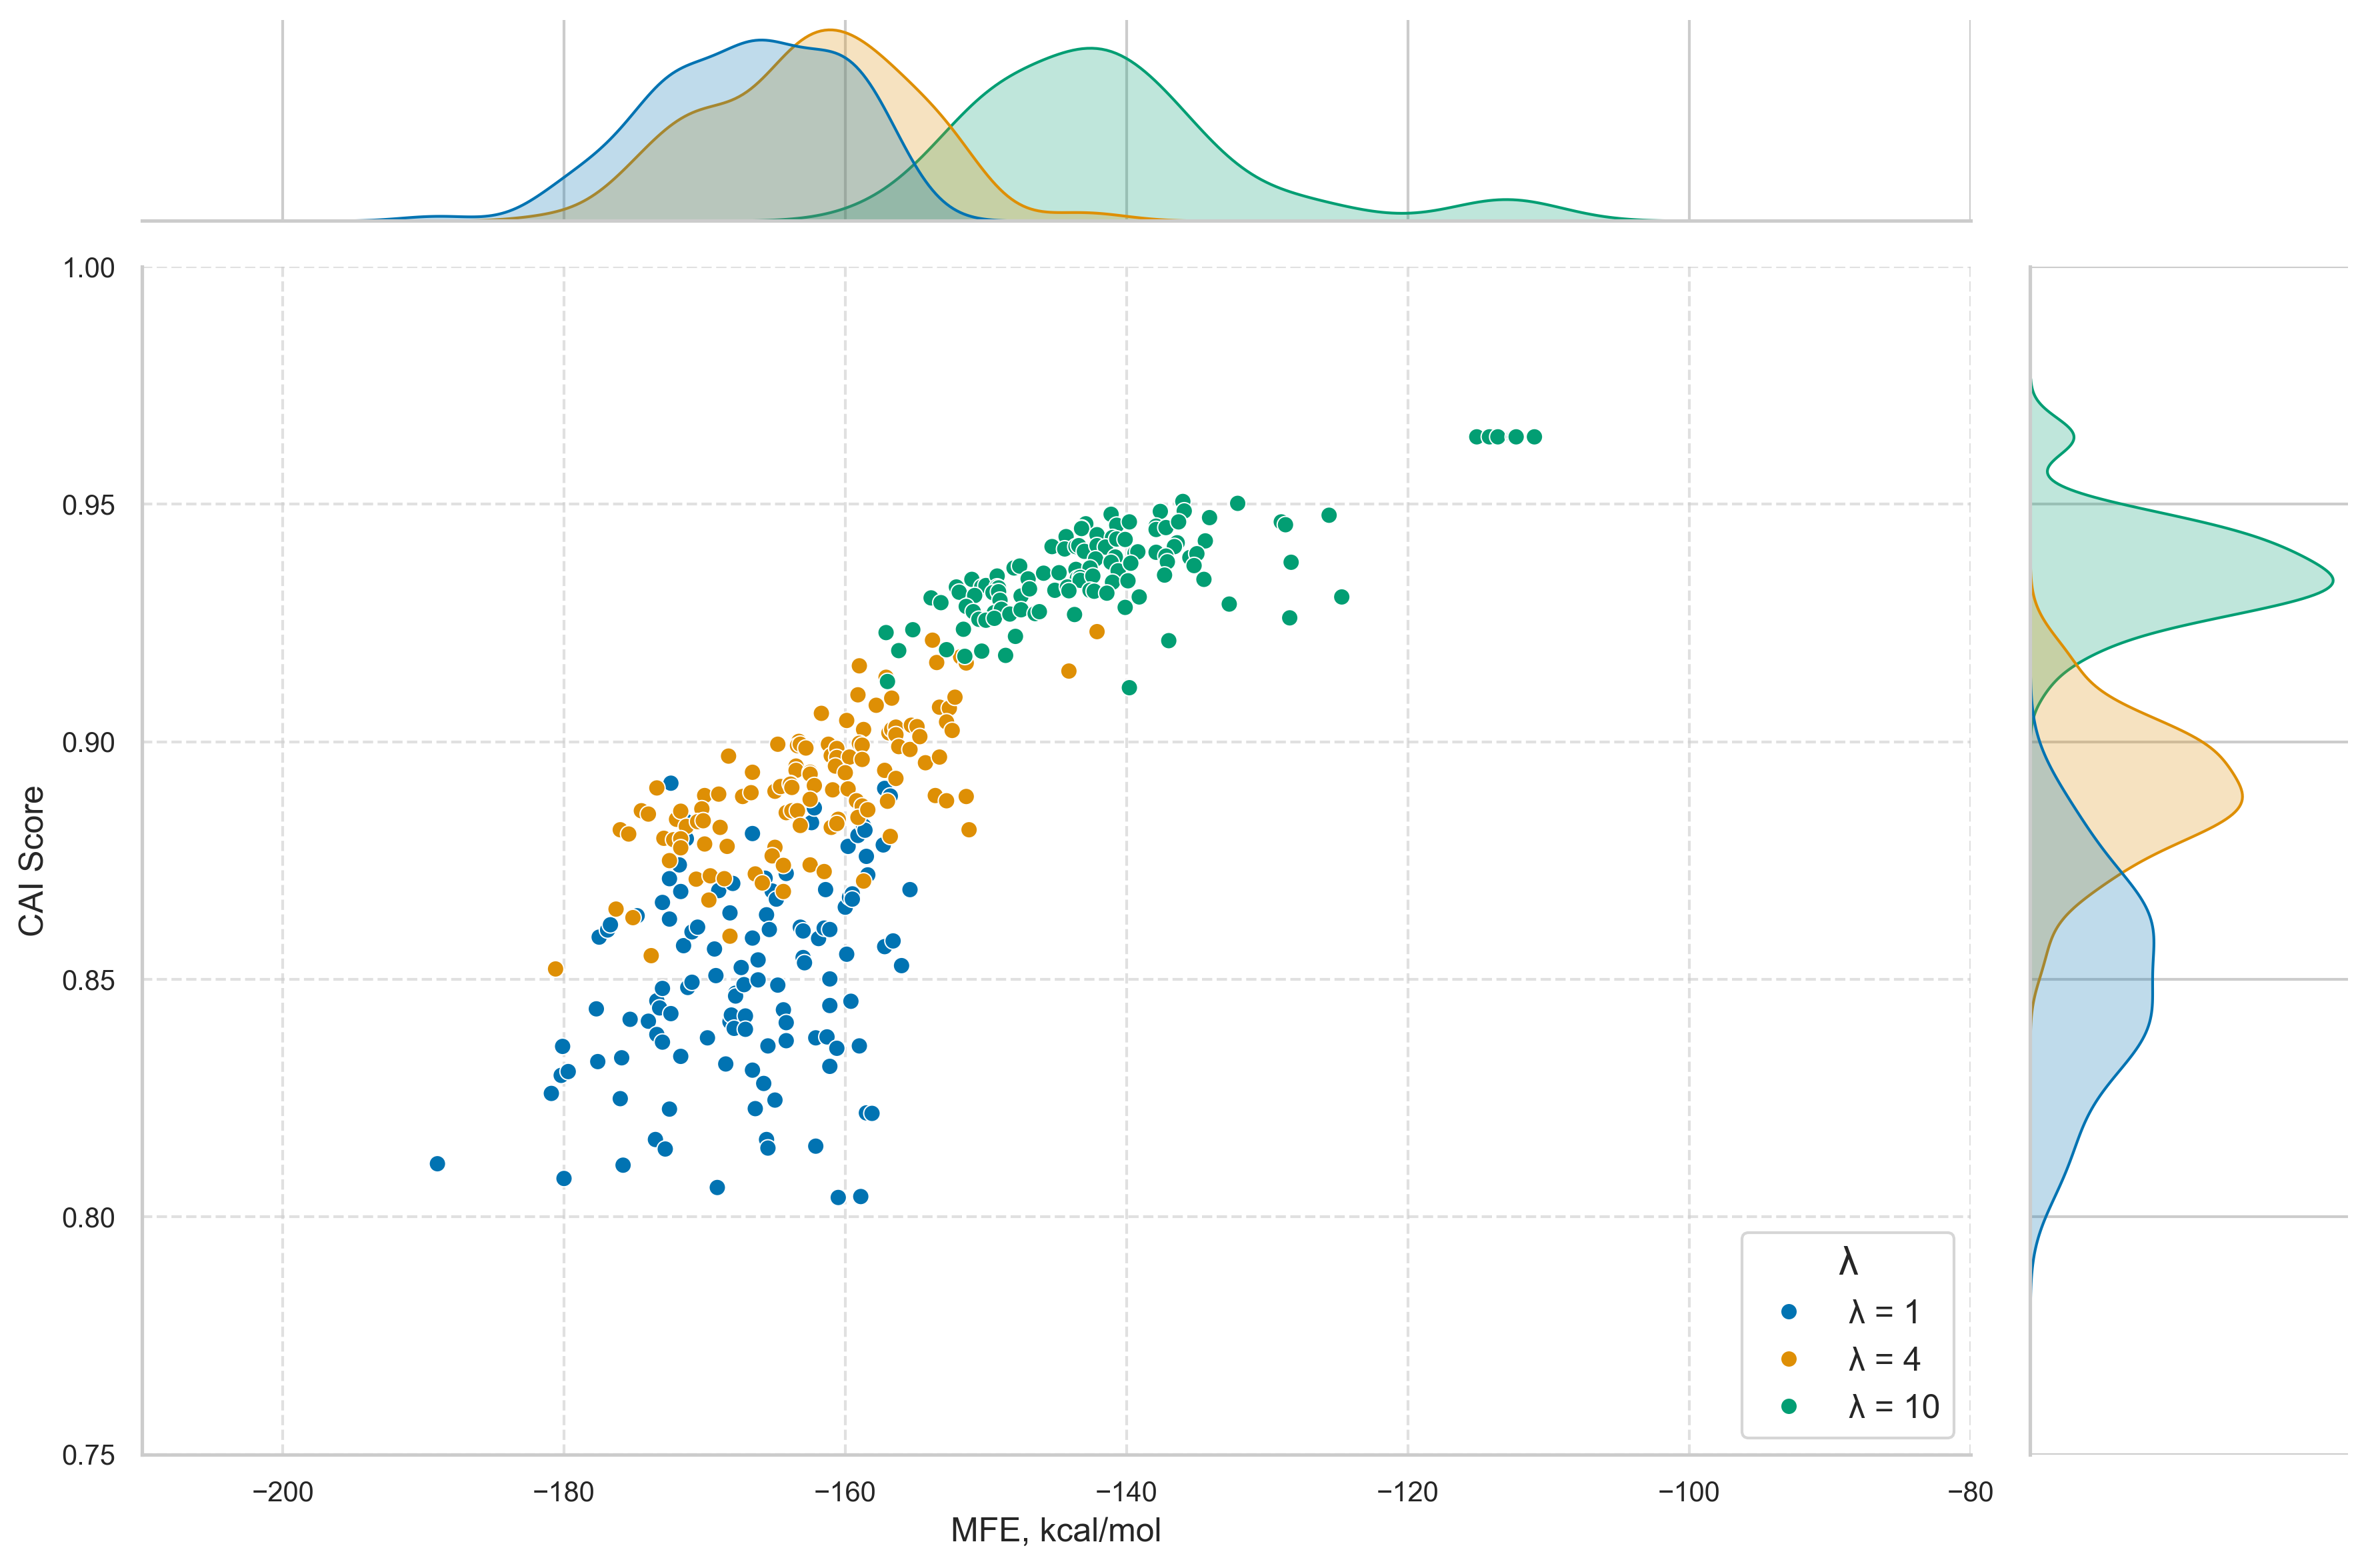

Saved: The role of lambda in the MFE-CAI trade-off.tiff


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from Bio.Seq import Seq
import seaborn as sns
from typing import List, Dict
import os

# --------------------------------------------------------------------------------------
# 🔧 GLOBAL PLOTTING CONFIGURATION (Arial Font and Size)
# --------------------------------------------------------------------------------------

# 1. Set font family to Arial
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 

# 2. Set overall theme and scale
sns.set_theme(style="whitegrid", font_scale=1.2) 

# 3. Set specific Matplotlib parameters for font size control
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 12,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

# Define constants for file organization
FOLDER_PATH = 'results_2025-05-11_10_episodes_experimental_dataset'
LAMBDA_VALUES = [1, 4, 10]
REPLICATES = [1, 2, 3]

# --------------------------------------------------------------------------------------
# 1. Helper Function
# --------------------------------------------------------------------------------------

def translate(seq: str) -> str:
    """Translates a DNA sequence using Bio.Seq.translate, stopping at the first stop codon."""
    return str(Seq(seq).translate(to_stop=True))

# --------------------------------------------------------------------------------------
# 2. Data Loading & Processing Function
# --------------------------------------------------------------------------------------

def load_and_process_lambda_data(lambda_value: int, replicates: List[int]) -> pd.DataFrame:
    """
    Loads all replicate CSVs for a given lambda value, concatenates them, 
    cleans the DataFrame, and selects the single best result (highest MFExCAI score)
    for each unique Original Sequence.
    """
    df_list = []
    
    mapping = {
        1: ['2025-05-11_12-24_lambda_1.csv', '2025-05-11_13-00_lambda_1.csv', '2025-05-11_13-37_lambda_1.csv'],
        4: ['2025-05-11_12-36_lambda_4.csv', '2025-05-11_13-13_lambda_4.csv', '2025-05-11_13-50_lambda_4.csv'],
        10: ['2025-05-11_12-48_lambda_10.csv', '2025-05-11_13-25_lambda_10.csv', '2025-05-11_14-02_lambda_10.csv']
    }
    
    if lambda_value not in mapping:
        raise ValueError(f"Lambda value {lambda_value} not configured.")

    for filename_suffix in mapping[lambda_value]:
        file_path = os.path.join(FOLDER_PATH, f"results_for_run_dated_{filename_suffix}")
        try:
            df_list.append(pd.read_csv(file_path))
        except FileNotFoundError:
            print(f"Warning: File not found: {file_path}. Skipping.")
    
    if not df_list:
        return pd.DataFrame()

    df_concat = pd.concat(df_list, ignore_index=True)
    
    if 'Unnamed: 0' in df_concat.columns:
        df_concat = df_concat.drop(columns=['Unnamed: 0'])
    
    df_sorted = df_concat.sort_values(by='Final MFExCAI score', ascending=False)
    df_best = df_sorted.drop_duplicates(subset='Original Sequence', keep='first')
    
    return df_best.reset_index(drop=True)

# --------------------------------------------------------------------------------------
# 3. Execution and Plotting
# --------------------------------------------------------------------------------------

# --- Load and Process Data for all Lambdas ---
df_best_results: Dict[int, pd.DataFrame] = {}

for lmbda in LAMBDA_VALUES:
    df_best_results[lmbda] = load_and_process_lambda_data(lmbda, REPLICATES)

# --- Prepare Data for Joint Plot ---
dflambda1_best = df_best_results[1]
dflambda4_best = df_best_results[4]
dflambda10_best = df_best_results[10]

# Combine the best results into one DataFrame with a 'Lambda' column for hue
df_combined = pd.concat([
    dflambda1_best.assign(Lambda='λ = 1'),
    dflambda4_best.assign(Lambda='λ = 4'),
    dflambda10_best.assign(Lambda='λ = 10')
], ignore_index=True)

# Define colors based on the number of groups
colors = sns.color_palette("colorblind", n_colors=len(LAMBDA_VALUES))


# --- Generate the sns.jointplot ---

# Create joint plot with hue for lambda
g = sns.jointplot(
    data=df_combined,
    x='Final MFE',
    y='Final CAI',
    hue='Lambda',
    kind='scatter',
    palette=colors,
    height=8 # Added height for better plot visibility
)
g.fig.set_size_inches(12.0, 8.0)
# Customizations: Adjust axis ranges and labels on the joint axis
g.ax_joint.set_xlim(-210.0, -80.0)
g.ax_joint.set_ylim(0.75, 1.0)

# Set labels directly on the joint axis for clear integration
g.ax_joint.set_ylabel('CAI Score')
g.ax_joint.set_xlabel('MFE, kcal/mol')

# Add main title to the entire figure
#g.fig.suptitle('The role of λ in the MFE/CAI trade-off', y=1.02, fontsize=plt.rcParams['axes.titlesize'])

# --- Additional Customizations (Preserved) ---
g.ax_joint.grid(True, linestyle='--', alpha=0.6)
g.ax_joint.legend(title='λ', loc='lower right')

plt.tight_layout()
plt.show()

save_tiff(g, 'The role of lambda in the MFE/CAI trade-off')

The running of each permutation variant was done three tiems to underlie the importance of iterative approach. Due to non-deterministic nature of the algorithm, the best result on first run is not garanteed. The graphs show that running of each variant at least three times provide the better result. 

/var/folders/r2/d51ts3bj7ys1zccpl_fdh4bm0000gn/T/ipykernel_34803/279241241.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Group', y='Score', palette=box_palette, ax=ax1)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: p <= 1.00e-03

Replicate 3 vs. Best of 3: Custom statistical test, P_val:7.013e-10
Replicate 2 vs. Best of 3: Custom statistical test, P_val:6.633e-06
Replicate 1 vs. Best of 3: Custom statistical test, P_val:6.054e-08
Saved: Iterative method finds better solution.tiff
Saved: Paired T-test.tiff


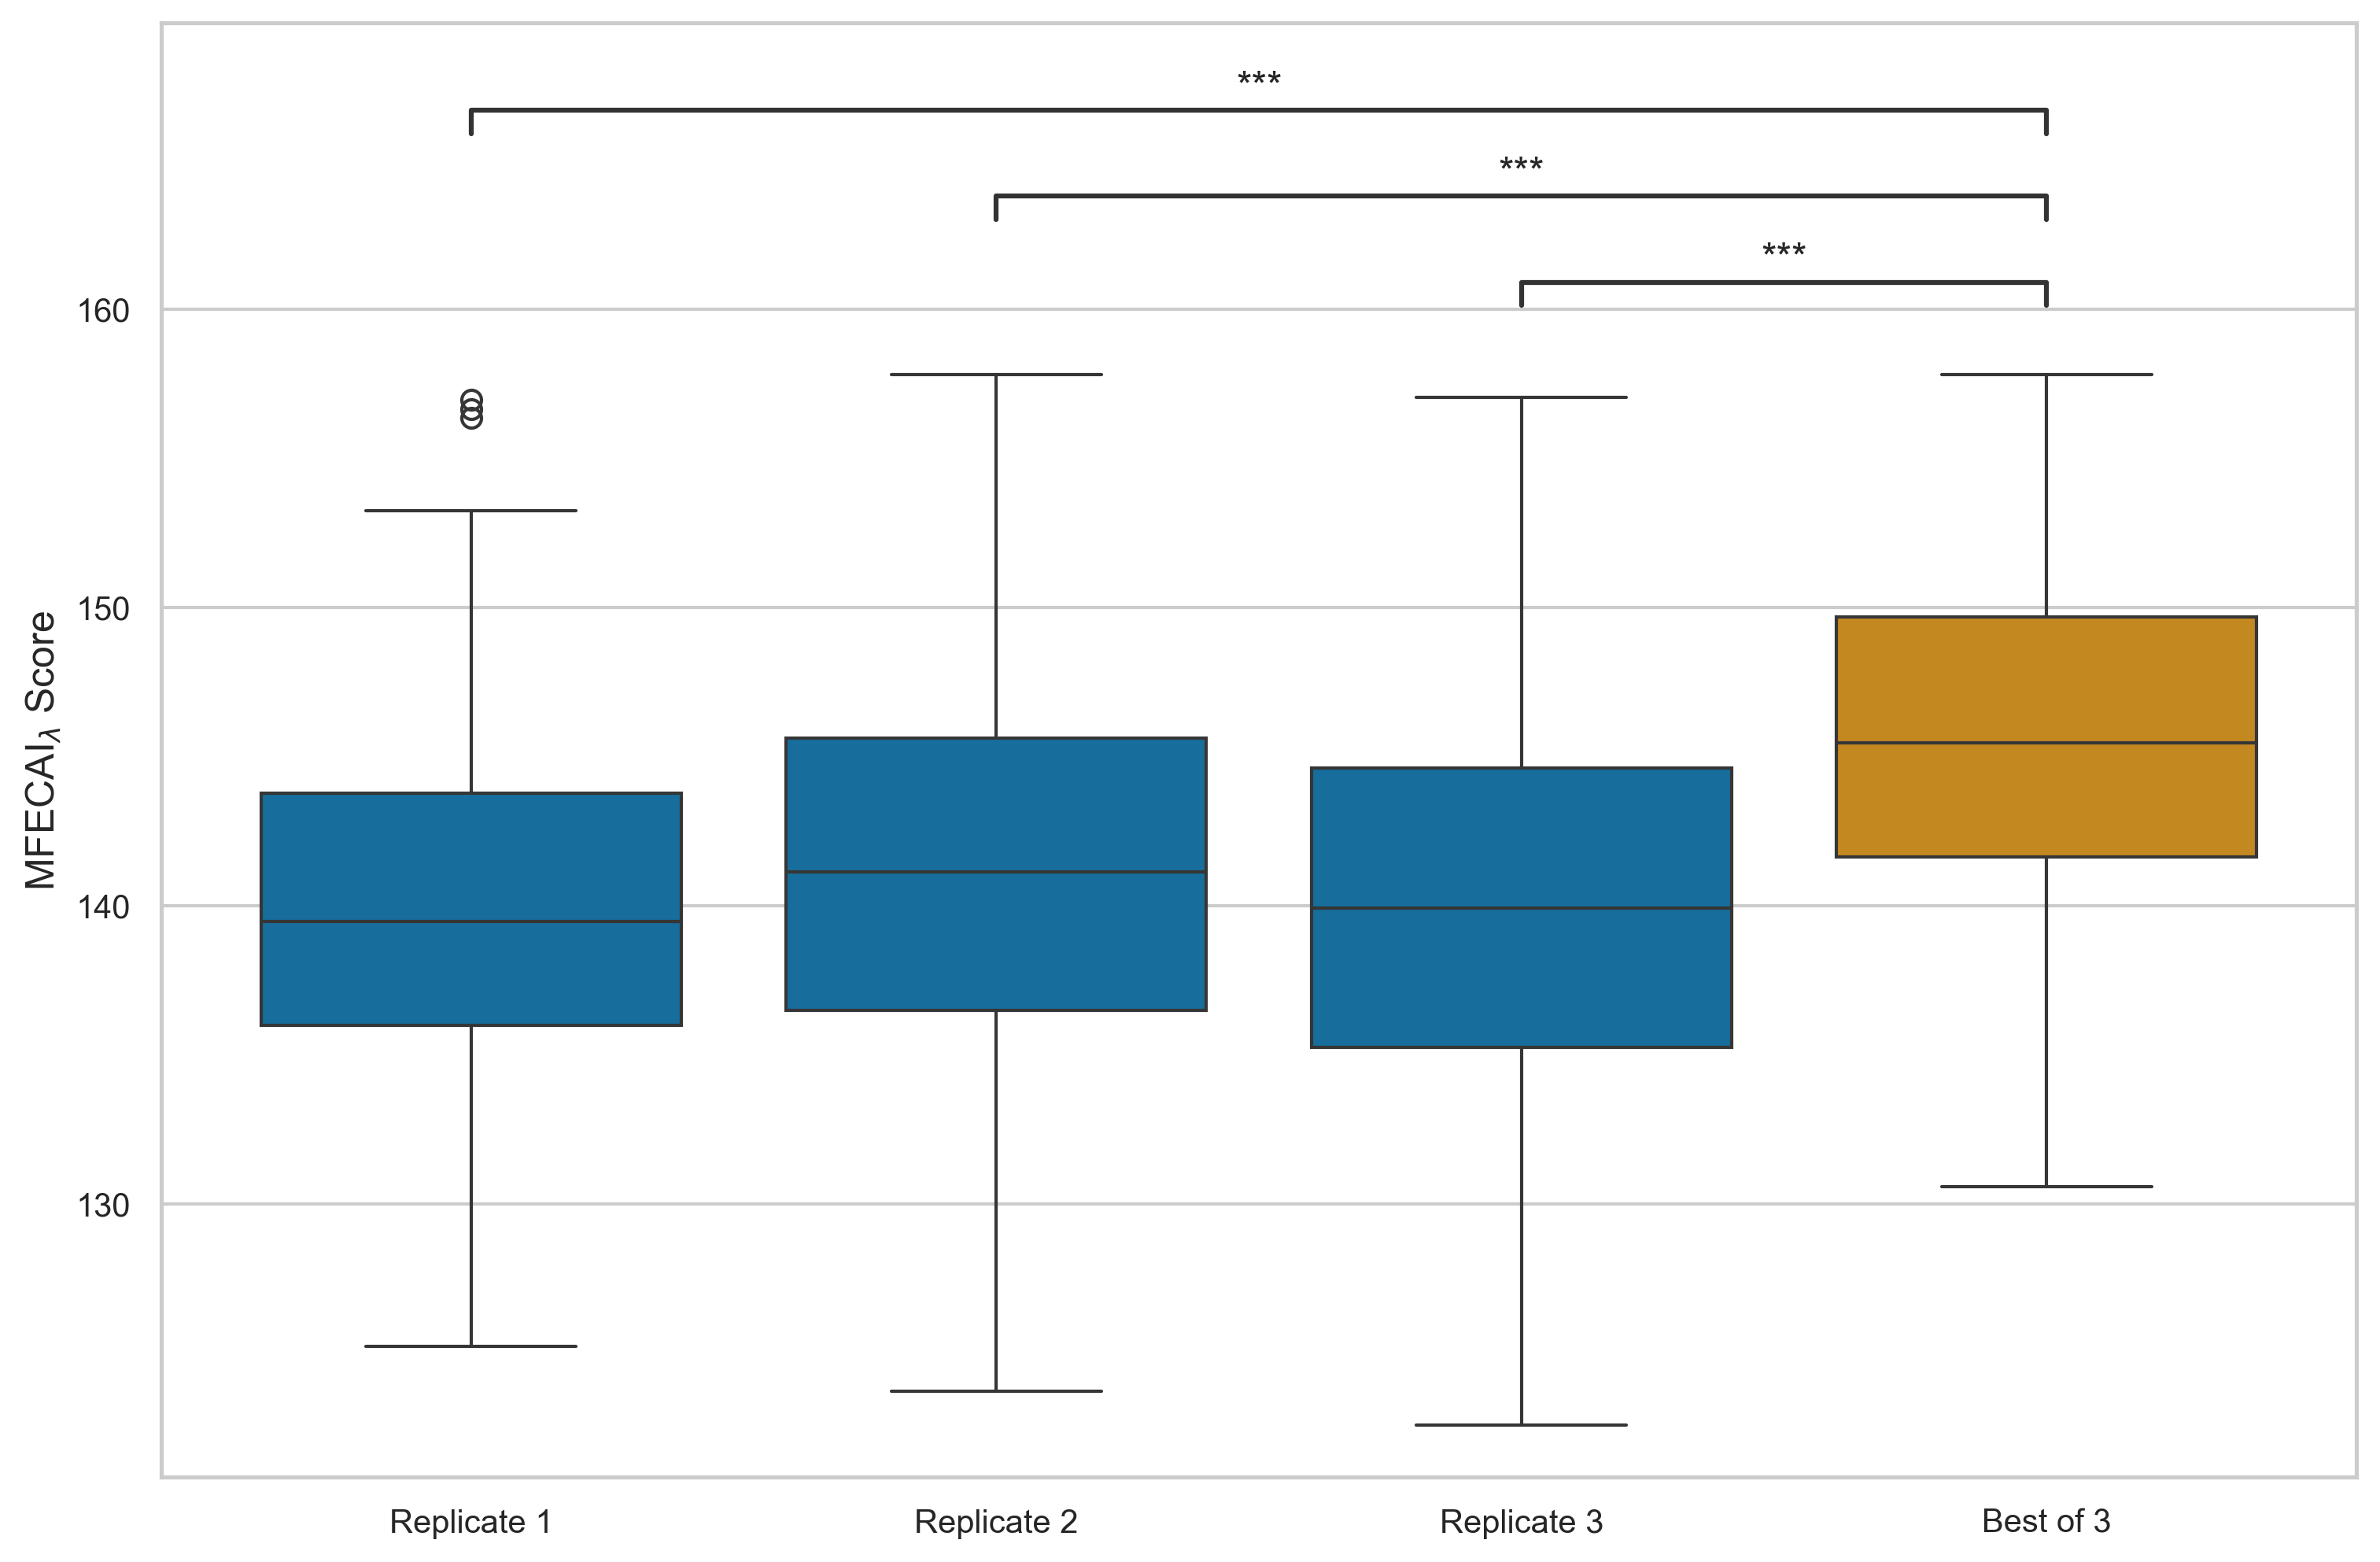

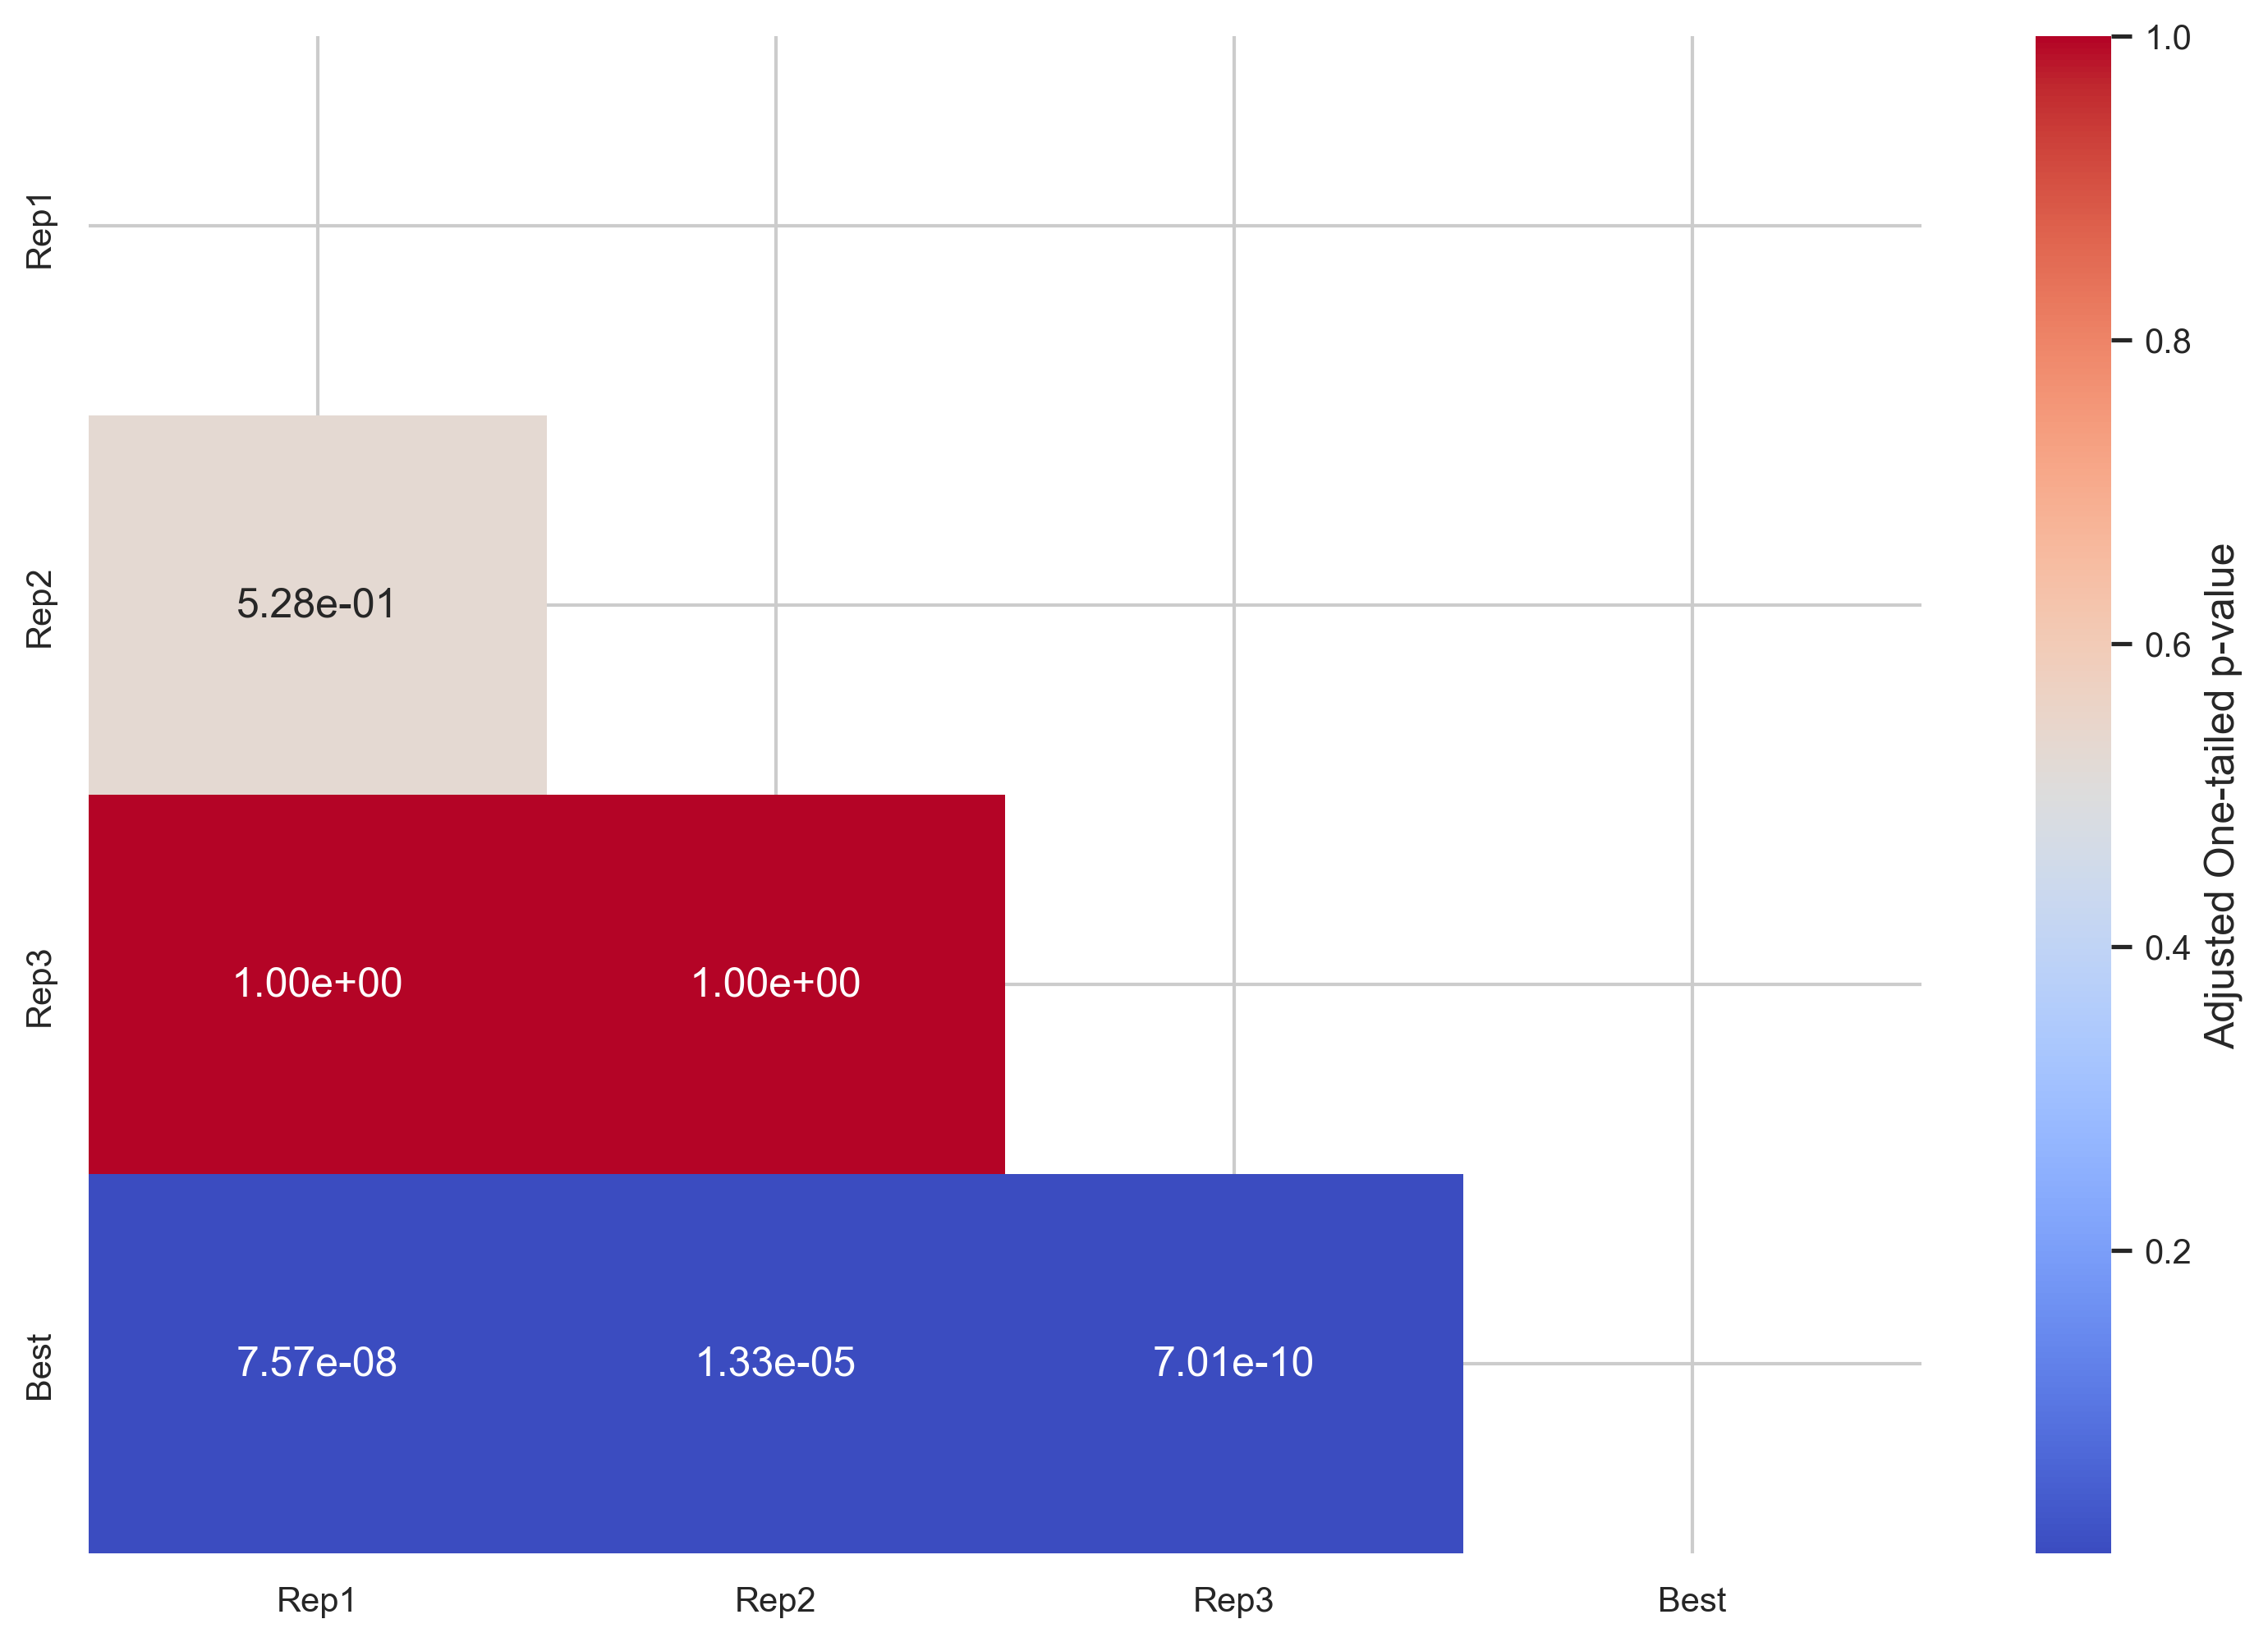

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
from typing import List, Dict
import os
from scipy.stats import ttest_rel
# NOTE: statannotations must be installed separately to avoid NameError for Annotator
from statannotations.Annotator import Annotator 
from statsmodels.stats.multitest import multipletests

# --------------------------------------------------------------------------------------
# 🔧 GLOBAL PLOTTING CONFIGURATION (Arial Font and Size)
# --------------------------------------------------------------------------------------

# 1. Set font family to Arial
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 

# 2. Set overall theme and scale
sns.set_theme(style="whitegrid", font_scale=1.2) 

# 3. Set specific Matplotlib parameters for font size control
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 12,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

# Define constants for file organization
FOLDER_PATH = 'results_2025-05-11_10_episodes_experimental_dataset'
LAMBDA_TO_LOAD = 4
REPLICATES_MAPPING = {
    4: [
        '2025-05-11_12-36_lambda_4.csv', # df4_1
        '2025-05-11_13-13_lambda_4.csv', # df4_2
        '2025-05-11_13-50_lambda_4.csv'  # df4_3
    ]
}

# --------------------------------------------------------------------------------------
# 1. Core Data Loading & Processing Function
# --------------------------------------------------------------------------------------

def load_replicate_data(lambda_value: int) -> List[pd.DataFrame]:
    """Loads individual replicate CSVs for a given lambda value."""
    df_replicates = []
    
    if lambda_value not in REPLICATES_MAPPING:
        raise ValueError(f"Lambda value {lambda_value} not configured for loading.")

    for filename_suffix in REPLICATES_MAPPING[lambda_value]:
        file_path = os.path.join(FOLDER_PATH, f"results_for_run_dated_{filename_suffix}")
        try:
            df_replicates.append(pd.read_csv(file_path))
        except FileNotFoundError:
            print(f"Warning: File not found: {file_path}. Skipping.")
    
    return df_replicates

def get_best_of_replicates(df_list: List[pd.DataFrame]) -> pd.DataFrame:
    """Concatenates replicates and finds the best result per original sequence."""
    if not df_list:
        return pd.DataFrame()
    
    df_concat = pd.concat(df_list, ignore_index=True)
    
    if 'Unnamed: 0' in df_concat.columns:
        df_concat = df_concat.drop(columns=['Unnamed: 0'])
    
    df_sorted = df_concat.sort_values(by='Final MFExCAI score', ascending=False)
    df_best = df_sorted.drop_duplicates(subset='Original Sequence', keep='first')
    
    return df_best.reset_index(drop=True)

# --------------------------------------------------------------------------------------
# 2. Replicate Comparison Analysis Function
# --------------------------------------------------------------------------------------
def plot_replicate_comparison_clean(df_replicates_list: list, df_best: pd.DataFrame, colors_palette):
    if len(df_replicates_list) != 3 or df_best.empty:
        return plt.figure(), plt.figure()

    y1 = df_replicates_list[0]['Final MFExCAI score']
    y2 = df_replicates_list[1]['Final MFExCAI score']
    y3 = df_replicates_list[2]['Final MFExCAI score']
    y4 = df_best['Final MFExCAI score']
    
    data = pd.DataFrame({
        'Score': pd.concat([y1, y2, y3, y4], ignore_index=True),
        'Group': ['Replicate 1']*len(y1) + ['Replicate 2']*len(y2) + 
                 ['Replicate 3']*len(y3) + ['Best of 3']*len(y4)
    })

    box_palette = {'Replicate 1': colors_palette[0], 'Replicate 2': colors_palette[0], 
                   'Replicate 3': colors_palette[0], 'Best of 3': colors_palette[1]}

    # --- PLOT 1: BOX PLOT WITH HOLM-BONFERRONI CORRECTION ---
    fig1, ax1 = plt.subplots(figsize=(12, 8))
    sns.boxplot(data=data, x='Group', y='Score', palette=box_palette, ax=ax1)
    
    # Calculate paired p-values directly using ttest_rel and Holm-Bonferroni correction
    pairs = [('Replicate 1', 'Best of 3'), ('Replicate 2', 'Best of 3'), ('Replicate 3', 'Best of 3')]
    
    # Compute paired p-values manually to ensure reliability
    raw_p_values = [
        ttest_rel(y1, y4).pvalue,
        ttest_rel(y2, y4).pvalue,
        ttest_rel(y3, y4).pvalue
    ]
    
    # Apply Holm-Bonferroni correction
    _, corrected_p_vals, _, _ = multipletests(raw_p_values, method='holm')

    # Pass pre-calculated corrected p-values directly to Annotator
    annotator = Annotator(ax1, pairs, data=data, x='Group', y='Score')
    annotator.configure(
        text_format='star',
        pvalue_thresholds=[(0.001, '***'), (0.01, '**'), (0.05, '*'), (1, 'ns')]
    )
    annotator.set_pvalues(corrected_p_vals)
    annotator.annotate()

    #ax1.set_title('Best of 3 strategy improves MFECAIλ Score')
    ax1.set_ylabel(r'MFECAI$_{\lambda}$ Score')
    ax1.set_xlabel("")
    # --- PLOT 2: HEATMAP WITH ADJUSTED ONE-TAILED P-VALUES ---
    lists = [y1, y2, y3, y4]
    labels = ['Rep1', 'Rep2', 'Rep3', 'Best']
    
    # Calculate raw 1-tailed p-values for lower triangle
    raw_p_list = []
    coords = []
    for i in range(4):
        for j in range(i):
            t_stat, p_val = ttest_rel(lists[i], lists[j])
            one_tailed_p = p_val / 2 if t_stat > 0 else 1 - (p_val / 2)
            raw_p_list.append(one_tailed_p)
            coords.append((i, j))

    # Adjust lower triangle p-values using Holm-Bonferroni
    _, corrected_p_vals, _, _ = multipletests(raw_p_list, method='holm')

    p_matrix = np.full((4, 4), np.nan)
    for (i, j), adj_p in zip(coords, corrected_p_vals):
        p_matrix[i, j] = adj_p

    fig2, ax2 = plt.subplots(figsize=(12, 8))
    sns.heatmap(p_matrix, annot=True, fmt=".2e", cmap='coolwarm', 
                xticklabels=labels, yticklabels=labels,
                cbar_kws={'label':'Adjusted One-tailed p-value'},
                mask=np.triu(np.ones((4,4), dtype=bool)), ax=ax2)
    
    #ax2.set_title("Paired T-Test Comparison")

    return fig1, fig2
# --------------------------------------------------------------------------------------
# 3. Execution Block
# --------------------------------------------------------------------------------------

# Load the required DataFrames for lambda=4
df_replicates_4 = load_replicate_data(LAMBDA_TO_LOAD)
df_best_4 = get_best_of_replicates(df_replicates_4)

# Define colors (consistent with prior requests)
colors_palette = sns.color_palette("colorblind", n_colors=2)

# Run the analysis
graph1, graph2 = plot_replicate_comparison_clean(df_replicates_4, df_best_4, colors_palette)

save_tiff(graph1, 'Iterative method finds better solution')
save_tiff(graph2, 'Paired T-test')

The study of the main parameters (MFE, CAi, MFECAIlambda, and additional parameters (GC, GC3, ENC)) reveals the general improvements in scoring function, the imrpovement of structural stability, the decrease in codon adaptation index, and changes of general codon parameters.

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: p <= 1.00e-03

Original MFExCAI score vs. Final MFExCAI score: Custom statistical test, P_val:5.040e-96
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: p <= 1.00e-03

Original MFE vs. Final MFE: Custom statistical test, P_val:1.431e-99
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: p <= 1.00e-03

Original CAI vs. Final CAI: Custom statistical test, P_val:6.356e-89
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: p <= 1.00e-03

Original GC3 vs. Final GC3: Custom statistical test, P_val:9.297e-07
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00

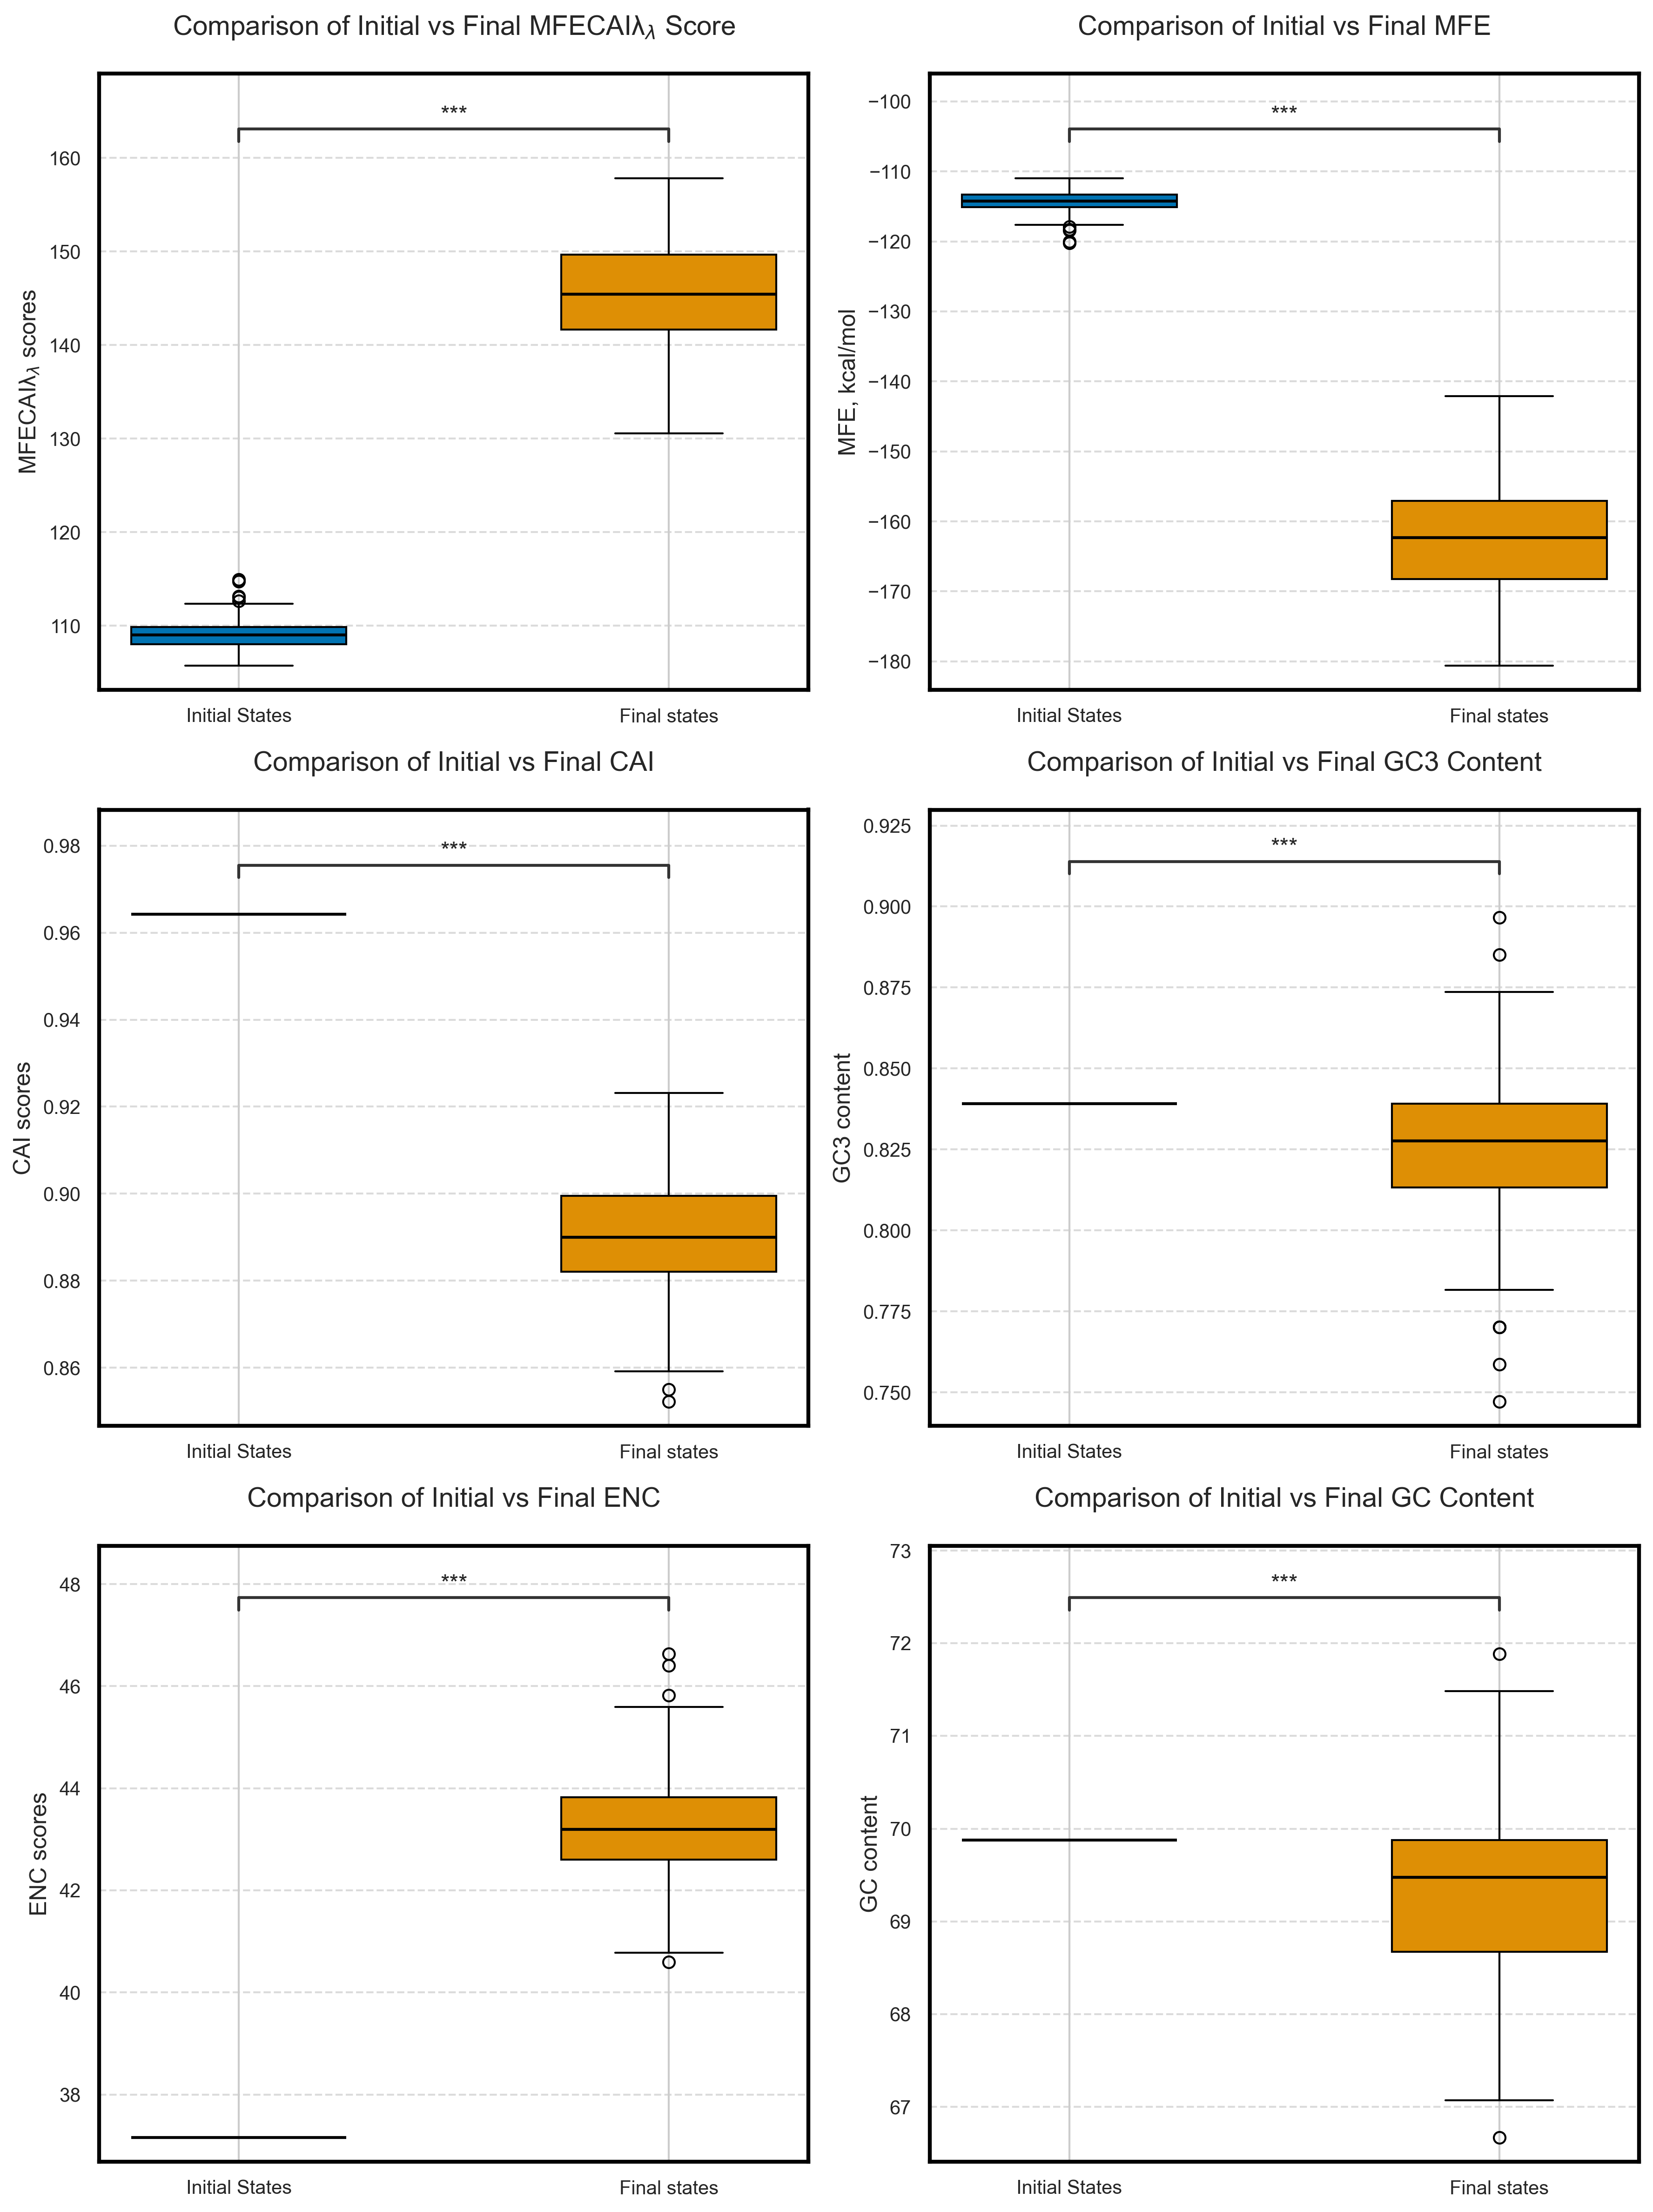

Saved: The change of major mRNA parameters.tiff


In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import os
from typing import List, Dict
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from statannotations.Annotator import Annotator
from Bio.Seq import Seq

# NOTE: External import check for codonbias
try:
    from codonbias.scores import EffectiveNumberOfCodons, BaseCounter
except ImportError:
    print("WARNING: 'codonbias' library not found. GC3 and ENC calculations will fail.")
    class BaseCounter:
        def __init__(self, sequence): pass
        def count(self, sequence): return self
        def get_table(self, normed): return {'G': np.nan, 'C': np.nan}
    class EffectiveNumberOfCodons:
        def get_score(self, sequence): return np.nan

# --------------------------------------------------------------------------------------
# 🔧 GLOBAL PLOTTING CONFIGURATION (Arial Font and Size)
# --------------------------------------------------------------------------------------

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 

plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 12,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

FOLDER_PATH = 'results_2025-05-11_10_episodes_experimental_dataset'
LAMBDA_TO_ANALYZE = 4

# --------------------------------------------------------------------------------------
# 1. CORE HELPER FUNCTIONS (GC3, ENC, Translate)
# --------------------------------------------------------------------------------------

def translate(sequence: str) -> str:
    return str(Seq(sequence).translate(to_stop=True))

def gc3_counter(sequence: str) -> float:
    try:
        nucleotide_counter = BaseCounter(step=3, frame=3)
        frequency_table = nucleotide_counter.count(sequence).get_table(normed=True)
        return frequency_table['G'] + frequency_table['C']
    except Exception:
        return np.nan

def calculateenc(sequence: str) -> float:
    try:
        enc_calculator = EffectiveNumberOfCodons()
        return enc_calculator.get_score(sequence)
    except Exception:
        return np.nan

# --------------------------------------------------------------------------------------
# 2. DATA ACQUISITION AND METRIC CALCULATION SETUP
# --------------------------------------------------------------------------------------

def load_replicate_data(lambda_value: int) -> List[pd.DataFrame]:
    REPLICATES_MAPPING = {
        4: [
            '2025-05-11_12-36_lambda_4.csv',
            '2025-05-11_13-13_lambda_4.csv',
            '2025-05-11_13-50_lambda_4.csv'
        ]
    }
    dataframe_replicates = []
    
    if lambda_value not in REPLICATES_MAPPING:
        raise ValueError(f"Lambda value {lambda_value} not configured for loading.")

    for filename_suffix in REPLICATES_MAPPING[lambda_value]:
        file_path = os.path.join(FOLDER_PATH, f"results_for_run_dated_{filename_suffix}")
        try:
            dataframe_replicates.append(pd.read_csv(file_path))
        except FileNotFoundError:
            print(f"Warning: File not found: {file_path}. Skipping.")
    
    return dataframe_replicates

def get_best_of_replicates(dataframe_list: List[pd.DataFrame]) -> pd.DataFrame:
    if not dataframe_list: 
        return pd.DataFrame()
        
    dataframe_concat = pd.concat(dataframe_list, ignore_index=True)
    
    if 'Unnamed: 0' in dataframe_concat.columns: 
        dataframe_concat = dataframe_concat.drop(columns=['Unnamed: 0'])
        
    dataframe_sorted = dataframe_concat.sort_values(by='Final MFExCAI score', ascending=False)
    dataframe_best = dataframe_sorted.drop_duplicates(subset='Original Sequence', keep='first')
    
    return dataframe_best.reset_index(drop=True)

# Load and process data
dataframe_replicates_4 = load_replicate_data(LAMBDA_TO_ANALYZE)
dflambda4_best = get_best_of_replicates(dataframe_replicates_4)

dflambda4total = dflambda4_best[[
    "Original MFExCAI score" ,"Final MFExCAI score", "Original CAI", "Final CAI", 
    "Original MFE", "Final MFE", "Original GC content", "Final GC content", 
    "Final Sequence", "Original Sequence", "Episode List", "CAI List", "MFE List"
]].copy()

dflambda4total.sort_values(by='Final MFExCAI score', ascending=False, inplace=True)

# Calculate derived metrics
dflambda4total["RNA Length"] = dflambda4total["Final Sequence"].apply(lambda sequence: len(sequence))
dflambda4total["Peptide Sequence"] = dflambda4total["Final Sequence"].apply(translate)
dflambda4total["Peptide Length"] = dflambda4total["Peptide Sequence"].apply(lambda sequence: len(sequence))
dflambda4total["Final GC3"] = dflambda4total["Final Sequence"].apply(gc3_counter)
dflambda4total["Original GC3"] = dflambda4total["Original Sequence"].apply(gc3_counter)
dflambda4total["Final ENC"] = dflambda4total["Final Sequence"].apply(calculateenc)
dflambda4total["Original ENC"] = dflambda4total["Original Sequence"].apply(calculateenc)

dflambda4total = dflambda4total[[
    "Original MFExCAI score" ,"Final MFExCAI score", "Original CAI", "Final CAI", "Original MFE", "Final MFE", 
    "Original GC3", "Final GC3", "Original ENC", "Final ENC", "Original GC content", "Final GC content", 
    "RNA Length", "Peptide Length", "Final Sequence", "Original Sequence", "Peptide Sequence", 
    "Episode List", "CAI List", "MFE List"
]]

selected_dataframe = dflambda4total[[
    "Final Sequence","Original MFExCAI score" ,"Final MFExCAI score", "Original CAI", "Final CAI", 
    "Original MFE", "Final MFE", "Original GC3", "Final GC3", "Original ENC", "Final ENC", 
    "Original GC content", "Final GC content"
]].copy()

selected_dataframe = selected_dataframe.rename(columns={
    "Final Sequence": "Optimized Sequence",
    "Original MFExCAI score": "Original MFECAIλ Score",
    "Final MFExCAI score": "Optimized MFECAIλ Score"
})

# --------------------------------------------------------------------------------------
# 3. PLOTTING FUNCTION DEFINITION (Clean Autoscale + Headroom for Stars)
# --------------------------------------------------------------------------------------

def compare_and_plot_statannot(dataframe, column_original, column_final, parameter_name, adjusted_pvalue,
                               annotation_format='star', axis_object=None):
    
    plot_dataframe = dataframe[[column_original, column_final]].melt(var_name="Label", value_name=parameter_name)

    if axis_object is None:
        figure_object, axis_object = plt.subplots(figsize=(6, 4))
        
    colors_palette = sns.color_palette("colorblind", n_colors=2) 
    
    series_original = dataframe[column_original].dropna()
    series_final = dataframe[column_final].dropna()
    
    # Native Matplotlib boxplot preserves natural proportions
    boxplot_dict = axis_object.boxplot(
        [series_original, series_final], 
        positions=[0, 1], 
        widths=0.5, 
        patch_artist=True,
        medianprops=dict(color='black', linewidth=1.5)
    )
    
    for index_patch, patch_box in enumerate(boxplot_dict['boxes']):
        patch_box.set_facecolor(colors_palette[index_patch])
        patch_box.set_alpha(1.0)
        patch_box.set_edgecolor('black')

    axis_object.yaxis.grid(True, linestyle='--', alpha=0.7)

    title_map = {
        ("Original MFExCAI score", "Final MFExCAI score"): r'Comparison of Initial vs Final MFECAIλ$_{\lambda}$ Score',
        ("Original MFE", "Final MFE"): 'Comparison of Initial vs Final MFE',
        ("Original CAI", "Final CAI"): 'Comparison of Initial vs Final CAI',
        ("Original GC3", "Final GC3"): 'Comparison of Initial vs Final GC3 Content',
        ("Original ENC", "Final ENC"): 'Comparison of Initial vs Final ENC',
        ("Original GC content", "Final GC content"): 'Comparison of Initial vs Final GC Content'
    }
    title_text = title_map.get((column_original, column_final), f'{column_original} vs {column_final}')
        
    axis_object.set_title(title_text, pad=20)
    axis_object.set_ylabel(parameter_name)
    axis_object.set_xlabel('')
    axis_object.set_xticks([0, 1])
    axis_object.set_xticklabels(['Initial States', 'Final states'])

    # NATURAL AUTOSCALE WITH TOP HEADROOM FOR ANNOTATION STARS
    axis_object.relim()
    axis_object.autoscale_view()
    y_lower, y_upper = axis_object.get_ylim()
    y_range = y_upper - y_lower
    axis_object.set_ylim(y_lower, y_upper + 0.15 * y_range)

    # Apply pre-calculated Holm-adjusted p-value using Annotator
    if not np.isnan(adjusted_pvalue):
        annotation_pairs = [(column_original, column_final)]
        annotator_object = Annotator(axis_object, annotation_pairs, data=plot_dataframe, x="Label", y=parameter_name)
        annotator_object.configure(
            text_format=annotation_format, 
            loc='inside', 
            pvalue_thresholds=[(0.001, '***'), (0.01, '**'), (0.05, '*'), (1, 'ns')]
        )
        annotator_object.set_pvalues([adjusted_pvalue])
        annotator_object.annotate()

    return axis_object

# --------------------------------------------------------------------------------------
# 4. MULTI-PANEL EXECUTION AND FINAL STYLING
# --------------------------------------------------------------------------------------

metric_pairs = [
    ("Original MFExCAI score", "Final MFExCAI score", r"MFECAIλ$_{\lambda}$ scores"),
    ("Original MFE", "Final MFE", "MFE, kcal/mol"),
    ("Original CAI", "Final CAI", "CAI scores"),
    ("Original GC3", "Final GC3", "GC3 content"),
    ("Original ENC", "Final ENC", "ENC scores"),
    ("Original GC content", "Final GC content", "GC content")
]

# Compute raw paired t-test p-values explicitly
raw_p_values = []
for column_original, column_final, _ in metric_pairs:
    valid_data = dflambda4total[[column_original, column_final]].dropna()
    if len(valid_data) > 1:
        p_val = ttest_rel(valid_data[column_original], valid_data[column_final]).pvalue
    else:
        p_val = np.nan
    raw_p_values.append(p_val)

# Adjust valid p-values across comparisons using Holm-Bonferroni
valid_indices = [i for i, p in enumerate(raw_p_values) if not np.isnan(p)]
adjusted_p_values = [np.nan] * len(raw_p_values)

if valid_indices:
    valid_raw_p = [raw_p_values[i] for i in valid_indices]
    _, valid_adj_p, _, _ = multipletests(valid_raw_p, method='holm')
    for idx, adj_p in zip(valid_indices, valid_adj_p):
        adjusted_p_values[idx] = adj_p

# Create 6-subplot figure (3 rows, 2 columns)
figure_main, axis_array = plt.subplots(3, 2, figsize=(12, 16))
axis_array_flat = axis_array.flatten()

# Plotting calls to the subplots
for index_value, (column_original, column_final, label_text) in enumerate(metric_pairs):
    compare_and_plot_statannot(
        dataframe=dflambda4total, 
        column_original=column_original, 
        column_final=column_final, 
        parameter_name=label_text, 
        adjusted_pvalue=adjusted_p_values[index_value],
        axis_object=axis_array_flat[index_value]
    )

# Custom Styling and Annotation (A, B, C...)
for axis_object in axis_array_flat:
    for spine_object in axis_object.spines.values():
        spine_object.set_visible(True)     
        spine_object.set_linewidth(2)      
        spine_object.set_color('black')    

"""custom_positions = [
    (0.03, 0.99), (0.52, 0.99), (0.03, 0.66), (0.52, 0.66), (0.03, 0.33), (0.52, 0.33)
]

for index_value, (x_position, y_position) in enumerate(custom_positions):
    figure_main.text(x_position, y_position, f"{string.ascii_uppercase[index_value]}", 
             fontsize=14, fontweight='bold', ha='right', va='bottom',
             transform=figure_main.transFigure, 
             bbox=dict(
                 boxstyle="round,pad=0.3", 
                 facecolor="white", 
                 edgecolor="black", 
                 linewidth=2 
             ))
"""
plt.tight_layout()
plt.show()

save_tiff(figure_main, 'The change of major mRNA parameters')

The distribution of Original and Optimized Scores reveal the significant improvements. However, the broadaning of solution space was observed. This may be explained by exploration of large solutions' space.

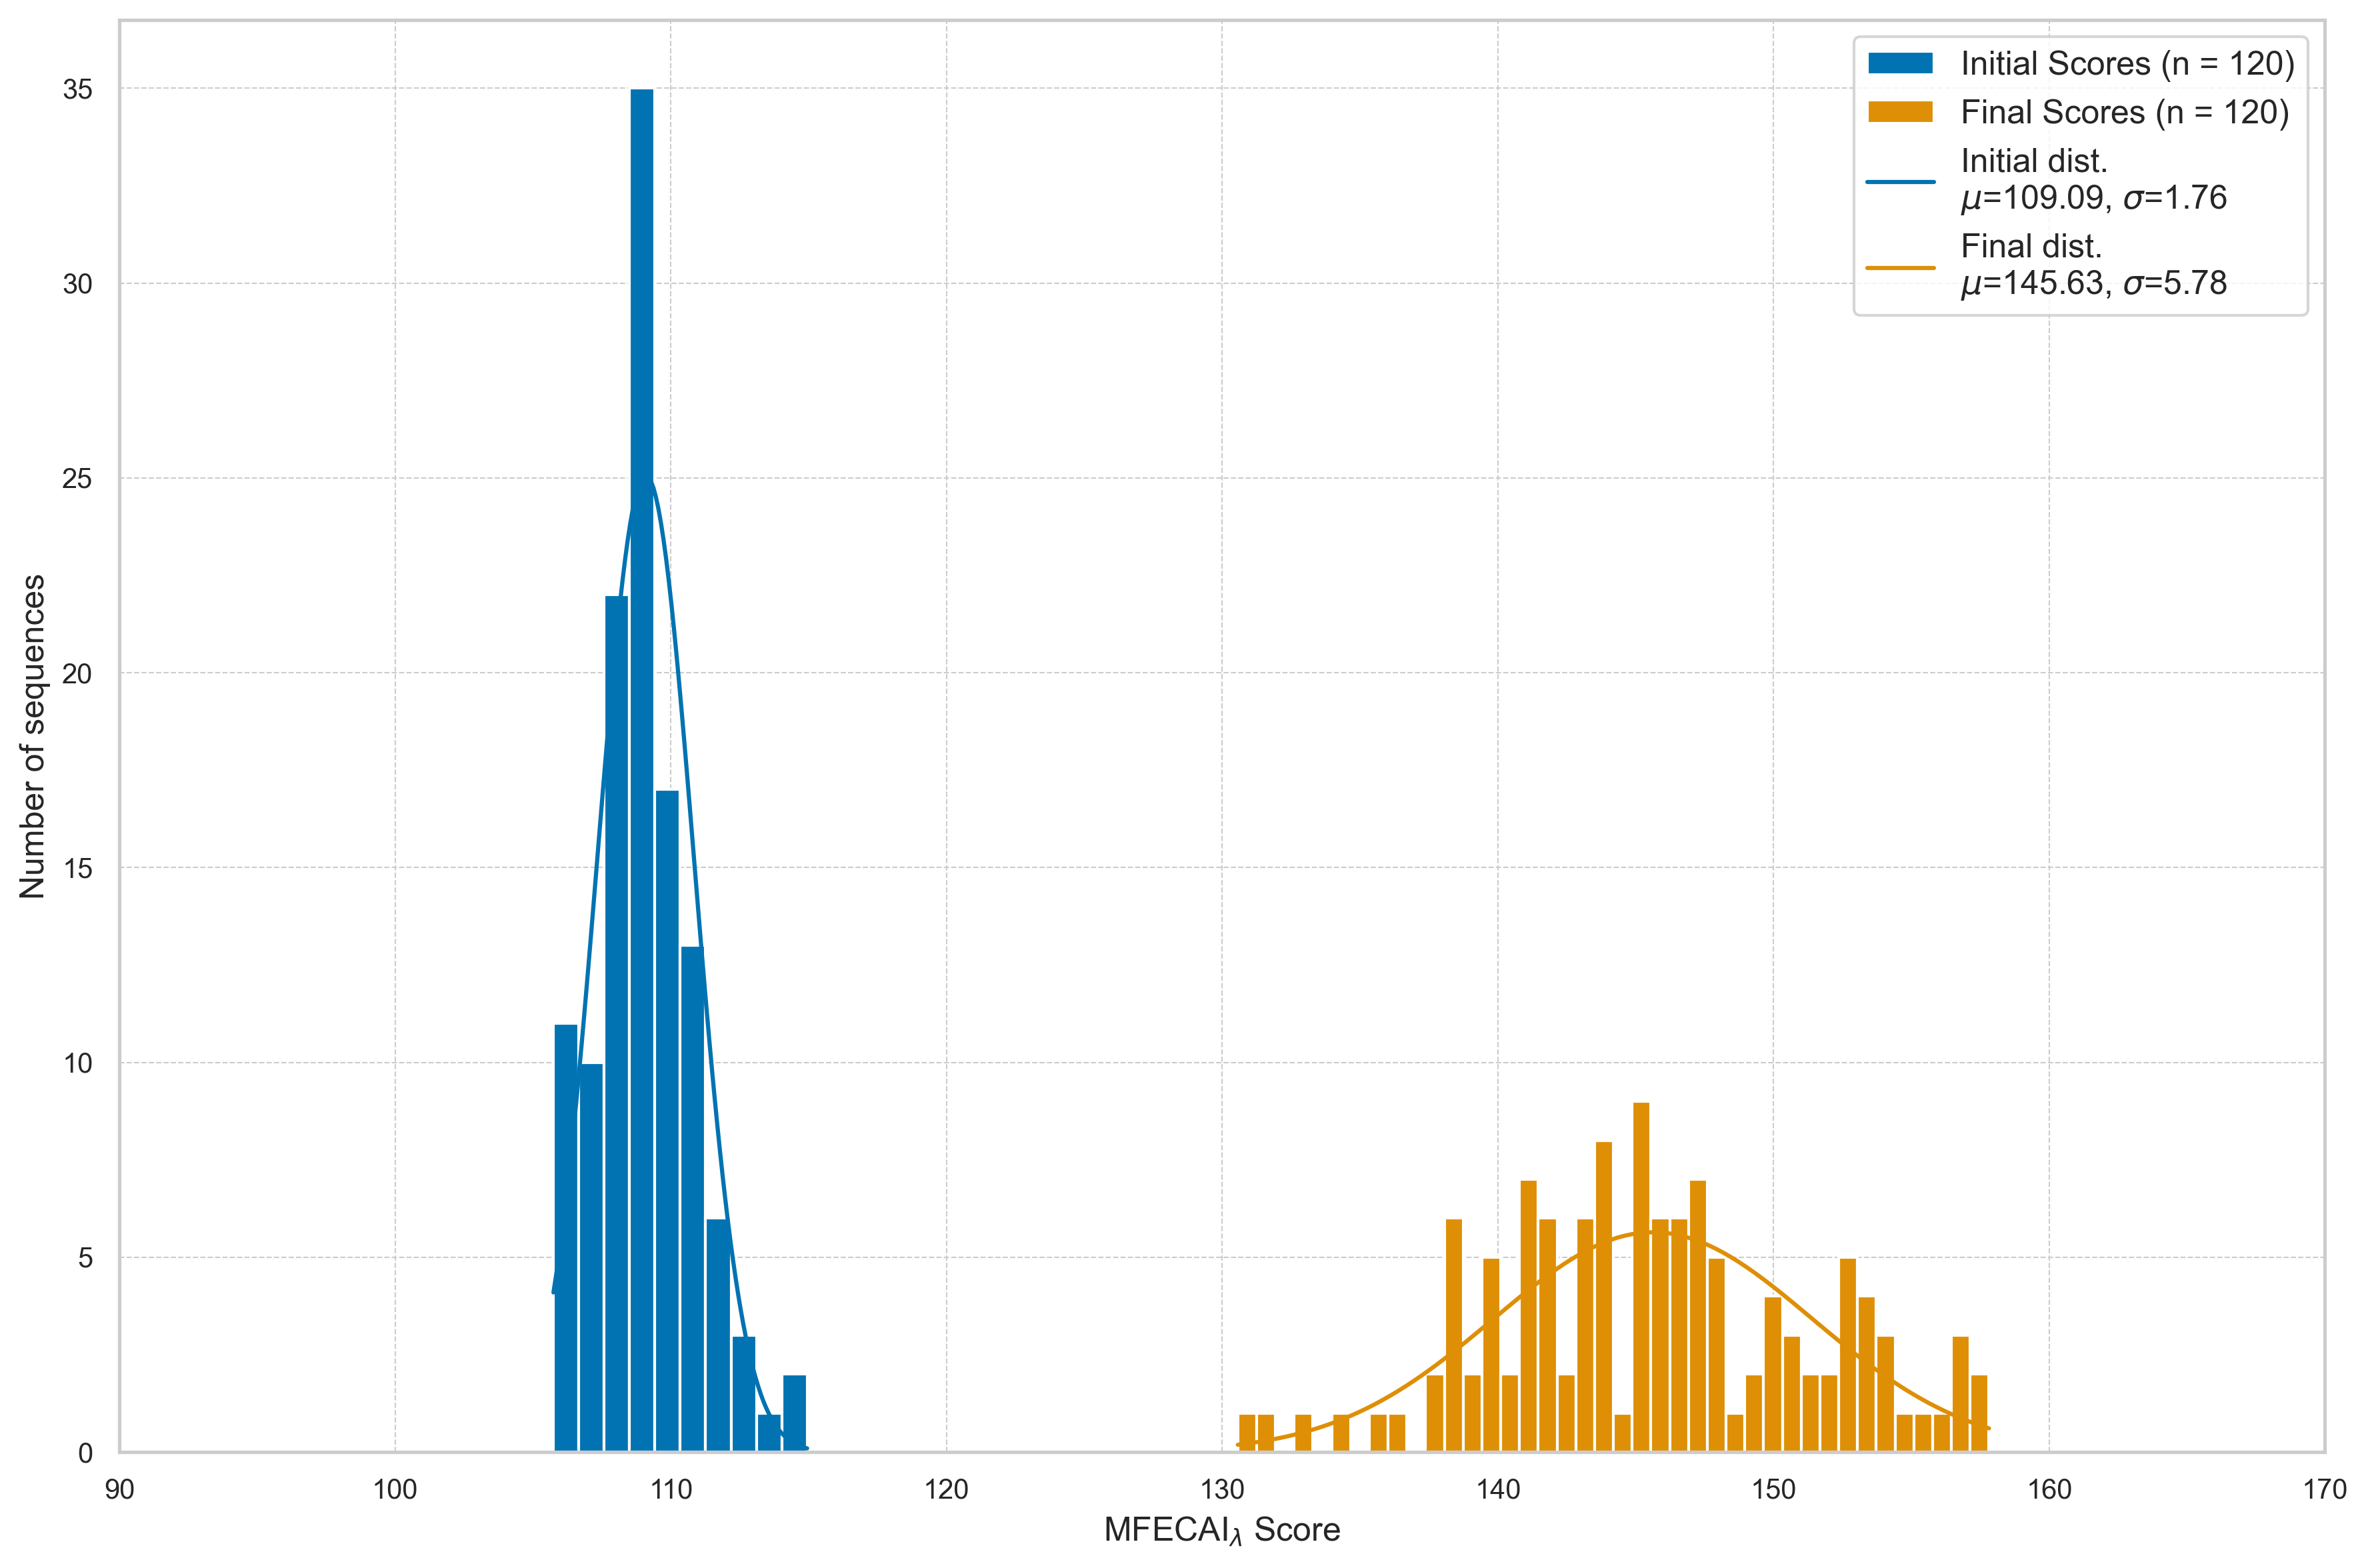

Saved: Comparison of distributions of initial and final states.tiff


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
import matplotlib
import os

# --- Re-set Global Plotting Configuration (Maintaining Arial preference) ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 12,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})
# Re-define colors (as the standard colorblind palette is used)
colors = sns.color_palette("colorblind")

# --- Data Preparation ---
# NOTE: This assumes 'dflambda4_best' is available from previous execution steps.
maindf = dflambda4_best

# Sort is necessary to ensure consistent plotting order and accurate min/max for bins
maindf.sort_values(by='Final MFExCAI score', ascending=False, inplace=True)

# 1. Final Scores (taken directly from the best results)
finalscores = maindf['Final MFExCAI score']

# 2. Initial Scores (Grouped mean of original scores, required if replicates were used)
# Since dflambda4_best contains unique sequences based on the best final score, 
# simply extracting 'Original MFExCAI score' is sufficient and more direct:
initialscores = maindf['Original MFExCAI score']

# --- Normal Distribution Fitting and Bin Calculation ---

# Calculate bin widths for density scaling (n * pdf * bin_width = actual count)
# The choice of 10 and 40 bins is preserved from the original code.
bin_width1 = (max(initialscores) - min(initialscores)) / 10
bin_width2 = (max(finalscores) - min(finalscores)) / 40 # Using 40 for final as implied by bins=40/4 = 10 (incorrectly named bin_width2)

# Initial Scores Distribution Fitting
mu1, std1 = norm.fit(initialscores)
x1 = np.linspace(min(initialscores), max(initialscores), 100)
pdf1 = norm.pdf(x1, mu1, std1)

# Final Scores Distribution Fitting
mu2, std2 = norm.fit(finalscores)
x2 = np.linspace(min(finalscores), max(finalscores), 100)
pdf2 = norm.pdf(x2, mu2, std2)

# --- Plotting ---
fig = plt.figure(figsize=(12, 8))

# Plot Histograms (Density=False for count on Y-axis)
plt.hist(initialscores, bins=10, color=colors[0], alpha=1, label=f'Initial Scores (n = {len(initialscores)})', density=False)
plt.hist(finalscores, bins=40, color=colors[1], alpha=1, label=f'Final Scores (n = {len(finalscores)})', density=False)

# Plot Fitted Normal Distributions (Scaled by total counts * bin width)
# Note: Bin_width1 is used for the scaling of the 10-bin initial histogram, 
# and bin_width2 is used for the 40-bin final histogram.
plt.plot(x1, pdf1 * len(initialscores) * bin_width1, color=colors[0], linestyle = '-', 
         label=f'Initial dist.\n$\mu$={mu1:.2f}, $\sigma$={std1:.2f}')
plt.plot(x2, pdf2 * len(finalscores) * bin_width2, color=colors[1], linestyle = '-', 
         label=f'Final dist.\n$\mu$={mu2:.2f}, $\sigma$={std2:.2f}')

# Customization
plt.xlabel(r'MFECAI$_{\lambda}$ Score')
plt.ylabel('Number of sequences')
#plt.title('Comparison of Initial and Final MFECAI$_{\lambda}$ Scores')
plt.grid(True, which='both', axis='x', linestyle='--', linewidth=0.5) 
plt.grid(True, which='both', axis='y', linestyle='--', linewidth=0.5)

# Set X-axis limit as in original code
plt.xlim(90, 170)

plt.legend()
plt.tight_layout()
plt.show()
save_tiff(fig, 'Comparison of distributions of initial and final states')

The optimization process was studied over episodes (10 episodes in total). We see an initial drop of scoring function which indicates the exploration of the solution space. Then the parameter gradually increases. The marginal gains of MFE overcome the marginal losses of CAI, the scoring function grows. 

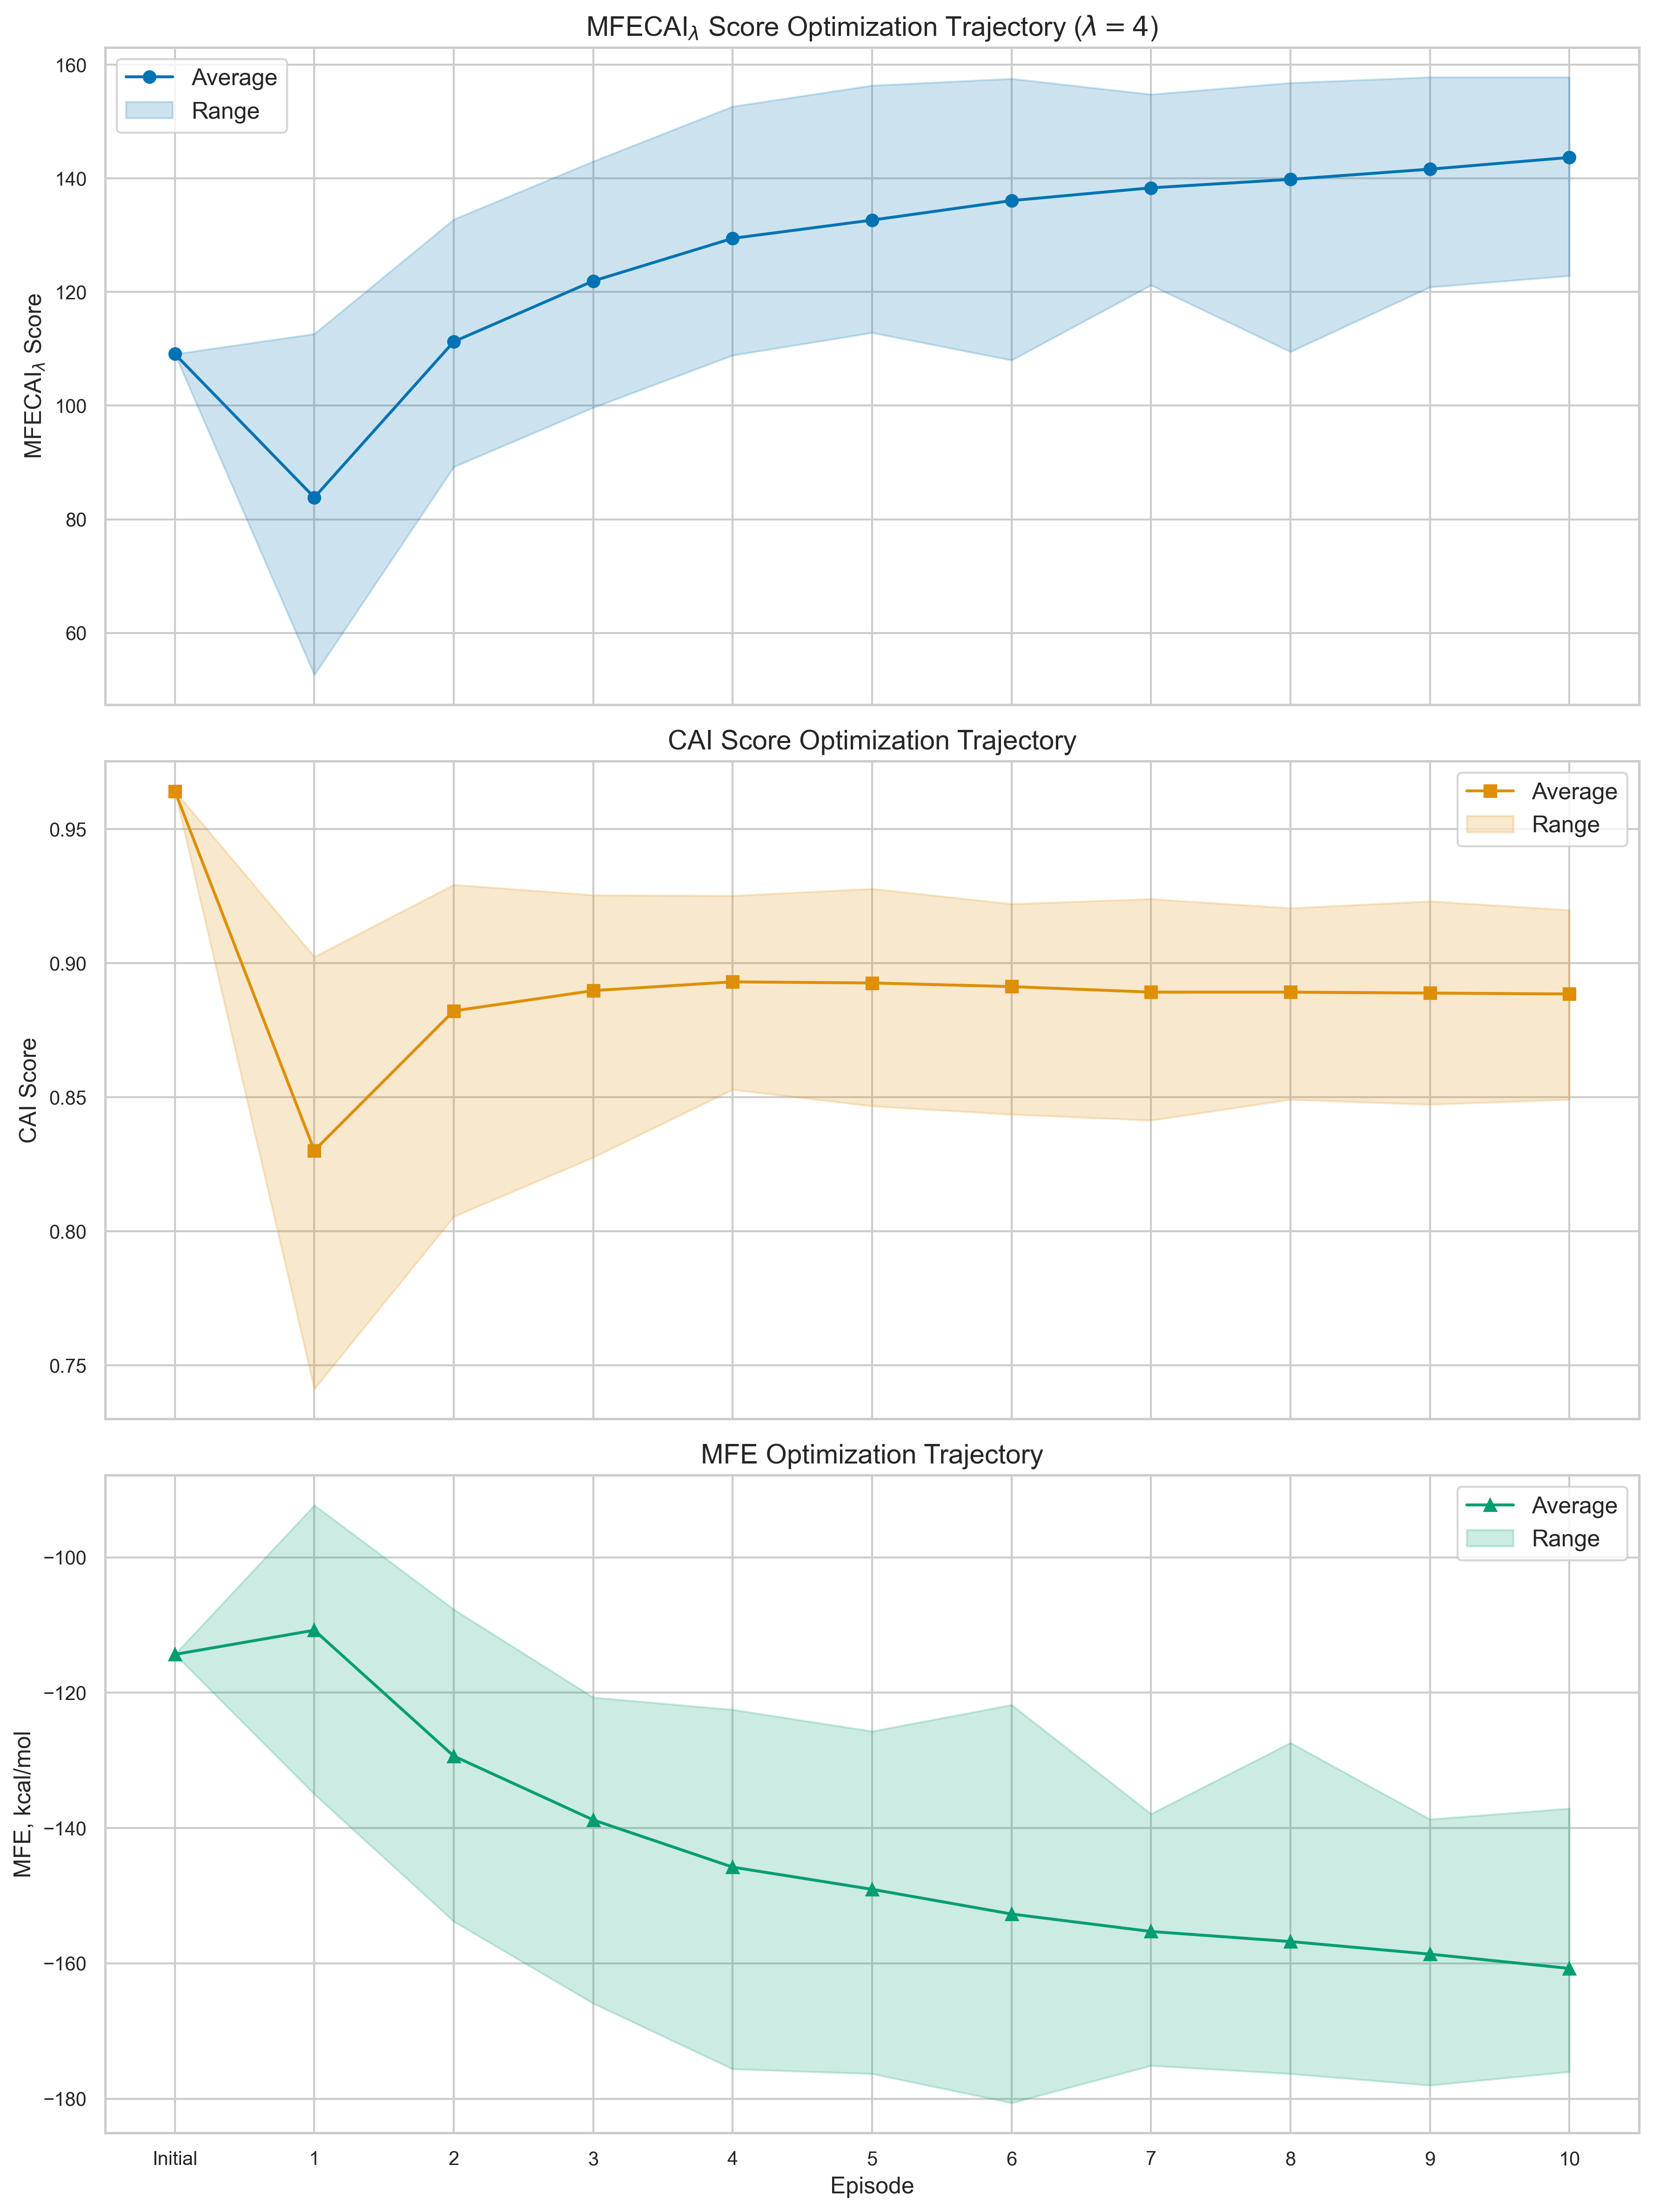

Saved: Optimization process trajectories.tiff


In [36]:
import ast 
import matplotlib.pyplot as plt
import numpy as np
import math
import seaborn as sns
import matplotlib as mpl

# Set font configuration globally (copied from previous configuration steps)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 12,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

# NOTE: This code assumes the DataFrame 'dflambda4total' has been previously loaded
# and processed, containing the list columns (CAI List, MFE List, Episode List).

maindf = dflambda4total

# --- Setup and Initial Score Calculation (Using mean of Original CAI/MFE) ---

# Determine length and average original metrics
length = len(maindf['Final Sequence'].iloc[0])
originalcai = maindf['Original CAI'].mean()
originalmfe = maindf['Original MFE'].mean()

# FIX: Use lambda=4 consistently for the score calculation
LAMBDA_FACTOR = 4 
originalcaimfescore = abs(originalmfe - LAMBDA_FACTOR * (length // 3) * math.log10(originalcai))

colors = sns.color_palette("colorblind")
caimfescorelisttotal = []
cailisttotal = []
mfelisttotal = []

# Parse episode list (assumes the first row is representative of episode numbers)
epsisode_list = ast.literal_eval(maindf['Episode List'].iloc[0])
epsisode_list.insert(0, 0) # Insert 0 for the initial state

# --- Loop through all sequences to calculate trajectory scores ---
for cailist_str, mfelist_str in zip(maindf['CAI List'], maindf['MFE List']):
    # Use ast.literal_eval to convert list strings to actual lists
    cailist = ast.literal_eval(cailist_str) if isinstance(cailist_str, str) else cailist_str
    mfelist = ast.literal_eval(mfelist_str) if isinstance(mfelist_str, str) else mfelist_str
    
    caimfelistlocal = []
    cailistlocal = []
    mfelistlocal = []
    
    for i in range(len(cailist)):
        # CORRECTED MFECAI Score Calculation (using LAMBDA_FACTOR=4 consistently)
        caimfescore = mfelist[i] - LAMBDA_FACTOR * (length // 3) * math.log10(cailist[i])
        caimfelistlocal.append(abs(caimfescore))
        cailistlocal.append(abs(cailist[i]))
        mfelistlocal.append(mfelist[i])
    
    caimfescorelisttotal.append(caimfelistlocal)
    cailisttotal.append(cailistlocal)
    mfelisttotal.append(mfelistlocal)

# --- Compute Averages and Min/Max Ranges ---
caimfearray = np.array(caimfescorelisttotal)
caiarray = np.array(cailisttotal)
mfearray = np.array(mfelisttotal)

# Averages
caimfescorelistaverages = np.mean(caimfearray, axis=0)
caiarrayaverages = np.mean(caiarray, axis=0)
mfearrayaverages = np.mean(mfearray, axis=0)

# Insert original scores as the first point (Episode 0)
caimfescorelistaverages = np.insert(caimfescorelistaverages, 0, originalcaimfescore)
caiarrayaverages = np.insert(caiarrayaverages, 0, originalcai)
mfearrayaverages = np.insert(mfearrayaverages, 0, originalmfe)

# Min/Max for shading range
caimfescorelistmin = np.insert(np.min(caimfearray, axis=0), 0, originalcaimfescore)
caimfescorelistmax = np.insert(np.max(caimfearray, axis=0), 0, originalcaimfescore)

cai_min = np.insert(np.min(caiarray, axis=0), 0, originalcai)
cai_max = np.insert(np.max(caiarray, axis=0), 0, originalcai)

mfe_min = np.insert(np.min(mfearray, axis=0), 0, originalmfe)
mfe_max = np.insert(np.max(mfearray, axis=0), 0, originalmfe)

# --- Plotting ---
fig, axs = plt.subplots(3, 1, figsize=(12, 16), sharex=True)

# Plot 1 - MFECAI Score
axs[0].plot(epsisode_list, caimfescorelistaverages, color=colors[0], linestyle = '-', marker = 'o', label='Average')
axs[0].fill_between(epsisode_list, caimfescorelistmin, caimfescorelistmax, color=colors[0], alpha=0.2, label='Range')
axs[0].set_ylabel(r'MFECAI$_{\lambda}$ Score')
axs[0].set_title(r'MFECAI$_{\lambda}$ Score Optimization Trajectory ($\lambda=4$)')
axs[0].grid(True)
axs[0].legend()

# Plot 2 - CAI
axs[1].plot(epsisode_list, caiarrayaverages, marker = 's', color=colors[1], linestyle = '-', label='Average')
axs[1].fill_between(epsisode_list, cai_min, cai_max, color=colors[1], alpha=0.2, label='Range')
axs[1].set_ylabel('CAI Score')
axs[1].set_title('CAI Score Optimization Trajectory')
axs[1].grid(True)
axs[1].legend()

# Plot 3 - MFE
axs[2].plot(epsisode_list, mfearrayaverages, color=colors[2], linestyle='-', marker='^', label='Average')
axs[2].fill_between(epsisode_list, mfe_min, mfe_max, color=colors[2], alpha=0.2, label='Range')
axs[2].set_xlabel('Episode')
axs[2].set_ylabel('MFE, kcal/mol')
axs[2].set_title('MFE Optimization Trajectory')
axs[2].grid(True)
axs[2].legend()

# Custom x-axis ticks/labels
xtick_labels = ['Initial'] + [str(x) for x in epsisode_list[1:]]
for ax in axs:
    ax.set_xticks(epsisode_list)
    ax.set_xticklabels(xtick_labels)

plt.tight_layout()
plt.show()

save_tiff(fig, 'Optimization process trajectories')

The study of correlation between scores of initial and final states shows that the final solution poorly depends on the original sequence. 

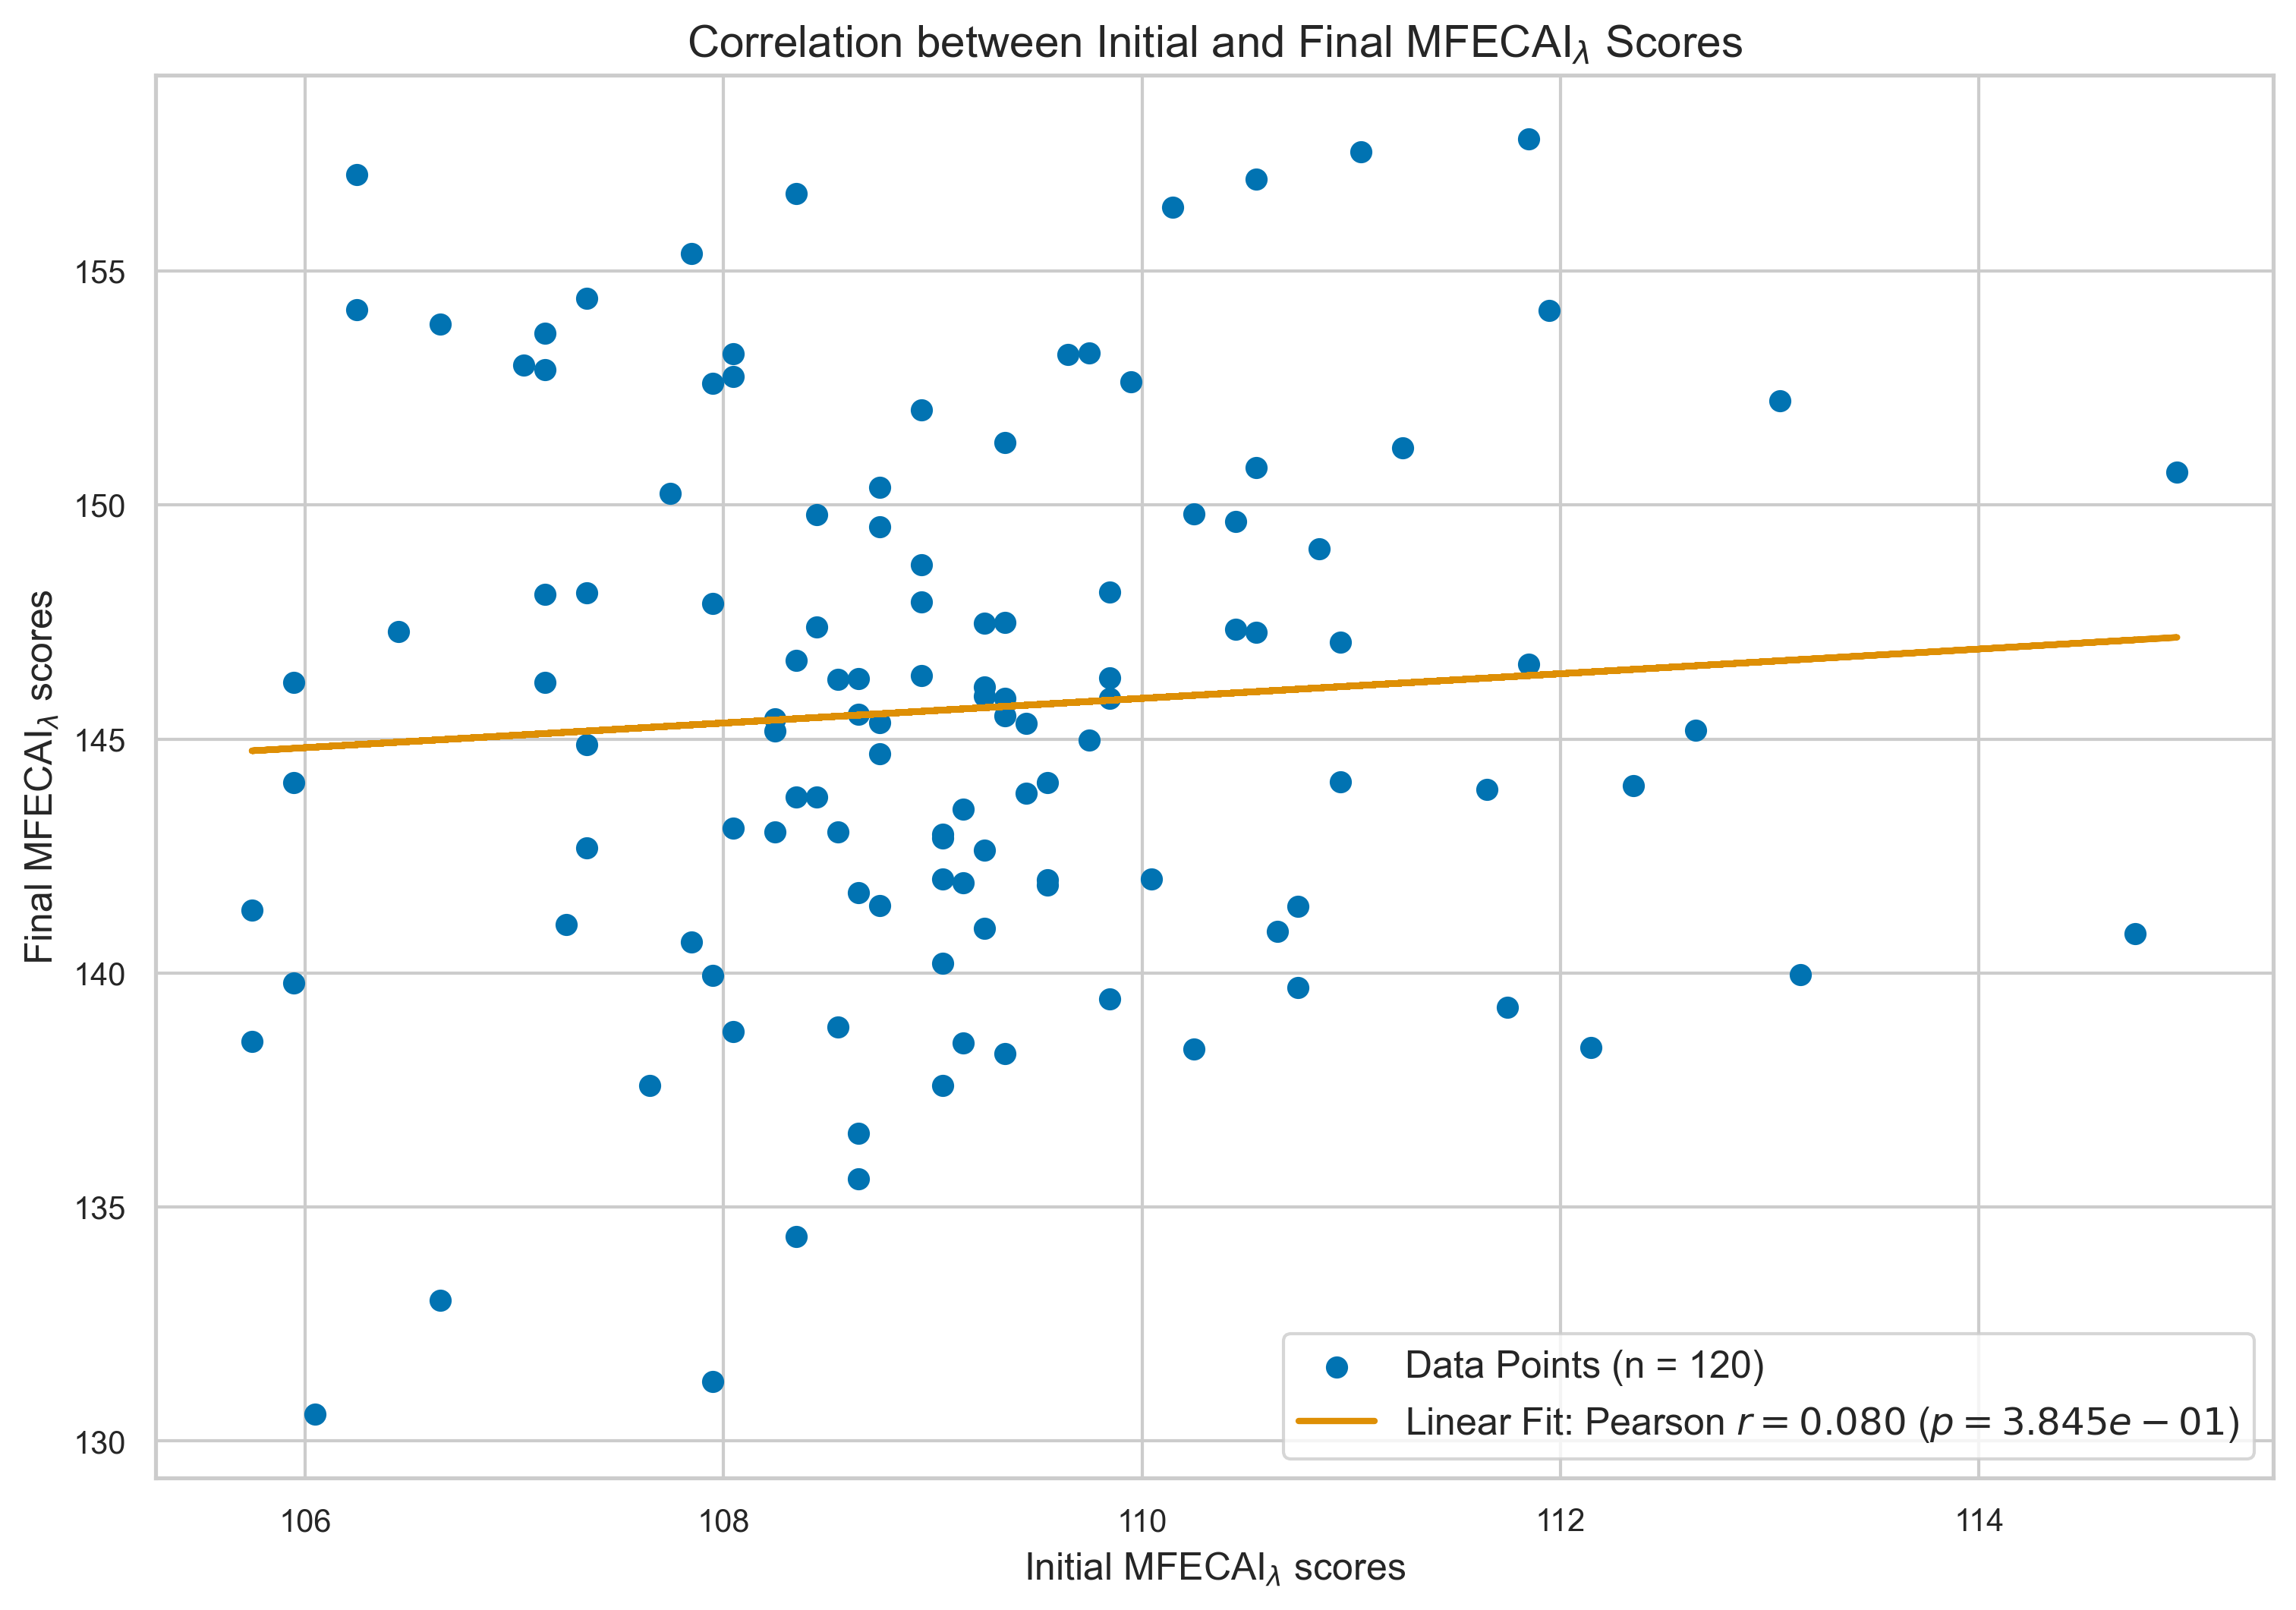

Saved: THe correlation between initial and final states.tiff


In [41]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
import seaborn as sns
import pandas as pd # Import pandas again for clarity
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 12,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})
colors = sns.color_palette("colorblind")

# Extract X (Initial) and Y (Final) scores
x = dflambda4_best['Original MFExCAI score']
y = dflambda4_best['Final MFExCAI score']

# Compute Pearson correlation
r, p_value = pearsonr(x, y)

# Compute the linear regression parameters (slope and intercept)
# The slope and intercept calculation here ensures the line passes through the mean(x), mean(y) point, 
# which is the correct property for a linear regression line.
slope = (y.std() / x.std()) * r
intercept = y.mean() - slope * x.mean()
line = slope * x + intercept

# Plot scatter
fig = plt.figure(figsize=(12, 8))
plt.scatter(x, y, color=colors[0], label='Data Points (n = {})'.format(len(x)))

# Add a best-fit line
plt.plot(x, line, color=colors[1], linewidth=2, 
         label=f'Linear Fit: Pearson $r = {r:.3f}$ ($p = {p_value:.3e}$)')

# Customize plot
plt.title(r'Correlation between Initial and Final MFECAI$_{\lambda}$ Scores')
plt.xlabel(r'Initial MFECAI$_{\lambda}$ scores')
plt.ylabel(r'Final MFECAI$_{\lambda}$ scores')
plt.legend()
plt.grid(True)
plt.show()

save_tiff(fig, 'THe correlation between initial and final states')

Additionally the role of codon weights was studied. The codon weights can determien the solution space based ondifferences of codon frequencies. 

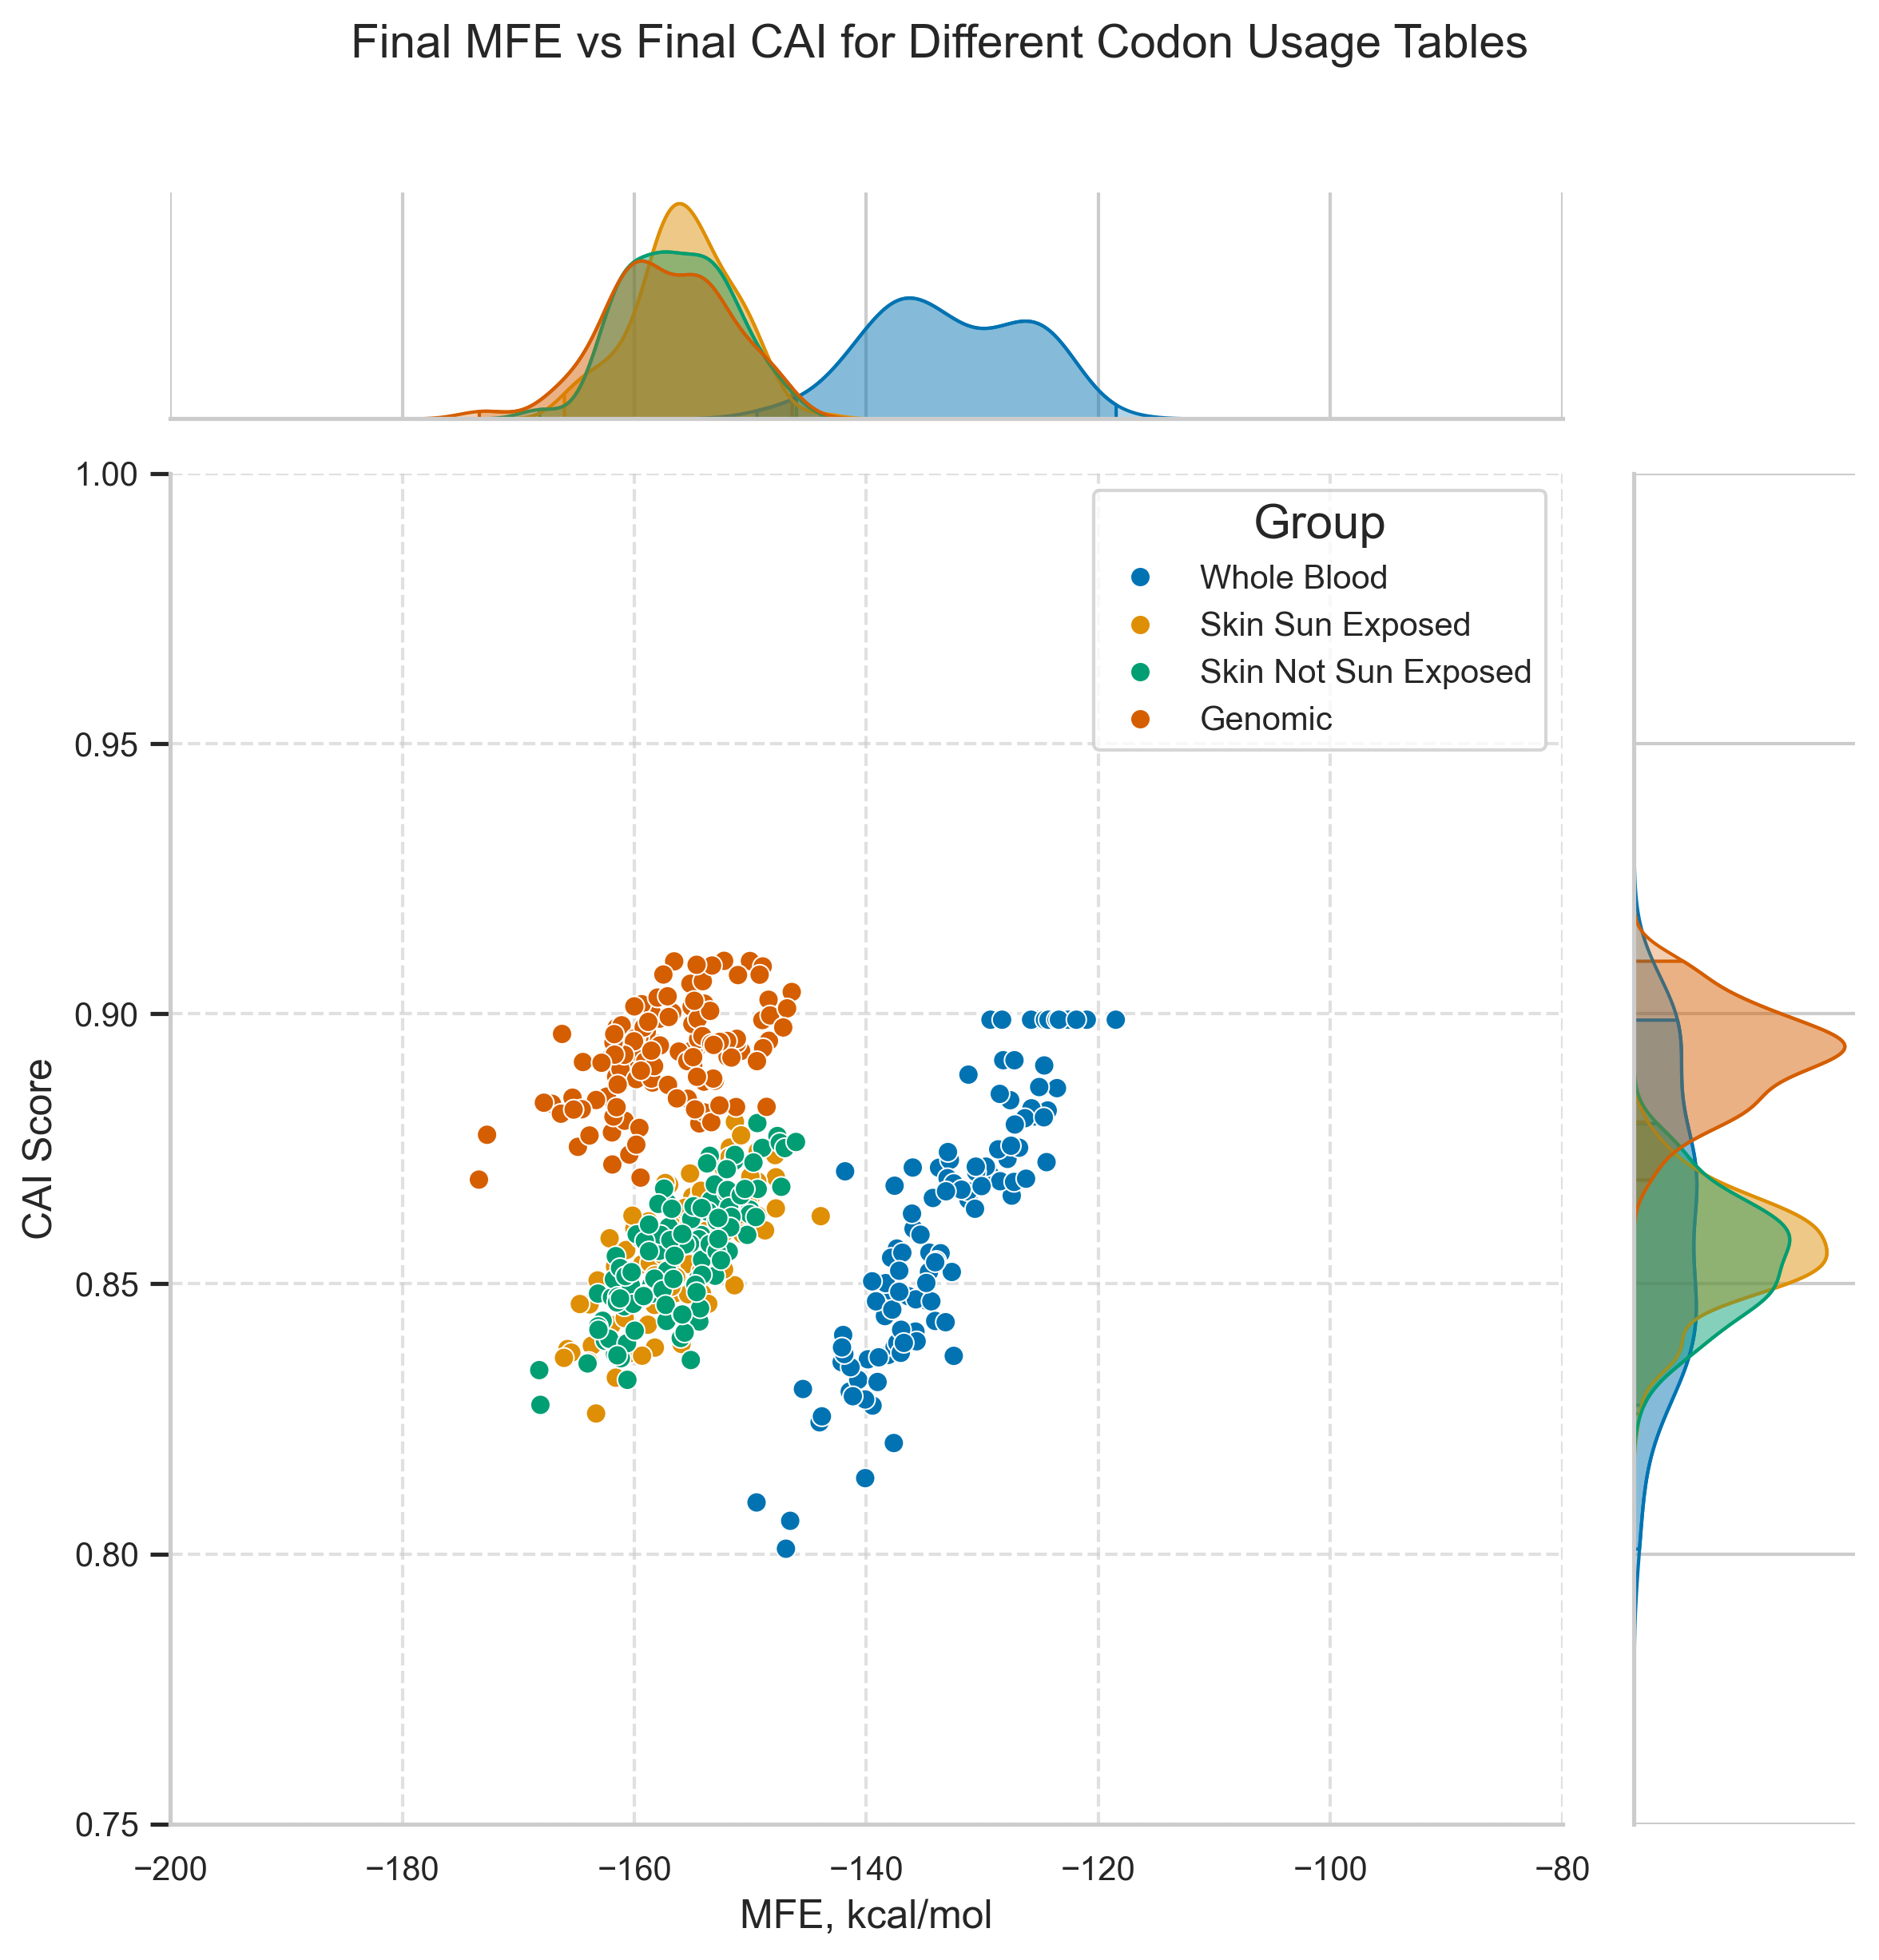

Saved: The influence of codon dicitonary on a final result.tiff


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import os
from typing import List, Dict

# --------------------------------------------------------------------------------------
# GLOBAL PLOTTING CONFIGURATION (Arial Font and Size)
# --------------------------------------------------------------------------------------

# 1. Set font family to Arial
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 

# 2. Set overall theme and scale
sns.set_theme(style="whitegrid", font_scale=1.2) 

# 3. Set specific Matplotlib parameters for font size control
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 12,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})
# Get the full colorblind palette
colors_full = sns.color_palette("colorblind")

# --------------------------------------------------------------------------------------
# 1. DATA LOADING AND GROUPING LOGIC (Assumed available but shown for context)
# --------------------------------------------------------------------------------------

# --- Configuration ---
FOLDER_PATH = 'tissue_results'
TISSUE_KEYWORDS = {
    'Whole Blood': 'whole_blood',
    'Skin Sun Exposed': 'skin_sun_exposed',
    'Skin Not Sun Exposed': 'skin_not_sun_exposed',
    'Genomic': 'genomic'
}
COLUMNS_TO_GROUP = [
    'Original CAI', 'Final CAI', 'Original MFE', 
    'Final MFE', 'Original MFExCAI score', 'Final MFExCAI score'
]

def load_and_group_tissue_data(folder_path: str, keyword: str, grouping_columns: list) -> pd.DataFrame:
    """Loads all CSV files containing a specific keyword from a folder, concatenates, and groups."""
    main_df = pd.DataFrame()
    if not os.path.exists(folder_path): return main_df
    for file in os.listdir(folder_path):
        if file.endswith('.csv') and keyword in file:
            file_path = os.path.join(folder_path, file)
            try:
                df = pd.read_csv(file_path)
                main_df = pd.concat([main_df, df], ignore_index=True)
            except Exception as e:
                print(f"Error reading file {file}: {e}")
                continue
    if main_df.empty: return main_df
    grouped_df = main_df.groupby('Original Sequence')[grouping_columns].mean().reset_index()
    return grouped_df

# --- Execution of Data Loading (Defining required variables) ---
grouped_df_blood = load_and_group_tissue_data(FOLDER_PATH, 'whole_blood', COLUMNS_TO_GROUP)
groupedmaindfsunexposed = load_and_group_tissue_data(FOLDER_PATH, 'skin_sun_exposed', COLUMNS_TO_GROUP)
groupedmaindfnotsunexposed = load_and_group_tissue_data(FOLDER_PATH, 'skin_not_sun_exposed', COLUMNS_TO_GROUP)
groupedmaindfgenomic = load_and_group_tissue_data(FOLDER_PATH, 'genomic', COLUMNS_TO_GROUP)


# --------------------------------------------------------------------------------------
# 2. JOINT PLOT EXECUTION (Warning Fixed)
# --------------------------------------------------------------------------------------

# 2.1 Combine all groups into one DataFrame with a 'Group' column
df_blood = grouped_df_blood.assign(Group="Whole Blood")
df_sunexposed = groupedmaindfsunexposed.assign(Group="Skin Sun Exposed")
df_notsunexposed = groupedmaindfnotsunexposed.assign(Group="Skin Not Sun Exposed")
df_genomic = groupedmaindfgenomic.assign(Group="Genomic")

df_all = pd.concat([df_blood, df_sunexposed, df_notsunexposed, df_genomic], ignore_index=True)

# 2.2 Fix Palette Warning: Slice the palette to exactly match the 4 groups
NUM_GROUPS = len(df_all['Group'].unique())
colors_sliced = colors_full[:NUM_GROUPS]

# Jointplot with scatter + KDE marginals
g = sns.jointplot(
    data=df_all,
    x="Final MFE",
    y="Final CAI",
    hue="Group",
    palette=colors_sliced, 
    kind="scatter",
    height=8,
    marginal_kws=dict(fill=True, common_norm=False, cut=0) 
)

# 2.3 Add smooth KDE curves for the marginals (FIXED WARNING)
for group, color in zip(df_all['Group'].unique(), colors_sliced):
    # Horizontal marginal (X-axis)
    sns.kdeplot(x=df_all[df_all['Group'] == group]['Final MFE'],
                ax=g.ax_marg_x, color=color, fill=True, alpha=0.3)
    # Vertical marginal (Y-axis): Data assigned to 'y' to resolve deprecation warning
    sns.kdeplot(y=df_all[df_all['Group'] == group]['Final CAI'], 
                ax=g.ax_marg_y, color=color, fill=True, alpha=0.3)

# 2.4 Customize axes and title
g.set_axis_labels("MFE, kcal/mol", "CAI Score")

# Set fixed axis ranges
g.ax_joint.set_xlim(-200, -80)
g.ax_joint.set_ylim(0.75, 1.0)

# Y-axis ticks configuration
g.ax_joint.yaxis.tick_left()
g.ax_joint.yaxis.set_label_position("left")
g.ax_joint.grid(True, linestyle='--', alpha=0.6)

# Add main title to the entire figure
g.fig.suptitle("Final MFE vs Final CAI for Different Codon Usage Tables", y=1.02, fontsize=plt.rcParams['axes.titlesize'])
g.fig.tight_layout()
plt.show()

save_tiff(g, 'The influence of codon dicitonary on a final result')

The time dependence study was performed. The optimization time increases exponentially with peptide length. ViennaRNA consumes the most of computation time.

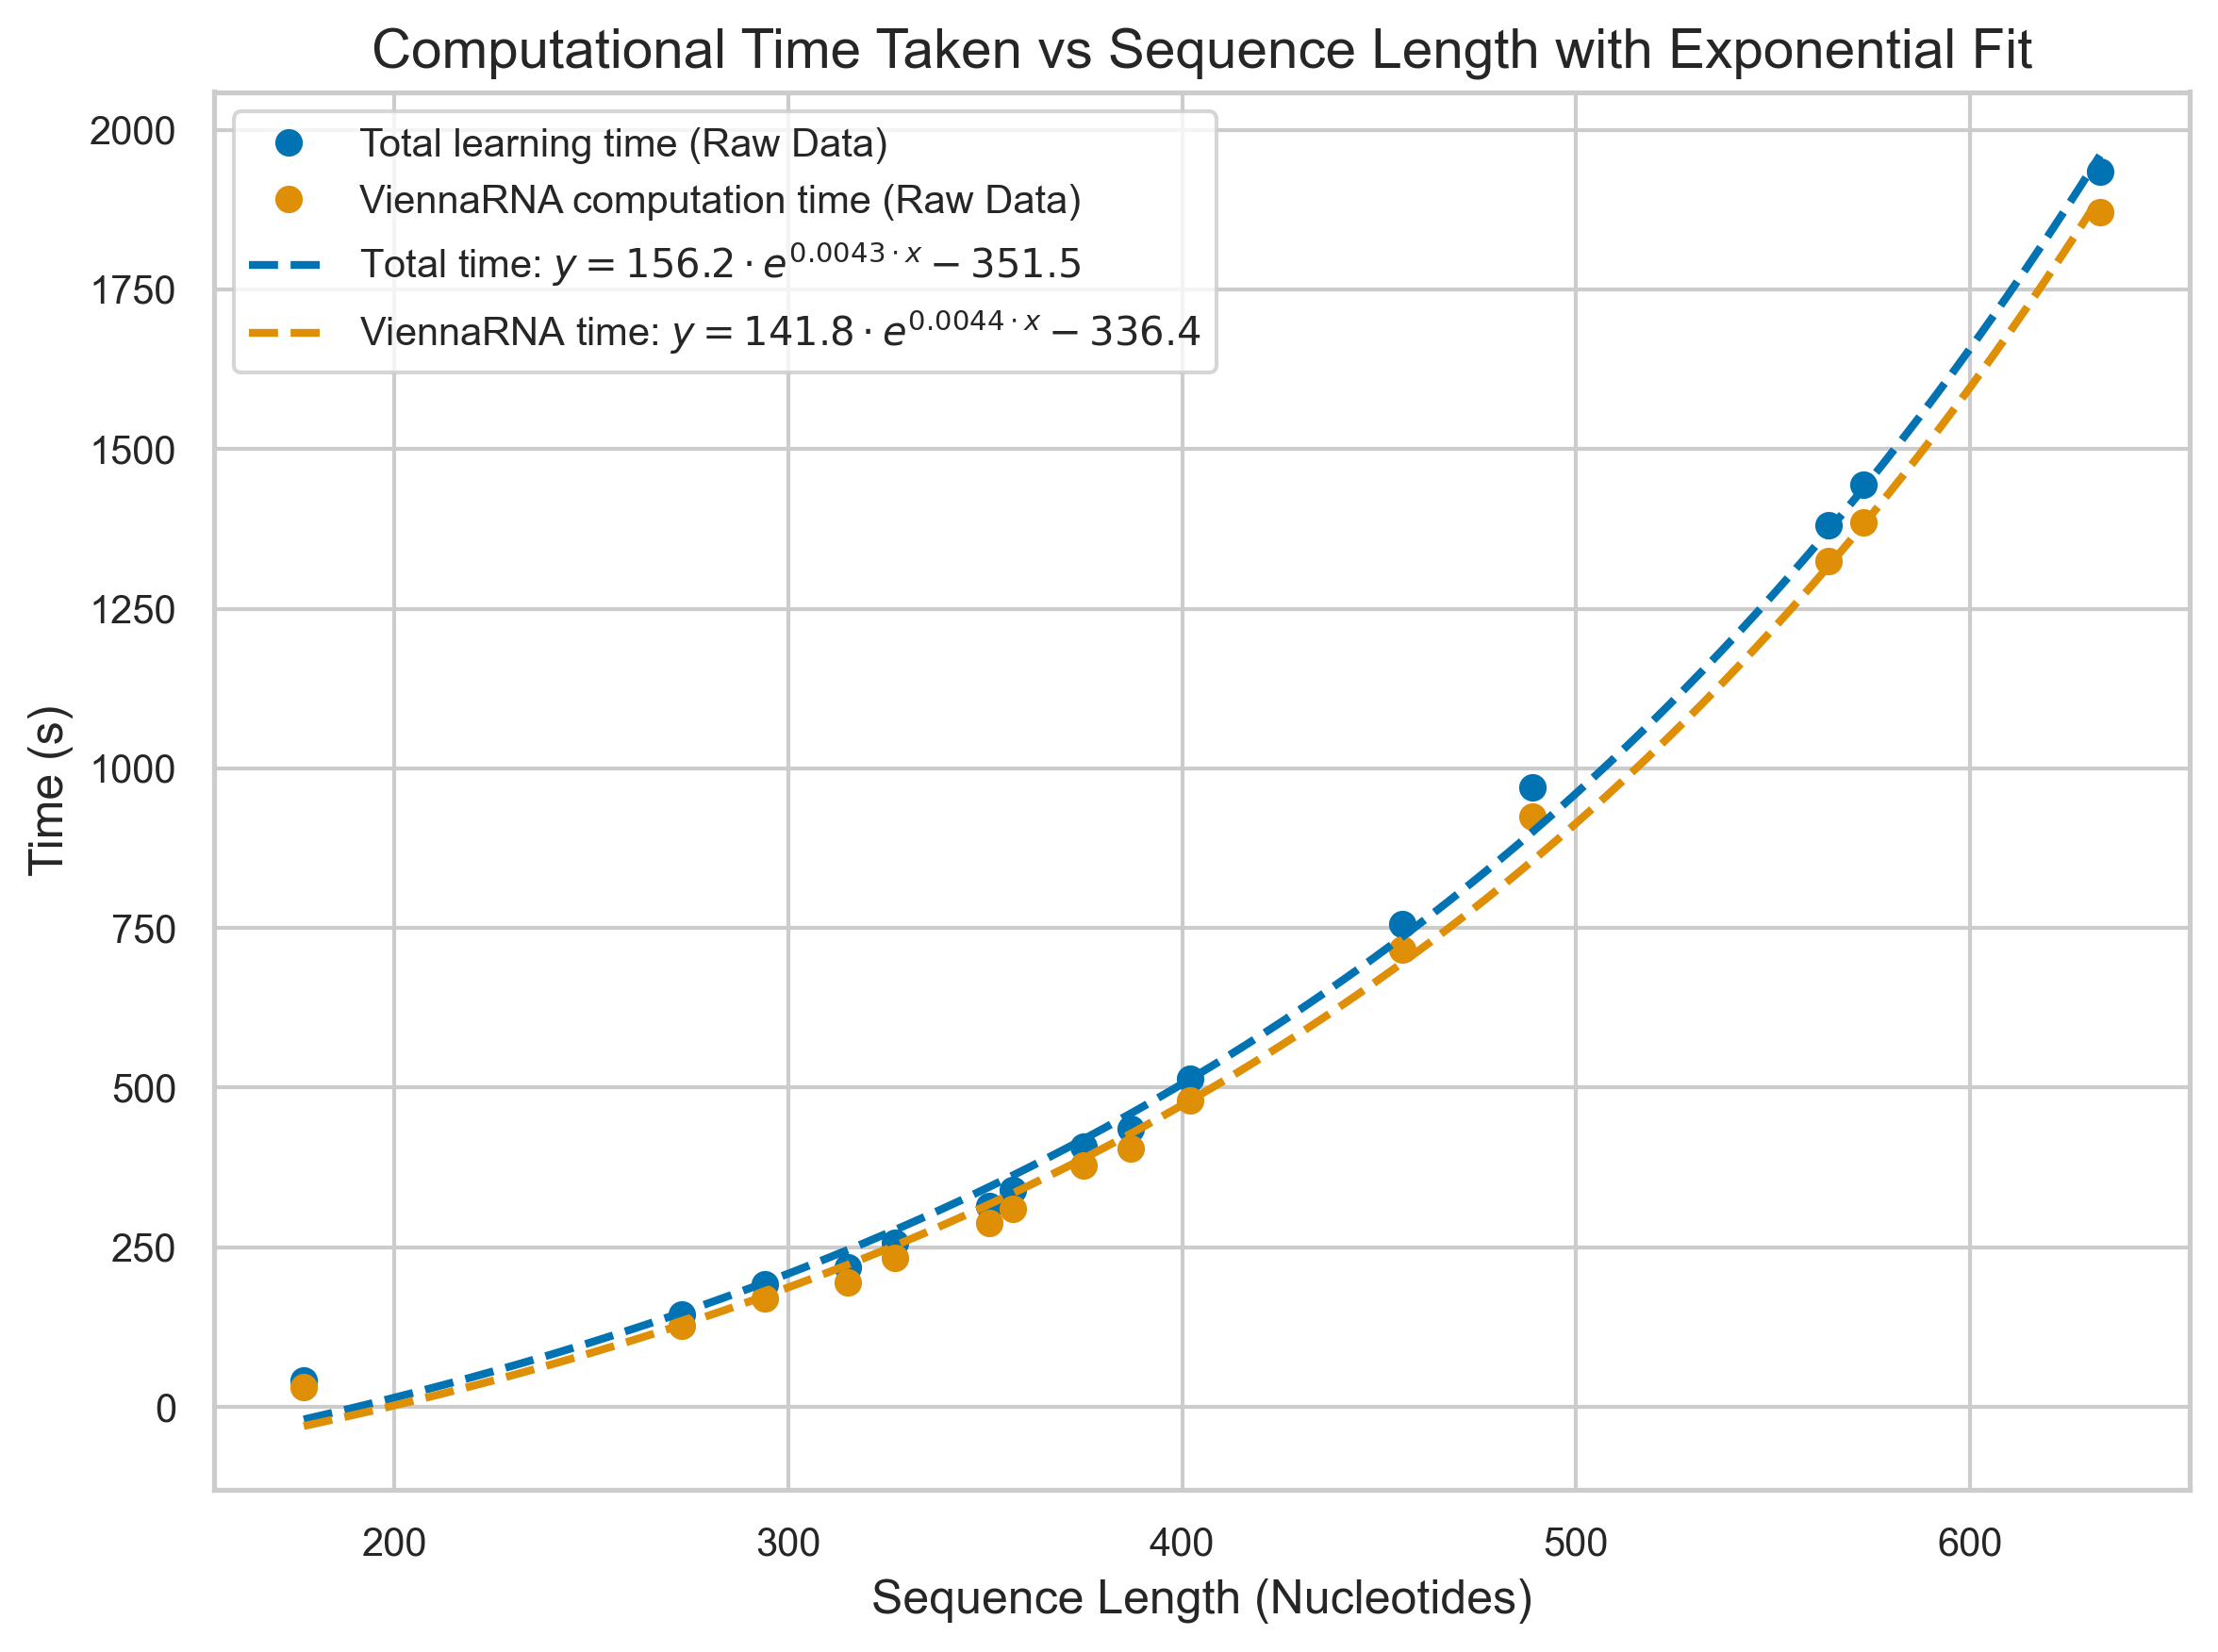

Saved: Time dependency and bottleneck in viennarna.tiff


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import os
import math
import matplotlib as mpl

# --------------------------------------------------------------------------------------
# GLOBAL PLOTTING CONFIGURATION 
# --------------------------------------------------------------------------------------

# Set font family to Arial (or fallback)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 10,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

# --------------------------------------------------------------------------------------
# 1. DATA LOADING, GROUPING, AND LENGTH CALCULATION
# --------------------------------------------------------------------------------------

folderpath = 'time_experiments'
maindf = pd.DataFrame()

# Load and concatenate all data
if os.path.exists(folderpath):
    for file in os.listdir(folderpath):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folderpath, file))
            maindf = pd.concat([maindf, df], ignore_index=True)
else:
    print(f"Warning: Folder '{folderpath}' not found. Using placeholder data for execution.")
    # --- Placeholder data generation for execution ---
    np.random.seed(42)
    x_data_list = [100, 200, 300, 400, 500, 600, 700]
    maindf = pd.DataFrame({
        'Original Sequence': [f'SEQ{i}' for i in x_data_list],
        'Time Taken (s)': (1.2 * 5e-5 * np.array(x_data_list)**2 + np.random.normal(0, 0.5, len(x_data_list))),
        'Time for calculating MFE (s)': (5e-5 * np.array(x_data_list)**2 + np.random.normal(0, 0.5, len(x_data_list)))
    })
    maindf[['Time Taken (s)', 'Time for calculating MFE (s)']] = maindf[['Time Taken (s)', 'Time for calculating MFE (s)']].clip(lower=0.1)

# Group by sequence and average times
grouped_df = maindf.groupby('Original Sequence')[['Time Taken (s)', 'Time for calculating MFE (s)']].mean().reset_index()

# Calculate Sequence Length
def calculate_len(sequence):
    return len(sequence)
grouped_df['Sequence Length'] = grouped_df['Original Sequence'].apply(calculate_len)

# --------------------------------------------------------------------------------------
# 2. MODEL FITTING AND CURVE GENERATION (3-Parameter Exponential)
# --------------------------------------------------------------------------------------

# Define the exponential function (3 parameters)
def exponential_func(x, a, b, c):
    return a * np.exp(b * x) + c

x_data = grouped_df['Sequence Length']
y_data = grouped_df['Time Taken (s)']
y_viennarna_data = grouped_df['Time for calculating MFE (s)']

# Initial guess for fitting (a, b, c)
p0_guess = [10, 1e-5, 1] 

# Fit Total Time
params, covariance = curve_fit(exponential_func, x_data, y_data, p0=p0_guess)
# Fit ViennaRNA Time
params_viennarna, covariance_viennarna = curve_fit(exponential_func, x_data, y_viennarna_data, p0=p0_guess)

a, b, c = params
d, e, f = params_viennarna

# Generate smooth fit curves
x_fit = np.linspace(min(x_data), max(x_data), 100)
y_fit = exponential_func(x_fit, *params)
y_fit_viennarna = exponential_func(x_fit, *params_viennarna)

# Generate LaTeX equation strings (using sign-aware format for the constant c and f)
equation_text = fr"$y = {a:.1f} \cdot e^{{{b:.4f} \cdot x}} {c:+.1f}$"
equation_viennarna_text = fr"$y = {d:.1f} \cdot e^{{{e:.4f} \cdot x}} {f:+.1f}$"

# --------------------------------------------------------------------------------------
# 3. PLOTTING (Using the 3-Parameter Fit Results)
# --------------------------------------------------------------------------------------

colors = sns.color_palette("colorblind")

fig = plt.figure(figsize=(8, 6))

# Plot raw data (scatter points)
plt.plot(x_data, y_data, 'o', color=colors[0], alpha=1, label='Total learning time (Raw Data)')
plt.plot(x_data, y_viennarna_data, 'o', color=colors[1], alpha=1, label='ViennaRNA computation time (Raw Data)')

# Plot fitted curves (using the smooth x_fit array and the 3-parameter equation)
plt.plot(x_fit, y_fit, '--', color=colors[0], linewidth=2, label=f'Total time: {equation_text}')
plt.plot(x_fit, y_fit_viennarna, '--', color=colors[1], linewidth=2, label=f'ViennaRNA time: {equation_viennarna_text}')

# Labels and formatting
plt.xlabel('Sequence Length (Nucleotides)')
plt.ylabel('Time (s)')
plt.title('Computational Time Taken vs Sequence Length with Exponential Fit')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

save_tiff(fig, 'Time dependency and bottleneck in viennarna')

C:\Users\admin\AppData\Local\Temp\ipykernel_32284\876059849.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\admin\AppData\Local\Temp\ipykernel_32284\876059849.py:80: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()


R² = 1.0000


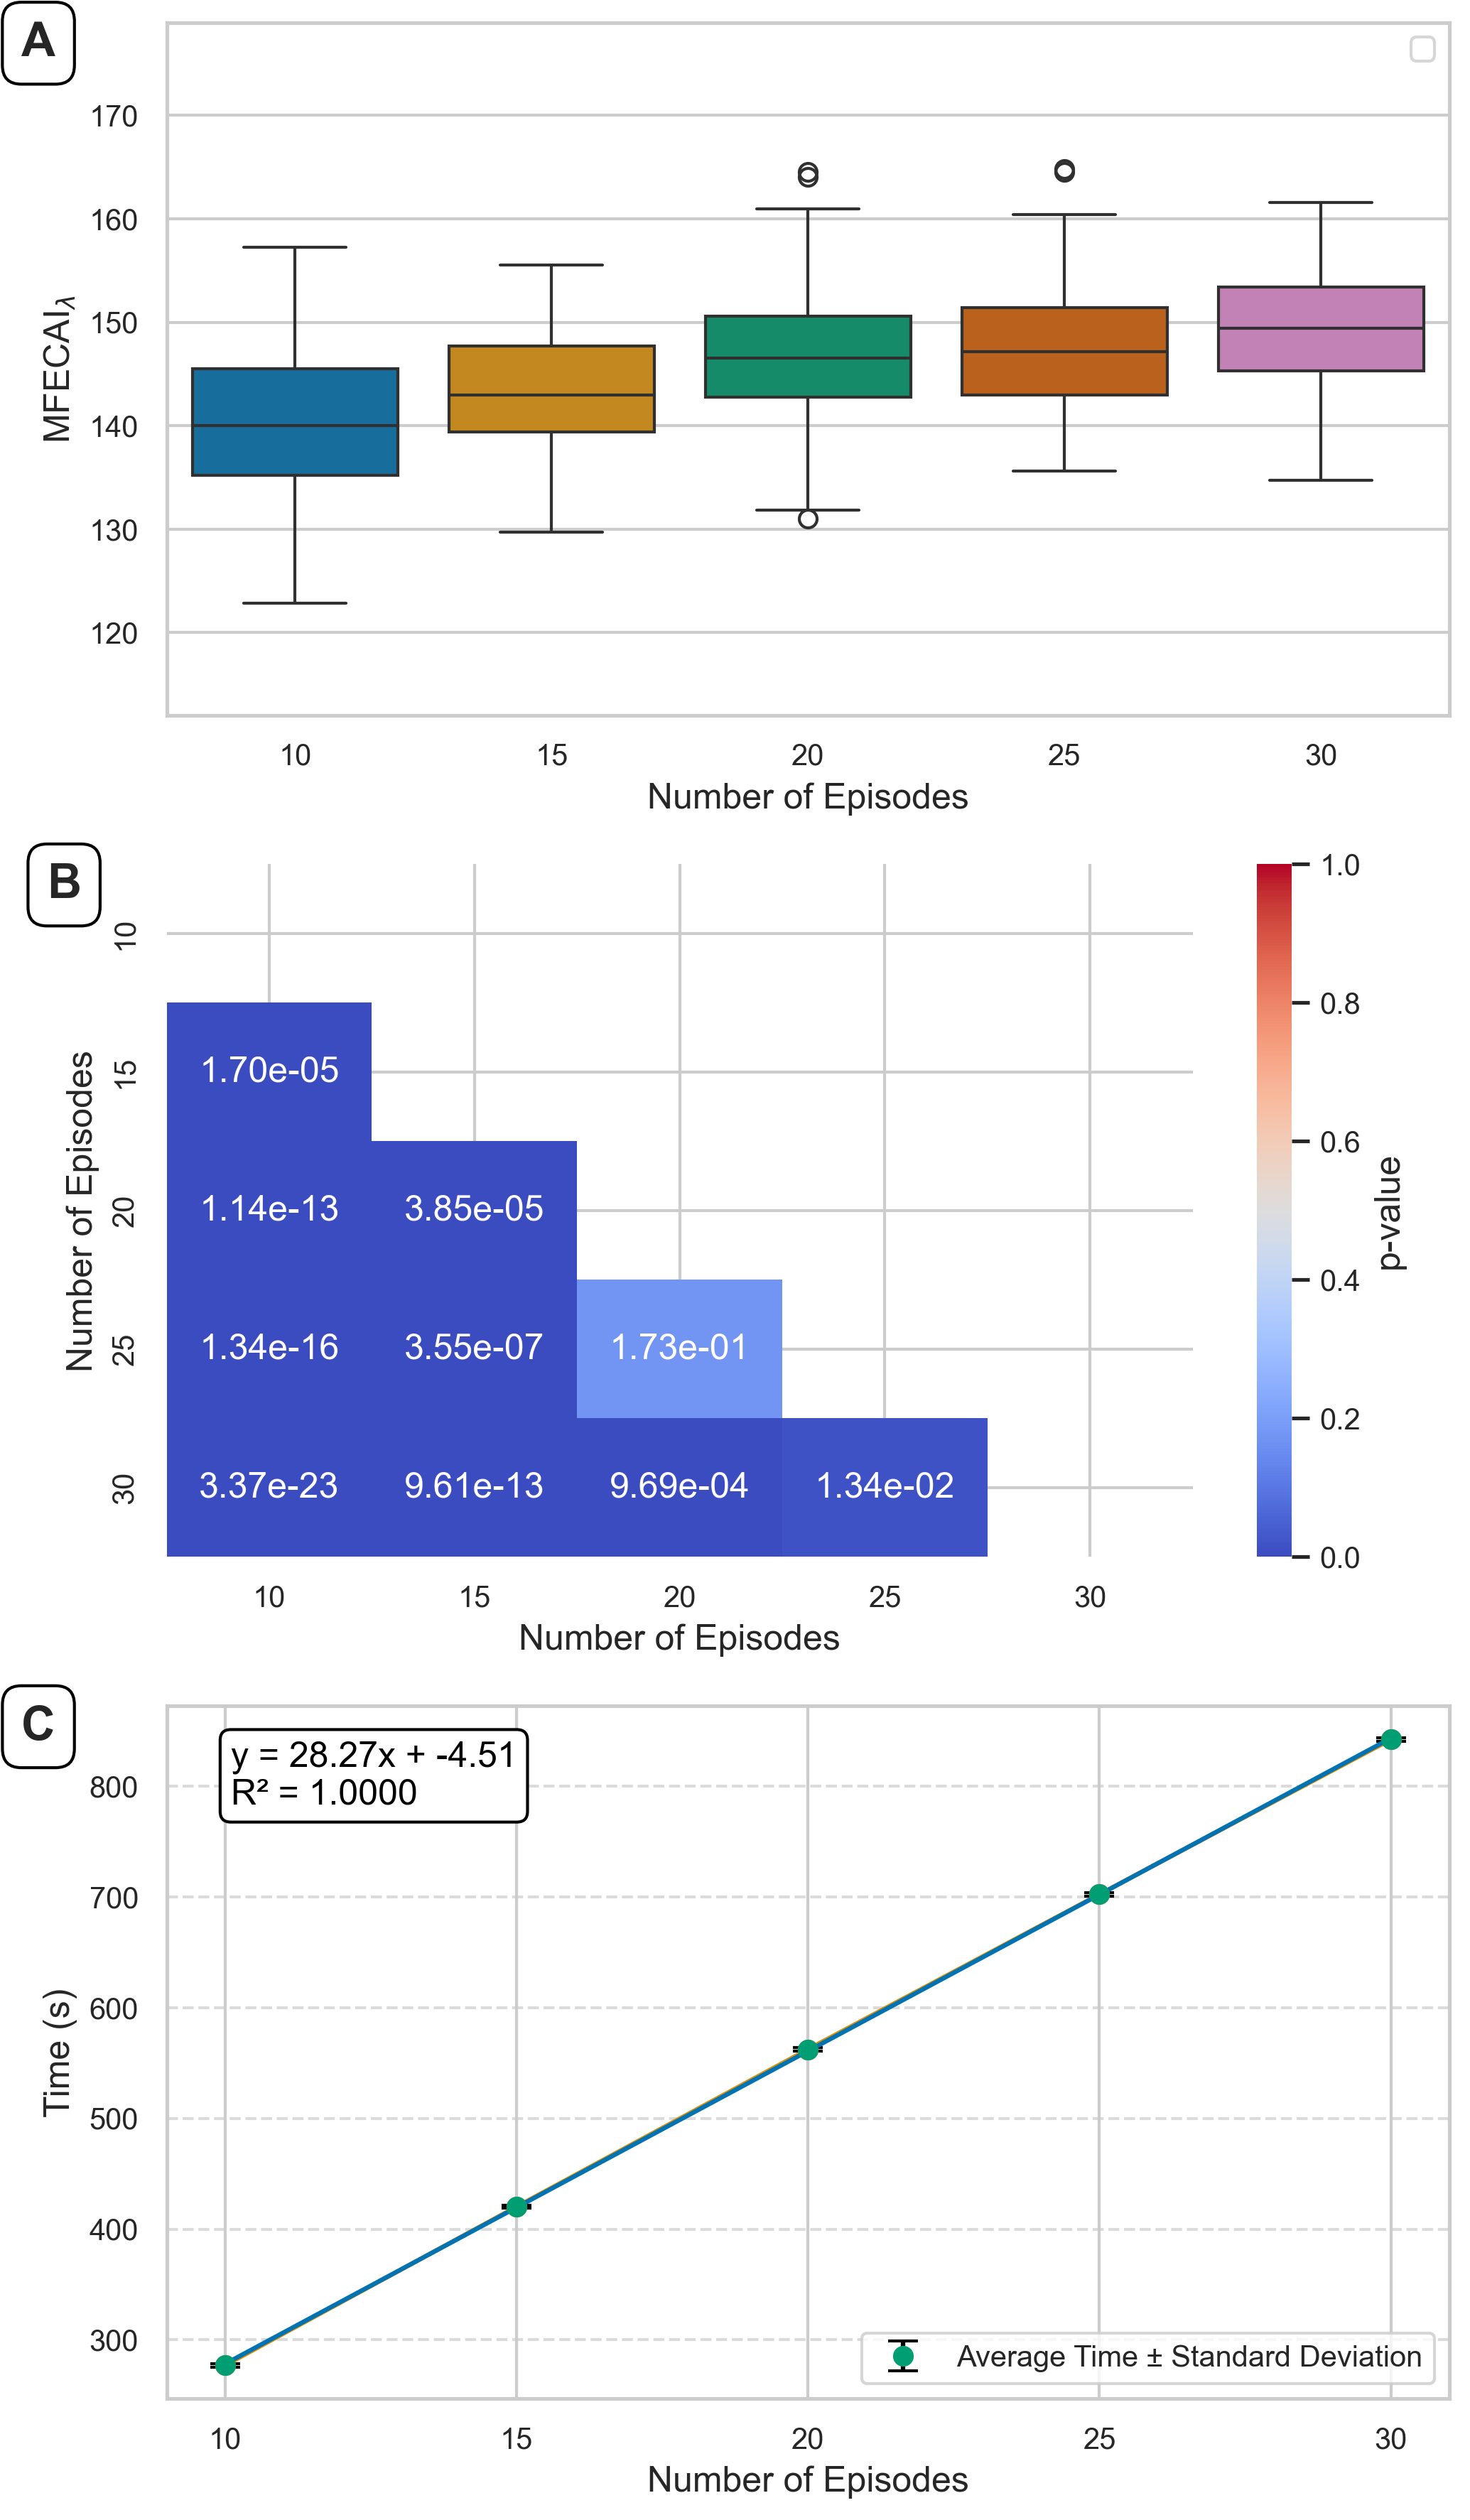

Saved: Testing the most optimal numebr of episodes.tiff


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from scipy.stats import f_oneway
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.ticker as ticker
colors = sns.color_palette("colorblind")

# Set font family to Arial (or fallback)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 10,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

# Load data for different episode counts
folder_path = 'episodes_convergence_tests_no_stop'
episode_files = {
    10: 'results_for_run_dated_2025-07-15_11-56_episodes_10.csv',
    15: 'results_for_run_dated_2025-07-15_12-10_episodes_15.csv',
    20: 'results_for_run_dated_2025-07-15_12-29_episodes_20.csv',
    25: 'results_for_run_dated_2025-07-15_12-53_episodes_25.csv',
    30: 'results_for_run_dated_2025-07-15_13-22_episodes_30.csv'
}

dfs = {ep: pd.read_csv(f"{folder_path}/{filename}") for ep, filename in episode_files.items()}

time_data = [dfs[ep]['Time Taken (s)'] for ep in sorted(episode_files.keys())]

labels = [str(ep) for ep in sorted(episode_files.keys())]

def correct_max(data, max_value):
    return [max_value if x == 0 else x for x in data]

# Compute summary stats
mfecai_means = []
mfecai_stds = []
cai_means = []
mfe_means = []
time_means = []
time_stds = []

for ep in episode_files.keys():
    df = dfs[ep]
    mfecai_means.append(df['Final MFExCAI score'].mean())
    mfecai_stds.append(df['Final MFExCAI score'].std())
    cai_means.append(df['Final CAI'].mean())
    mfe_means.append(df['Final MFE'].mean())
    time_means.append(df['Time Taken (s)'].mean())
    time_stds.append(df['Time Taken (s)'].std())

episodes = list(episode_files.keys())

# -------------------

fig, axes = plt.subplots(3, 1, figsize=(7, 12))
# Plot 1: Bar plot MFECAI with Stddev
sns.boxplot(
    x=np.repeat(episodes, [len(dfs[ep]) for ep in episodes]),
    y=np.concatenate([dfs[ep]['Final MFExCAI score'].values for ep in episodes]),
    ax=axes[0],
    palette=sns.color_palette("colorblind", len(episodes))
)
#axes[0].bar(episodes, mfecai_means, yerr=mfecai_stds, capsize=5, color=colors[0], width=2,
 #           label='MFECAIλ = |MFE - λ * L * log10(CAI)|')
axes[0].set_xlabel('Number of Episodes')
axes[0].set_ylabel('MFECAI$_{\lambda}$')
axes[0].set_ylim(min(mfecai_means) * 0.8, max(mfecai_means) * 1.2)
axes[0].legend()
axes[0].text(-0.1, 0.97, 'A', transform=axes[0].transAxes, fontsize=16, fontweight='bold',
             ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='black'))

# -------------------
# -------------------
# Plot (b): Time per Episode with Stddev
# Linear fit
coef = np.polyfit(episodes, time_means, 1)
poly1d_fn = np.poly1d(coef)
x_fit = np.linspace(min(episodes), max(episodes), 100)
y_fit = poly1d_fn(x_fit)
y_pred = poly1d_fn(episodes)
r2 = r2_score(time_means, y_pred)
print(f"R² = {r2:.4f}")

axes[2].errorbar(episodes, time_means, yerr=time_stds, fmt='o', color=colors[2],
                 ecolor='black', elinewidth=1.5, capsize=5, label="Average Time ± Standard Deviation")
axes[2].plot(episodes, time_means, marker='o', linestyle='-', color=colors[1])
axes[2].plot(x_fit, y_fit, color=colors[0])
eq_text = f"y = {coef[0]:.2f}x + {coef[1]:.2f}\nR² = {r2:.4f}"
axes[2].text(0.05, 0.95, eq_text, transform=axes[2].transAxes,
             fontsize=12, color="black", ha="left", va="top",
             bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3"))
axes[2].set_xlabel('Number of Episodes')
axes[2].set_ylabel('Time (s)')
axes[2].grid(axis='y', linestyle='--', alpha=0.7)
axes[2].set_xticks(episodes)
axes[2].legend()
axes[2].text(-0.1, 0.97, 'C', transform=axes[2].transAxes, fontsize=16, fontweight='bold',
             ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='black'))

# --- Plot C: Heatmap for paired t-test
lists = [dfs[ep]['Final MFExCAI score'] for ep in episodes]
n = len(lists)
p_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        if i == j:
            p_matrix[i, j] = np.nan
        else:
            t_stat, p_two = ttest_ind(lists[i], lists[j], equal_var=True)
            if t_stat > 0:
                p_one = p_two / 2
            else:
                p_one = 1 - (p_two / 2)
            p_matrix[i, j] = p_one

mask = np.triu(np.ones_like(p_matrix, dtype=bool))

sns.heatmap(
    p_matrix,
    annot=True, fmt=".2e",
    cmap="coolwarm",
    vmin=0, vmax=1,   # <<< manually set temperature (color scale 0–1)
    xticklabels=labels, yticklabels=labels,
    mask=mask,
    ax=axes[1],
    cbar_kws={'label': 'p-value'}
)
#axes[2].set_title("Paired t-test matrix for Final MFExCAI scores")
axes[1].text(-0.1, 0.97, 'B', transform=axes[1].transAxes,
             fontsize=16, fontweight='bold', ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='black'))
axes[1].set_xlabel('Number of Episodes')
axes[1].set_ylabel('Number of Episodes')
plt.tight_layout()
plt.show()

anova_result = f_oneway(*lists) 

save_tiff(fig, 'Testing the most optimal numebr of episodes')

C:\Users\admin\AppData\Local\Temp\ipykernel_32284\2084046320.py:109: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


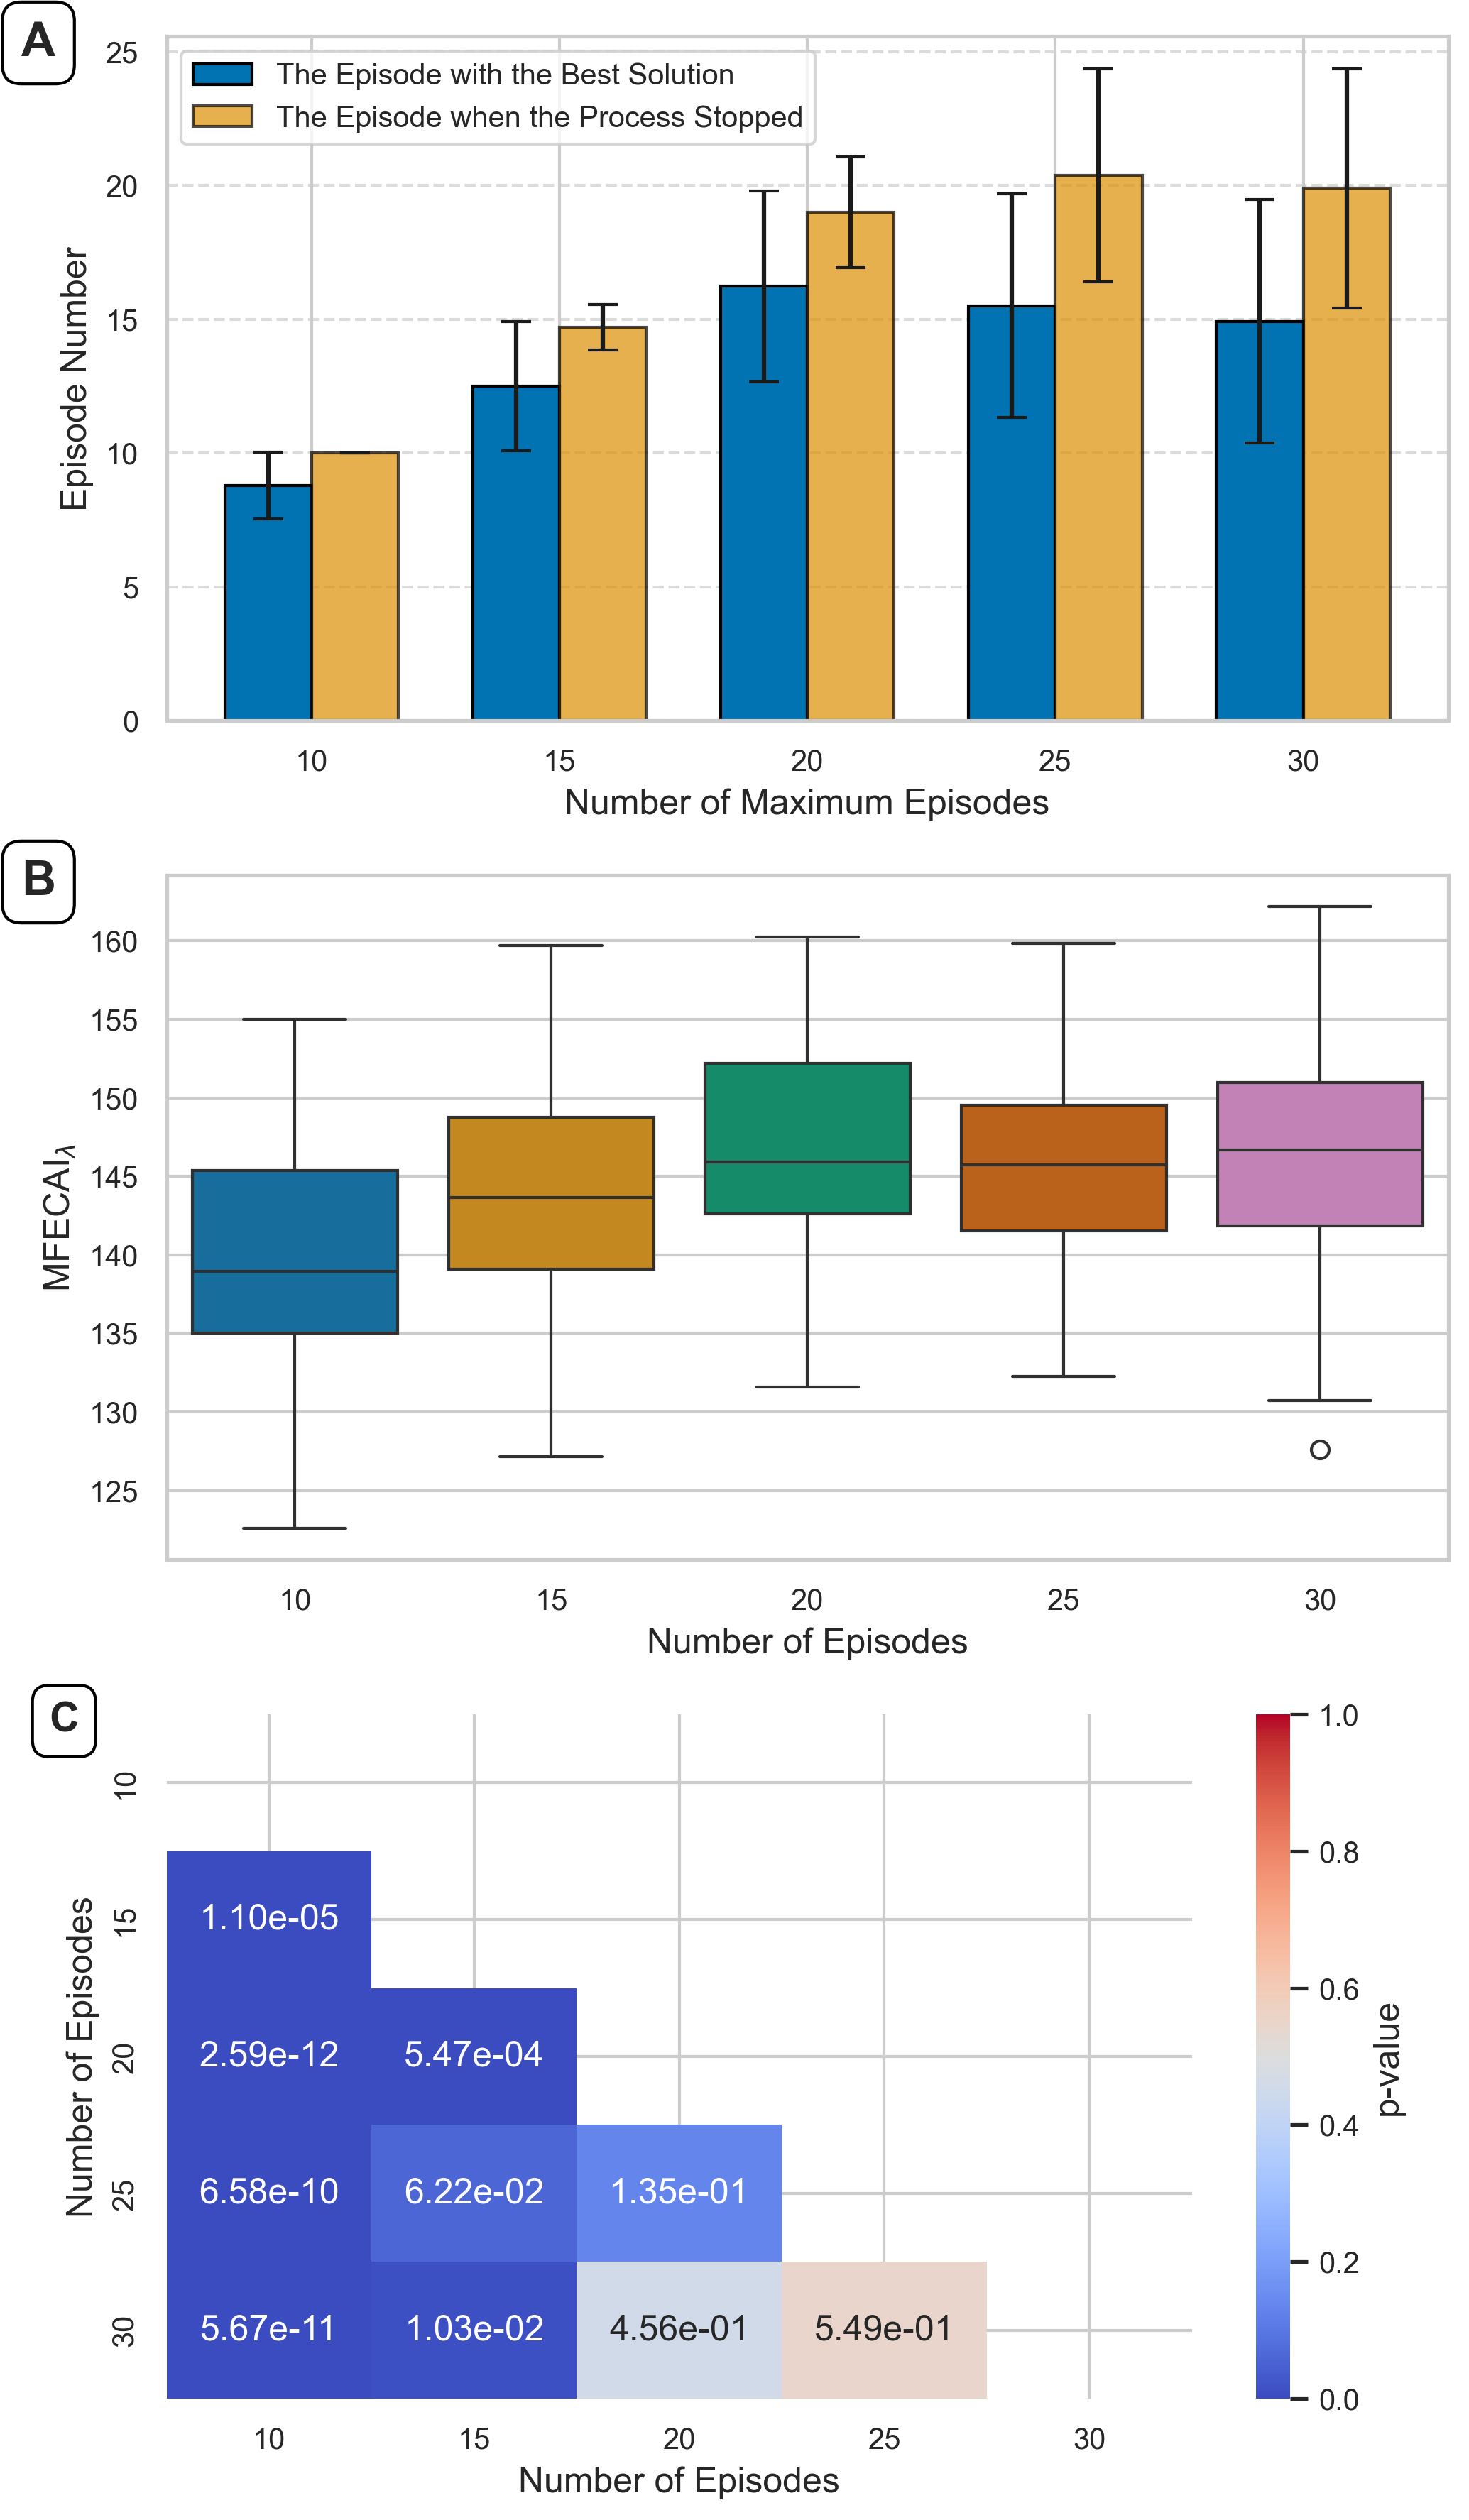

Saved: Testing the most optimal number of episodes part 2.tiff


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
cb_colors = sns.color_palette("colorblind")

# Set font family to Arial (or fallback)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 10,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})


folder_path = "episodes_convergence_tests_with_stop"
episode_files = {
    10: 'results_for_run_dated_2025-07-16_11-51_episodes_10.csv',
    15: 'results_for_run_dated_2025-07-16_12-05_episodes_15.csv',
    20: 'results_for_run_dated_2025-07-16_12-23_episodes_20.csv',
    25: 'results_for_run_dated_2025-07-16_12-44_episodes_25.csv',
    30: 'results_for_run_dated_2025-07-16_13-05_episodes_30.csv'
}

dfs = {ep: pd.read_csv(f"{folder_path}/{filename}") for ep, filename in episode_files.items()}

time_data = [dfs[ep]['Time Taken (s)'] for ep in sorted(episode_files.keys())]

labels = [str(ep) for ep in sorted(episode_files.keys())]

def correct_max(data, max_value):
    return [max_value if x == 0 else x for x in data]

# Load dataframes and prepare series
dfs = {}
average_episodes = {}
last_episodes = {}

for ep, fname in episode_files.items():
    df = pd.read_csv(f'{folder_path}/{fname}')
    dfs[ep] = df
    average_episodes[ep] = df['Episode with solution']
    last_episodes[ep] = pd.Series(correct_max(df['Last episode'], ep))

# Compute summary stats
mfecai_means = []
mfecai_stds = []
cai_means = []
mfe_means = []
time_means = []
time_stds = []

for ep in episode_files.keys():
    df = dfs[ep]
    mfecai_means.append(df['Final MFExCAI score'].mean())
    mfecai_stds.append(df['Final MFExCAI score'].std())
    cai_means.append(df['Final CAI'].mean())
    mfe_means.append(df['Final MFE'].mean())
    time_means.append(df['Time Taken (s)'].mean())
    time_stds.append(df['Time Taken (s)'].std())

episodes = list(episode_files.keys())

# -------------------
# Plot: Bar plot Episode with Solution vs Last Episode
means_sol = [average_episodes[ep].mean() for ep in episodes]
std_sol = [average_episodes[ep].std() for ep in episodes]
means_last = [last_episodes[ep].mean() for ep in episodes]
std_last = [last_episodes[ep].std() for ep in episodes]

labels = [str(ep) for ep in episodes]
x = np.arange(len(labels))
width = 0.35

# Create subplots
fig, axes = plt.subplots(3, 1, figsize=(7, 12))

# -------------------
# Plot (a): Episode with Solution vs Last Episode
# --- Plot A: Episode with Solution vs Last Episode
axes[0].bar(x - width/2, means_sol, yerr=std_sol, capsize=5, width=width,
            color=cb_colors[0], edgecolor='black', label='The Episode with the Best Solution')
axes[0].bar(x + width/2, means_last, yerr=std_last, capsize=5, width=width,
            color=cb_colors[1], edgecolor='black', alpha=0.7, label='The Episode when the Process Stopped')
axes[0].set_xlabel('Number of Maximum Episodes')
axes[0].set_ylabel('Episode Number')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0].text(-0.1, 0.99, 'A', transform=axes[0].transAxes, fontsize=16, fontweight='bold',
             ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='black'))

# --- Plot B: Box plot for MFECAI (replace previous barplot)
mfecai_data = []
mfecai_labels = []

for ep in episodes:
    mfecai_data.extend(dfs[ep]['Final MFExCAI score'])
    mfecai_labels.extend([ep] * len(dfs[ep]))

sns.boxplot(
    x=mfecai_labels,
    y=mfecai_data,
    ax=axes[1],
    palette=sns.color_palette("colorblind", len(episodes))
)
axes[1].set_xlabel('Number of Episodes')
axes[1].set_ylabel('MFECAI$_{\lambda}$')
#axes[1].set_title('Distribution of Final MFECAIλ scores')
axes[1].text(-0.1, 0.99, 'B', transform=axes[1].transAxes, fontsize=16, fontweight='bold',
             ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='black'))

# --- Plot C: Heatmap of paired t-tests
lists = [dfs[ep]['Final MFExCAI score'] for ep in episodes]
n = len(lists)
p_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i == j:
            p_matrix[i, j] = np.nan
        else:
            _, p = ttest_rel(lists[i], lists[j])
            p_matrix[i, j] = p

mask = np.triu(np.ones_like(p_matrix, dtype=bool))

sns.heatmap(
    p_matrix,
    annot=True, fmt=".2e",
    cmap="coolwarm",
    vmin=0, vmax=1,  # set manual "temperature"
    xticklabels=labels,
    yticklabels=labels,
    mask=mask,
    ax=axes[2],
    cbar_kws={'label': 'p-value'}
)
#axes[2].set_title("Paired t-test matrix for Final MFExCAI scores")
axes[2].text(-0.1, 0.99, 'C', transform=axes[2].transAxes, fontsize=14, fontweight='bold',
             ha='center', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='black'))
axes[2].set_xlabel('Number of Episodes')
axes[2].set_ylabel('Number of Episodes')
plt.tight_layout()
plt.show()

save_tiff(fig, 'Testing the most optimal number of episodes part 2')

The experimental study of mRNA stability in Jurkat cells revealed the imrpovements in half-lifes

y(x) = 2.0013 * exp(-0.3460 * x) + -0.0003
Half-life (b1_2): 2.0031 hours


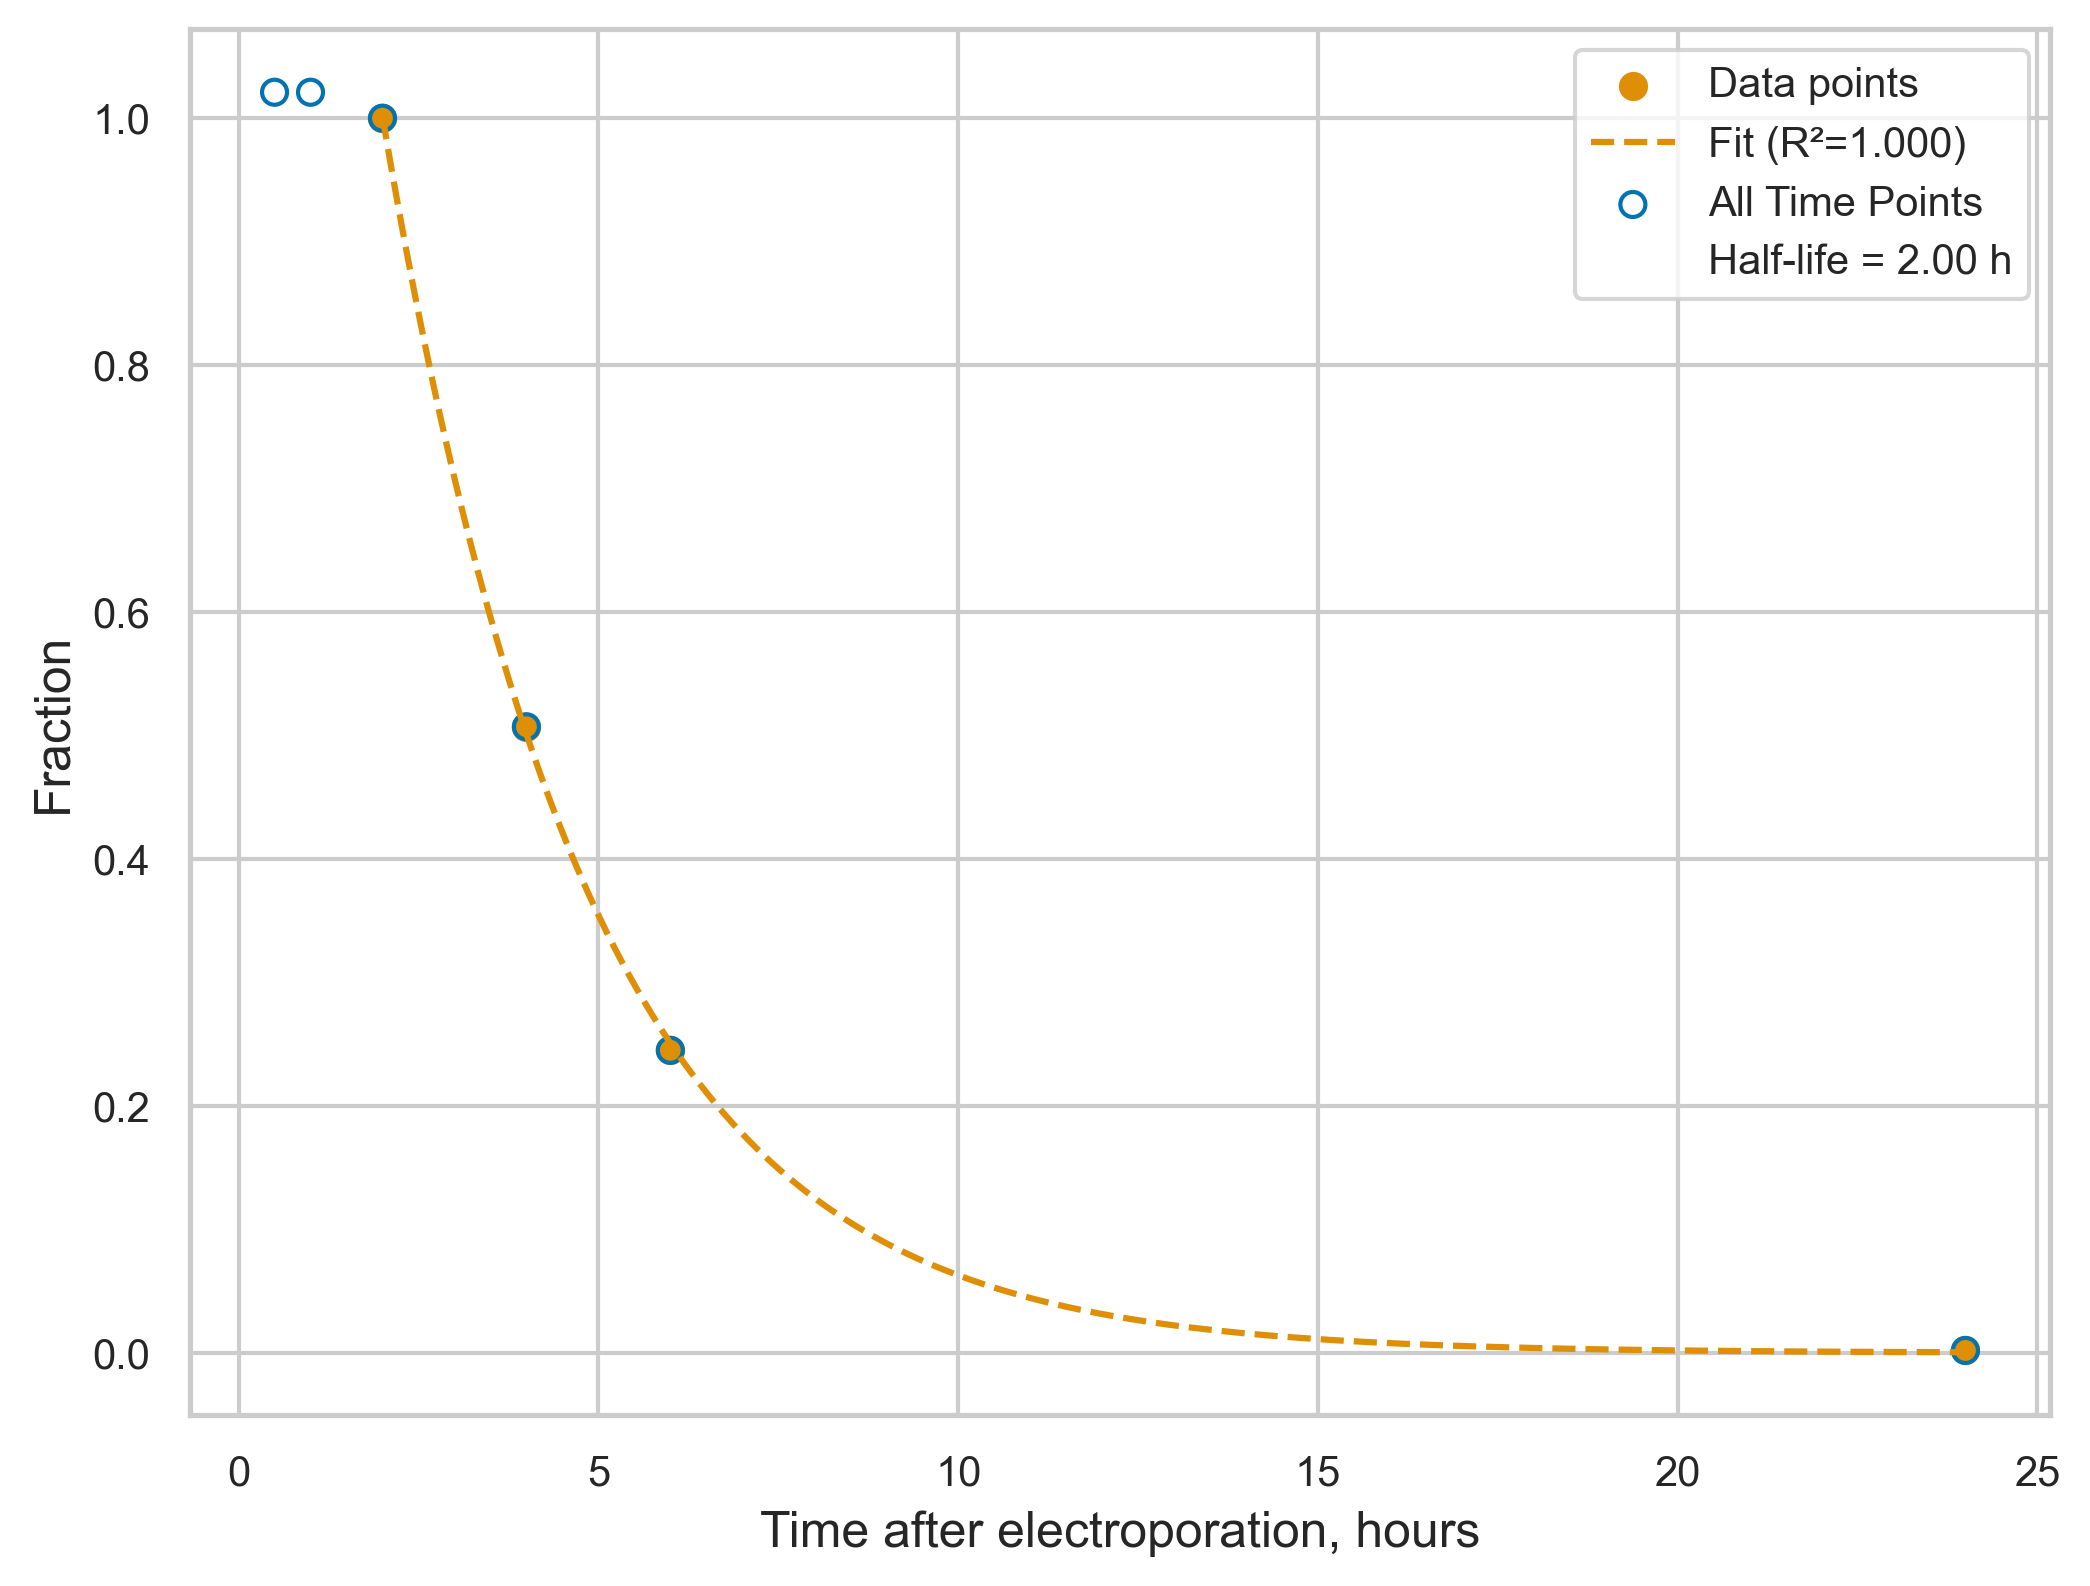

Saved: The degradation curve Init1 Run 1.tiff
y(x) = 2.0068 * exp(-0.3395 * x) + -0.0085
Half-life (b1_3): 2.0414 hours


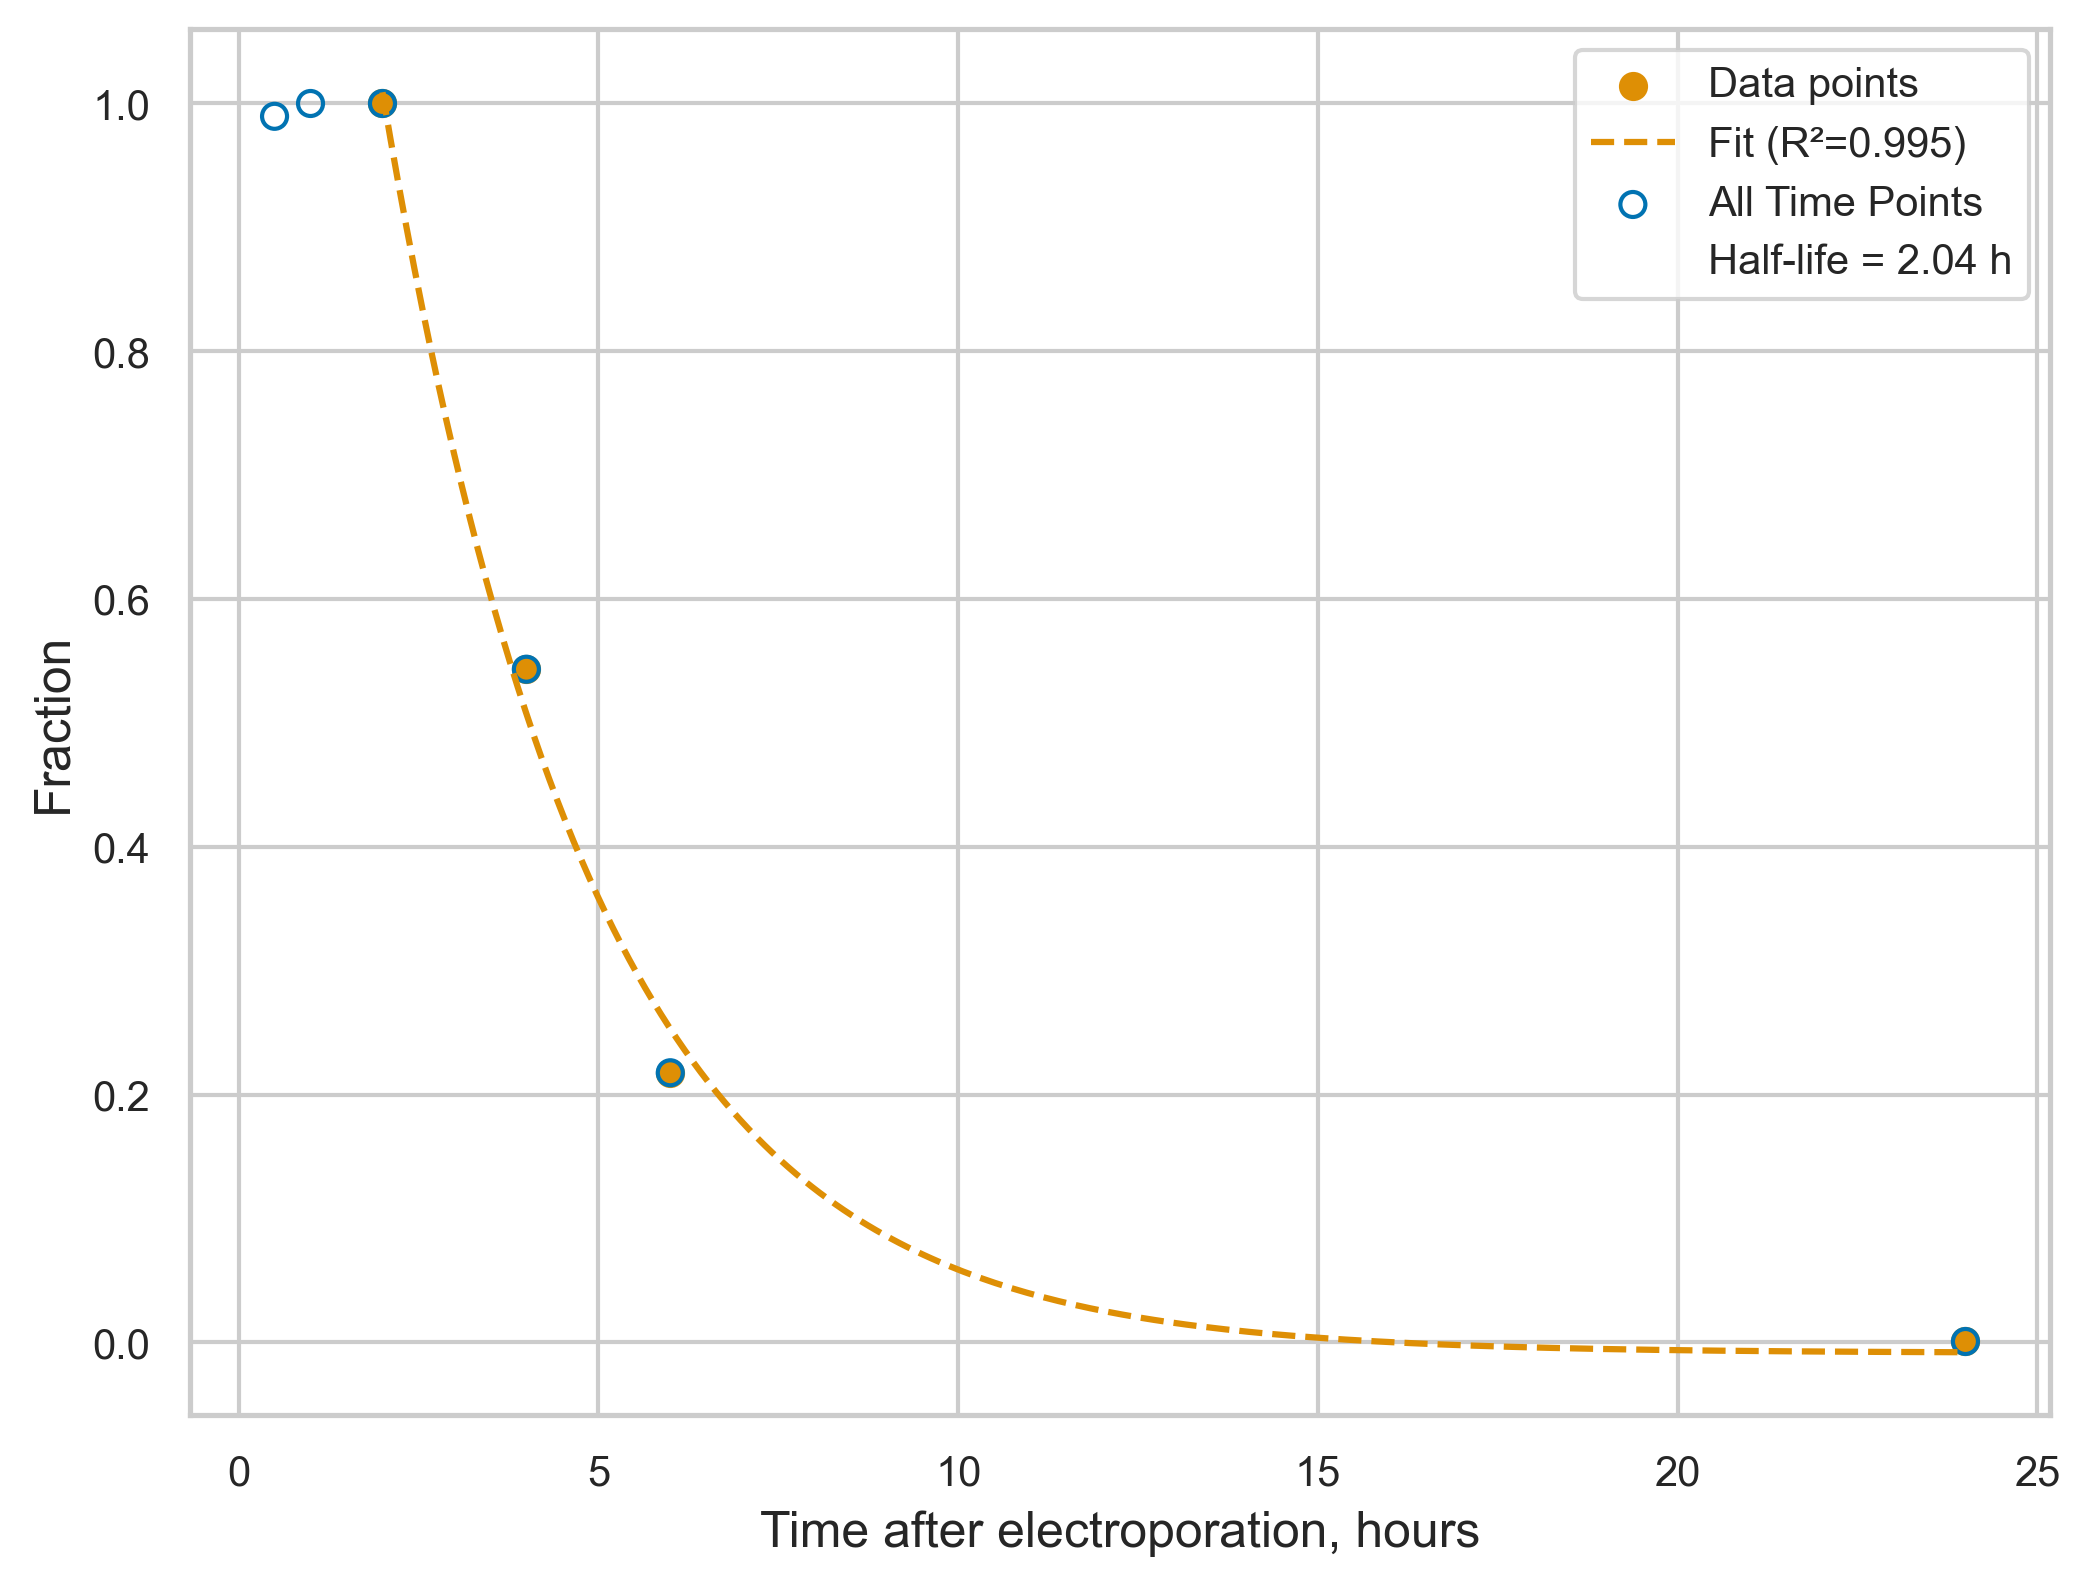

Saved: The degradation curve Init1 Run 2.tiff
y(x) = 1.2395 * exp(-0.3354 * x) + -0.0270
Half-life (b1_4): 2.0668 hours


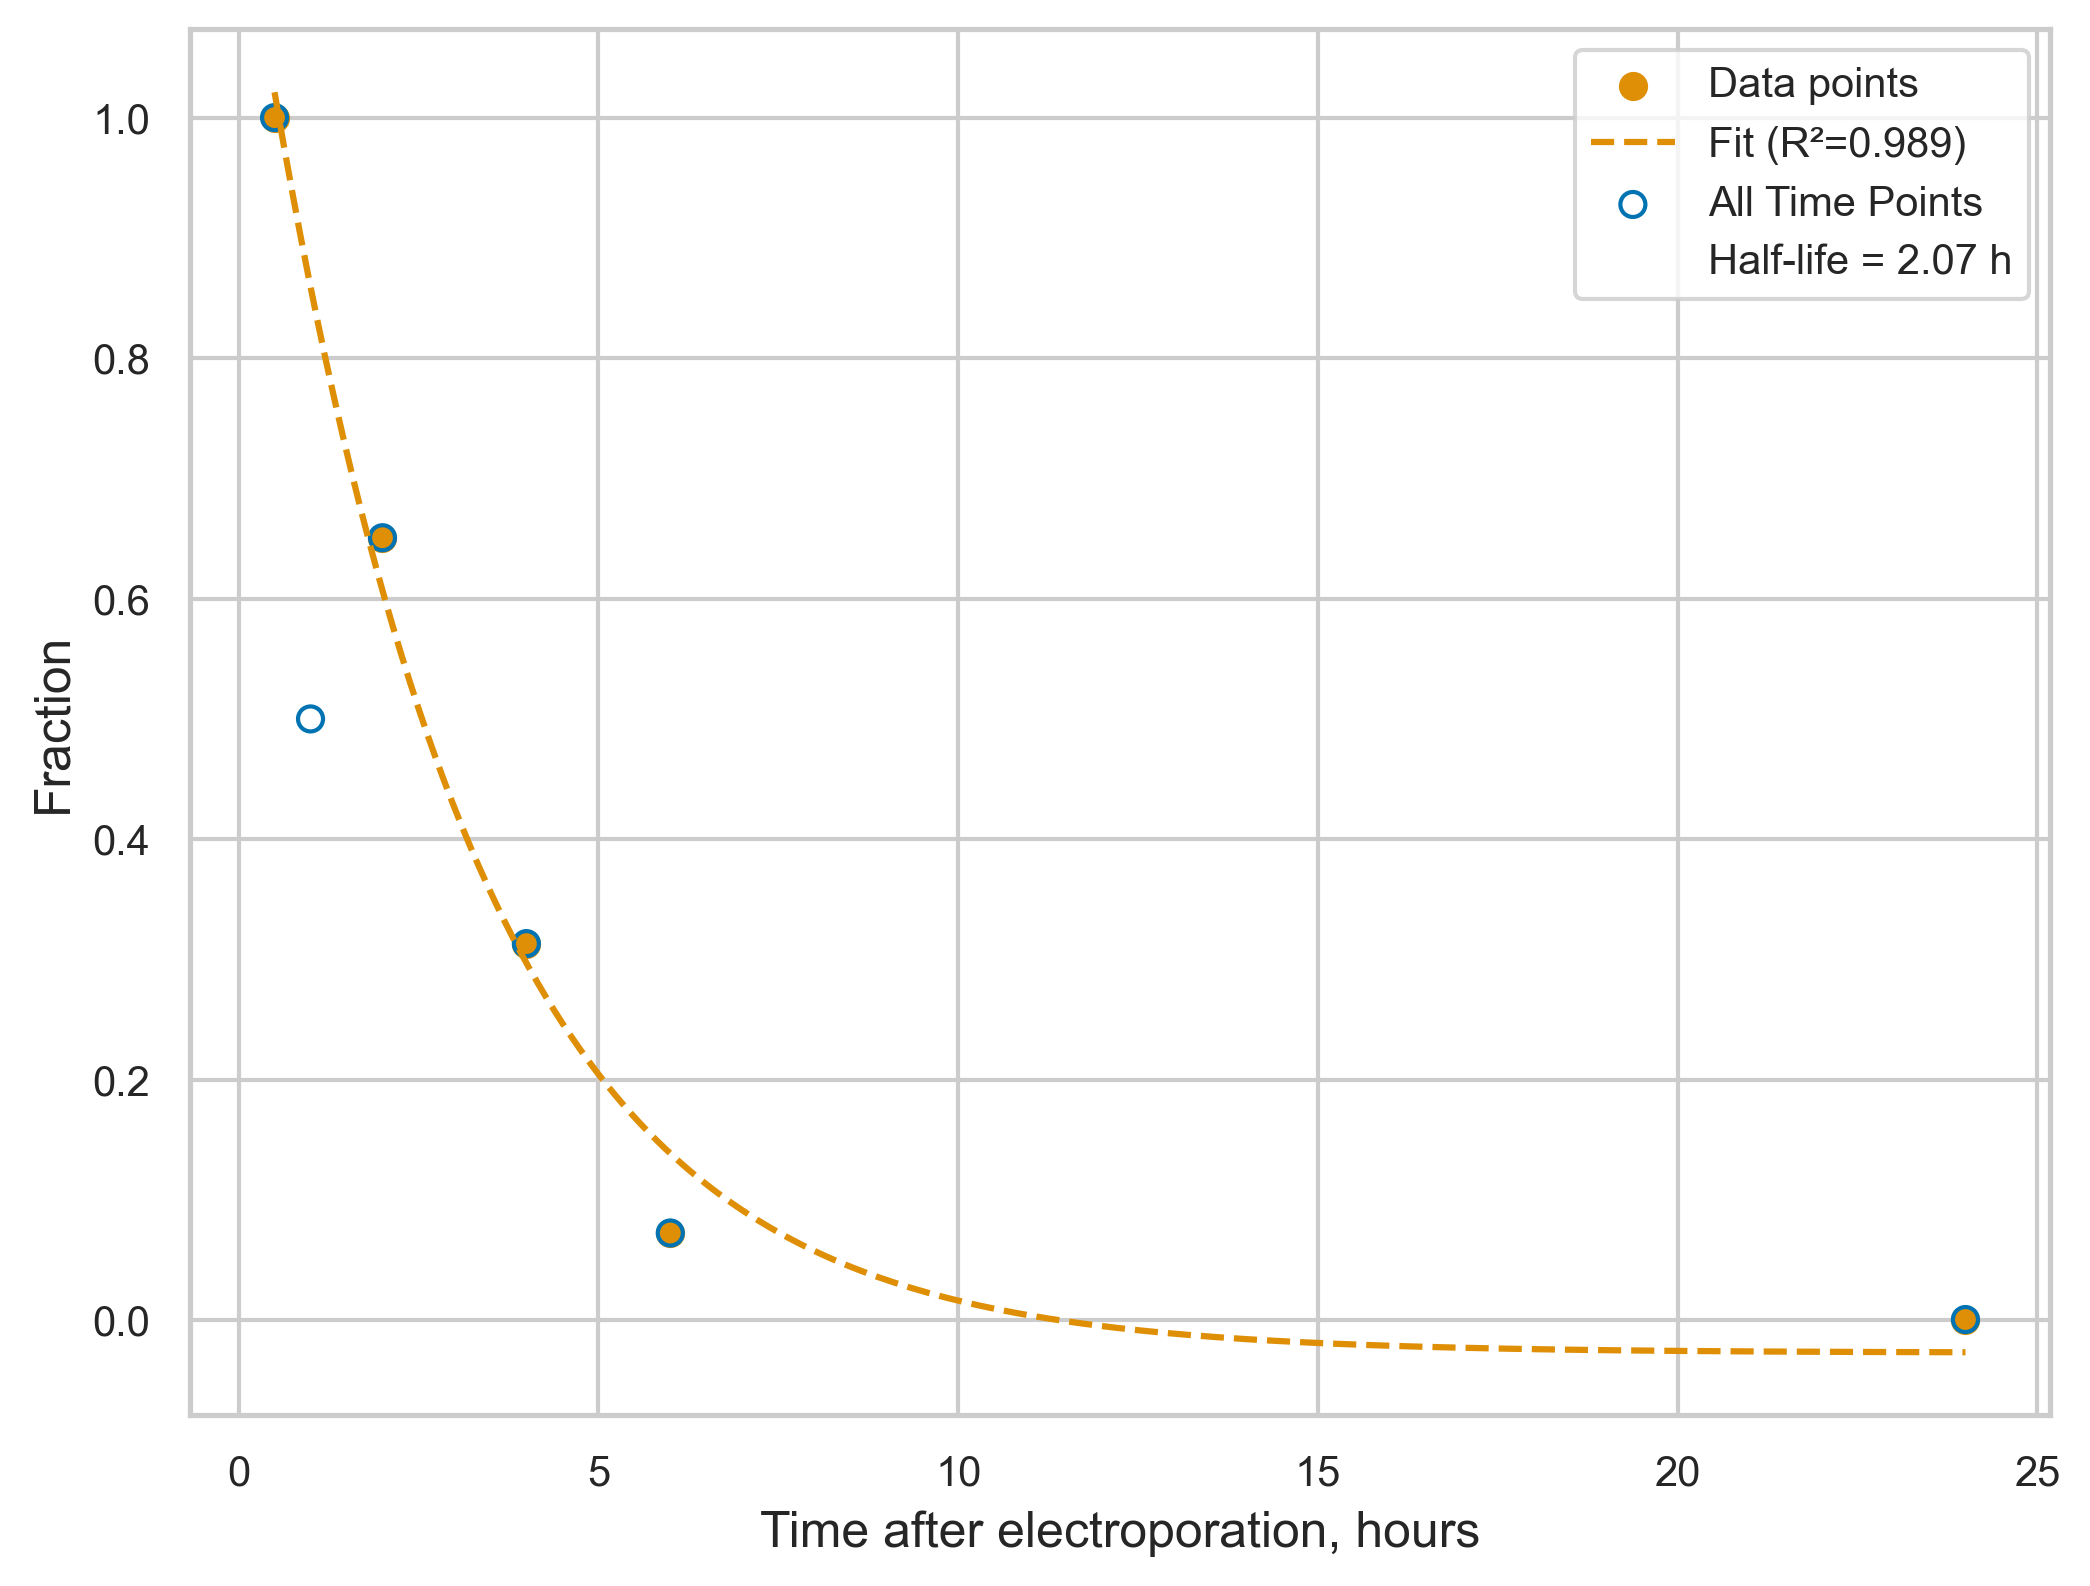

Saved: The degradation curve Init1 Run 3.tiff
y(x) = 1.3713 * exp(-0.3551 * x) + 0.0073
Half-life (b1_5): 1.9518 hours


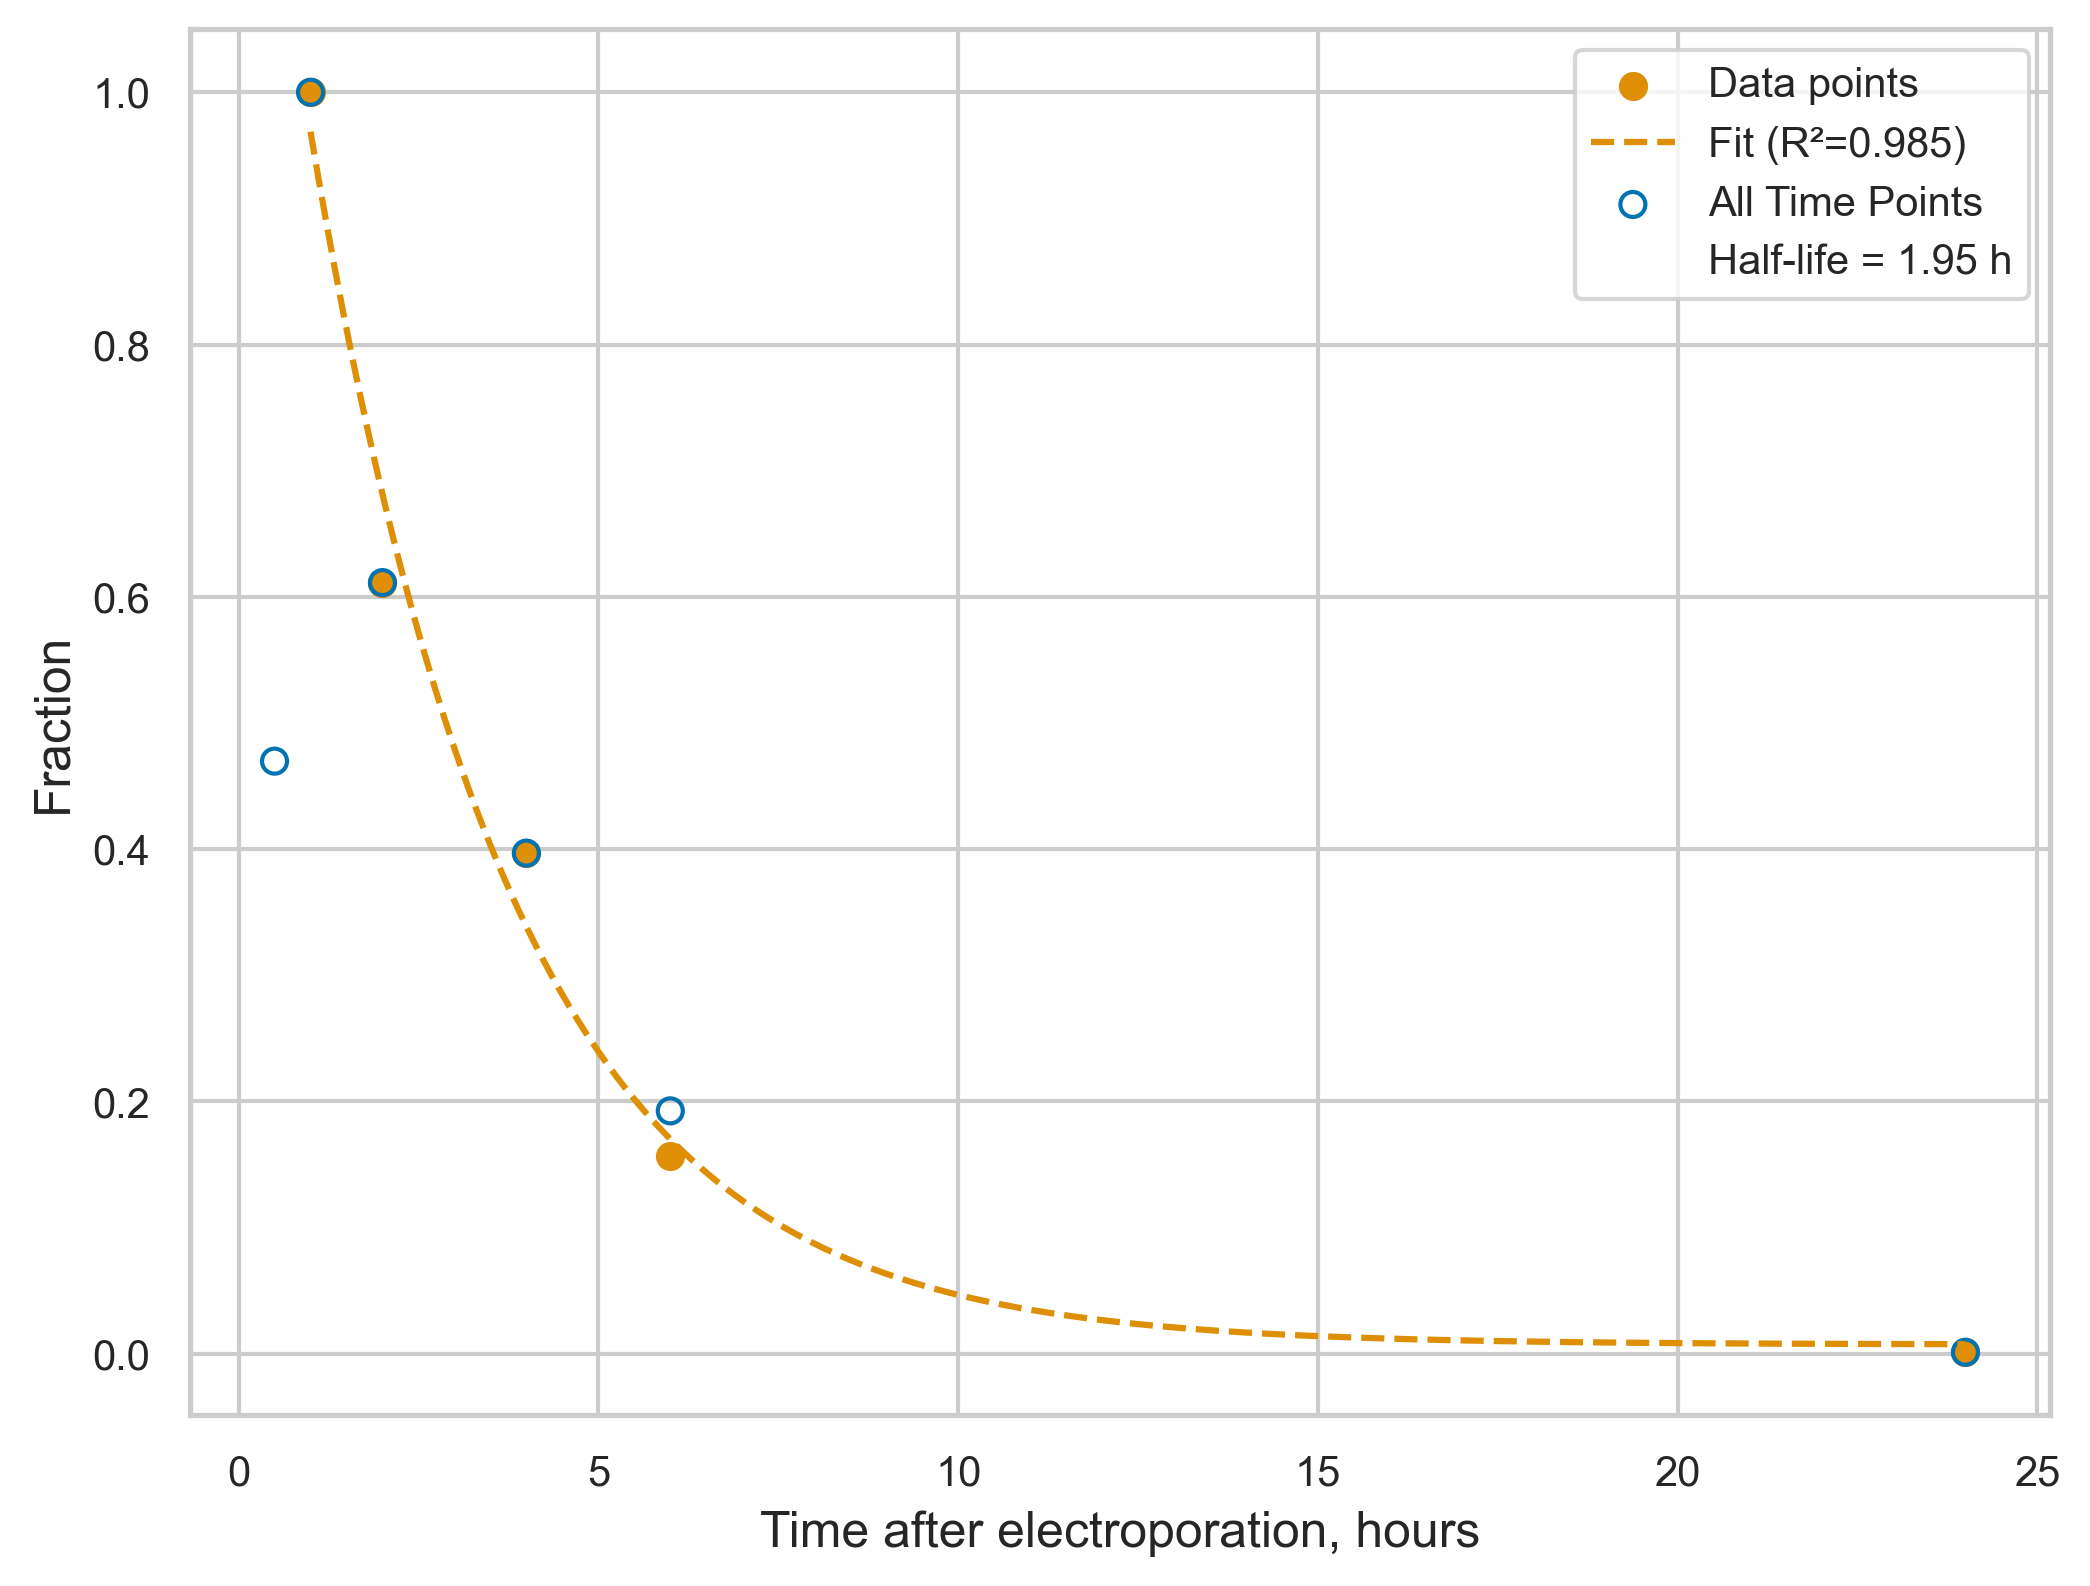

Saved: The degradation curve Init1 Run 4.tiff
y(x) = 1.1458 * exp(-0.3224 * x) + -0.0068
Half-life (b2_1): 2.1500 hours


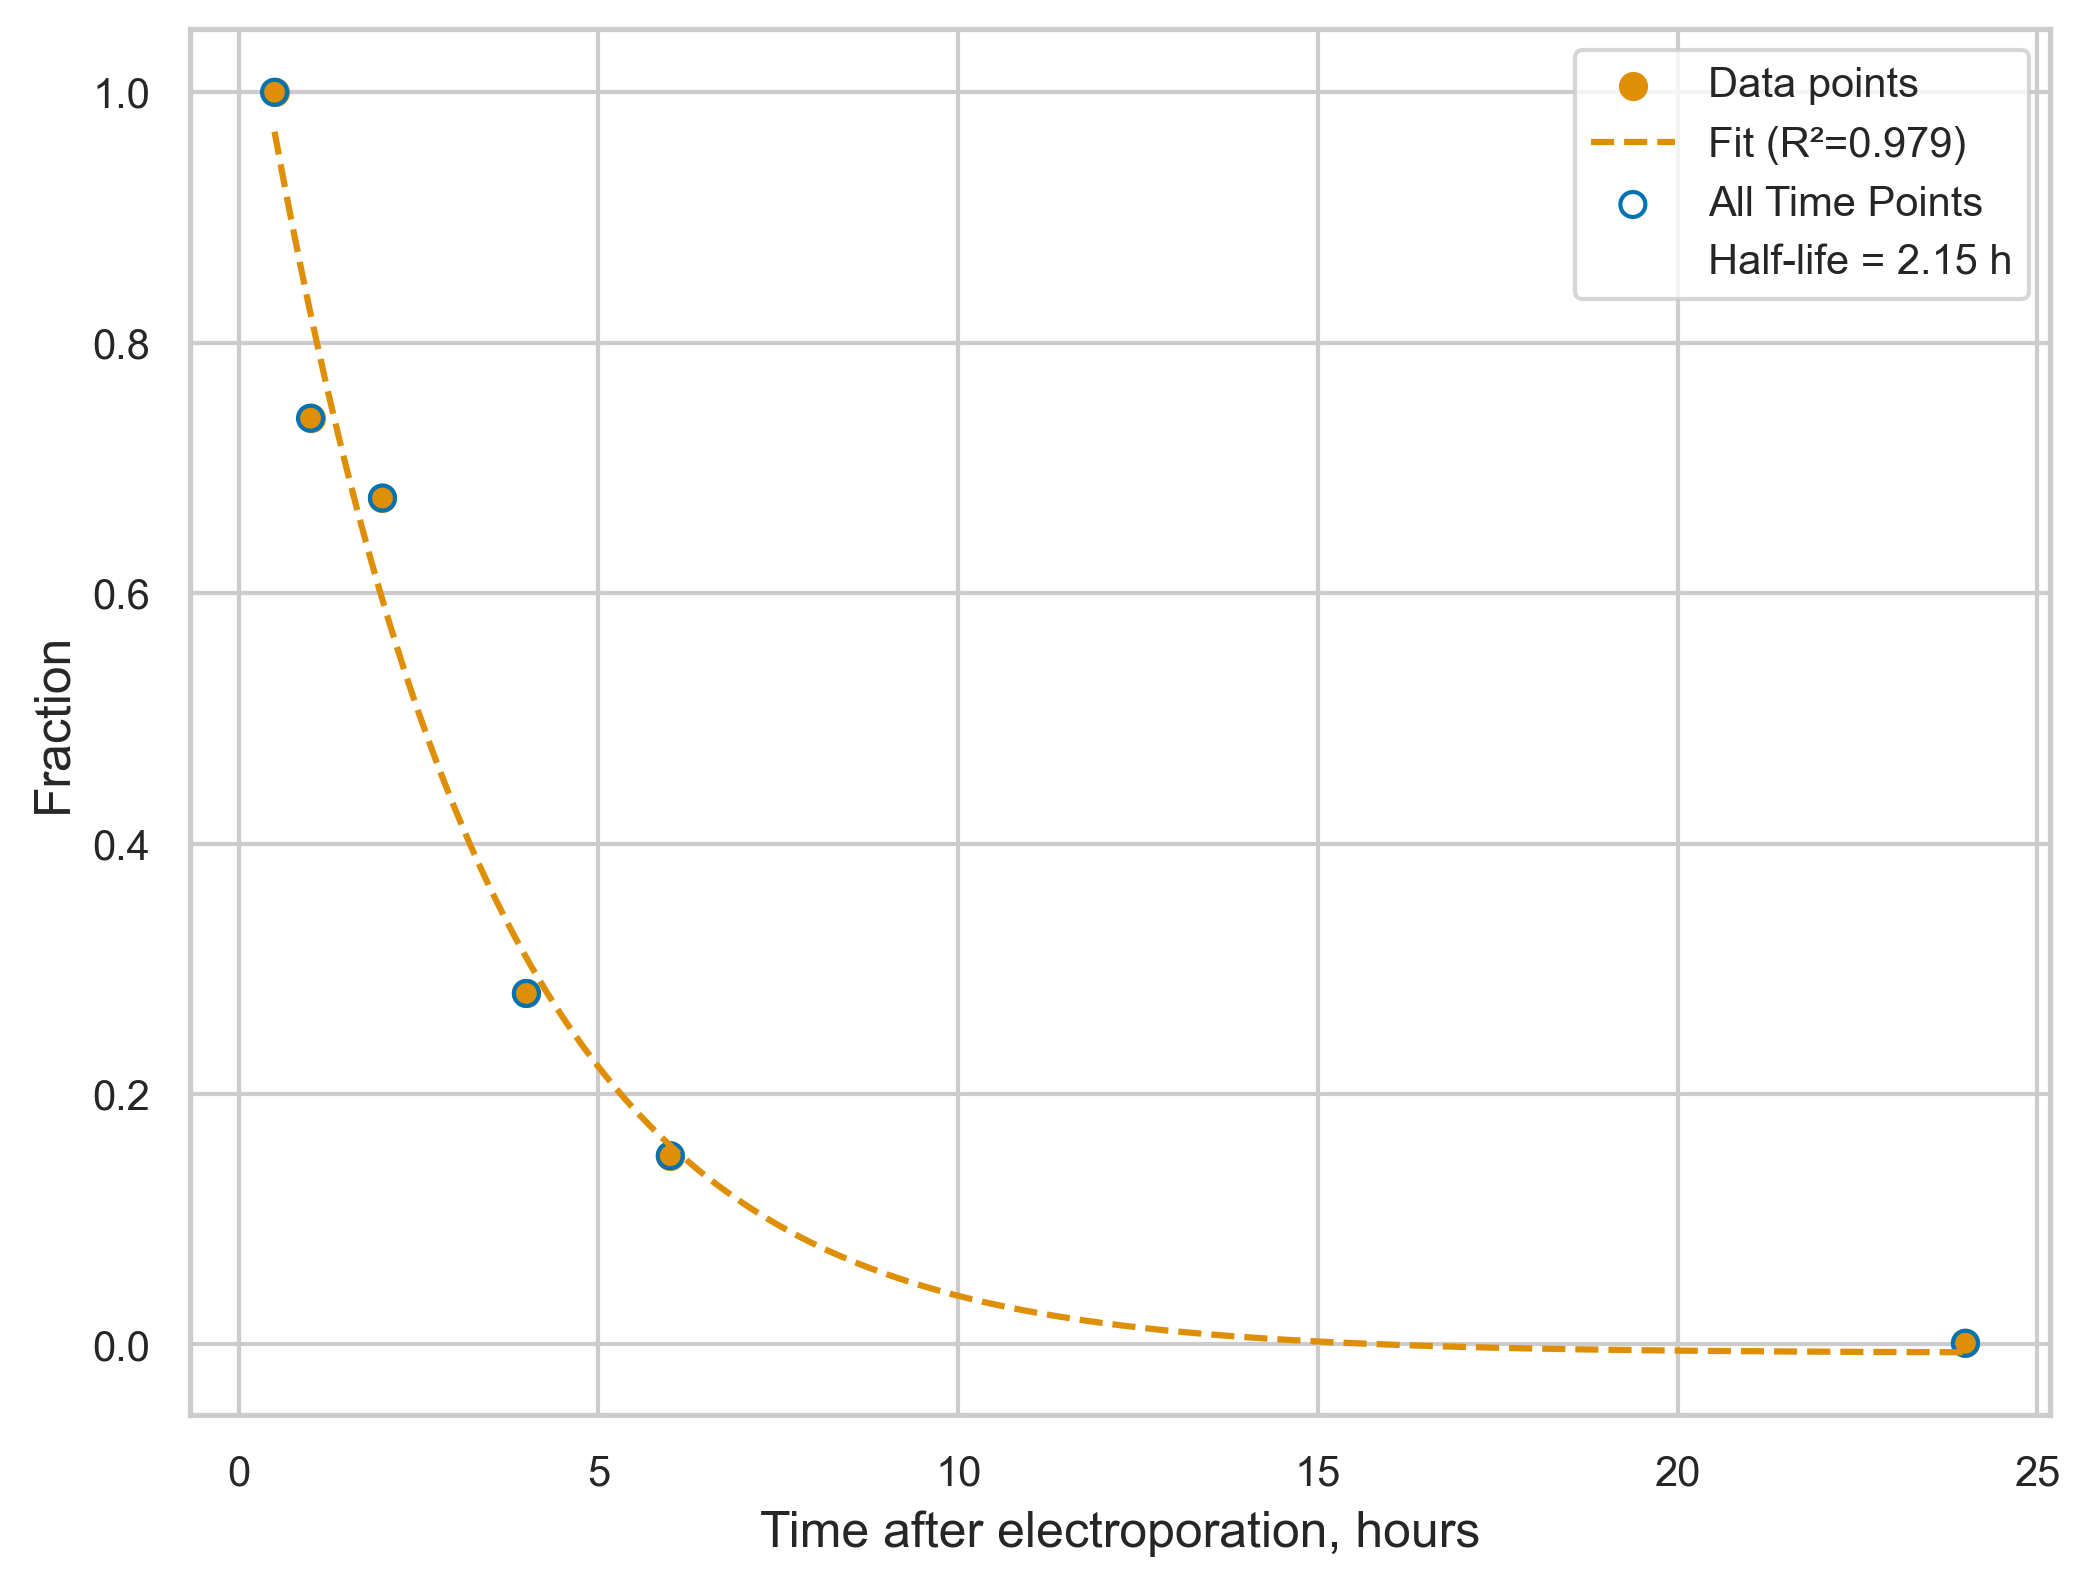

Saved: The degradation curve Optim1 Run 1.tiff
y(x) = 1.7439 * exp(-0.2669 * x) + -0.0091
Half-life (b2_2): 2.5974 hours


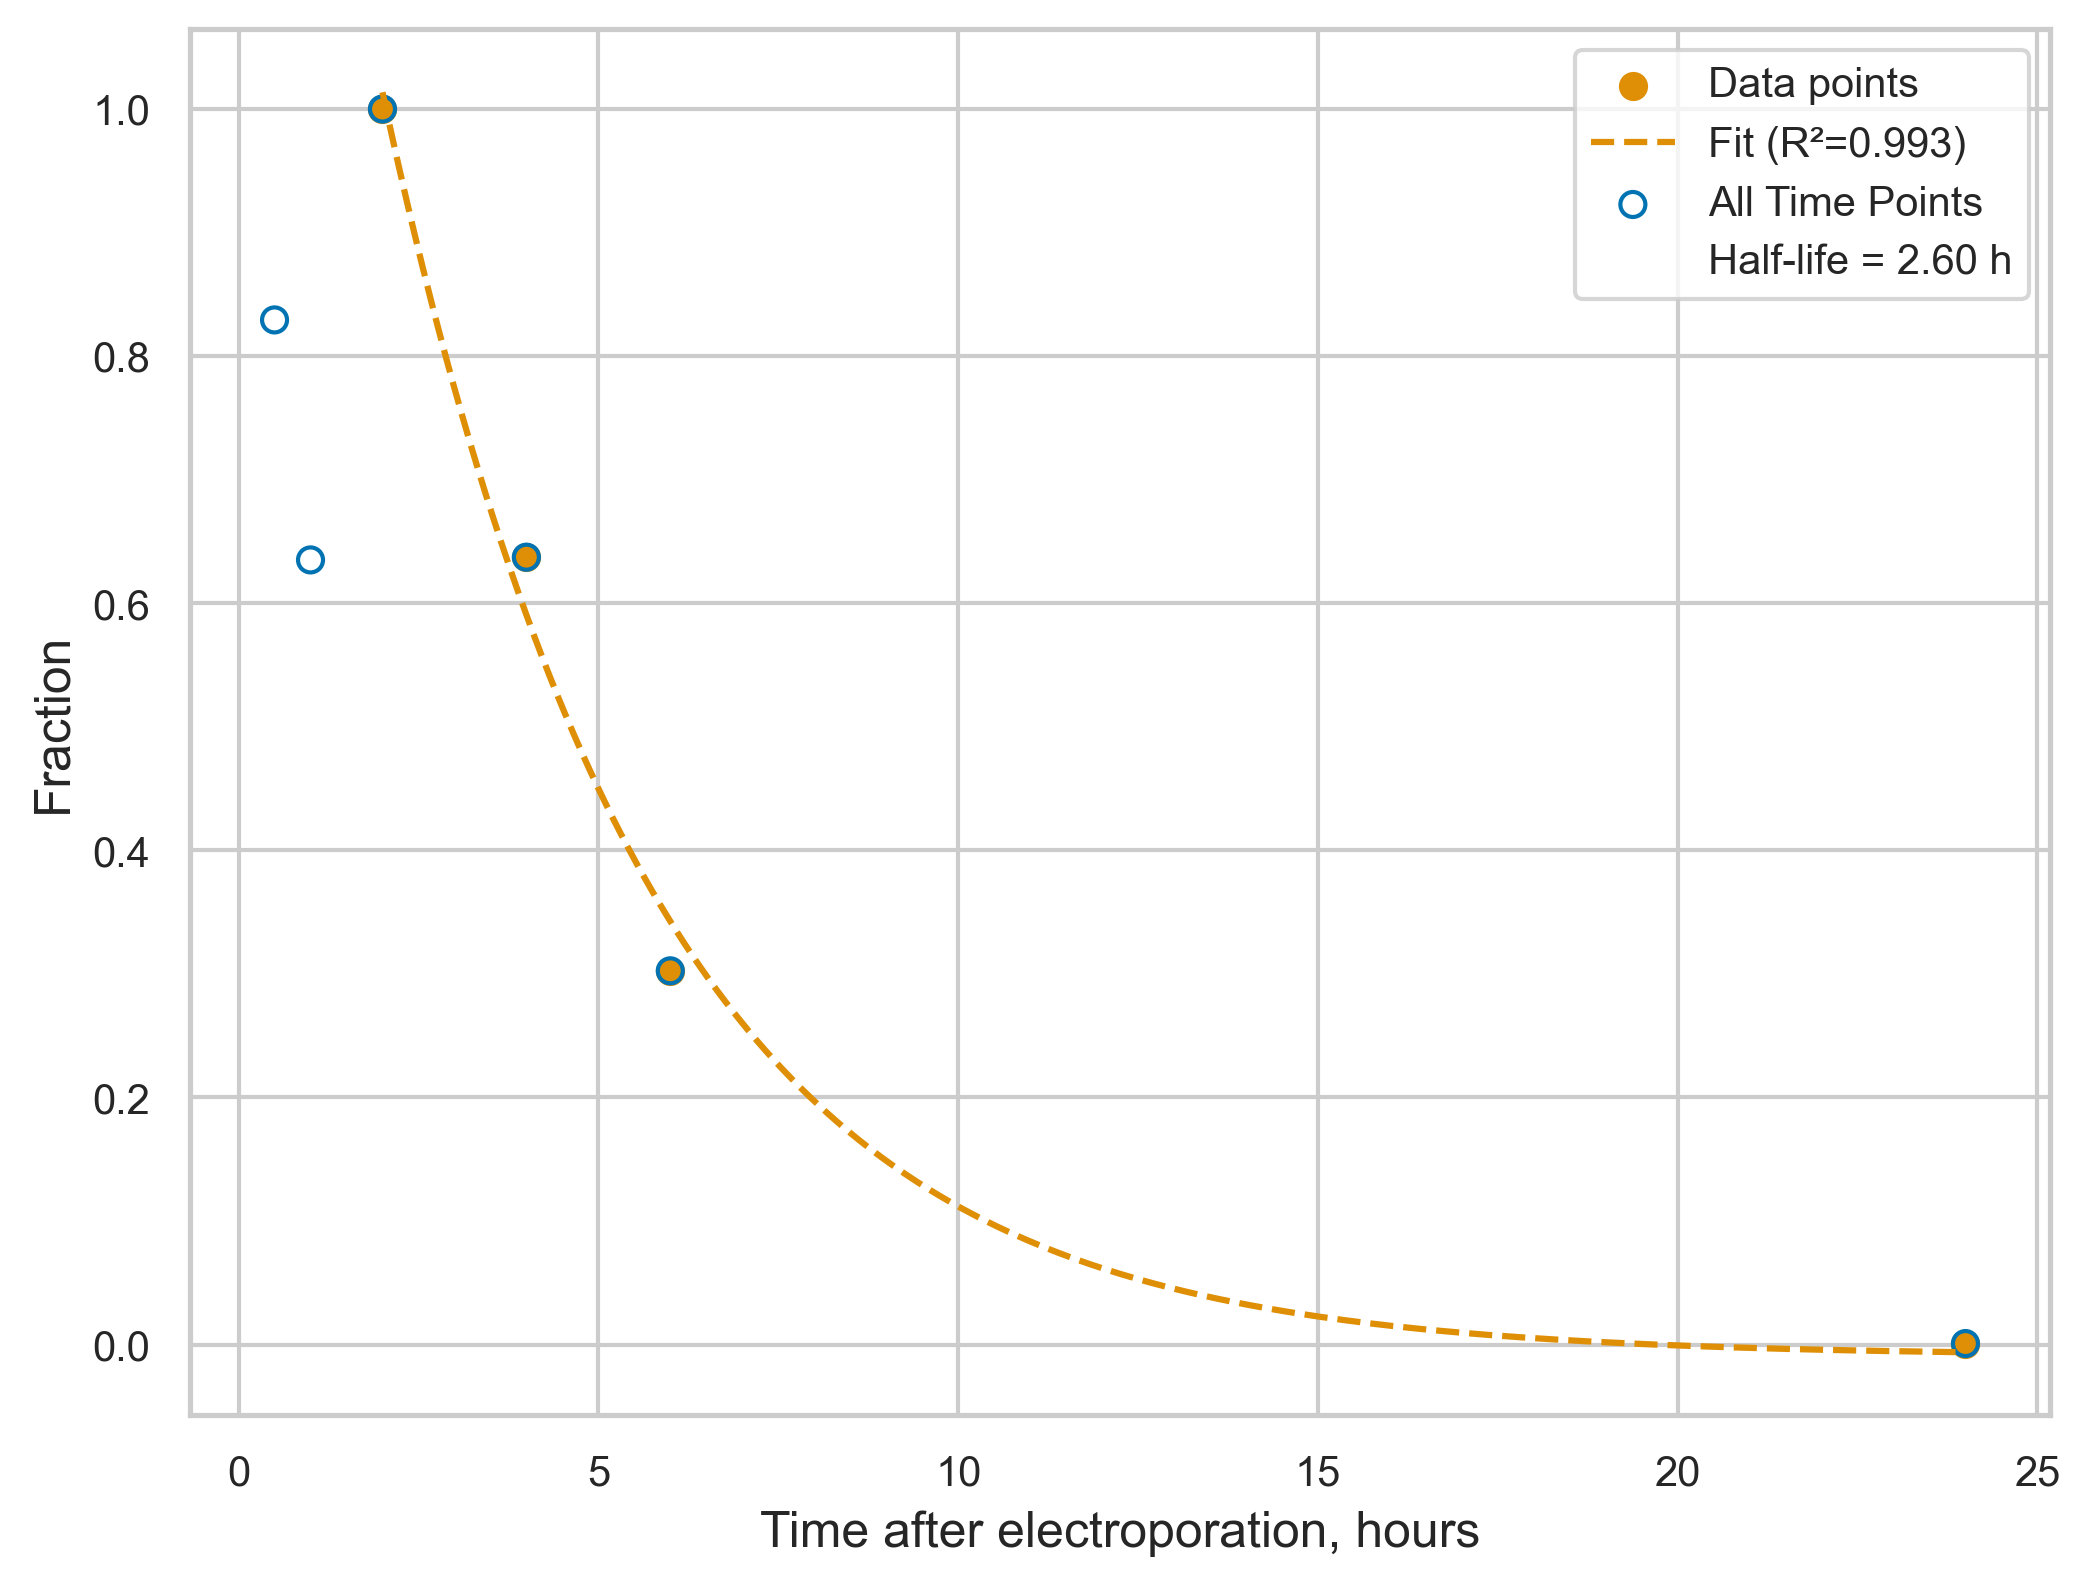

Saved: The degradation curve Optim1 Run 2.tiff
y(x) = 3.0196 * exp(-0.2754 * x) + -0.0034
Half-life (b2_4): 2.5164 hours


/var/folders/r2/d51ts3bj7ys1zccpl_fdh4bm0000gn/T/ipykernel_34803/1210547964.py:44: OptimizeWarning: Covariance of the parameters could not be estimated
  params, _ = curve_fit(exp_decay, x_data, y_data, p0=initial_guess, maxfev=5000)


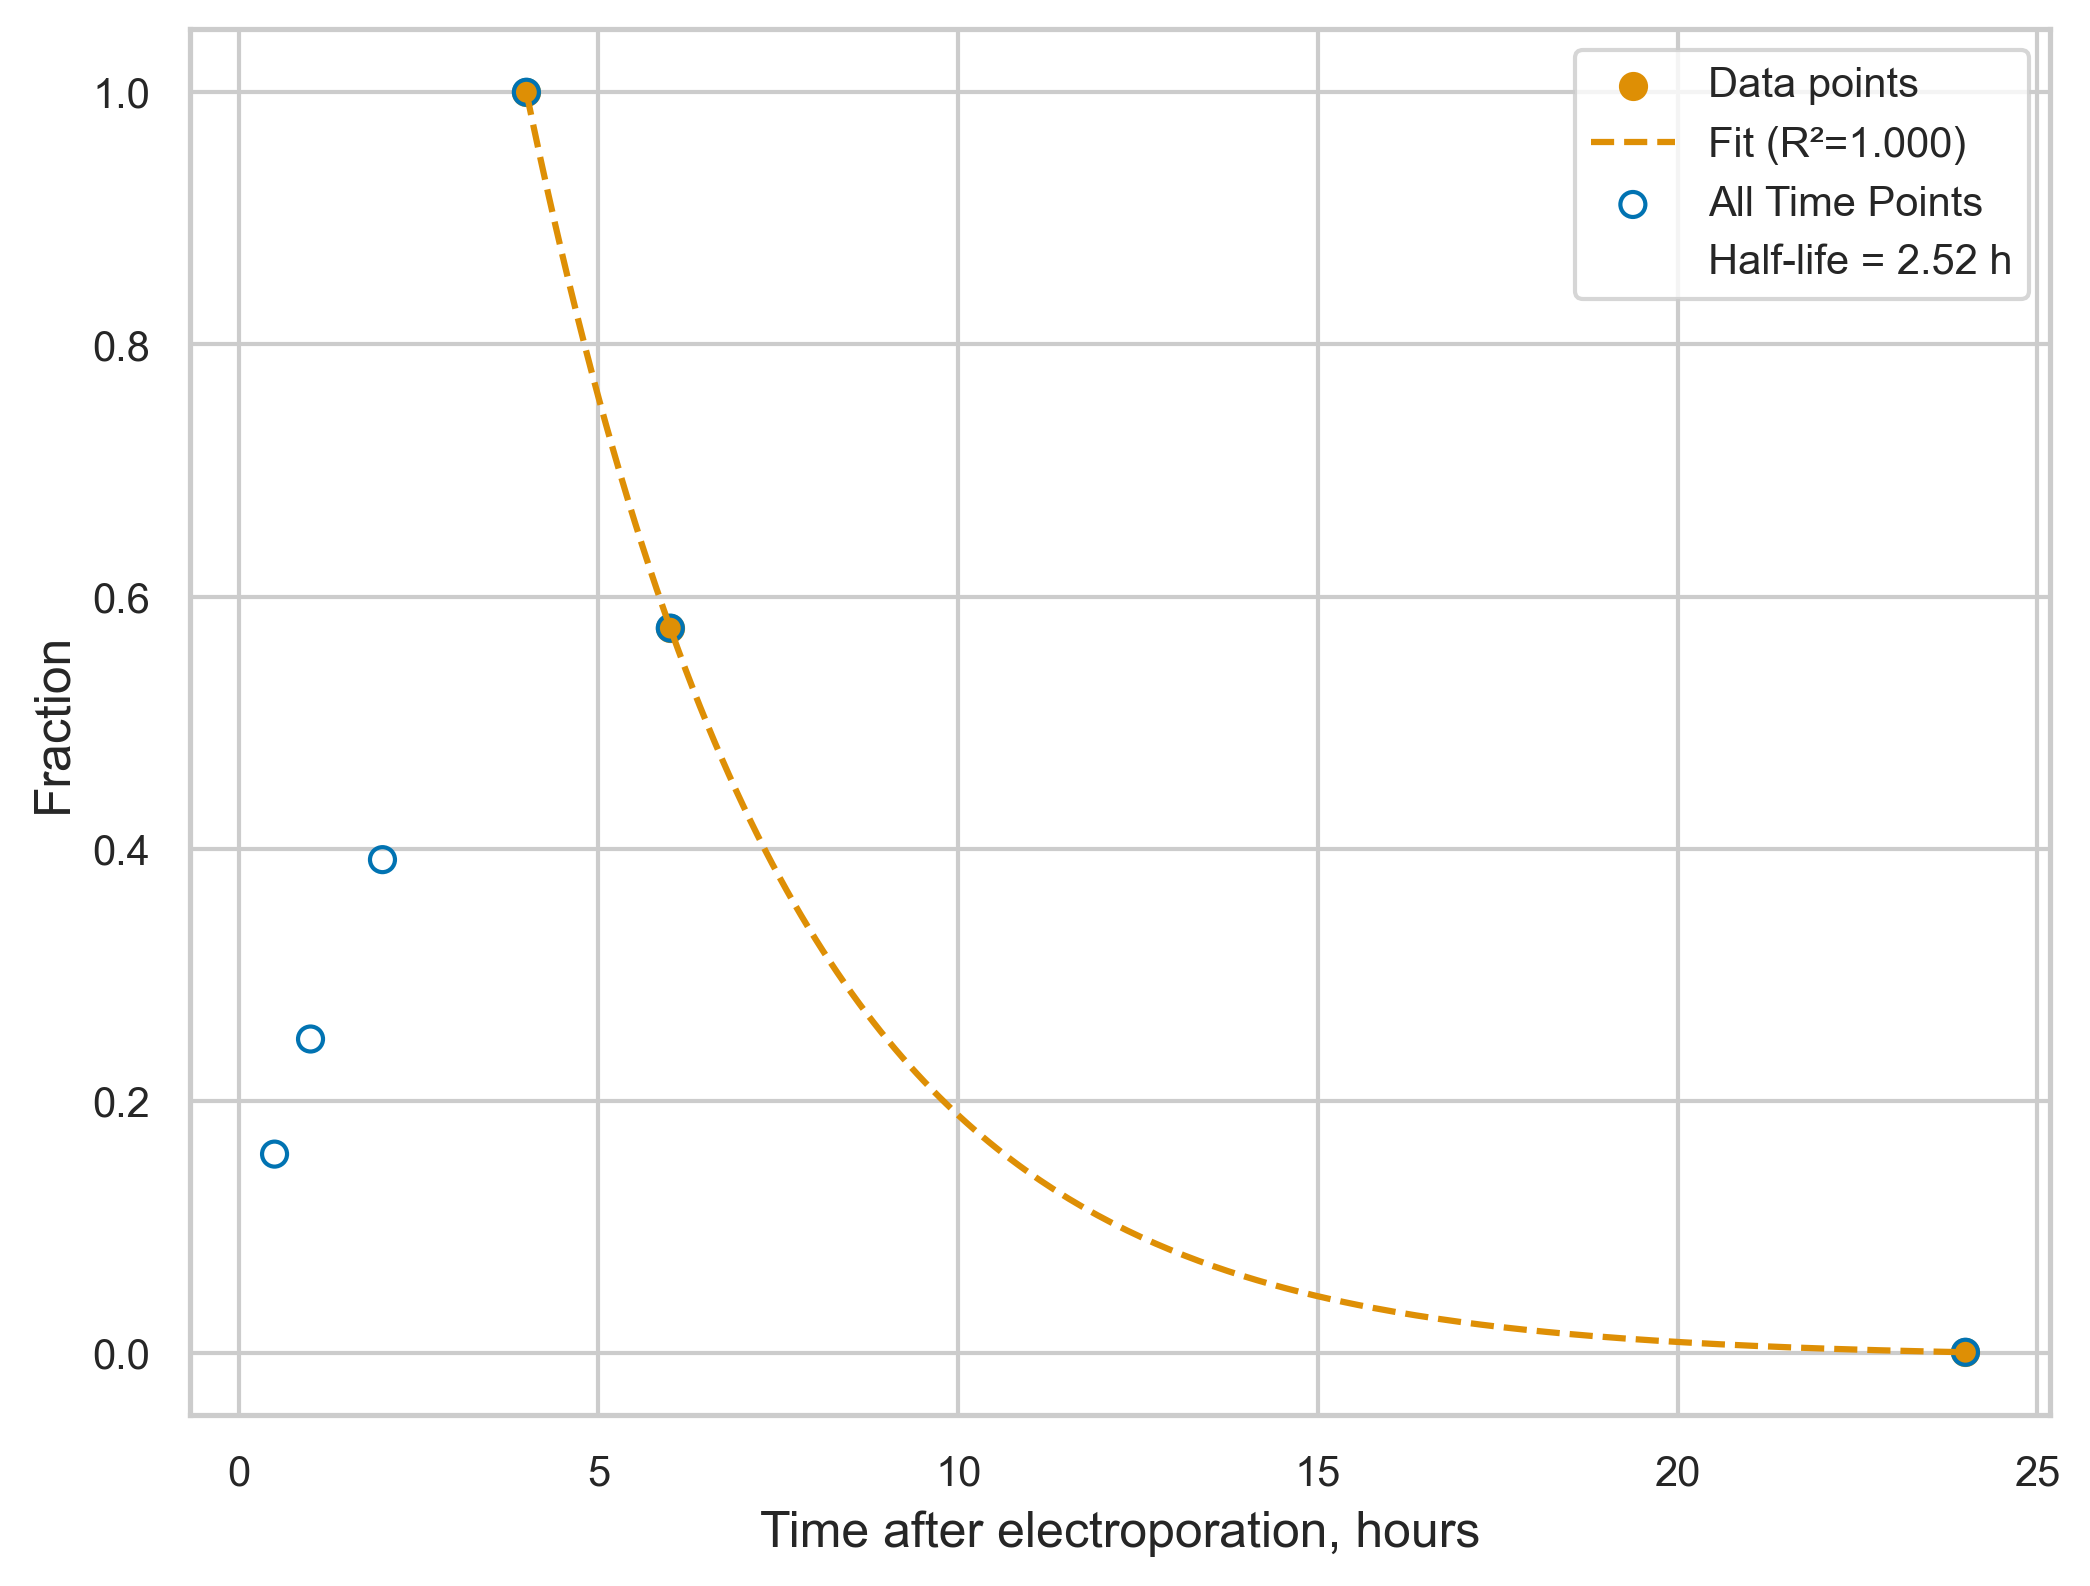

Saved: The degradation curve Optim1 Run 3.tiff
y(x) = 1.7252 * exp(-0.2537 * x) + -0.0133
Half-life (b2_5): 2.7325 hours


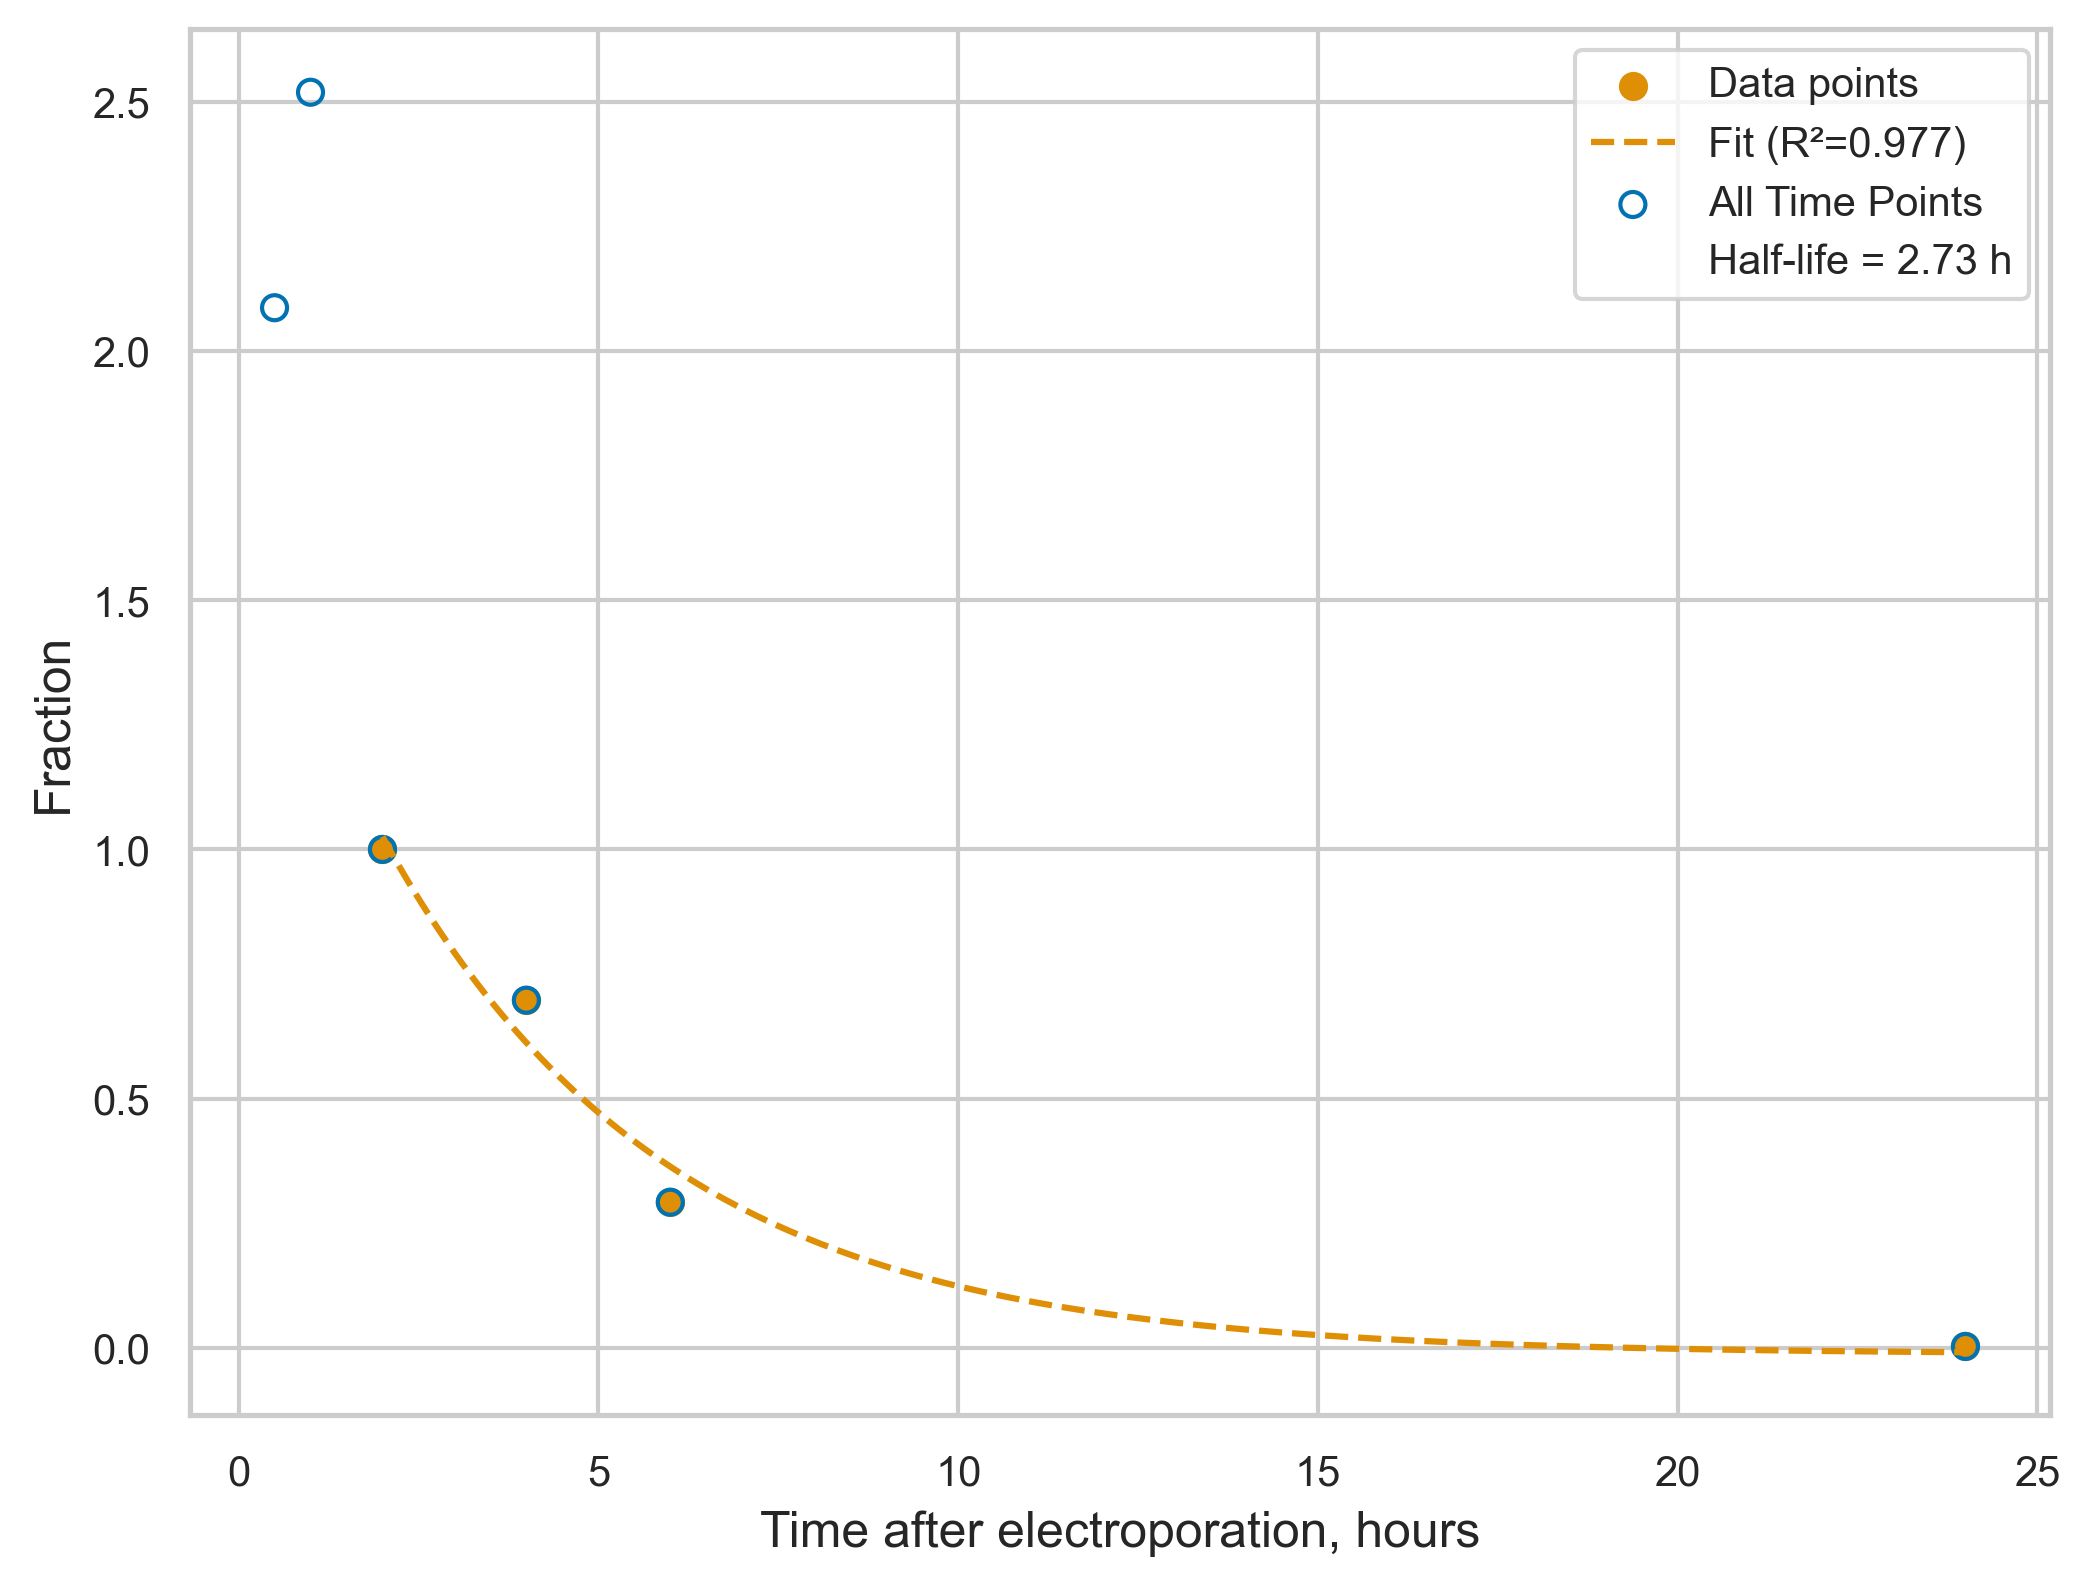

Saved: The degradation curve Optim1 Run 4.tiff
y(x) = 1.5156 * exp(-1.0905 * x) + 0.1192
Half-life (b3_1): 0.6356 hours


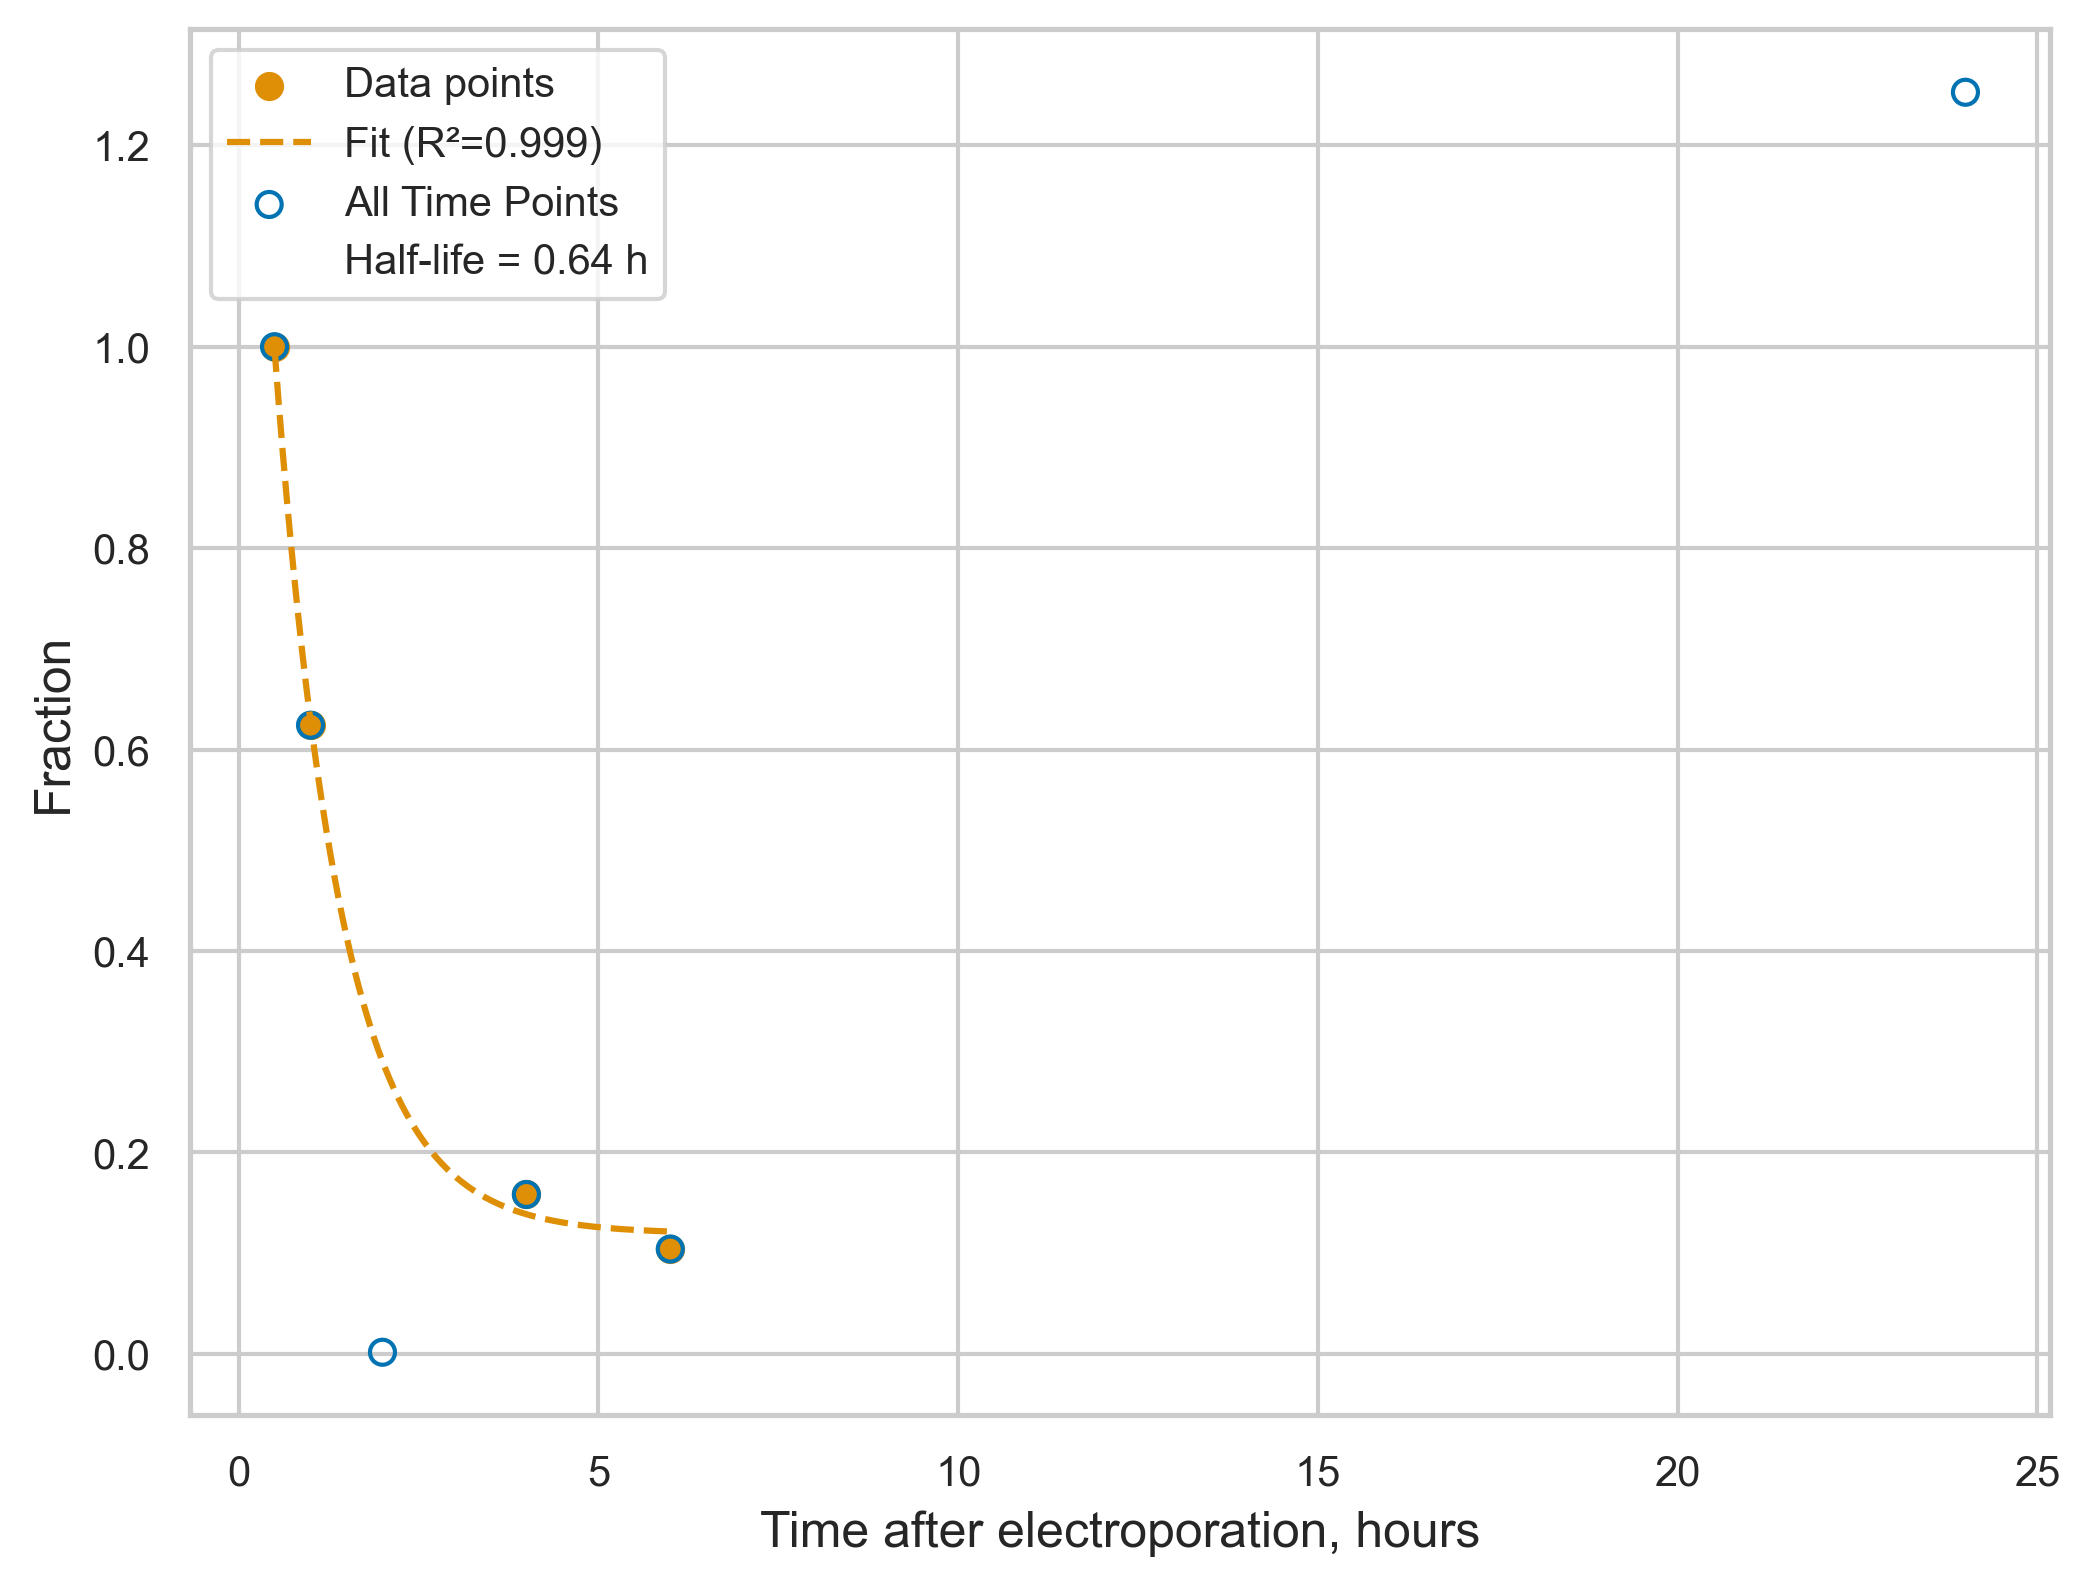

Saved: The degradation curve Init2 Run 1.tiff
y(x) = 4.3445 * exp(-0.7450 * x) + 0.0193
Half-life (b3_2): 0.9304 hours


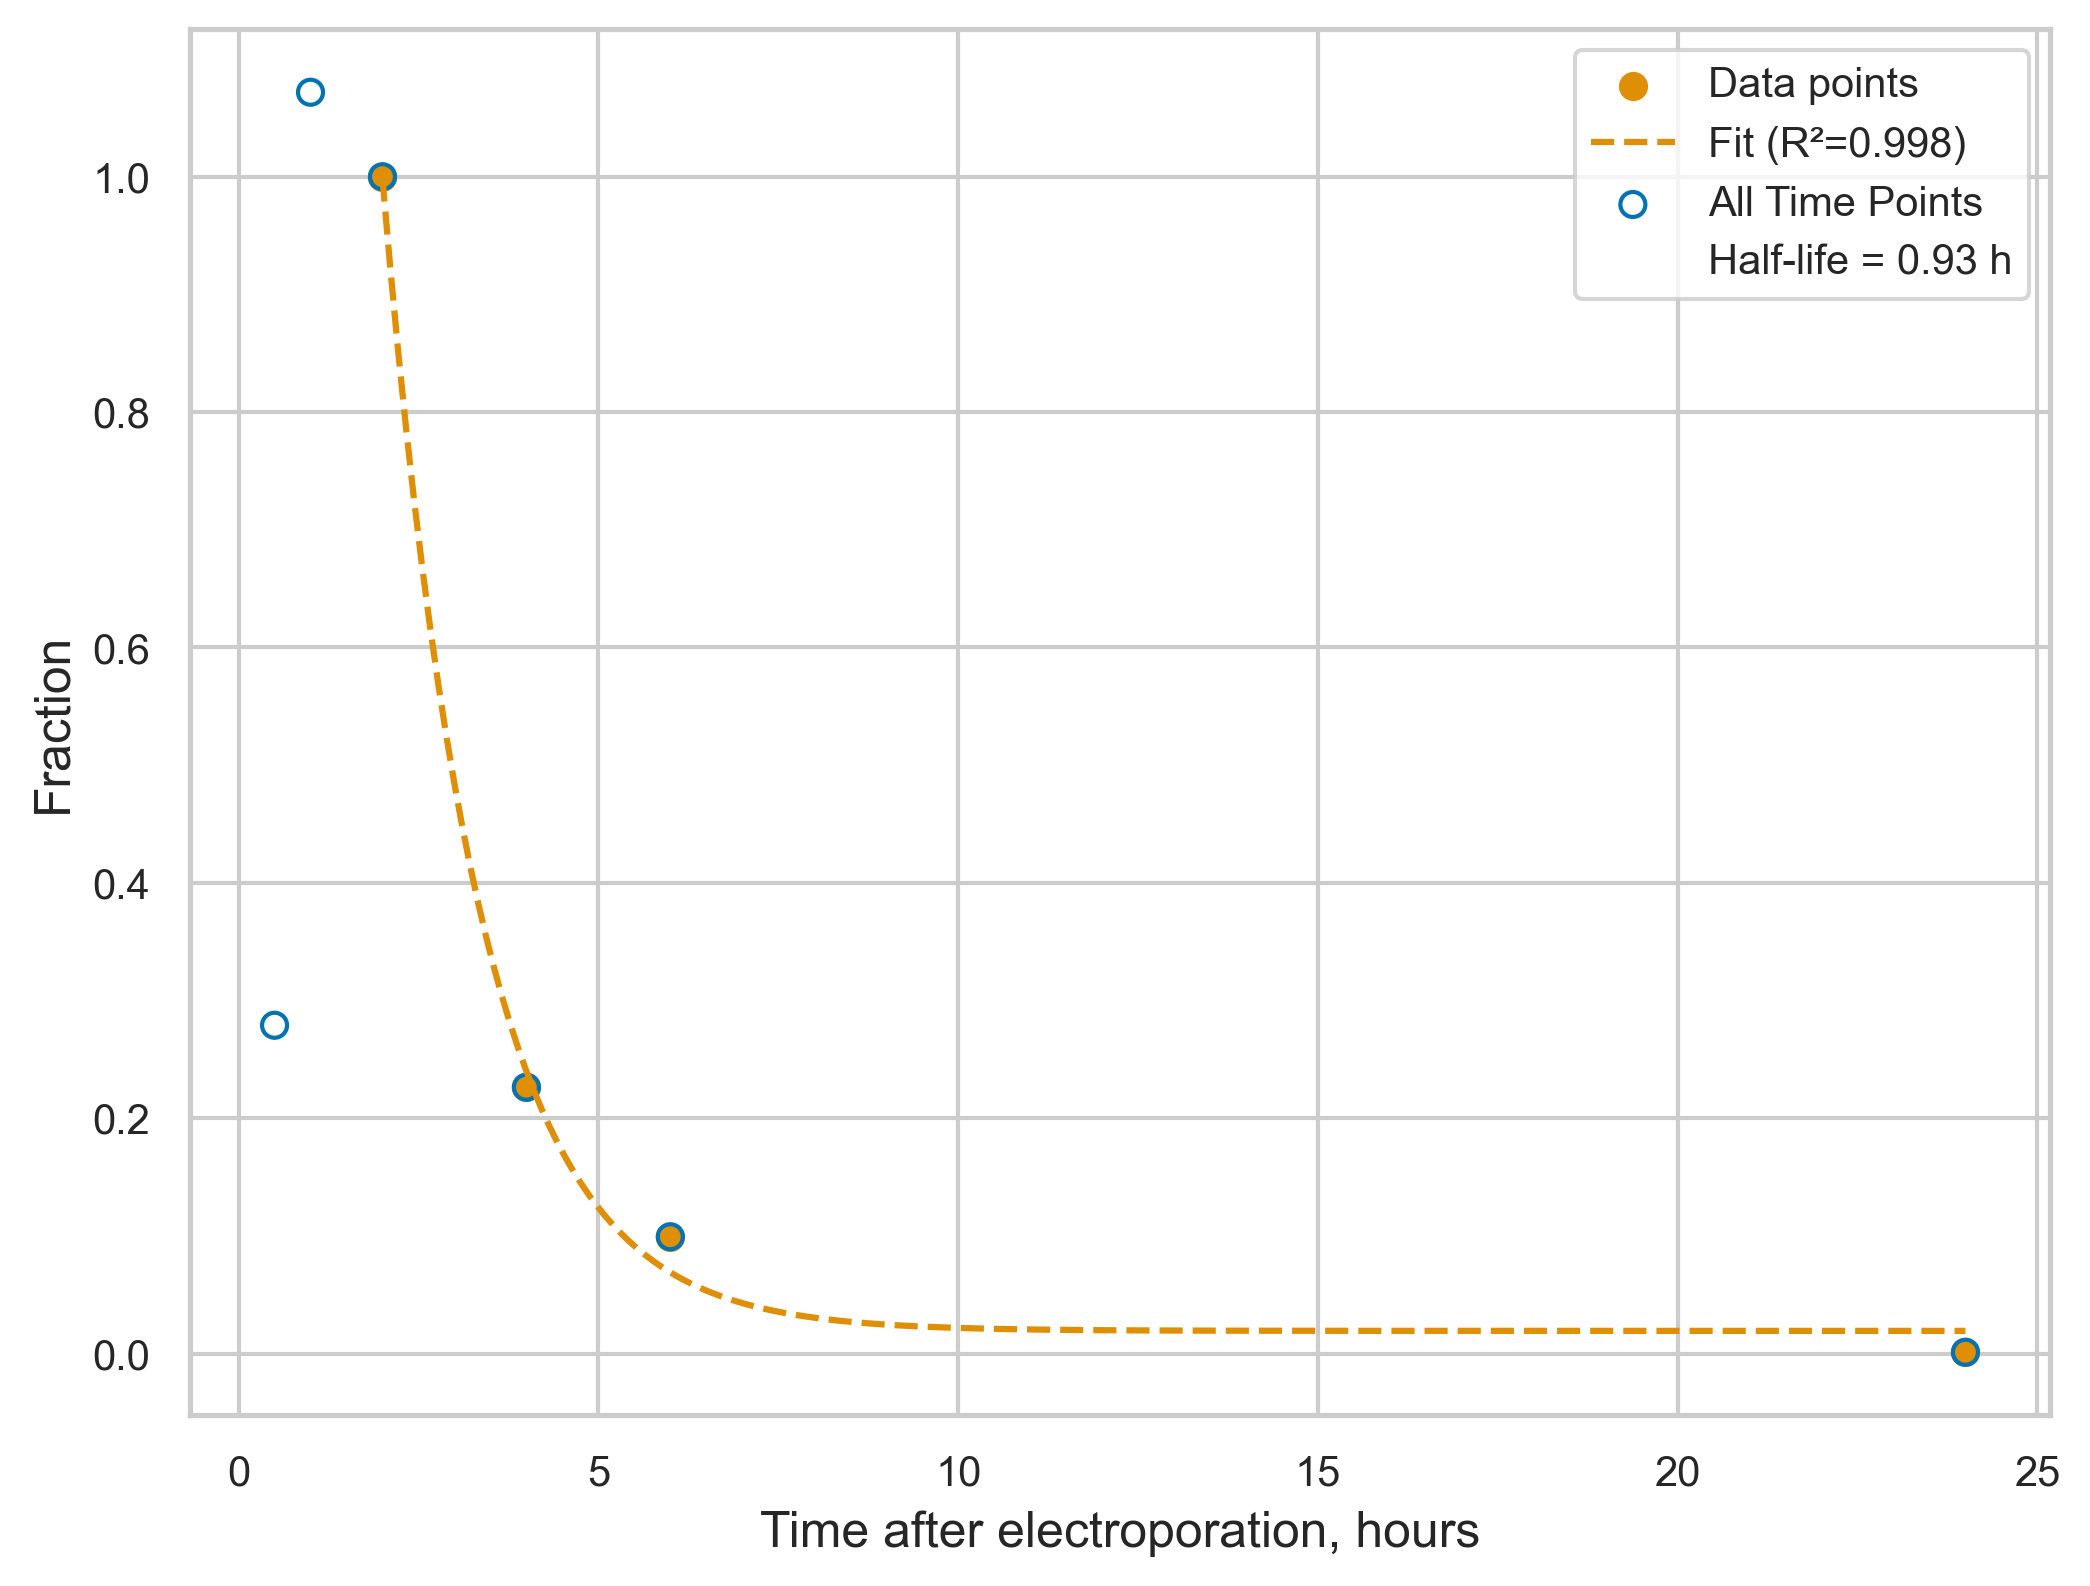

Saved: The degradation curve Init2 Run 2.tiff
y(x) = 1.4173 * exp(-0.5800 * x) + -0.0373
Half-life (b3_3): 1.1952 hours


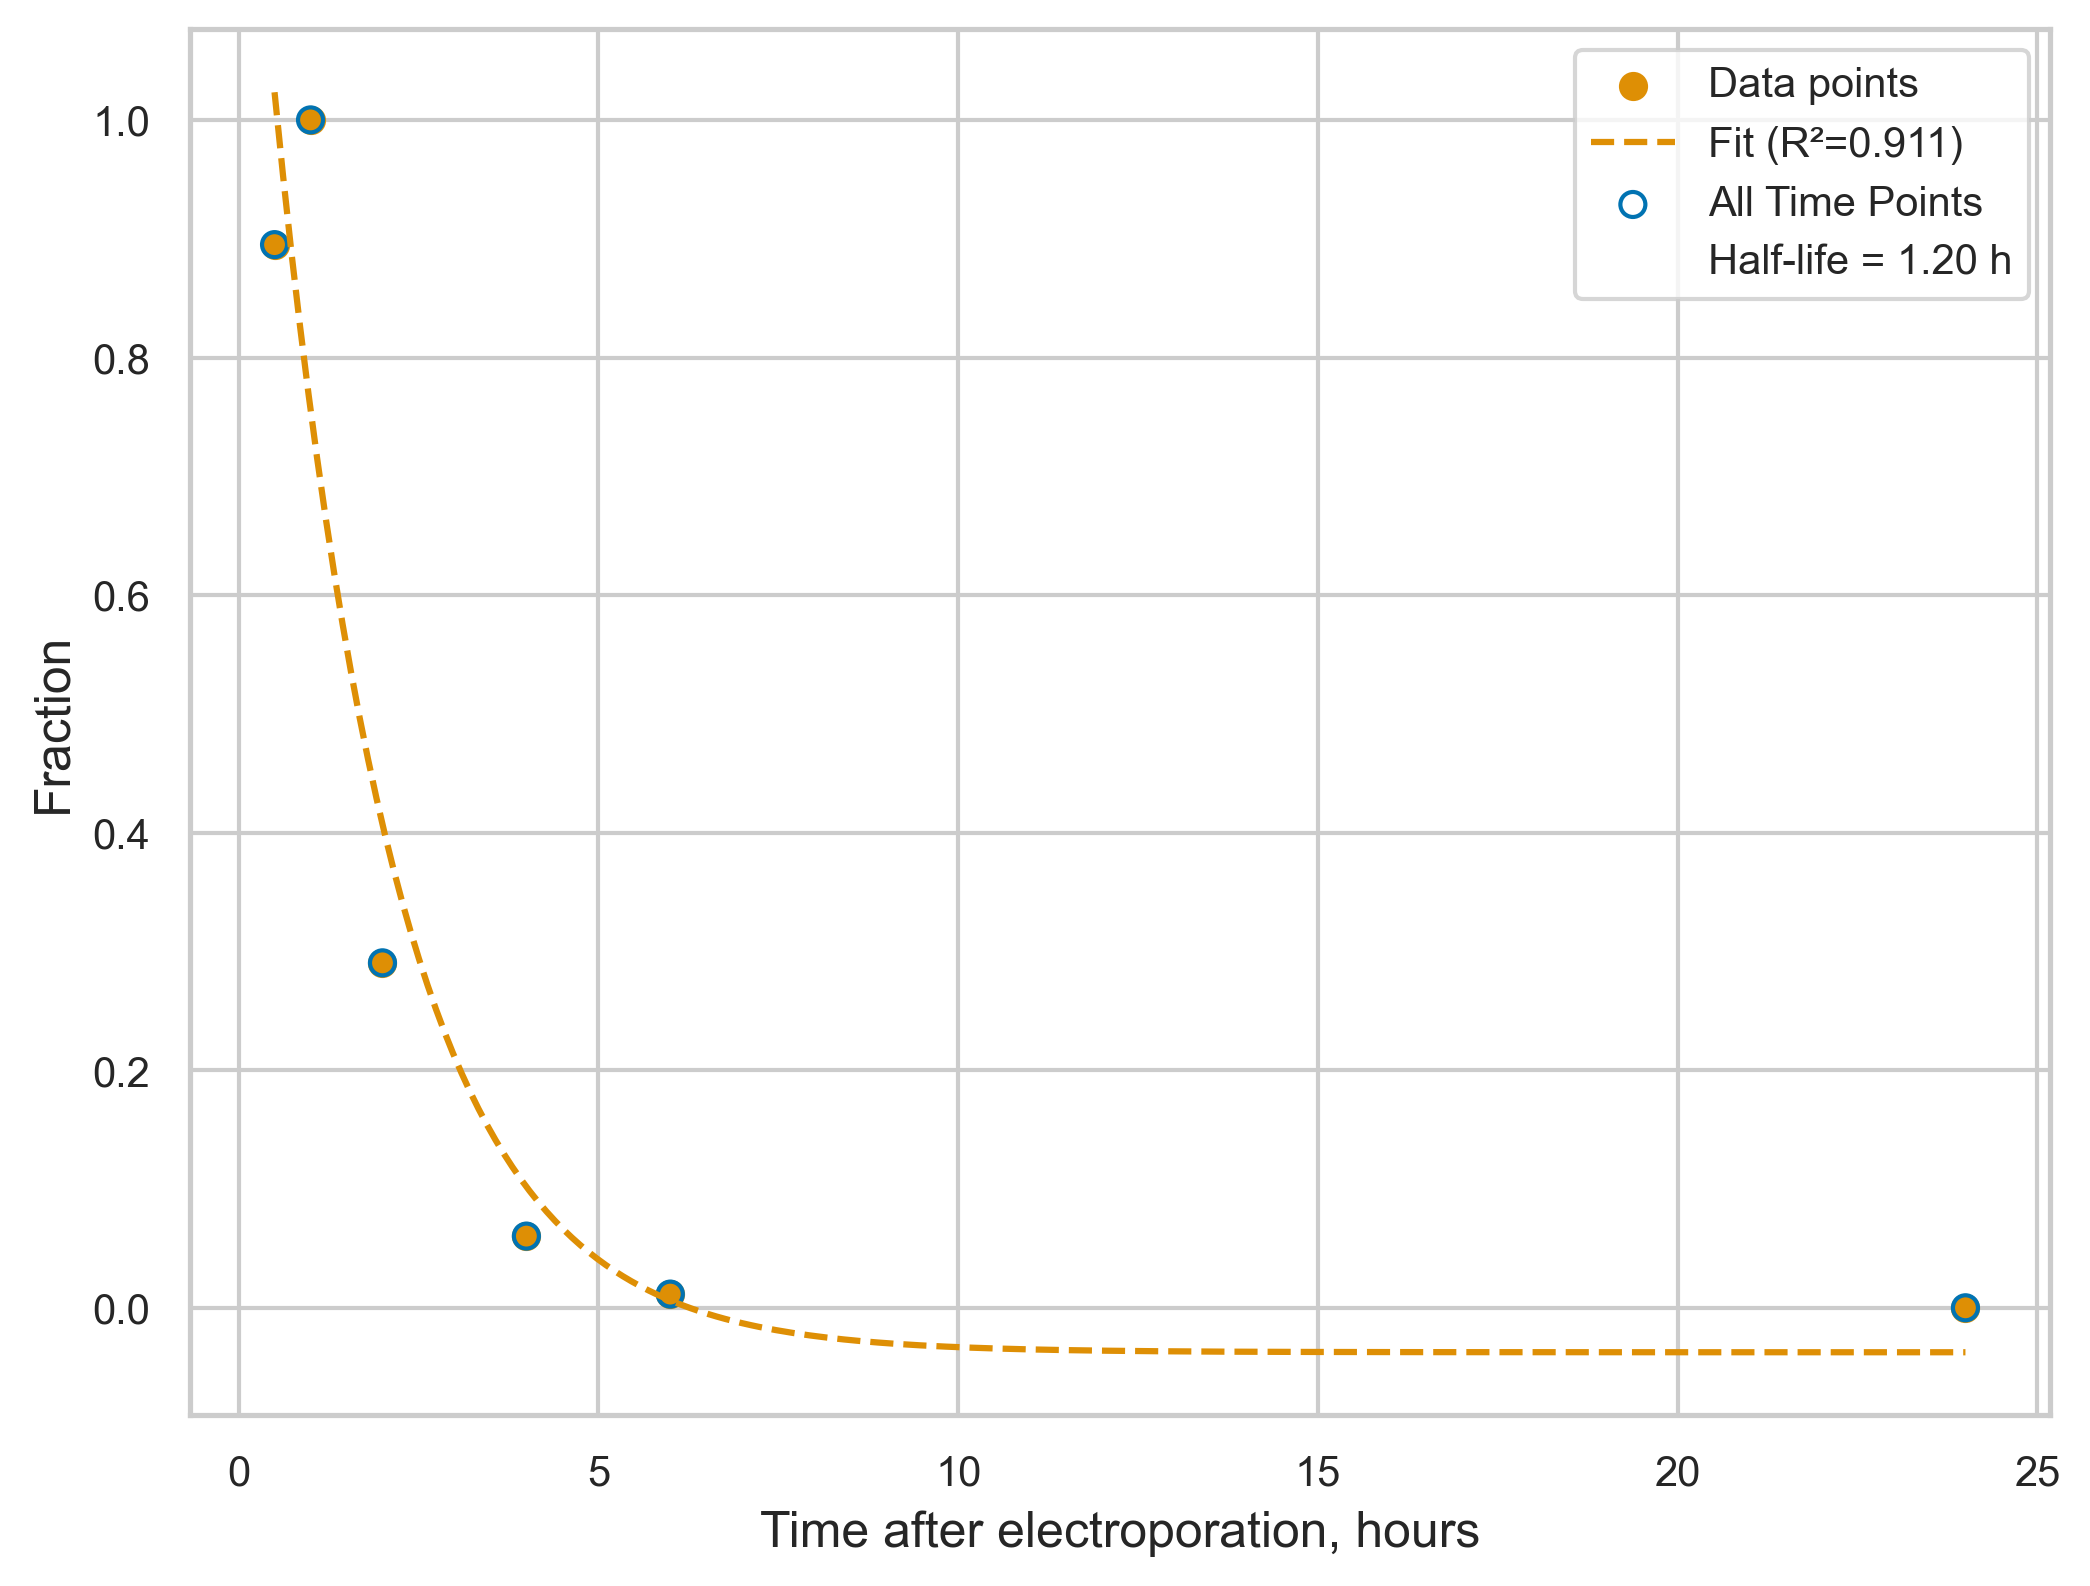

Saved: The degradation curve Init2 Run 3.tiff
y(x) = 1.7580 * exp(-0.4112 * x) + -0.0608
Half-life (b3_4): 1.6858 hours


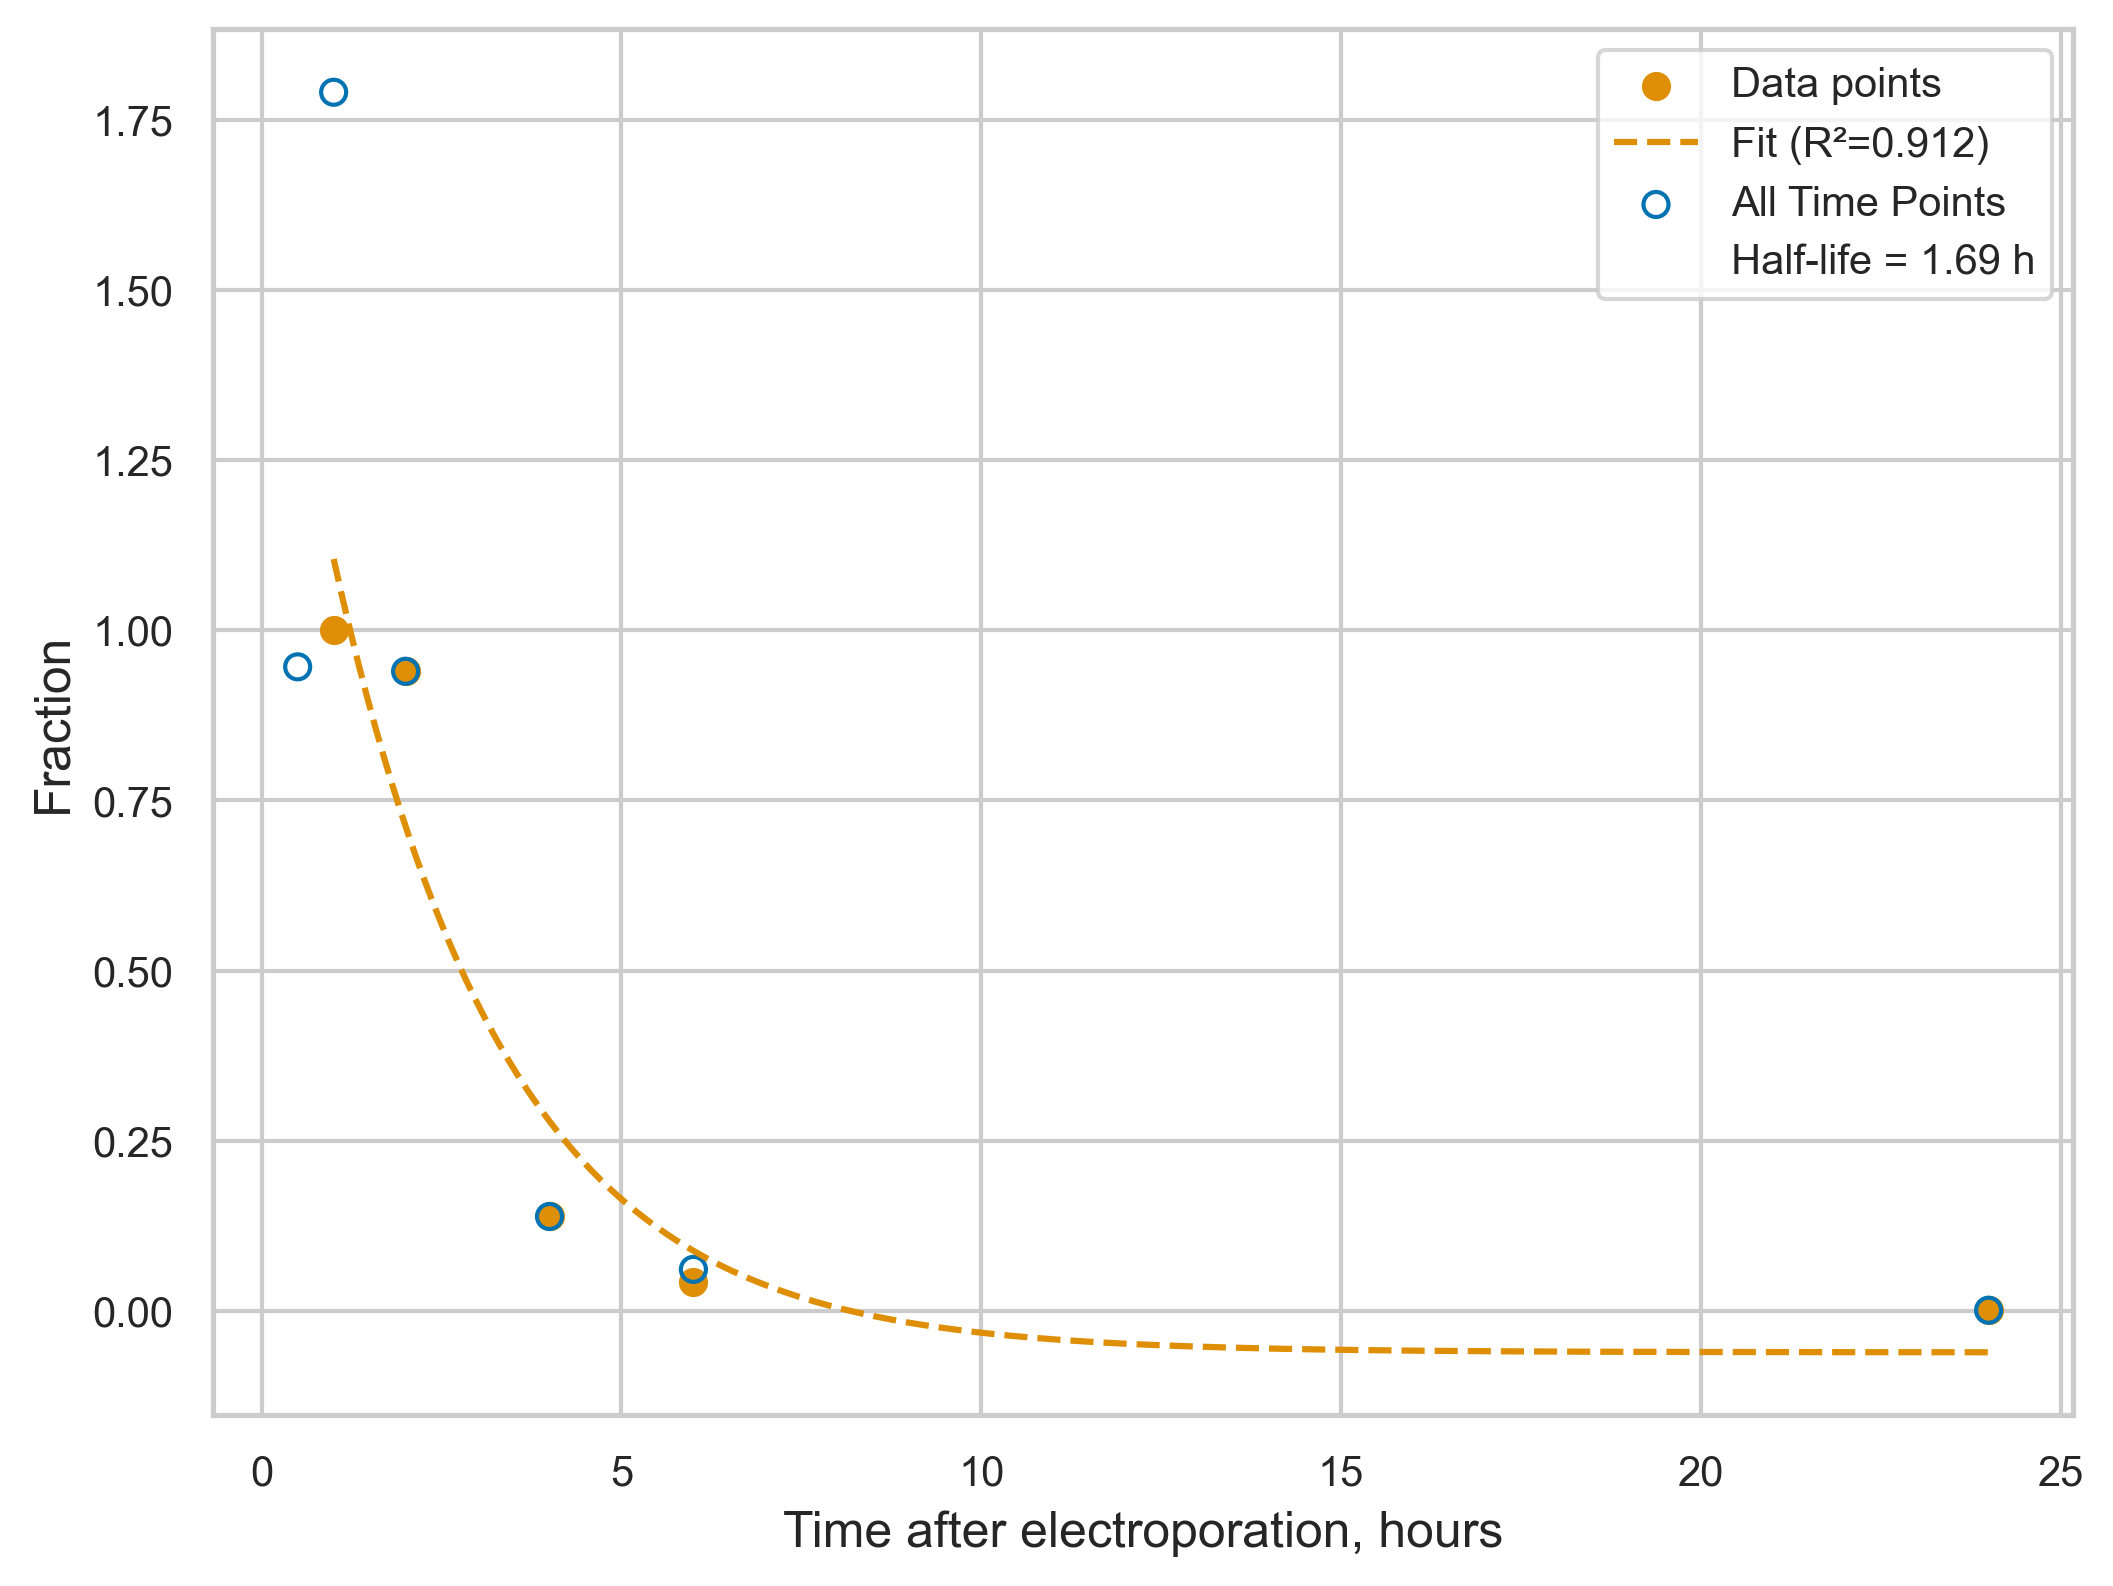

Saved: The degradation curve Init2 Run 4.tiff


In [57]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
import math
import seaborn as sns
import matplotlib as mpl
import string # Required for the 'A', 'B', 'C' labels if they were used

# --------------------------------------------------------------------------------------
# 🔧 GLOBAL PLOTTING CONFIGURATION
# --------------------------------------------------------------------------------------
colors = sns.color_palette("colorblind")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 10,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

# --------------------------------------------------------------------------------------
# CORE FUNCTIONS (Necessary to remain as defined)
# --------------------------------------------------------------------------------------

def calculate_half_life(params):
    """Calculate half-life for y(x) = a * exp(-b * x) + c"""
    b = params[1]
    if b <= 0: return np.nan
    return math.log(2) / b

def fit_exponential_decay(x_data, y_data):
    """Fits y(x) = a * exp(-b * x) + c and calculates R^2."""
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)

    def exp_decay(x, a, b, c):
        return a * np.exp(-b * x) + c

    initial_guess = [max(y_data), 0.3, min(y_data)]
    params, _ = curve_fit(exp_decay, x_data, y_data, p0=initial_guess, maxfev=5000)
    a, b, c = params
    y_pred = exp_decay(x_data, a, b, c)

    ss_res = np.sum((y_data - y_pred) ** 2)
    ss_tot = np.sum((y_data - np.mean(y_data)) ** 2)
    r_squared = 1 - (ss_res / ss_tot)

    return (a, b, c), lambda x: exp_decay(np.asarray(x, dtype=float), a, b, c), r_squared

def normalize_start1(y: list, divisor: float):
    """Normalizes the array by the specified hardcoded divisor."""
    y = np.asarray(y, dtype=float)
    return y / divisor
x_all_time_points = [0.5, 1, 2, 4, 6, 24]

# --------------------------------------------------------------------------------------
# DATA DEFINITIONS AND EXECUTION (Variable Management ONLY)
# --------------------------------------------------------------------------------------

# --- SYNONYMOUS CONTROL (Initial 1, Rep 1) ---
y_all_data_initial1_run1 = [0.637280313659632, 0.637280313659631, 0.624165274450806, 0.31643914849257, 0.152830034711509, 0.00106864619263744 ]
y_data_initial1_run1 = [0.624165274450806, 0.31643914849257, 0.152830034711509, 0.00106864619263744]
x_data_initial1_run1 = [2, 4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.624165274450806

y_norm_initial1_run1 = normalize_start1(y_data_initial1_run1)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial1_run1, y_norm_initial1_run1) 
x_smooth = np.linspace(min(x_data_initial1_run1), max(x_data_initial1_run1), 200)
y_fit = fitted_temp(x_smooth)

paramsb1_1 = params_temp
b1_1 = calculate_half_life(params_temp) 
print(f"y(x) = {params_temp[0]:.4f} * exp(-{params_temp[1]:.4f} * x) + {params_temp[2]:.4f}")
print(f"Half-life (b1_2): {b1_1:.4f} hours") # Original code requested printing b1_2

# --- Plot 1 ---
figb11 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial1_run1, y_norm_initial1_run1, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_initial1_run1), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b1_1:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb11, 'The degradation curve Init1 Run 1')

# --- SYNONYMOUS CONTROL (Initial 1, Rep 2) ---
y_all_data_initial1_run2 = [0.815072332402624, 0.823591017267572, 0.823591017267572, 0.447512535463986, 0.179244406001978, 0.000605326025360834]
y_data_initial1_run2 = [0.823591017267572, 0.447512535463986, 0.179244406001978, 0.000605326025360834]
x_data_initial1_run2 = [2, 4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.823591017267572

y_norm_initial1_run2 = normalize_start1(y_data_initial1_run2)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial1_run2, y_norm_initial1_run2)
x_smooth = np.linspace(min(x_data_initial1_run2), max(x_data_initial1_run2), 200)
y_fit = fitted_temp(x_smooth)

paramsb1_2 = params_temp
b1_2 = calculate_half_life(paramsb1_2)
print(f"y(x) = {paramsb1_2[0]:.4f} * exp(-{paramsb1_2[1]:.4f} * x) + {paramsb1_2[2]:.4f}")
print(f"Half-life (b1_3): {b1_2:.4f} hours")

# --- Plot 2 ---
figb12 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial1_run2, y_norm_initial1_run2, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_initial1_run2), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b1_2:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb12, 'The degradation curve Init1 Run 2')

# --- SYNONYMOUS CONTROL (Initial 1, Rep 3) ---
y_all_data_initial1_run3 = [0.870550563296123, 0.435275281648062, 0.5664419426479, 0.272626933166314, 0.0631532154054228, 0.000510783662008072]
y_data_initial1_run3 = [0.870550563296123, 0.5664419426479, 0.272626933166314, 0.0631532154054228, 0.000510783662008072]
x_data_initial1_run3 = [0.5, 2, 4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.870550563296123

y_norm_initial1_run3 = normalize_start1(y_data_initial1_run3)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial1_run3, y_norm_initial1_run3)
x_smooth = np.linspace(min(x_data_initial1_run3), max(x_data_initial1_run3), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb1_3 = params_temp
b1_3 = calculate_half_life(paramsb1_3)
print(f"y(x) = {paramsb1_3[0]:.4f} * exp(-{paramsb1_3[1]:.4f} * x) + {paramsb1_3[2]:.4f}")
print(f"Half-life (b1_4): {b1_3:.4f} hours")

# --- Plot 3 ---
figb13 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial1_run3, y_norm_initial1_run3, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_initial1_run3), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b1_3:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb13, 'The degradation curve Init1 Run 3')

# --- OPTIMIZED GROUP (Initial 1, Rep 4) ---
y_all_data_initial1_run4 = [0.655954052218724, 1.39635586848213, 0.85362046339897, 0.554144193637624, 0.268873597614345, 0.00169050109571512]
y_data_initial1_run4 = [1.39635586848213, 0.85362046339897, 0.554144193637624, 0.21940475, 0.00169050109571512] 
x_data_initial1_run4 = [1, 2, 4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 1.39635586848213

y_norm_initial1_run4 = normalize_start1(y_data_initial1_run4)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial1_run4, y_norm_initial1_run4)
x_smooth = np.linspace(min(x_data_initial1_run4), max(x_data_initial1_run4), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb1_4 = params_temp # The original code incorrectly referenced a future variable (b2_4) here
b1_4 = calculate_half_life(paramsb1_4) # The original code incorrectly called this b1_5
print(f"y(x) = {paramsb1_4[0]:.4f} * exp(-{paramsb1_4[1]:.4f} * x) + {paramsb1_4[2]:.4f}")
print(f"Half-life (b1_5): {b1_4:.4f} hours")

# --- Plot 4 ---
figb14 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial1_run4, y_norm_initial1_run4, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_initial1_run4), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b1_4:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb14, 'The degradation curve Init1 Run 4')

# --- OPTIMIZED GROUP (Optimized 1, Rep 1) ---
y_all_data_optimized1_run1 = [0.403320879611063, 0.29833393575793, 0.272626933166314, 
                             0.113047422195136, 0.0607909342132677, 0.00038576235930829]
y_data_optimized1_run1 = [0.403320879611063, 0.29833393575793, 0.272626933166314, 
                          0.113047422195136, 0.0607909342132677, 0.00038576235930829]
x_data_optimized1_run1 = [0.5, 1, 2, 4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.403320879611063

y_norm_optimized1_run1 = normalize_start1(y_data_optimized1_run1)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_optimized1_run1, y_norm_optimized1_run1)
x_smooth = np.linspace(min(x_data_optimized1_run1), max(x_data_optimized1_run1), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb2_1 = params_temp
b2_1 = calculate_half_life(paramsb2_1)
print(f"y(x) = {paramsb2_1[0]:.4f} * exp(-{paramsb2_1[1]:.4f} * x) + {paramsb2_1[2]:.4f}")
print(f"Half-life (b2_1): {b2_1:.4f} hours")

# --- Plot 5 ---
figb21 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_optimized1_run1, y_norm_optimized1_run1, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_optimized1_run1), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b2_1:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb21, 'The degradation curve Optim1 Run 1')

# --- OPTIMIZED GROUP (Optimized 1, Rep 2) ---
y_all_data_optimized1_run2 = [0.659753955386446,0.505225723243382,0.79553648375492,0.506979739895014, 0.240648610775437,0.000653284938860405]
y_data_optimized1_run2 = [0.79553648375492, 0.506979739895014, 0.240648610775437, 0.000653284938860405]
x_data_optimized1_run2 = [2, 4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.79553648375492

y_norm_optimized1_run2 = normalize_start1(y_data_optimized1_run2)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_optimized1_run2, y_norm_optimized1_run2)
x_smooth = np.linspace(min(x_data_optimized1_run2), max(x_data_optimized1_run2), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb2_2 = params_temp
b2_2 = calculate_half_life(paramsb2_2)
print(f"y(x) = {paramsb2_2[0]:.4f} * exp(-{paramsb2_2[1]:.4f} * x) + {paramsb2_2[2]:.4f}")
print(f"Half-life (b2_2): {b2_2:.4f} hours")

# --- Plot 6 ---
figb22 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_optimized1_run2, y_norm_optimized1_run2, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_optimized1_run2), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b2_2:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb22, 'The degradation curve Optim1 Run 2')


# --- OPTIMIZED GROUP (Optimized 1, Rep 3) ---
y_all_data_optimized1_run3 = [0.0920354411312829, 0.14525569836973, 0.228194090075466, 0.583039958496167, 0.335255599438358, 0.000412972499331762]
y_data_optimized1_run3 = [0.583039958496167, 0.335255599438358, 0.000412972499331762]
x_data_optimized1_run3 = [4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.583039958496167

y_norm_optimized1_run3 = normalize_start1(y_data_optimized1_run3)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_optimized1_run3, y_norm_optimized1_run3)
x_smooth = np.linspace(min(x_data_optimized1_run3), max(x_data_optimized1_run3), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb2_3 = params_temp 
b2_3 = calculate_half_life(paramsb2_3)
print(f"y(x) = {paramsb2_3[0]:.4f} * exp(-{paramsb2_3[1]:.4f} * x) + {paramsb2_3[2]:.4f}")
print(f"Half-life (b2_4): {b2_3:.4f} hours")

# --- Plot 7 ---
figb23 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_optimized1_run3, y_norm_optimized1_run3, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_optimized1_run3), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b2_3:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb23, 'The degradation curve Optim1 Run 3')


# --- OPTIMIZED GROUP (Optimized 1, Rep 4) ---
y_all_data_optimized1_run4 = [1.45902034424018, 1.76133174719229, 0.698984967, 0.487452428, 0.204003621, 0.00163103109263353]
y_data_optimized1_run4 = [ 0.698984967, 0.487452428, 0.204003621, 0.00163103109263353]
x_data_optimized1_run4 = [ 2, 4, 6, 24]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.698984967

y_norm_optimized1_run4 = normalize_start1(y_data_optimized1_run4)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_optimized1_run4, y_norm_optimized1_run4)
x_smooth = np.linspace(min(x_data_optimized1_run4), max(x_data_optimized1_run4), 200)
y_fit = fitted_temp(x_smooth)

paramsb2_4 = params_temp
b2_4 = calculate_half_life(params_temp)
print(f"y(x) = {paramsb2_4[0]:.4f} * exp(-{paramsb2_4[1]:.4f} * x) + {paramsb2_4[2]:.4f}")
print(f"Half-life (b2_5): {b2_4:.4f} hours")

# --- Plot 8 ---
figb24 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_optimized1_run4, y_norm_optimized1_run4, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_optimized1_run4), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b2_4:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb24, 'The degradation curve Optim1 Run 4')


# --- NON-SYNONYMOUS CONTROL (Initial 2, Rep 1) ---
y_data_initial2_run1 = [1.29683955465101, 0.809442216547409, 0.205185402202625, 0.134903529563053]
x_data_initial2_run1 = [0.5, 1, 4, 6]
y_all_data_initial2_run1 = [1.29683955465101, 0.809442216547409, 0.00198726502363806, 0.205185402202625, 0.134903529563053, 1.62450479271247]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 1.29683955465101

y_norm_initial2_run1 = normalize_start1(y_data_initial2_run1)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial2_run1, y_norm_initial2_run1)
x_smooth = np.linspace(min(x_data_initial2_run1), max(x_data_initial2_run1), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb3_1 = params_temp
b3_1 = calculate_half_life(paramsb3_1)
print(f"y(x) = {paramsb3_1[0]:.4f} * exp(-{paramsb3_1[1]:.4f} * x) + {paramsb3_1[2]:.4f}")
print(f"Half-life (b3_1): {b3_1:.4f} hours")

# --- Plot 9 ---
figb31 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial2_run1, y_norm_initial2_run1, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_initial2_run1), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b3_1:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb31, 'The degradation curve Init2 Run 1')

# --- NON-SYNONYMOUS CONTROL (Initial 2, Rep 2) ---
y_all_time_points_initial2_run2 = [0.225573057, 0.866537046, 0.808507652159862, 0.183010711993203, 0.0803068391284266, 0.000940033635841557]
x_data_initial2_run2 = [2, 4, 6, 24]
y_data_initial2_run2 = [0.808507652159862, 0.183010711993203, 0.0803068391284266, 0.000940033635841557]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 0.808507652159862

y_norm_initial2_run2 = normalize_start1(y_data_initial2_run2)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial2_run2, y_norm_initial2_run2)
x_smooth = np.linspace(min(x_data_initial2_run2), max(x_data_initial2_run2), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb3_2 = params_temp
b3_2 = calculate_half_life(paramsb3_2)
print(f"y(x) = {paramsb3_2[0]:.4f} * exp(-{paramsb3_2[1]:.4f} * x) + {paramsb3_2[2]:.4f}")
print(f"Half-life (b3_2): {b3_2:.4f} hours")

# --- Plot 10 ---
figb32 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial2_run2, y_norm_initial2_run2, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_time_points_initial2_run2), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b3_2:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb32, 'The degradation curve Init2 Run 2')

# --- NON-SYNONYMOUS CONTROL (Initial 2, Rep 3) ---
y_all_data_initial2_run3 = [1.95657896, 2.186060507, 0.635075491, 0.132279983, 0.025559439, 0.000380451]
x_data_initial2_run3 = [0.5, 1, 2, 4, 6 ,24]
y_data_initial2_run3 = [1.95657896, 2.186060507, 0.635075491, 0.132279983, 0.025559439, 0.000380451]

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 2.186060507

y_norm_initial2_run3 = normalize_start1(y_data_initial2_run3)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial2_run3, y_norm_initial2_run3)
x_smooth = np.linspace(min(x_data_initial2_run3), max(x_data_initial2_run3), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb3_3 = params_temp
b3_3 = calculate_half_life(paramsb3_3)
print(f"y(x) = {paramsb3_3[0]:.4f} * exp(-{paramsb3_3[1]:.4f} * x) + {paramsb3_3[2]:.4f}")
print(f"Half-life (b3_3): {b3_3:.4f} hours")

# --- Plot 11 ---
figb33 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial2_run3, y_norm_initial2_run3, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_initial2_run3), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b3_3:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb33, 'The degradation curve Init2 Run 3')

# --- NON-SYNONYMOUS CONTROL (Initial 2, Rep 4) ---
y_all_data_initial2_run4 = [1.65290063630842, 3.12747857251437, 1.64148321762099, 0.242322454233767, 0.106579361470994, 0.00179724150512671]
x_data_initial2_run1 = [1, 2, 4, 6 ,24]
y_data_initial2_run1 = [1.747145792, 1.641483218, 0.242322454, 0.075450102, 0.001797242] 

# Normalization function (start at 1)
def normalize_start1(y):
    y = np.asarray(y, dtype=float)
    return y / 1.747145792

y_norm_initial2_run4 = normalize_start1(y_data_initial2_run1)

# Store results for this run as params_temp, fitted_temp, r2_temp
(params_temp, fitted_temp, r2) = fit_exponential_decay(x_data_initial2_run1, y_norm_initial2_run4)
x_smooth = np.linspace(min(x_data_initial2_run1), max(x_data_initial2_run1), 200)
y_fit = fitted_temp(x_smooth)

# FIX: Define the required variables using the current run's results
paramsb3_4 = params_temp
b3_4 = calculate_half_life(paramsb3_4)
print(f"y(x) = {paramsb3_4[0]:.4f} * exp(-{paramsb3_4[1]:.4f} * x) + {paramsb3_4[2]:.4f}")
print(f"Half-life (b3_4): {b3_4:.4f} hours")

# --- Plot 12 ---
figb34 = plt.figure(figsize=(8, 6))
plt.scatter(x_data_initial2_run1, y_norm_initial2_run4, color=colors[1], label="Data points")
plt.plot(x_smooth, y_fit, color=colors[1], linestyle="--", label=f"Fit (R²={r2:.3f})")
plt.scatter(x_all_time_points, normalize_start1(y_all_data_initial2_run4), facecolors='none', edgecolors=colors[0], label="All Time Points ")
plt.plot([], [], ' ', label=f"Half-life = {b3_4:.2f} h")
plt.xlabel("Time after electroporation, hours")
plt.ylabel("Fraction")
plt.legend()
plt.show()
save_tiff(figb34, 'The degradation curve Init2 Run 4')


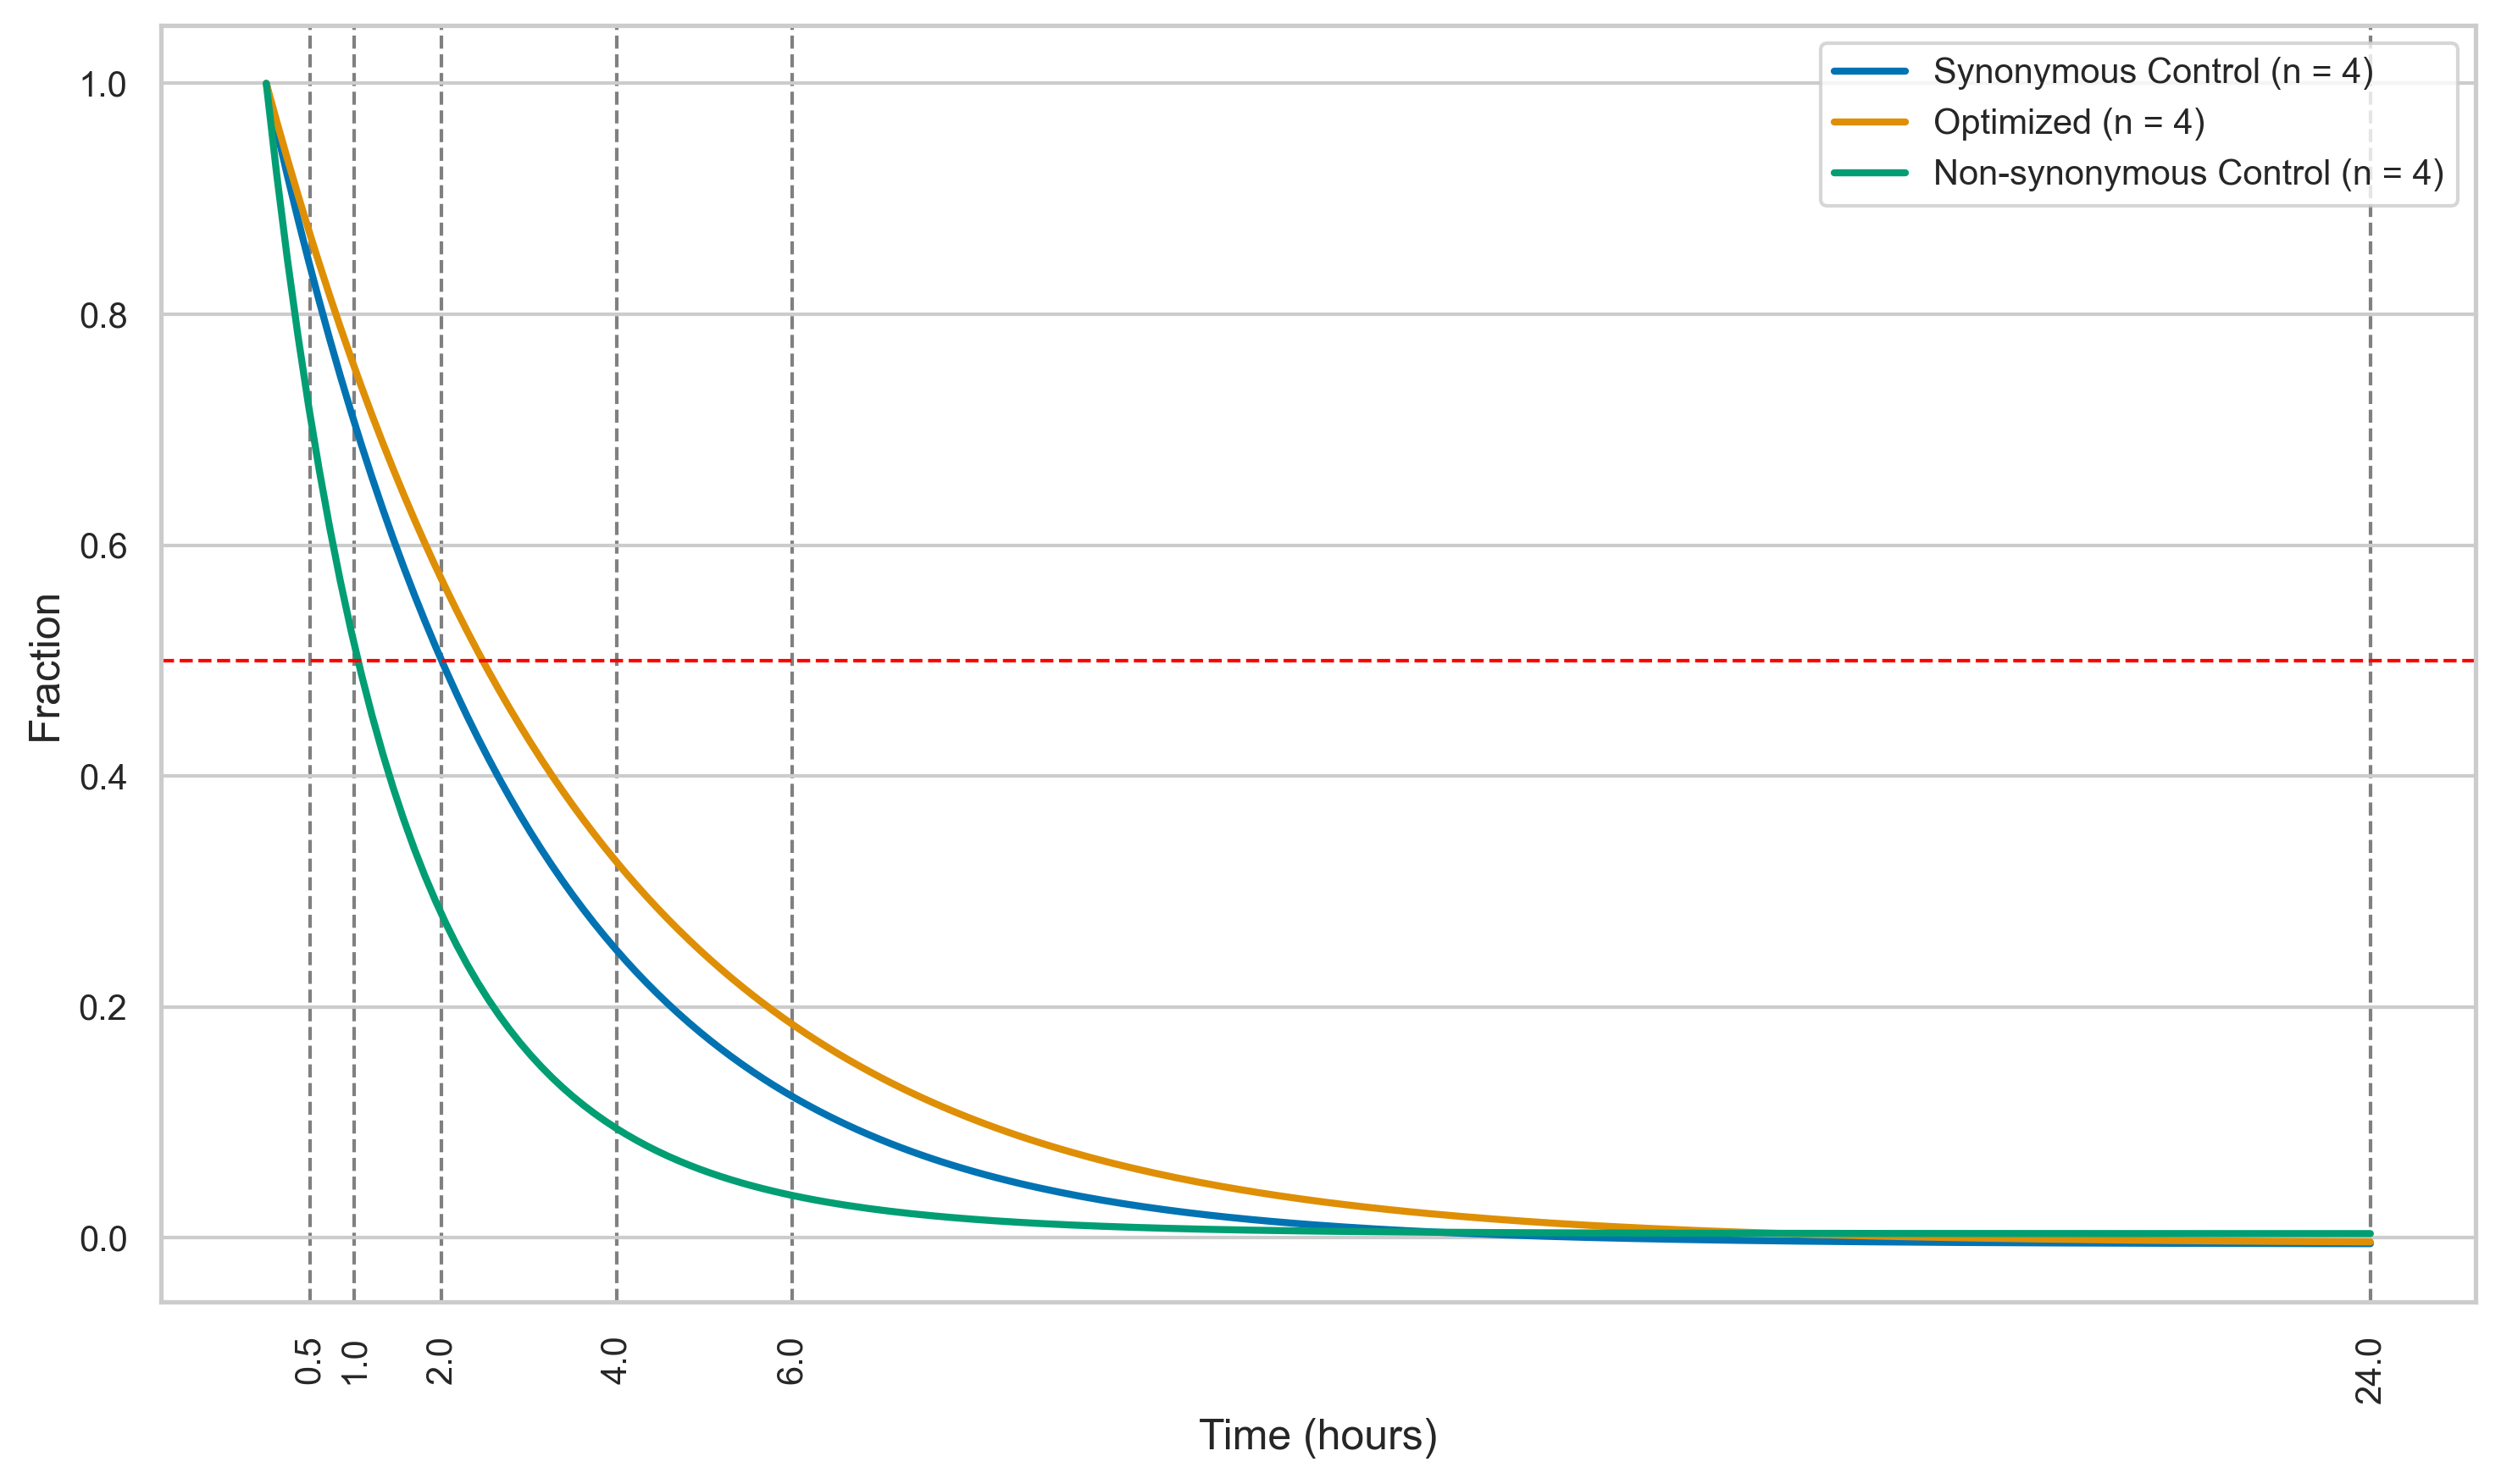

Saved: The degradation curves.tiff


In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Smooth time range
time_points = np.linspace(0, 24, 200)
colors = sns.color_palette('colorblind')
# Example parameter sets (replace with your actual values)
syncontrol = [paramsb1_1, paramsb1_2, paramsb1_3, paramsb1_4]
nonsyncontrol = [paramsb3_1, paramsb3_2, paramsb3_3, paramsb3_4]
test = [paramsb2_1, paramsb2_2, paramsb2_3, paramsb2_4]

# Normalized function
def normalized_y(A, k, C, x):
    return (A * np.exp(-k * x) + C) / (A + C)

# Compute smooth mean values for each group
control_values = np.array([[normalized_y(A, k, C, t) for t in time_points] for A, k, C in syncontrol])
test_values = np.array([[normalized_y(A, k, C, t) for t in time_points] for A, k, C in test])
nonsyn_values = np.array([[normalized_y(A, k, C, t) for t in time_points] for A, k, C in nonsyncontrol])

# Compute mean curve for each group
control_mean = control_values.mean(axis=0)
test_mean = test_values.mean(axis=0)
nonsyn_mean = nonsyn_values.mean(axis=0)

# Plot smooth curves (no shading)
fig = plt.figure(figsize=(10, 6))

plt.plot(time_points, control_mean, label='Synonymous Control (n = 4)', color=colors[0], linewidth=2)
plt.plot(time_points, test_mean, label='Optimized (n = 4)', color=colors[1], linewidth=2)
plt.plot(time_points, nonsyn_mean, label='Non-synonymous Control (n = 4)', color=colors[2], linewidth=2)

# Custom grid: specific x-values
custom_x = [0.5, 1, 2, 4, 6, 24]
plt.xticks(custom_x, rotation = 90)  # Only show these x-values
plt.grid(axis='x', linestyle='--', color='gray', alpha=1, linewidth=1)  # Grid only for x-axis

# Add a horizontal line at y = 0.5 (example)
plt.axhline(y=0.5, color='red', linestyle='--', linewidth=1)

plt.xlabel('Time (hours)')
plt.ylabel('Fraction')
#plt.title('Decay Curves of mRNA constructs')
plt.legend()
plt.tight_layout()
plt.show()
save_tiff(fig, 'The degradation curves')

Group 1: [np.float64(2.0030685241072366), np.float64(2.0414116543589698), np.float64(2.06679883342731), np.float64(1.9517956989511547)]
Group 2: [np.float64(2.149976601630801), np.float64(2.5974180524008164), np.float64(2.516446292832619), np.float64(2.732485478989708)]
U-stat: 0.0000, p-value: 0.01429
Group 1: [np.float64(2.0030685241072366), np.float64(2.0414116543589698), np.float64(2.06679883342731), np.float64(1.9517956989511547)]
Group 2: [np.float64(0.6356184415659061), np.float64(0.9304090417967108), np.float64(1.1951508818264456), np.float64(1.685784339121174)]
U-stat: 16.0000, p-value: 0.02857
Group 1: [np.float64(0.6356184415659061), np.float64(0.9304090417967108), np.float64(1.1951508818264456), np.float64(1.685784339121174)]
Group 2: [np.float64(2.149976601630801), np.float64(2.5974180524008164), np.float64(2.516446292832619), np.float64(2.732485478989708)]
U-stat: 0.0000, p-value: 0.01429
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p

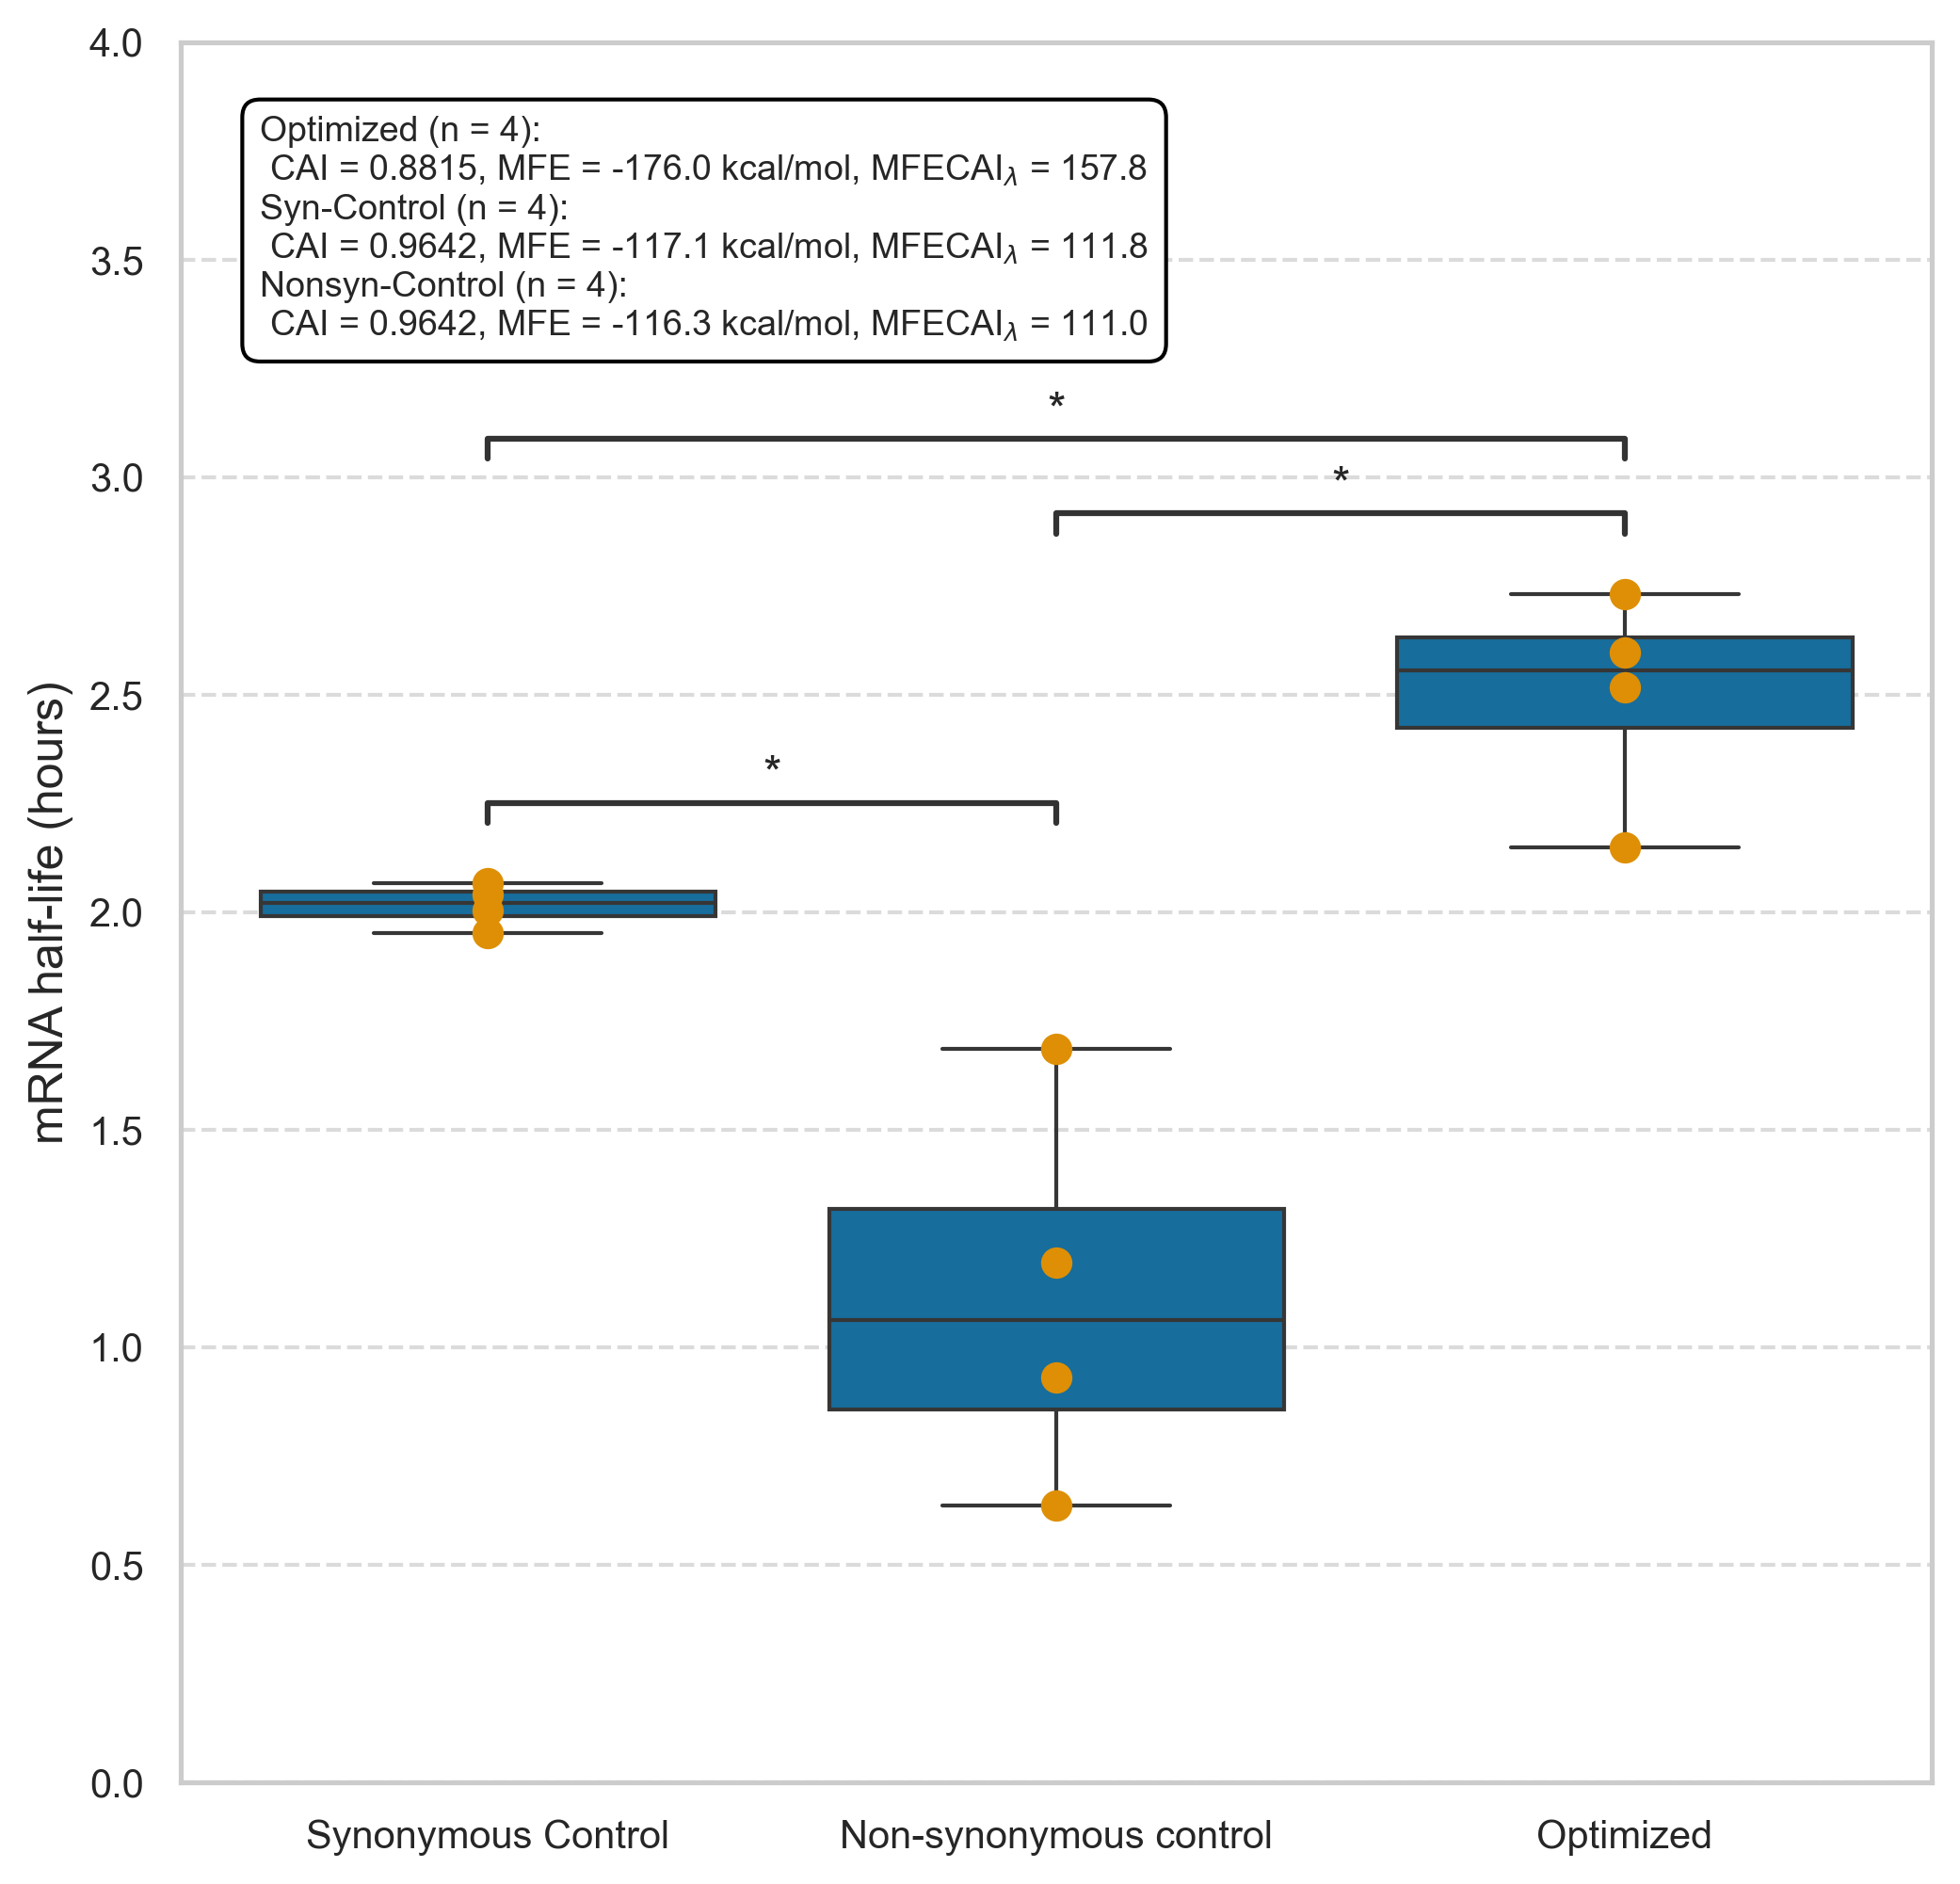

Saved: Degradation times comparison.tiff


In [22]:
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statannotations.Annotator import Annotator
import seaborn as sns
import pandas as pd
colors = sns.color_palette("colorblind")
# Example data
syn = [b1_1, b1_2, b1_3, b1_4] 
nonsyn = [b3_1, b3_2, b3_3, b3_4]
optimized = [b2_1, b2_2, b2_3, b2_4]

# Create DataFrame
data = pd.DataFrame({
    "Group": ["Synonymous Control"] * len(syn) +
             ["Non-synonymous control"] * len(nonsyn) +
             ["Optimized"] * len(optimized),
    "Half-life": syn + nonsyn + optimized
})

pairs = [
    ("Synonymous Control", "Optimized"),
    ("Synonymous Control", "Non-synonymous control"),
    ("Optimized", "Non-synonymous control")
]

# Mann-Whitney U test function
def mann_whitney(g1, g2, alternative="less"):
    stat, p_value = mannwhitneyu(g1, g2, alternative=alternative)
    print(f"Group 1: {g1}\nGroup 2: {g2}\nU-stat: {stat:.4f}, p-value: {p_value:.4g}")
    return p_value

# Map p-values to stars
def p_to_star(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# Compute p-values and stars for all pairs
p_values = [
    mann_whitney(syn, optimized, alternative="less"),
    mann_whitney(syn, nonsyn, alternative='two-sided'),
    mann_whitney(nonsyn, optimized, alternative='less')
]

custom_annotations = [p_to_star(p) for p in p_values]

# Plot
fig, ax = plt.subplots(figsize=(8, 8))
sns.boxplot(x="Group", y="Half-life", data=data, color=colors[0], ax=ax)
sns.stripplot(
    x="Group", y="Half-life", data=data, ax=ax,
    color=colors[1],       # color of points
    edgecolor="black",   # black border
    size=8,              # point size
    jitter=False,          # small horizontal jitter for visibility
    dodge=False
)
results_text = (
    "Optimized (n = 4):\n CAI = 0.8815, MFE = -176.0 kcal/mol, MFECAI$_{\lambda}$ = 157.8\n"
    "Syn-Control (n = 4):\n CAI = 0.9642, MFE = -117.1 kcal/mol, MFECAI$_{\lambda}$ = 111.8\n"
    "Nonsyn-Control (n = 4):\n CAI = 0.9642, MFE = -116.3 kcal/mol, MFECAI$_{\lambda}$ = 111.0"
)

annotator = Annotator(ax, pairs, data=data, x="Group", y="Half-life")
annotator.set_custom_annotations(custom_annotations)
annotator.annotate()

fig.text(
    0.16, 0.75, results_text, fontsize=9,
    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.5")
)

ax.set_ylabel('mRNA half-life (hours)')
ax.set_xlabel('')
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, 4)
plt.show()
save_tiff(fig, 'Degradation times comparison')

C:\Users\admin\AppData\Local\Temp\ipykernel_32284\168438283.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Group", y="Value", data=df, ax=ax, palette={


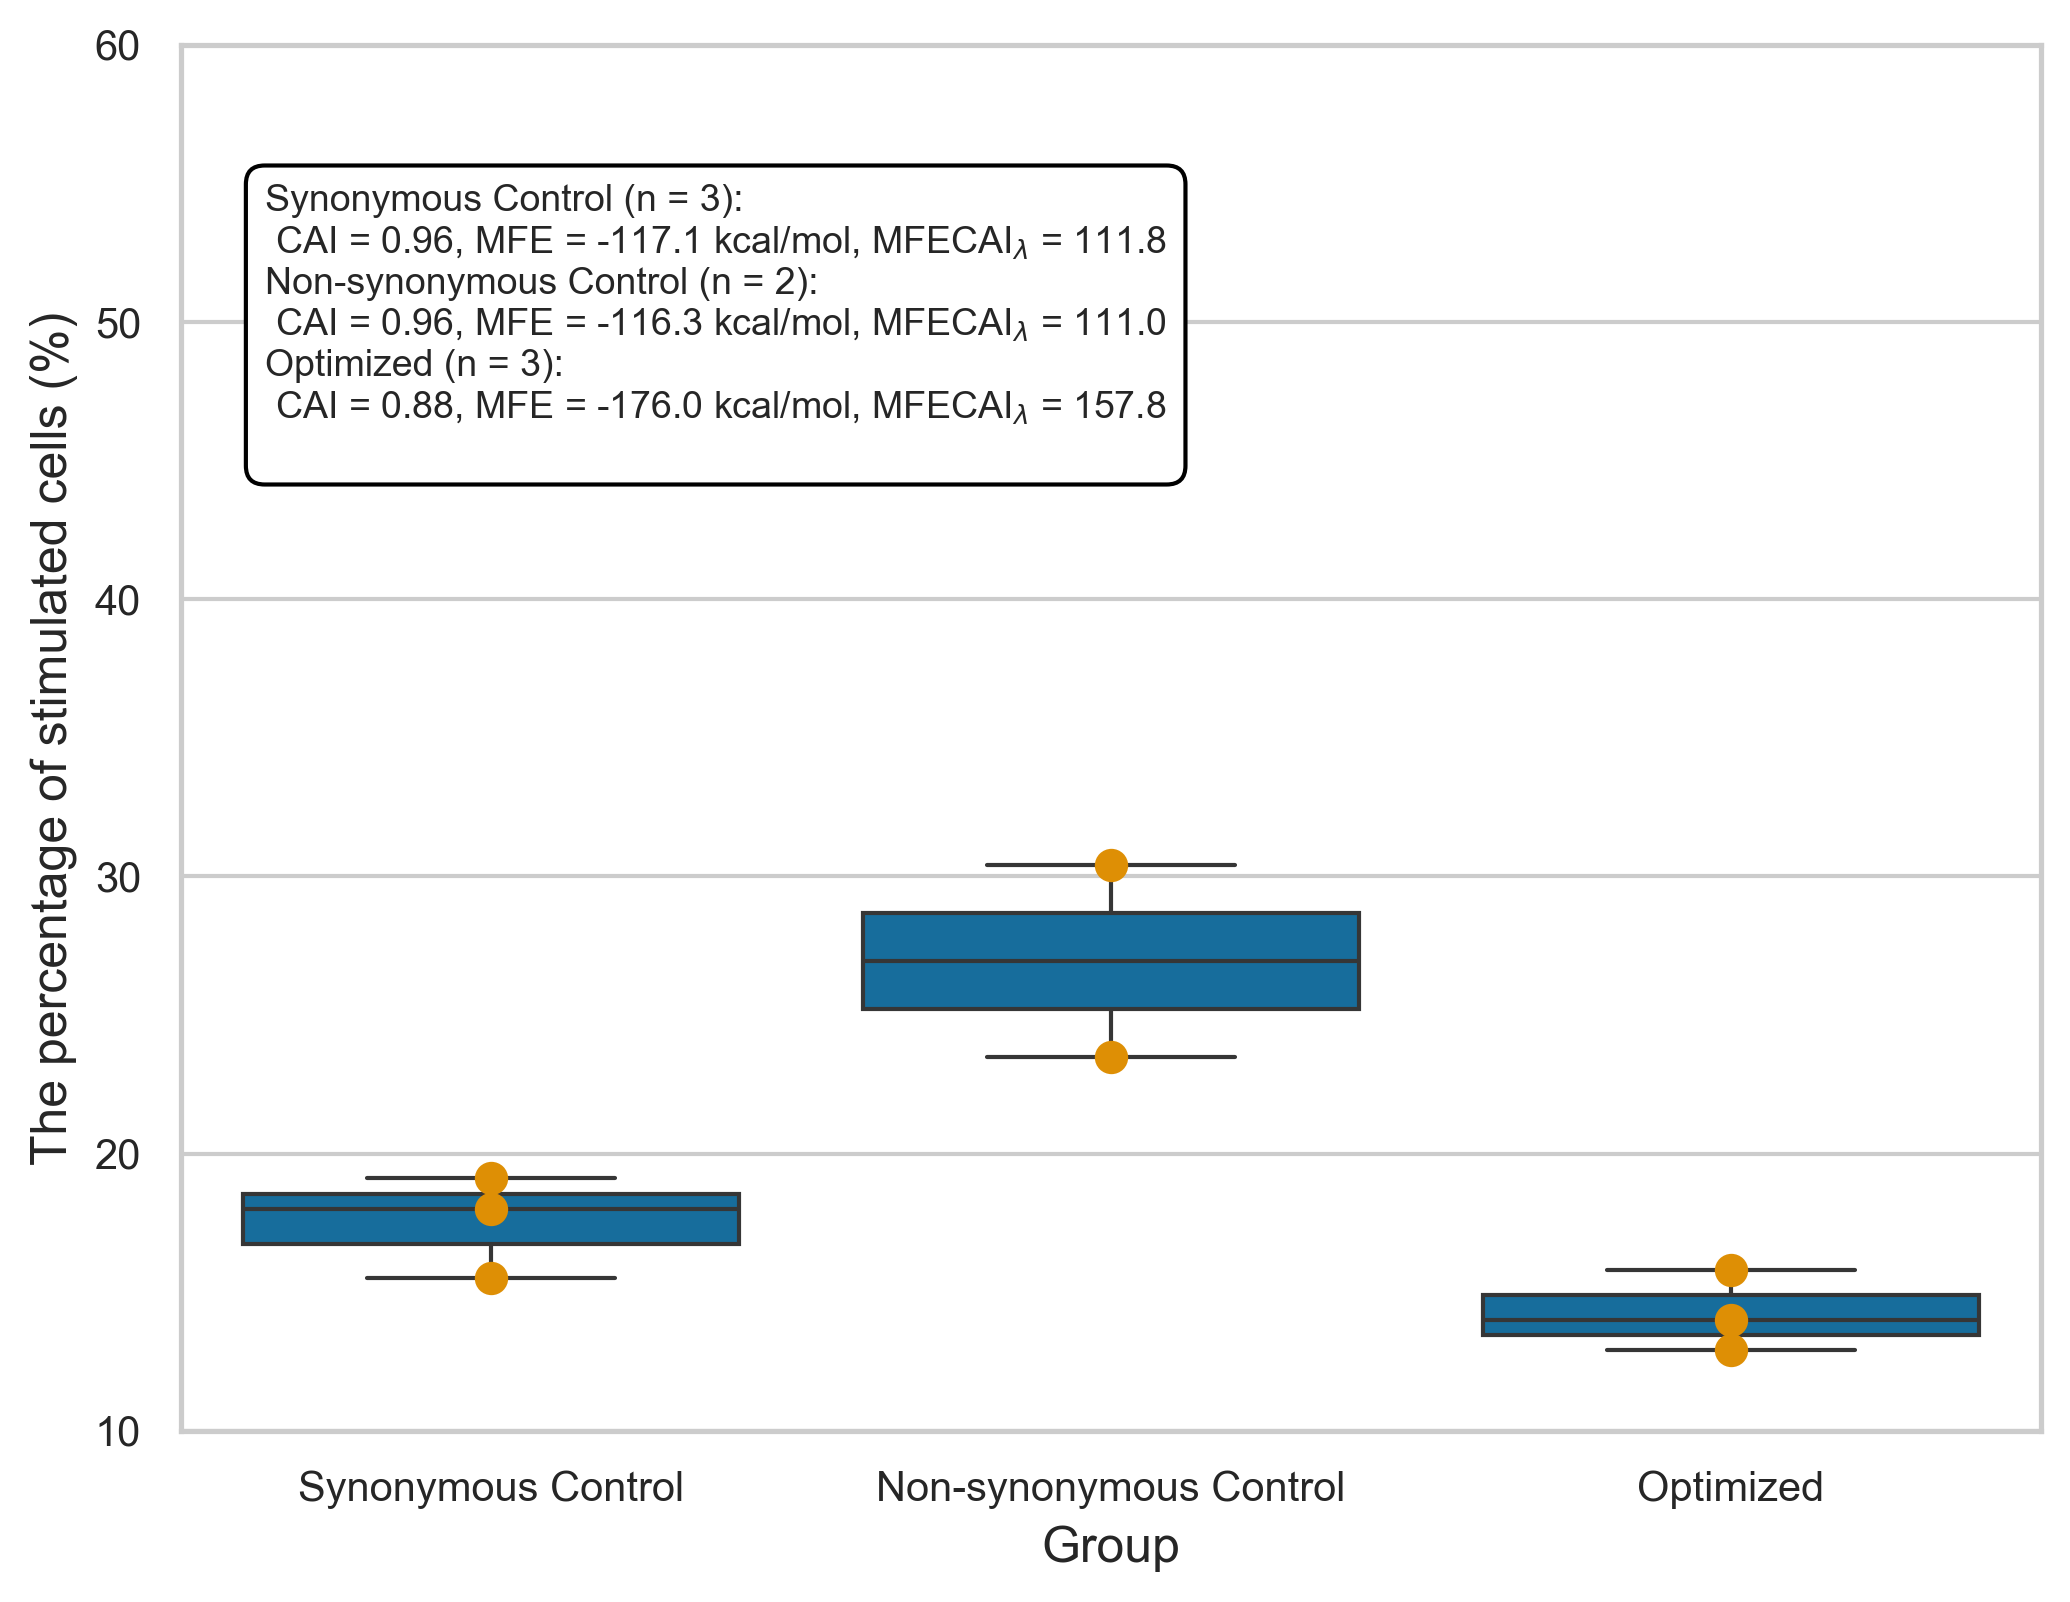

Saved: The activation of T cells comparison.tiff


In [23]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu
import numpy as np
colors = sns.color_palette("colorblind")
# Data
optim = np.array([14.0, 15.8, 12.9])
syn = np.array([18.0, 19.1, 15.5])
nonsyn = np.array([23.5, 30.4])
results_text = (
    "Synonymous Control (n = 3):\n CAI = 0.96, MFE = -117.1 kcal/mol, MFECAI$_{\lambda}$ = 111.8\n"
    "Non-synonymous Control (n = 2):\n CAI = 0.96, MFE = -116.3 kcal/mol, MFECAI$_{\lambda}$ = 111.0\n"
    "Optimized (n = 3):\n CAI = 0.88, MFE = -176.0 kcal/mol, MFECAI$_{\lambda}$ = 157.8\n"
)
# Prepare DataFrame for Seaborn
flat_data = np.concatenate([syn, nonsyn, optim])
groups = (["Synonymous Control"] * len(syn) +
          ["Non-synonymous Control"] * len(nonsyn) +
          ["Optimized"] * len(optim))
df = pd.DataFrame({"Group": groups, "Value": flat_data})

# Labels for Annotator
pairs = [
    ("Synonymous Control", "Optimized"),
    ("Synonymous Control", "Non-synonymous Control"),
    ("Optimized", "Non-synonymous Control")
]

# Mann-Whitney U test
def mann_whitney(g1, g2):
    stat, p = mannwhitneyu(g1, g2, alternative="two-sided")
    return p

def p_to_star(p):
    if p < 0.0001: return "****"
    elif p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return "ns"

p_values = [
    mann_whitney(syn, optim),
    mann_whitney(syn, nonsyn),
    mann_whitney(optim, nonsyn)
]
custom_annotations = [p_to_star(p) for p in p_values]

# --- Plot with Seaborn ---
fig, ax = plt.subplots(figsize=(8,6))
fig.text(
    0.16, 0.65, results_text, fontsize=9,
    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.5")
)
sns.boxplot(x="Group", y="Value", data=df, ax=ax, palette={
        "Synonymous Control": colors[0],
        "Non-synonymous Control": colors[0],
        "Optimized": colors[0]
    })
sns.stripplot(
    x="Group", y="Value", data=df, ax=ax,
    color=colors[1],       # color of points
    edgecolor="black",   # black border
    size=8,              # point size
    jitter=False,          # small horizontal jitter for visibility
    dodge=False
)
ax.set_ylabel("The percentage of stimulated cells (%)")
#ax.set_title("Stimulation experiment results")
plt.ylim(10, 60)

# --- Annotate ---
#annotator = Annotator(ax, pairs, data=df, x="Group", y="Value")
#annotator.set_custom_annotations(custom_annotations)
#annotator.annotate()

plt.show()
save_tiff(fig, 'The activation of T cells comparison')

Then we decided to study how the RinforSeqPipe competes against LinearDesgin Algorithm. For ReifnorSeqPipe it wasdecided to do training for 20 episodes (based on previous findings). THe comparison was done based on codon weights of LienarDesign paper to avoid modifications of LinearDesign code. The comaprison was done at three different lambda values (1, 4 and 10) as three different scenarios. Lambda eqauls 1 is MFE-biased strategy; lambda equals 4 is Balanced strategy; and lambda equals 10 is CAI-biased strategy. 

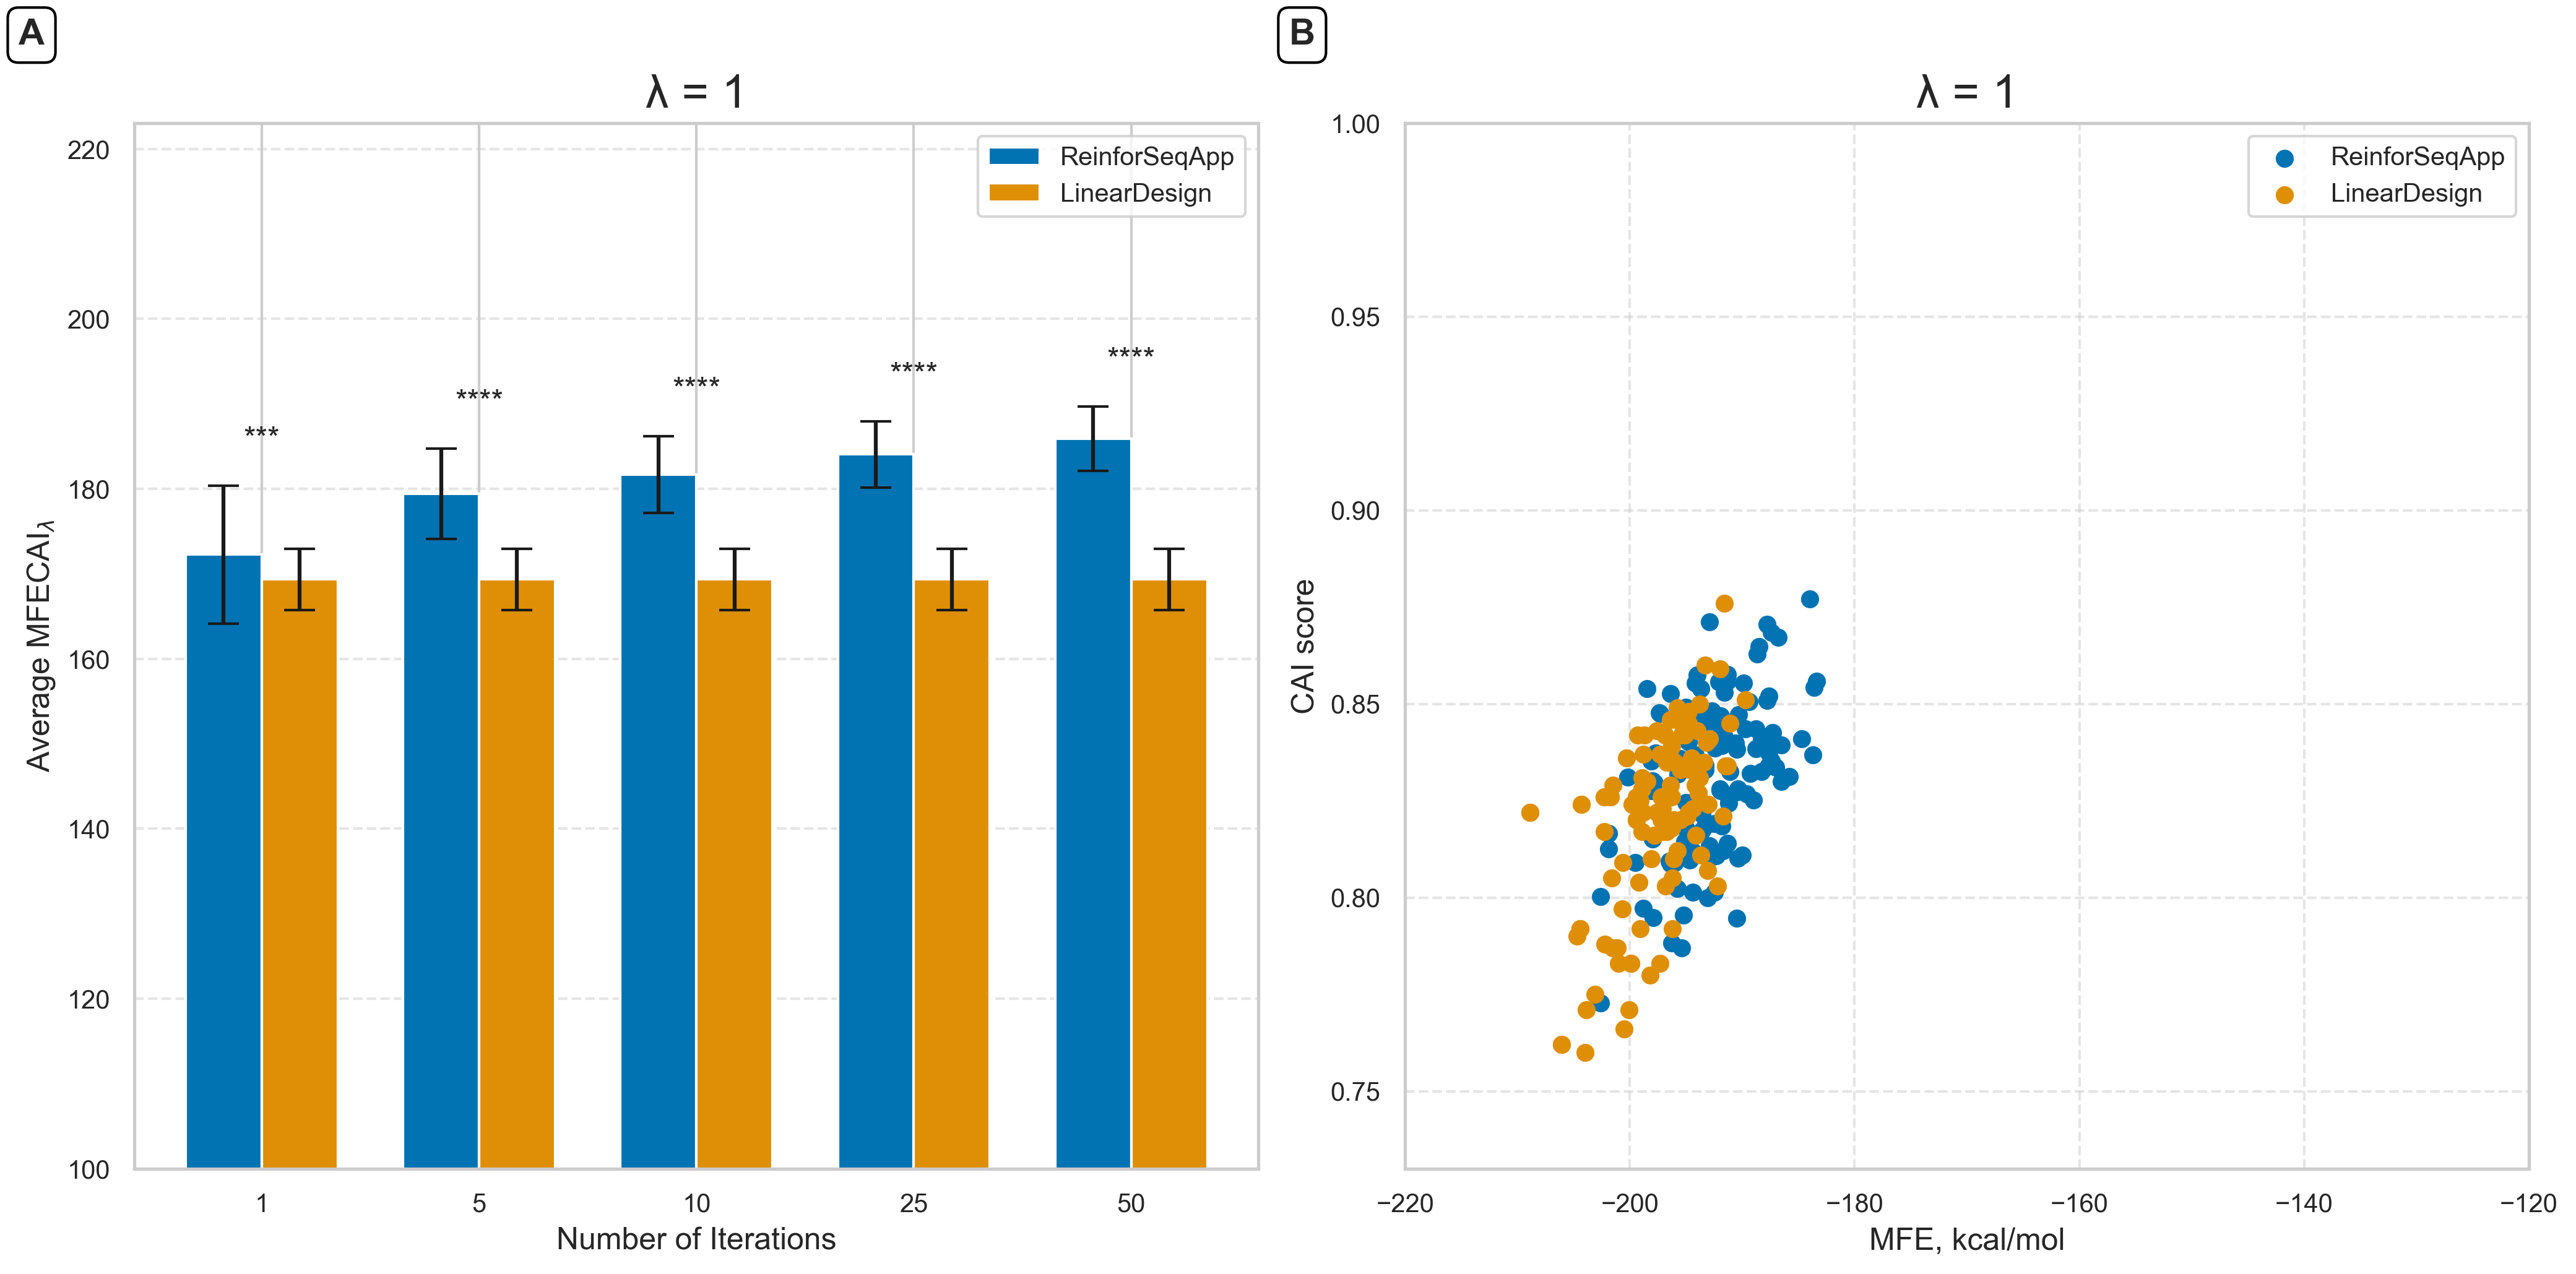

Saved: The LinearDesign vs ReinforSeqPipe lambda 1.tiff


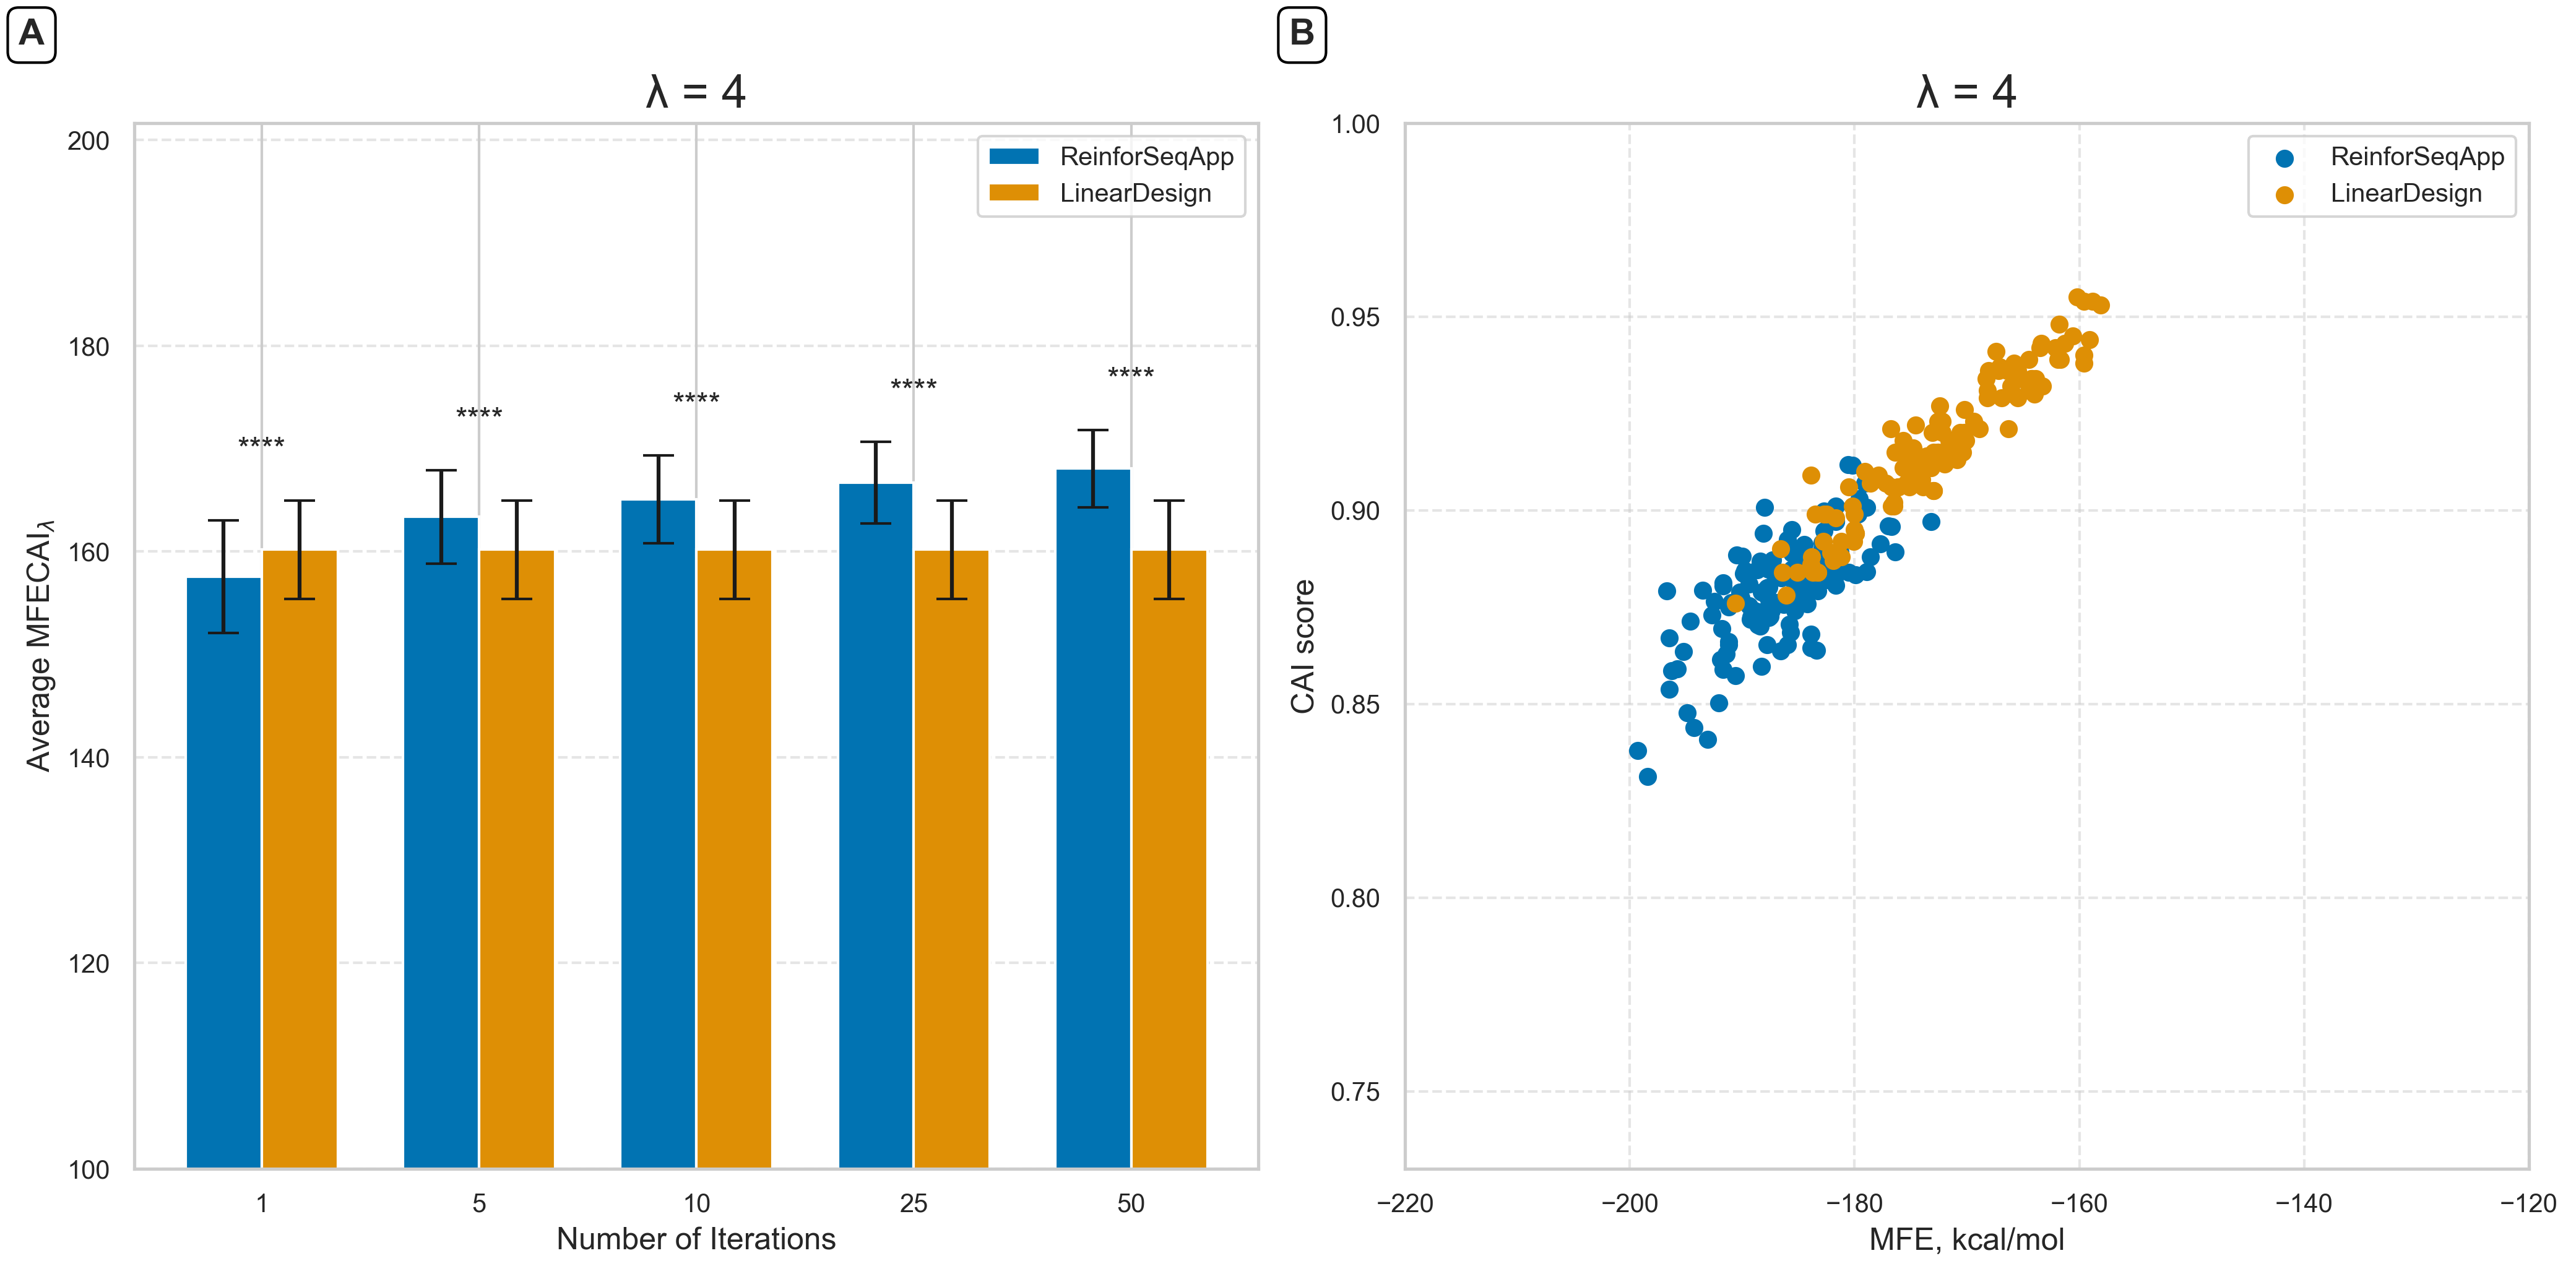

Saved: The LinearDesign vs ReinforSeqPipe lambda 4.tiff


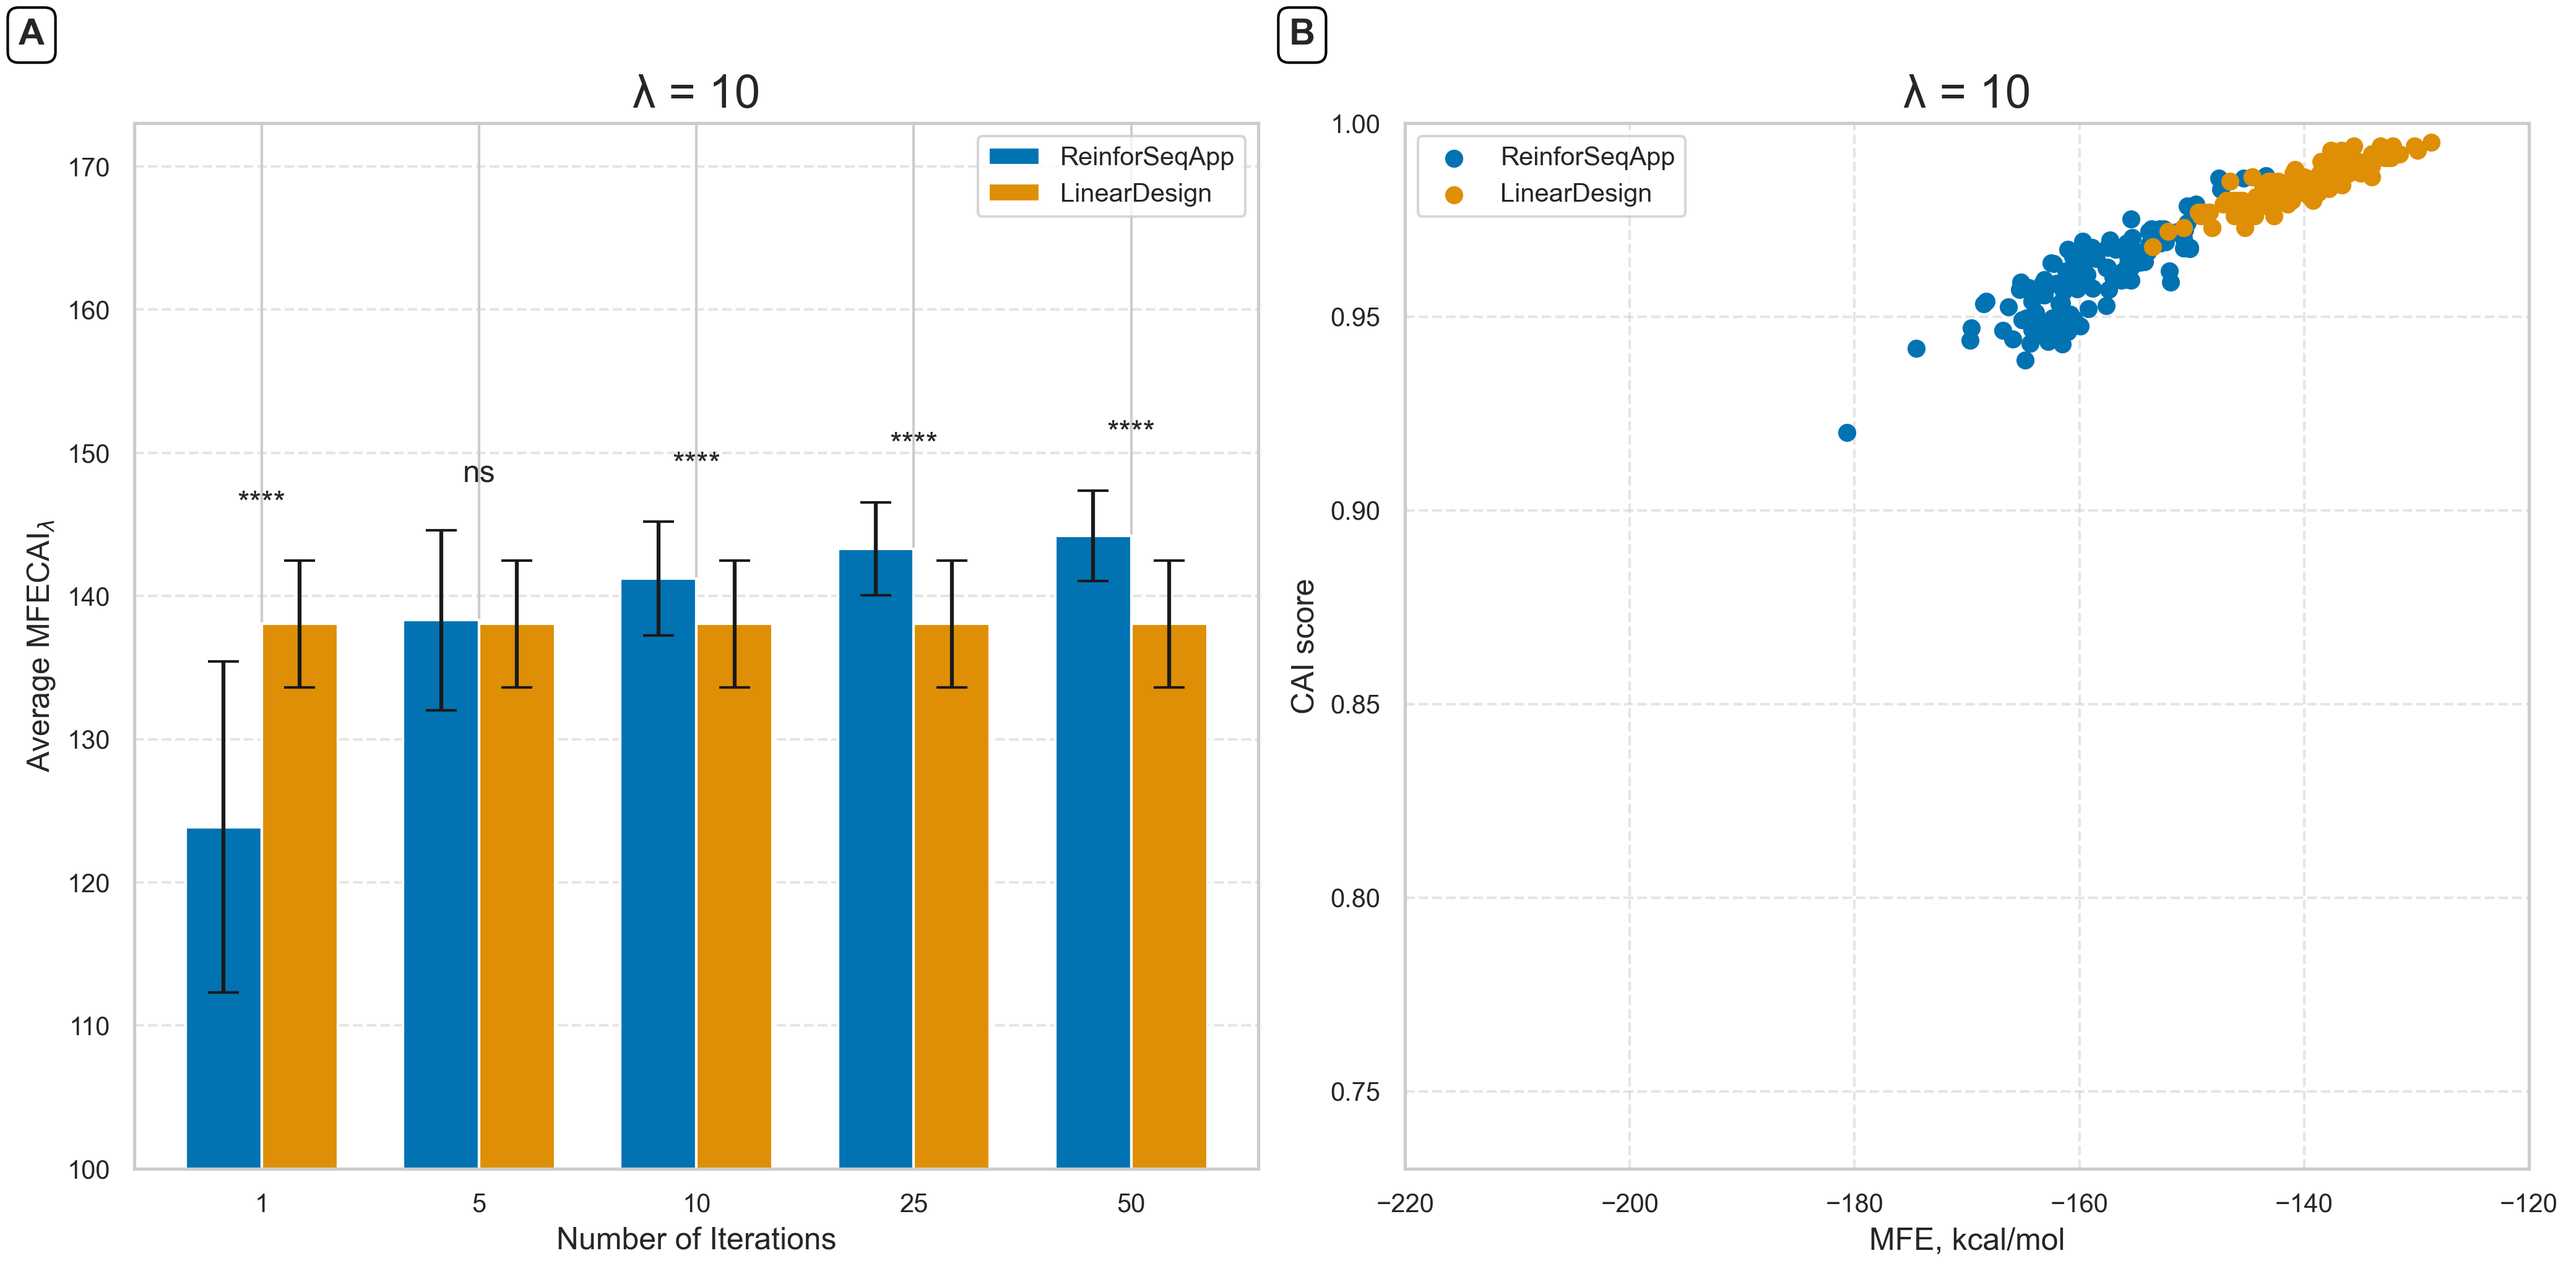

Saved: The LinearDesign vs ReinforSeqPipe lambda 10.tiff


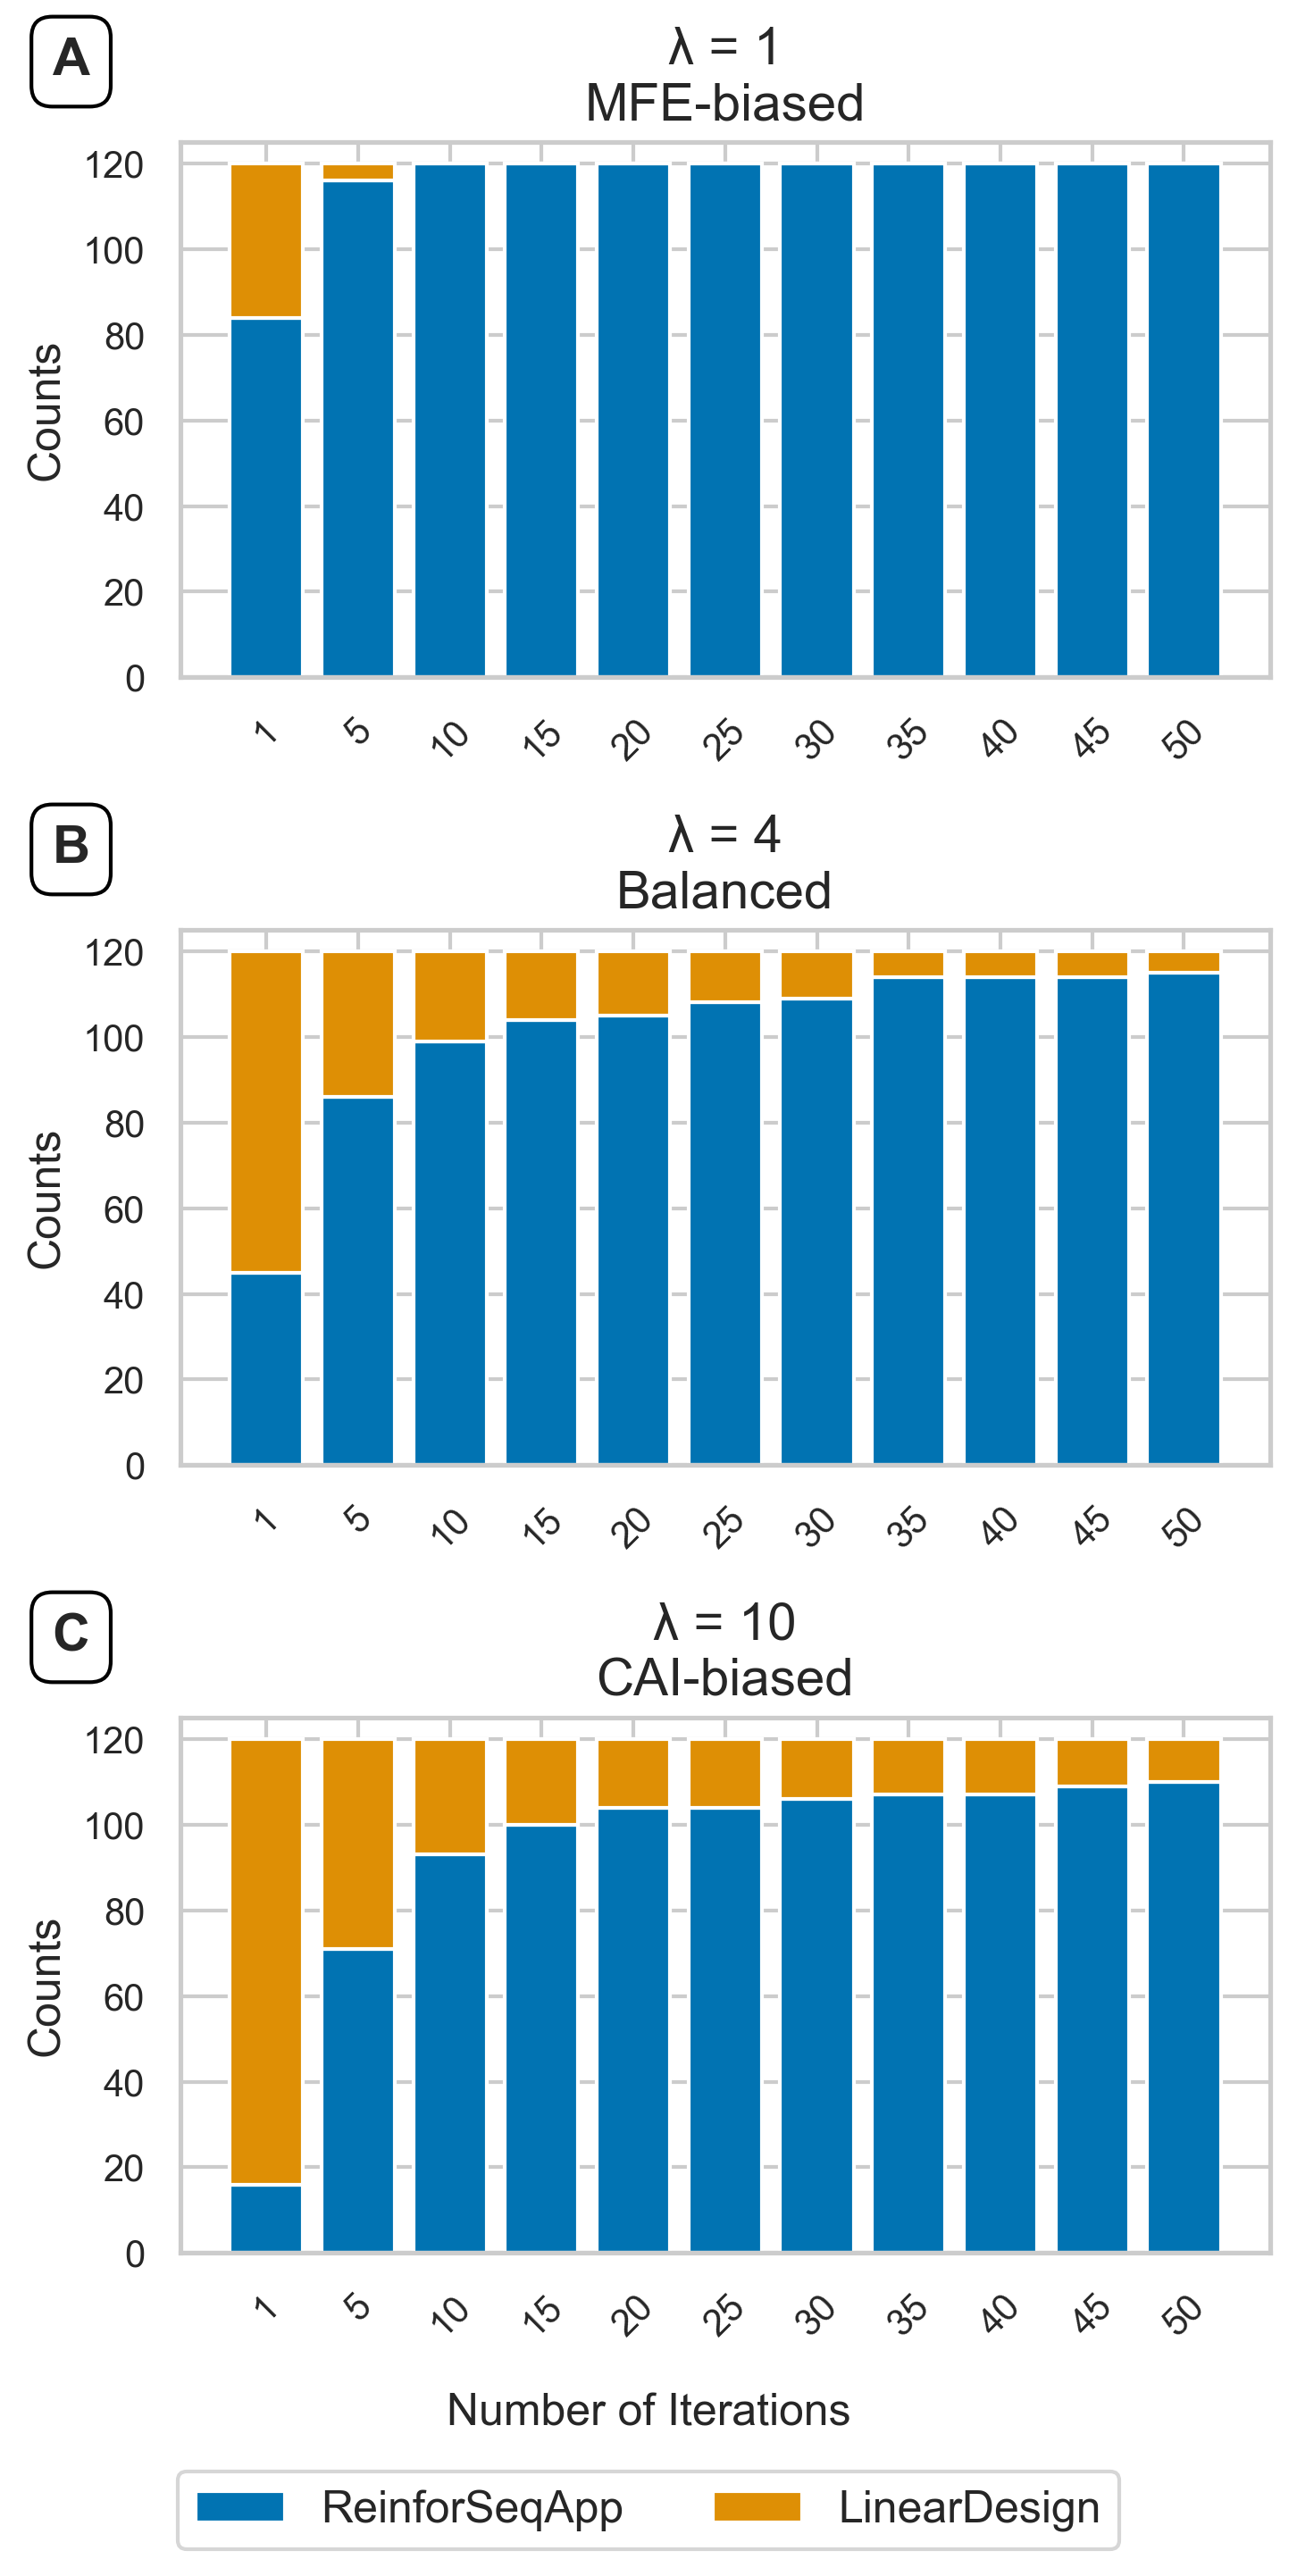

Saved: The iterative method of ReifnorSeqPipe vs LienarDesign determinism.tiff


In [61]:
import os
import pandas as pd
from Bio.Seq import Seq
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans'] 
sns.set_theme(style="whitegrid", font_scale=1.2) 
plt.rcParams.update({
    'font.size': 12,          
    'axes.titlesize': 14,     
    'axes.labelsize': 12,     
    'legend.fontsize': 10,    
    'xtick.labelsize': 10,    
    'ytick.labelsize': 10     
})

def translate(seq: str) -> str:
    return str(Seq(seq).translate(to_stop=True))

def build_compare_df(
    folder: str,
    n_files: int,
    parsed_results_path: str = "parsed_results.csv",
    keep_cols = ('Peptide Sequence', 'Final CAI', 'Final MFE', 'Final MFExCAI score',
                 'Control CAI', 'Control MFE', 'Control MFExCAI score'),
    lower_score_better: bool = False,  # set True if a lower MFExCAI is better
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Reads the first n_files CSVs in `folder`, computes best MFExCAI per peptide,
    merges with parsed_results.csv, keeps selected columns, adds 'Comparison'.

    Returns:
        merged_df: the final dataframe
        counts: value_counts() of the 'Comparison' column
    """
    # list and take first n_files CSVs (sorted for determinism)
    all_csvs = sorted([f for f in os.listdir(folder) if f.lower().endswith(".csv")])
    total = len(all_csvs)
    if n_files > total:
        raise ValueError(f"Requested {n_files} files but only found {total} CSVs in {folder}.")
    take_csvs = all_csvs[:n_files]

    # build combined dataframe
    combined = []
    for file in take_csvs:
        path = os.path.join(folder, file)
        df = pd.read_csv(path)
        # keep only required columns (present in your pipeline)
        df = df[['Original Sequence', 'Final Sequence', 'Final CAI', 'Final MFE', 'Final MFExCAI score']]
        df['Peptide Sequence'] = df['Final Sequence'].apply(translate)
        combined.append(df)

    if not combined:
        raise ValueError("No CSV files found to process.")

    df_reifnorseq = pd.concat(combined, ignore_index=True)

    # ensure score is numeric
    df_reifnorseq['Final MFExCAI score'] = pd.to_numeric(df_reifnorseq['Final MFExCAI score'], errors='coerce')

    # subset to the columns we need for the reduction
    subset = df_reifnorseq[['Peptide Sequence', 'Final CAI', 'Final MFE', 'Final MFExCAI score']].copy()

    # choose best row per peptide
    if lower_score_better:
        idx = subset.groupby('Peptide Sequence', dropna=False)['Final MFExCAI score'].idxmin()
    else:
        idx = subset.groupby('Peptide Sequence', dropna=False)['Final MFExCAI score'].idxmax()
    best_per_peptide = subset.loc[idx].reset_index(drop=True)

    # merge with parsed_results.csv
    lineardesign_df = pd.read_csv(parsed_results_path)

    merged_df = lineardesign_df.merge(
        best_per_peptide[['Peptide Sequence', 'Final CAI', 'Final MFE', 'Final MFExCAI score']],
        on='Peptide Sequence',
        how='left'
    )

    # keep/reorder columns (any missing ones will be ignored gracefully)
    keep_cols = [c for c in keep_cols if c in merged_df.columns]
    merged_df = merged_df[keep_cols]

    # comparison column
    def compare_scores(row):
        a = row.get('Final MFExCAI score')
        b = row.get('Control MFExCAI score')
        if pd.isna(a) or pd.isna(b):
            return 'Missing'
        if a > b:
            return 'Reinforseq'
        elif a < b:
            return 'LinearDesign'
        else:
            return 'Equal'
    
    merged_df['Comparison'] = merged_df.apply(compare_scores, axis=1)
    results = {'Number of Replicas': n_files,
                'Wins': (merged_df['Comparison'] == 'Reinforseq').sum(),
               'Losses': (merged_df['Comparison'] == 'LinearDesign').sum(),
               'Equal': (merged_df['Comparison'] == 'Equal').sum(),
               'Average MFECAI Reinforseq': merged_df['Final MFExCAI score'].mean(),
               'Average MFECAI LinearDesign': merged_df['Control MFExCAI score'].mean(),
               'StDev MFECAI Reinforseq': merged_df['Final MFExCAI score'].std(),
                'StDev MFECAI LinearDesign': merged_df['Control MFExCAI score'].std(),
               'Average CAI Reinforseq': merged_df['Final CAI'].mean(),
               'Average CAI LinearDesign': merged_df['Control CAI'].mean(),
               'StDev CAI Reinforseq': merged_df['Final CAI'].std(),
                'StDev CAI LinearDesign': merged_df['Control CAI'].std(),
                'Average MFE Reinforseq': merged_df['Final MFE'].mean(),
                'Average MFE LinearDesign': merged_df['Control MFE'].mean(),
                'StDev MFE Reinforseq': merged_df['Final MFE'].std(),
                'StDev MFE LinearDesign': merged_df['Control MFE'].std()}
    list_of_mfecai_reifnorseq = merged_df['Final MFExCAI score'].dropna().tolist()
    list_of_mfecai_lineardesign = merged_df['Control MFExCAI score'].dropna().tolist()
    return merged_df, results, list_of_mfecai_reifnorseq, list_of_mfecai_lineardesign


"""# Process lambda_1 results"""

summary_df_l1 = pd.DataFrame()
lineardesign_list_l1 = []
reifnorseq_list_l1 = []
list_of_mfecai = []
nums = [1] + list(range(5, 51, 5))
for i in nums:
    merged_df_l1, results_l1, list_of_mfecai_reifnorseq, list_of_mfecai_lineardesign = build_compare_df(
        folder='ReifnorSeq_Benchmark_all_results/lambda_1',
        n_files=i,
        parsed_results_path='LinearDesign_Benchmark_all_results/parsed_results_l1.csv',
        keep_cols=('Peptide Sequence', 'Final CAI', 'Final MFE', 'Final MFExCAI score',
                   'Control CAI', 'Control MFE', 'Control MFExCAI score'),
        lower_score_better=False  
    )
    summary_df_l1 = pd.concat([summary_df_l1, pd.DataFrame([results_l1])], ignore_index=True)
    lineardesign_list_l1.append(list_of_mfecai_lineardesign)
    reifnorseq_list_l1.append(list_of_mfecai_reifnorseq)


"""# Process lambda_4 results"""

summary_df_l4 = pd.DataFrame()
lineardesign_list_l4 = []
reifnorseq_list_l4 = []
nums = [1] + list(range(5, 51, 5))
for i in nums:
    merged_df_l4, results_l4, list_of_mfecai_reifnorseq, list_of_mfecai_lineardesign = build_compare_df(
        folder='ReifnorSeq_Benchmark_all_results/lambda_4',
        n_files=i,
        parsed_results_path='LinearDesign_Benchmark_all_results/parsed_results_l4.csv',
        keep_cols=('Peptide Sequence', 'Final CAI', 'Final MFE', 'Final MFExCAI score',
                   'Control CAI', 'Control MFE', 'Control MFExCAI score'),
        lower_score_better=False  
    )
    summary_df_l4 = pd.concat([summary_df_l4, pd.DataFrame([results_l4])], ignore_index=True)
    lineardesign_list_l4.append(list_of_mfecai_lineardesign)
    reifnorseq_list_l4.append(list_of_mfecai_reifnorseq)


"""# Process lambda_10 results"""

summary_df_l10 = pd.DataFrame()
lineardesign_list_l10 = []
reifnorseq_list_l10 = []
nums = [1] + list(range(5, 51, 5))
for i in nums:
    merged_df_l10, results_l10, list_of_mfecai_reifnorseq, list_of_mfecai_lineardesign = build_compare_df(
        folder='ReifnorSeq_Benchmark_all_results/lambda_10',
        n_files=i,
        parsed_results_path='LinearDesign_Benchmark_all_results/parsed_results_l10.csv',
        keep_cols=('Peptide Sequence', 'Final CAI', 'Final MFE', 'Final MFExCAI score',
                   'Control CAI', 'Control MFE', 'Control MFExCAI score'),
        lower_score_better=False  
    )
    summary_df_l10 = pd.concat([summary_df_l10, pd.DataFrame([results_l10])], ignore_index=True)
    lineardesign_list_l10.append(list_of_mfecai_lineardesign)
    reifnorseq_list_l10.append(list_of_mfecai_reifnorseq)



selected_summary_df_l1 = summary_df_l1[summary_df_l1['Number of Replicas'].isin([1, 5, 10, 25, 50])]
selected_summary_df_l4 = summary_df_l4[summary_df_l4['Number of Replicas'].isin([1, 5, 10, 25, 50])]
selected_summary_df_l10 = summary_df_l10[summary_df_l10['Number of Replicas'].isin([1, 5, 10, 25, 50])]
colors = sns.color_palette("colorblind")
def ttest_from_summary(m1, s1, n1, m2, s2, n2):
    # Compute t-statistic
    t_num = m1 - m2
    t_den = np.sqrt(s1**2 / n1 + s2**2 / n2)
    t_stat = t_num / t_den
    
    # Welch-Satterthwaite df
    df = (s1**2/n1 + s2**2/n2)**2 / ((s1**2/n1)**2/(n1-1) + (s2**2/n2)**2/(n2-1))
    
    # Two-tailed p-value
    p_val = 2 * stats.t.sf(np.abs(t_stat), df)
    return t_stat, df, p_val
def p_to_stars(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"
def plot_grouped_bars(summary_df, xcol, m1col, s1col, m2col, s2col,
                      ylabel, title, n1, n2, scatter_x_rs, scatter_y_rs, 
                      scatter_x_ld, scatter_y_ld, xlabel_scatter, ylabel_scatter, title_scatter, letters=('A', 'B')):
    # Ensure arrays
    fig, axs = plt.subplots(1, 2, figsize=(14,7))

    # --- Left subplot: grouped bar plot with t-test stars ---
    ax = axs[0]
    x = np.atleast_1d(summary_df[xcol].to_numpy())
    m1 = np.atleast_1d(summary_df[m1col].to_numpy())
    s1 = np.atleast_1d(summary_df[s1col].to_numpy())
    m2 = np.atleast_1d(summary_df[m2col].to_numpy())
    s2 = np.atleast_1d(summary_df[s2col].to_numpy())

    x_pos = np.arange(len(x))
    bar_width = 0.35
    capsize = 6

    ax.bar(x_pos - bar_width/2, m1, width=bar_width, yerr=s1, color=colors[0], capsize=capsize, label='ReinforSeqApp')
    ax.bar(x_pos + bar_width/2, m2, width=bar_width, yerr=s2, color=colors[1], capsize=capsize, label='LinearDesign')

    # Add t-test stars
    for i in range(len(x)):
        _, _, p_val = ttest_from_summary(m1[i], s1[i], n1, m2[i], s2[i], n2)
        stars = p_to_stars(p_val)
        y = max(m1[i] + s1[i], m2[i] + s2[i]) + 0.01 * max(m1 + s1 + m2 + s2)
        ax.text(x_pos[i], y, stars, ha='center', va='bottom', fontsize=12)

    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(i) for i in x])
    ax.set_xlabel('Number of Iterations')
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=18)
    ax.legend()
    ax.set_ylim(100, max(m1) * 1.2)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.text(-0.08, 1.1, letters[0], transform=ax.transAxes,
            fontsize=14, fontweight='bold', va='top', ha='right', 
            bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))
    # --- Right subplot: scatter plot with two series ---
    ax2 = axs[1]
    ax2.scatter(scatter_x_rs, scatter_y_rs, color=colors[0], label='ReinforSeqApp')
    ax2.scatter(scatter_x_ld, scatter_y_ld, color=colors[1], label='LinearDesign')
    ax2.set_xlabel(xlabel_scatter)
    ax2.set_ylabel(ylabel_scatter)
    ax2.set_title(title, fontsize=18)
    ax2.legend()
    ax2.set_xlim(-220, -120)
    ax2.set_ylim(0.73, 1)
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.text(-0.08, 1.1, letters[1], transform=ax2.transAxes,
             fontsize=14, fontweight='bold', va='top', ha='right',
             bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))
    plt.tight_layout()
    plt.show()
    return fig


scatter_x_reinforseq_l1 = merged_df_l1['Final MFE'].tolist()
scatter_y_reinforseq_l1 = merged_df_l1['Final CAI'].tolist()
scatter_x_lineardesign_l1 = merged_df_l1['Control MFE'].tolist()
scatter_y_lineardesign_l1 = merged_df_l1['Control CAI'].tolist()
fig1 = plot_grouped_bars(
    selected_summary_df_l1,
    xcol='Number of Replicas',
    m1col='Average MFECAI Reinforseq', s1col='StDev MFECAI Reinforseq', n1=120,
    m2col='Average MFECAI LinearDesign', s2col='StDev MFECAI LinearDesign', n2=120,
    ylabel='Average MFECAI$_{\lambda}$',
    title='λ = 1', 
    scatter_x_rs = scatter_x_reinforseq_l1, scatter_y_rs = scatter_y_reinforseq_l1, 
    scatter_x_ld = scatter_x_lineardesign_l1, scatter_y_ld = scatter_y_lineardesign_l1,
    xlabel_scatter = 'MFE, kcal/mol', ylabel_scatter = 'CAI score', title_scatter = 'Lambda = 1'
)
save_tiff(fig1, 'The LinearDesign vs ReinforSeqPipe lambda 1')

scatter_x_reinforseq_l4 = merged_df_l4['Final MFE'].tolist()
scatter_y_reinforseq_l4 = merged_df_l4['Final CAI'].tolist()
scatter_x_lineardesign_l4 = merged_df_l4['Control MFE'].tolist()
scatter_y_lineardesign_l4 = merged_df_l4['Control CAI'].tolist()
fig2 = plot_grouped_bars(
    selected_summary_df_l4,
    xcol='Number of Replicas',
    m1col='Average MFECAI Reinforseq', s1col='StDev MFECAI Reinforseq', n1=120,
    m2col='Average MFECAI LinearDesign', s2col='StDev MFECAI LinearDesign', n2=120,
    ylabel='Average MFECAI$_{\lambda}$',
    title='λ = 4',
    scatter_x_rs = scatter_x_reinforseq_l4, scatter_y_rs = scatter_y_reinforseq_l4, 
    scatter_x_ld = scatter_x_lineardesign_l4, scatter_y_ld = scatter_y_lineardesign_l4,
    xlabel_scatter = 'MFE, kcal/mol', ylabel_scatter = 'CAI score', title_scatter = 'Lambda = 4'
)
save_tiff(fig2, 'The LinearDesign vs ReinforSeqPipe lambda 4')


scatter_x_reinforseq_l10 = merged_df_l10['Final MFE'].tolist()
scatter_y_reinforseq_l10 = merged_df_l10['Final CAI'].tolist()
scatter_x_lineardesign_l10 = merged_df_l10['Control MFE'].tolist()
scatter_y_lineardesign_l10 = merged_df_l10['Control CAI'].tolist()
fig3 = plot_grouped_bars(
    selected_summary_df_l10,
    xcol='Number of Replicas',
    m1col='Average MFECAI Reinforseq', s1col='StDev MFECAI Reinforseq', n1=120,
    m2col='Average MFECAI LinearDesign', s2col='StDev MFECAI LinearDesign', n2=120,
    ylabel='Average MFECAI$_{\lambda}$',
    title='λ = 10',
    scatter_x_rs = scatter_x_reinforseq_l10, scatter_y_rs = scatter_y_reinforseq_l10,
    scatter_x_ld = scatter_x_lineardesign_l10, scatter_y_ld = scatter_y_lineardesign_l10,
    xlabel_scatter = 'MFE, kcal/mol', ylabel_scatter = 'CAI score', title_scatter = 'Lambda = 10'
)
save_tiff(fig3, 'The LinearDesign vs ReinforSeqPipe lambda 10')


import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'λ = 1\nMFE-biased': (
        [84, 116, 120, 120, 120, 120, 120, 120, 120, 120, 120],
        [36, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0]
    ),
    'λ = 4\nBalanced': (
        [45, 86, 99, 104, 105, 108, 109, 114, 114, 114, 115],
        [75, 34, 21, 16, 15, 12, 11, 6, 6, 6, 5]
    ),
    'λ = 10\nCAI-biased': (
        [16, 71, 93, 100, 104, 104, 106, 107, 107, 109, 110],
        [104, 49, 27, 20, 16, 16, 14, 13, 13, 11, 10]
    )
}

steps = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
stack_colors = [colors[0], colors[1]] 

# --- Create subplots ---
fig, axes = plt.subplots(3, 1, figsize=(5, 9), sharey=True)  # 1 row, 3 columns
letters = ['A', 'B', 'C']

for ax, (letter, (label, (vals1, vals2))) in zip(axes, zip(letters, data.items())):
    steps_str = [str(s) for s in steps]
    
    bars1 = ax.bar(steps_str, vals1, width=0.8, color=stack_colors[0])
    bars2 = ax.bar(steps_str, vals2, width=0.8, bottom=vals1, color=stack_colors[1])
    
    ax.set_title(label)
    ax.set_xticks(range(len(steps_str)))
    ax.set_xticklabels(steps_str, rotation=45)
    ax.set_ylim(0, 125)
    ax.set_ylabel("Counts")
    
    # Add letter in box
    ax.text(-0.1, 1.15, letter, transform=ax.transAxes,
            fontsize=14, fontweight='bold', ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='black'))

# Create a single legend for the figure
fig.legend([bars1, bars2], ["ReinforSeqApp", "LinearDesign"], loc='center', ncol=2, frameon=True, bbox_to_anchor=(0.5, -0.05), fontsize = 12)
fig.text(0.5, -0.01, 'Number of Iterations', ha='center', va='center')
plt.tight_layout()
plt.show()
save_tiff(fig, 'The iterative method of ReifnorSeqPipe vs LienarDesign determinism')

# Aggregated Plots

/var/folders/r2/d51ts3bj7ys1zccpl_fdh4bm0000gn/T/ipykernel_41859/3545895894.py:430: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


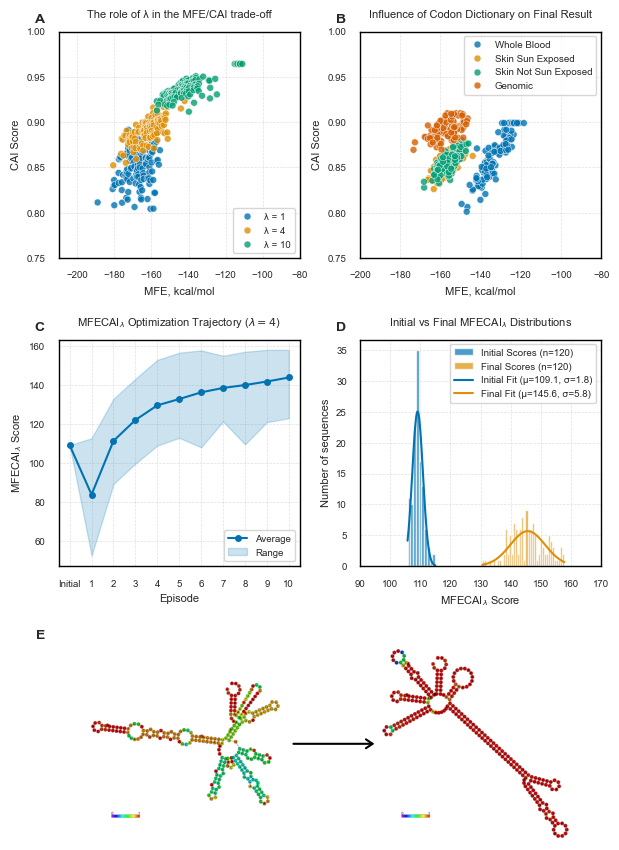

In [10]:
import ast
import math
import os
import string
from typing import Dict, List

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from Bio.Seq import Seq
from scipy.stats import norm

# --------------------------------------------------------------------------------------
# 🔧 GLOBAL PUBLICATION CONFIGURATION (NAR Guidelines: 178 mm / 7.0 in Full Width)
# --------------------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
sns.set_theme(style="whitegrid", font_scale=1.0)

plt.rcParams.update(
    {
        "font.size": 8,  # General text
        "axes.titlesize": 8,  # Subplot titles
        "axes.labelsize": 8,  # Axis labels
        "legend.fontsize": 7,  # Legend text
        "xtick.labelsize": 7,  # Tick labels
        "ytick.labelsize": 7,
        "axes.linewidth": 0.8,  # Border spine thickness
        "grid.linewidth": 0.5,  # Gridline thickness
    }
)

colors_palette = sns.color_palette("colorblind")

# File path constants
FOLDER_PATH = "results_2025-05-11_10_episodes_experimental_dataset"
TISSUE_FOLDER_PATH = "tissue_results"

LAMBDA_VALUES = [1, 4, 10]
REPLICATES = [1, 2, 3]

# --------------------------------------------------------------------------------------
# 1. HELPER & DATA LOADING FUNCTIONS
# --------------------------------------------------------------------------------------

def translate(seq: str) -> str:
    return str(Seq(seq).translate(to_stop=True))

def load_and_process_lambda_data(
    lambda_value: int, replicates: List[int]
) -> pd.DataFrame:
    df_list = []
    mapping = {
        1: [
            "2025-05-11_12-24_lambda_1.csv",
            "2025-05-11_13-00_lambda_1.csv",
            "2025-05-11_13-37_lambda_1.csv",
        ],
        4: [
            "2025-05-11_12-36_lambda_4.csv",
            "2025-05-11_13-13_lambda_4.csv",
            "2025-05-11_13-50_lambda_4.csv",
        ],
        10: [
            "2025-05-11_12-48_lambda_10.csv",
            "2025-05-11_13-25_lambda_10.csv",
            "2025-05-11_14-02_lambda_10.csv",
        ],
    }
    if lambda_value not in mapping:
        return pd.DataFrame()

    for filename_suffix in mapping[lambda_value]:
        file_path = os.path.join(
            FOLDER_PATH, f"results_for_run_dated_{filename_suffix}"
        )
        try:
            df_list.append(pd.read_csv(file_path))
        except FileNotFoundError:
            pass

    if not df_list:
        return pd.DataFrame()

    df_concat = pd.concat(df_list, ignore_index=True)
    if "Unnamed: 0" in df_concat.columns:
        df_concat = df_concat.drop(columns=["Unnamed: 0"])

    df_sorted = df_concat.sort_values(
        by="Final MFExCAI score", ascending=False
    )
    df_best = df_sorted.drop_duplicates(
        subset="Original Sequence", keep="first"
    )
    return df_best.reset_index(drop=True)

def load_and_group_tissue_data(
    folder_path: str, keyword: str, grouping_columns: list
) -> pd.DataFrame:
    main_df = pd.DataFrame()
    if not os.path.exists(folder_path):
        return main_df
    for file in os.listdir(folder_path):
        if file.endswith(".csv") and keyword in file:
            file_path = os.path.join(folder_path, file)
            try:
                df = pd.read_csv(file_path)
                main_df = pd.concat([main_df, df], ignore_index=True)
            except Exception:
                continue
    if main_df.empty:
        return main_df
    return (
        main_df.groupby("Original Sequence")[grouping_columns]
        .mean()
        .reset_index()
    )

# Load Datasets
df_best_results: Dict[int, pd.DataFrame] = {}
for lmbda in LAMBDA_VALUES:
    df_best_results[lmbda] = load_and_process_lambda_data(lmbda, REPLICATES)

df_combined_lambda = pd.concat(
    [
        df_best_results[1].assign(Lambda="λ = 1"),
        df_best_results[4].assign(Lambda="λ = 4"),
        df_best_results[10].assign(Lambda="λ = 10"),
    ],
    ignore_index=True,
)

columns_to_group = [
    "Original CAI",
    "Final CAI",
    "Original MFE",
    "Final MFE",
    "Original MFExCAI score",
    "Final MFExCAI score",
]

df_blood = load_and_group_tissue_data(
    TISSUE_FOLDER_PATH, "whole_blood", columns_to_group
).assign(Group="Whole Blood")
df_sunexposed = load_and_group_tissue_data(
    TISSUE_FOLDER_PATH, "skin_sun_exposed", columns_to_group
).assign(Group="Skin Sun Exposed")
df_notsunexposed = load_and_group_tissue_data(
    TISSUE_FOLDER_PATH, "skin_not_sun_exposed", columns_to_group
).assign(Group="Skin Not Sun Exposed")
df_genomic = load_and_group_tissue_data(
    TISSUE_FOLDER_PATH, "genomic", columns_to_group
).assign(Group="Genomic")

df_combined_tissues = pd.concat(
    [df_blood, df_sunexposed, df_notsunexposed, df_genomic], ignore_index=True
)

dflambda4_best = df_best_results[4]

# --------------------------------------------------------------------------------------
# 2. MODULAR PANEL PLOTTING FUNCTIONS
# --------------------------------------------------------------------------------------

def plot_panel_a(data_frame: pd.DataFrame, axis_object: plt.Axes):
    """PANEL A: Scatter plot of the role of lambda in MFE/CAI trade-off."""
    sns.scatterplot(
        data=data_frame,
        x="Final MFE",
        y="Final CAI",
        hue="Lambda",
        palette=colors_palette[:3],
        ax=axis_object,
        s=25,
        alpha=0.8,
    )
    axis_object.set_xlim(-210.0, -80.0)
    axis_object.set_ylim(0.75, 1.0)
    axis_object.set_xlabel("MFE, kcal/mol")
    axis_object.set_ylabel("CAI Score")
    axis_object.set_title("The role of λ in the MFE/CAI trade-off", pad=10)
    axis_object.grid(True, linestyle="--", alpha=0.6)
    axis_object.legend(title="", loc="lower right")

def plot_panel_b(data_frame: pd.DataFrame, axis_object: plt.Axes):
    """PANEL B: Scatter plot for tissue-specific codon tables."""
    groups = data_frame["Group"].unique()
    sliced_colors = colors_palette[: len(groups)]

    sns.scatterplot(
        data=data_frame,
        x="Final MFE",
        y="Final CAI",
        hue="Group",
        palette=sliced_colors,
        ax=axis_object,
        s=25,
        alpha=0.8,
    )
    axis_object.set_xlim(-200, -80)
    axis_object.set_ylim(0.75, 1.0)
    axis_object.set_xlabel("MFE, kcal/mol")
    axis_object.set_ylabel("CAI Score")
    axis_object.set_title(
        "Influence of Codon Dictionary on Final Result", pad=10
    )
    axis_object.grid(True, linestyle="--", alpha=0.6)
    axis_object.legend(title="", loc="upper right")

def plot_panel_c(data_frame: pd.DataFrame, axis_object: plt.Axes):
    """PANEL C: MFECAI_lambda Optimization Trajectory (λ=4)."""
    length = len(data_frame["Final Sequence"].iloc[0])
    original_cai = data_frame["Original CAI"].mean()
    original_mfe = data_frame["Original MFE"].mean()

    lambda_factor = 4
    original_score = abs(
        original_mfe - lambda_factor * (length // 3) * math.log10(original_cai)
    )

    episode_list = ast.literal_eval(data_frame["Episode List"].iloc[0])
    episode_list.insert(0, 0)

    score_trajectories = []
    for cai_str, mfe_str in zip(data_frame["CAI List"], data_frame["MFE List"]):
        cai_list = (
            ast.literal_eval(cai_str) if isinstance(cai_str, str) else cai_str
        )
        mfe_list = (
            ast.literal_eval(mfe_str) if isinstance(mfe_str, str) else mfe_str
        )

        local_scores = []
        for i in range(len(cai_list)):
            score = mfe_list[i] - lambda_factor * (length // 3) * math.log10(
                cai_list[i]
            )
            local_scores.append(abs(score))
        score_trajectories.append(local_scores)

    score_array = np.array(score_trajectories)
    mean_trajectory = np.insert(
        np.mean(score_array, axis=0), 0, original_score
    )
    min_trajectory = np.insert(np.min(score_array, axis=0), 0, original_score)
    max_trajectory = np.insert(np.max(score_array, axis=0), 0, original_score)

    axis_object.plot(
        episode_list,
        mean_trajectory,
        color=colors_palette[0],
        linestyle="-",
        marker="o",
        markersize=4,
        label="Average",
    )
    axis_object.fill_between(
        episode_list,
        min_trajectory,
        max_trajectory,
        color=colors_palette[0],
        alpha=0.2,
        label="Range",
    )

    axis_object.set_xlabel("Episode")
    axis_object.set_ylabel(r"MFECAI$_{\lambda}$ Score")
    axis_object.set_title(
        r"MFECAI$_{\lambda}$ Optimization Trajectory ($\lambda=4$)", pad=10
    )
    axis_object.grid(True, linestyle="--", alpha=0.6)

    xtick_labels = ["Initial"] + [str(x) for x in episode_list[1:]]
    axis_object.set_xticks(episode_list)
    axis_object.set_xticklabels(xtick_labels)
    axis_object.legend(loc="lower right")

def plot_panel_d(data_frame: pd.DataFrame, axis_object: plt.Axes):
    """PANEL D: Distribution Comparison of Initial vs Final States."""
    final_scores = data_frame["Final MFExCAI score"].dropna()
    initial_scores = data_frame["Original MFExCAI score"].dropna()

    bin_width_initial = (max(initial_scores) - min(initial_scores)) / 10
    bin_width_final = (max(final_scores) - min(final_scores)) / 40

    mu1, std1 = norm.fit(initial_scores)
    x1 = np.linspace(min(initial_scores), max(initial_scores), 100)
    pdf1 = norm.pdf(x1, mu1, std1)

    mu2, std2 = norm.fit(final_scores)
    x2 = np.linspace(min(final_scores), max(final_scores), 100)
    pdf2 = norm.pdf(x2, mu2, std2)

    axis_object.hist(
        initial_scores,
        bins=10,
        color=colors_palette[0],
        alpha=0.7,
        label=f"Initial Scores (n={len(initial_scores)})",
        density=False,
    )
    axis_object.hist(
        final_scores,
        bins=40,
        color=colors_palette[1],
        alpha=0.7,
        label=f"Final Scores (n={len(final_scores)})",
        density=False,
    )

    axis_object.plot(
        x1,
        pdf1 * len(initial_scores) * bin_width_initial,
        color=colors_palette[0],
        linestyle="-",
        linewidth=1.5,
        label=f"Initial Fit (μ={mu1:.1f}, σ={std1:.1f})",
    )
    axis_object.plot(
        x2,
        pdf2 * len(final_scores) * bin_width_final,
        color=colors_palette[1],
        linestyle="-",
        linewidth=1.5,
        label=f"Final Fit (μ={mu2:.1f}, σ={std2:.1f})",
    )

    axis_object.set_xlabel(r"MFECAI$_{\lambda}$ Score")
    axis_object.set_ylabel("Number of sequences")
    axis_object.set_title(
        "Initial vs Final MFECAI$_{\lambda}$ Distributions", pad=10
    )
    axis_object.set_xlim(90, 170)
    axis_object.grid(True, linestyle="--", alpha=0.6)
    axis_object.legend(loc="upper right")

# --------------------------------------------------------------------------------------
# 3. AGGREGATED GRID ASSEMBLY USING GRIDSPEC (7.0 in wide x 8.5 in tall)
# --------------------------------------------------------------------------------------

fig = plt.figure(figsize=(7.0, 10.5))
grid_spec = fig.add_gridspec(
    3, 2, height_ratios=[1.0, 1.0, 0.85], hspace=0.38, wspace=0.25
)

ax_a = fig.add_subplot(grid_spec[0, 0])
ax_b = fig.add_subplot(grid_spec[0, 1])
ax_c = fig.add_subplot(grid_spec[1, 0])
ax_d = fig.add_subplot(grid_spec[1, 1])

# Panel E bounding box (spans both columns in Row 3)
# We keep this axis completely blank so the label "E" can be placed correctly by your loop
ax_e = fig.add_subplot(grid_spec[2, :])
ax_e.axis("off") 

# Generate plots A–D
plot_panel_a(df_combined_lambda, ax_a)
plot_panel_b(df_combined_tissues, ax_b)
plot_panel_c(dflambda4_best, ax_c)
plot_panel_d(dflambda4_best, ax_d)

# --------------------------------------------------------------------------------------
# MODIFIED PANEL E: 3 Columns mapping Initial (Top) to Optimized (Bottom) 
# --------------------------------------------------------------------------------------
# Create a sub-grid inside the 3rd row space: 2 rows (initial/optimized), 3 columns
gs_e = grid_spec[2, :].subgridspec(1, 2, wspace=0.15)

ax_initial = fig.add_subplot(gs_e[0, 0])
ax_optimized = fig.add_subplot(gs_e[0, 1])

# Adjust path if your folder is named differently
image_folder = "../viennnarna images" 
initial_image_path = os.path.join(image_folder, "initial_1.png")
optimized_image_path = os.path.join(image_folder, "optimized_1.png")

# Load Initial Image
if os.path.exists(initial_image_path):
    ax_initial.imshow(mpimg.imread(initial_image_path))
else:
    ax_initial.text(0.5, 0.5, f"Missing:\n{initial_image_path}", ha="center", va="center", fontsize=8)

# Load Optimized Image
if os.path.exists(optimized_image_path):
    ax_optimized.imshow(mpimg.imread(optimized_image_path))
else:
    ax_optimized.text(0.5, 0.5, f"Missing:\n{optimized_image_path}", ha="center", va="center", fontsize=8)

# Clean up axes
ax_initial.axis("off")
ax_optimized.axis("off")

# Add a horizontal arrow pointing from the first image to the second
ax_initial.annotate(
    "",
    xy=(1.5, 0.5), xycoords="axes fraction",            # Point of arrow (pointing to the right image)
    xytext=(1.05, 0.5), textcoords="axes fraction",      # Tail of arrow (coming from the left image)
    arrowprops=dict(arrowstyle="->,head_width=0.4,head_length=0.6", color="black", lw=1.5),
    annotation_clip=False
)

# --------------------------------------------------------------------------------------
# 4. LABELING & SAVING
# --------------------------------------------------------------------------------------

# Apply NAR bold 10pt panel labels (A–E) and border spines
panel_mapping = {"A": ax_a, "B": ax_b, "C": ax_c, "D": ax_d, "E": ax_e}

for letter_tag, target_ax in panel_mapping.items():
    target_ax.annotate(
        letter_tag,
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 4),
        textcoords="offset points",
        fontfamily="sans-serif",
        fontsize=10,
        fontweight="bold",
        va="bottom",
        ha="right",
    )

    if letter_tag != "E":
        for spine in target_ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.0)
            spine.set_color("black")

plt.tight_layout()

# Export Vector PDF for LaTeX and High-Res PNG
output_basename = "Aggregated_Main_Figure_2"
plt.savefig(
    f"{output_basename}.pdf", format="pdf", bbox_inches="tight", transparent=True
)
plt.savefig(f"{output_basename}.png", format="png", dpi=300, bbox_inches="tight")

plt.show()

/opt/anaconda3/envs/py39env/lib/python3.9/site-packages/statannotations/Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
/var/folders/r2/d51ts3bj7ys1zccpl_fdh4bm0000gn/T/ipykernel_34803/2220654626.py:172: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axis_object.set_xticklabels(


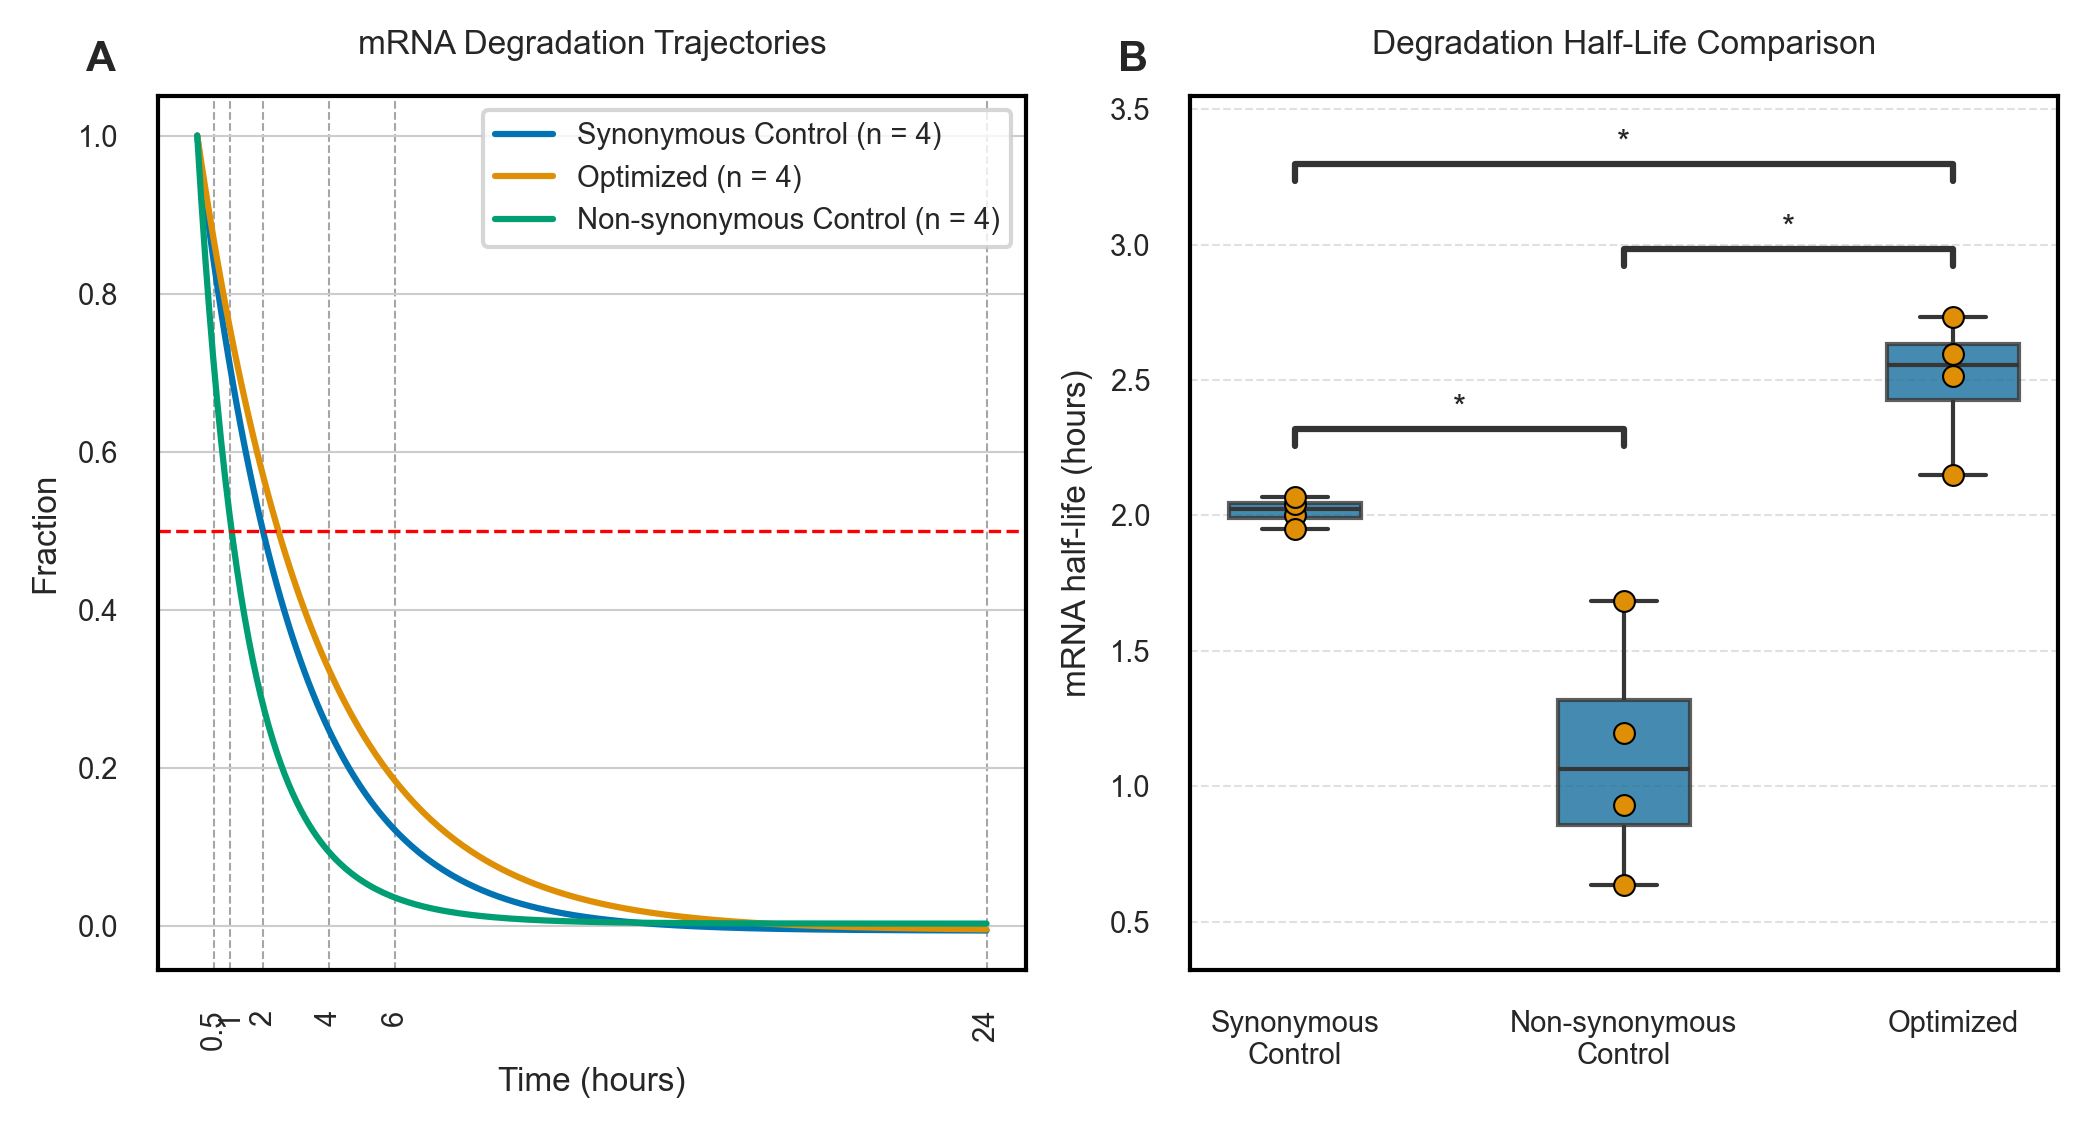

In [59]:
import string
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from statannotations.Annotator import Annotator

# --------------------------------------------------------------------------------------
# 🔧 GLOBAL PUBLICATION CONFIGURATION (NAR Guidelines: 178 mm / 7.0 in Full Width)
# --------------------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
sns.set_theme(style="whitegrid", font_scale=1.0)

plt.rcParams.update(
    {
        "font.size": 8,  # General text
        "axes.titlesize": 8,  # Subplot titles
        "axes.labelsize": 8,  # Axis labels
        "legend.fontsize": 7,  # Legend text
        "xtick.labelsize": 7,  # Tick labels
        "ytick.labelsize": 7,
        "axes.linewidth": 0.8,  # Border spine thickness
        "grid.linewidth": 0.5,  # Gridline thickness
    }
)

colors_palette = sns.color_palette("colorblind")

# --------------------------------------------------------------------------------------
# 1. HELPER FUNCTIONS & DECAY MODEL
# --------------------------------------------------------------------------------------

def normalized_y(amplitude, rate_constant, plateau, time_val):
    return (amplitude * np.exp(-rate_constant * time_val) + plateau) / (amplitude + plateau)

def mann_whitney(group1, group2, alternative="less"):
    statistic, p_value = mannwhitneyu(group1, group2, alternative=alternative)
    return p_value

def p_to_star(p_val):
    if p_val < 0.0001:
        return "****"
    elif p_val < 0.001:
        return "***"
    elif p_val < 0.01:
        return "**"
    elif p_val < 0.05:
        return "*"
    else:
        return "ns"

# --------------------------------------------------------------------------------------
# 2. PANEL A: DECAY CURVES PLOTTING FUNCTION
# --------------------------------------------------------------------------------------

def plot_decay_curves(syncontrol_data, test_data, nonsyncontrol_data, axis_object):
    """Plots normalized mRNA degradation curves over a 24-hour time course."""
    time_points = np.linspace(0, 24, 200)

    # Calculate decay matrices
    control_values = np.array([[normalized_y(a, k, c, t) for t in time_points] for a, k, c in syncontrol_data])
    test_values = np.array([[normalized_y(a, k, c, t) for t in time_points] for a, k, c in test_data])
    nonsyn_values = np.array([[normalized_y(a, k, c, t) for t in time_points] for a, k, c in nonsyncontrol_data])

    # Mean curves
    control_mean = control_values.mean(axis=0)
    test_mean = test_values.mean(axis=0)
    nonsyn_mean = nonsyn_values.mean(axis=0)

    axis_object.plot(time_points, control_mean, label="Synonymous Control (n = 4)", color=colors_palette[0], linewidth=1.5)
    axis_object.plot(time_points, test_mean, label="Optimized (n = 4)", color=colors_palette[1], linewidth=1.5)
    axis_object.plot(time_points, nonsyn_mean, label="Non-synonymous Control (n = 4)", color=colors_palette[2], linewidth=1.5)

    custom_x_ticks = [0.5, 1, 2, 4, 6, 24]
    axis_object.set_xticks(custom_x_ticks)
    axis_object.set_xticklabels([str(x) for x in custom_x_ticks], rotation=90)
    axis_object.grid(axis="x", linestyle="--", color="gray", alpha=0.7, linewidth=0.5)

    axis_object.axhline(y=0.5, color="red", linestyle="--", linewidth=0.8)
    axis_object.set_xlabel("Time (hours)")
    axis_object.set_ylabel("Fraction")
    axis_object.set_title("mRNA Degradation Trajectories", pad=10)
    axis_object.legend(loc="upper right")

# --------------------------------------------------------------------------------------
# 3. PANEL B: HALF-LIFE COMPARISON PLOTTING FUNCTION
# --------------------------------------------------------------------------------------

def plot_halflife_comparison(syn_data, nonsyn_data, optimized_data, axis_object):
    """Plots boxplot and stripplot comparison of half-lives with statistical annotations."""
    halflife_dataframe = pd.DataFrame(
        {
            "Group": ["Synonymous Control"] * len(syn_data)
            + ["Non-synonymous control"] * len(nonsyn_data)
            + ["Optimized"] * len(optimized_data),
            "Half-life": syn_data + nonsyn_data + optimized_data,
        }
    )

    comparison_pairs = [
        ("Synonymous Control", "Optimized"),
        ("Synonymous Control", "Non-synonymous control"),
        ("Optimized", "Non-synonymous control"),
    ]

    p_values = [
        mann_whitney(syn_data, optimized_data, alternative="less"),
        mann_whitney(syn_data, nonsyn_data, alternative="two-sided"),
        mann_whitney(nonsyn_data, optimized_data, alternative="less"),
    ]

    custom_annotations = [p_to_star(p) for p in p_values]

    sns.boxplot(
        x="Group",
        y="Half-life",
        data=halflife_dataframe,
        color=colors_palette[0],
        ax=axis_object,
        width=0.4,
        boxprops=dict(alpha=0.8),
    )
    sns.stripplot(
        x="Group",
        y="Half-life",
        data=halflife_dataframe,
        ax=axis_object,
        color=colors_palette[1],
        edgecolor="black",
        linewidth=0.5,
        size=5,
        jitter=False,
        dodge=False,
    )

    # Dynamic headroom calculation based on data span
    clean_halflives = halflife_dataframe["Half-life"].dropna().values
    if len(clean_halflives) > 0:
        y_min = np.min(clean_halflives)
        y_max = np.max(clean_halflives)
        y_span = y_max - y_min if y_max != y_min else 1.0
        axis_object.set_ylim(max(0.0, y_min - 0.15 * y_span), y_max + 0.35 * y_span)

    annotator = Annotator(
        axis_object, comparison_pairs, data=halflife_dataframe, x="Group", y="Half-life"
    )
    annotator.set_custom_annotations(custom_annotations)
    annotator.configure(text_format="star", loc="inside", verbose=0)
    annotator.annotate()

    """    results_text = (
        "Optimized (n = 4):\n CAI = 0.8815, MFE = -176.0 kcal/mol, MFECAI$_{\\lambda}$ = 157.8\n"
        "Syn-Control (n = 4):\n CAI = 0.9642, MFE = -117.1 kcal/mol, MFECAI$_{\\lambda}$ = 111.8\n"
        "Nonsyn-Control (n = 4):\n CAI = 0.9642, MFE = -116.3 kcal/mol, MFECAI$_{\\lambda}$ = 111.0"
    )

    axis_object.text(
        0.03,
        0.95,
        results_text,
        transform=axis_object.transAxes,
        fontsize=6.5,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.4", linewidth=0.6, alpha=0.9),
    )"""

    axis_object.set_ylabel("mRNA half-life (hours)")
    axis_object.set_xlabel("")
    axis_object.set_xticklabels(
        ["Synonymous\nControl", "Non-synonymous\nControl", "Optimized"]
    )
    axis_object.set_title("Degradation Half-Life Comparison", pad=10)
    axis_object.grid(axis="y", linestyle="--", alpha=0.6)

# --------------------------------------------------------------------------------------
# 4. AGGREGATED GRID ASSEMBLY & EXPORT (7.0 in wide = 178 mm NAR Standard)
# --------------------------------------------------------------------------------------

# Ensure input data structures exist before execution
# --------------------------------------------------------------------------------------
# 4. AGGREGATED GRID ASSEMBLY & EXPORT (7.0 in wide = 178 mm NAR Standard)
# --------------------------------------------------------------------------------------

# YOU MUST RUN THE CELL THAT DEFINES THESE VARIABLES BEFORE RUNNING THIS SCRIPT
syncontrol = [paramsb1_1, paramsb1_2, paramsb1_3, paramsb1_4]
nonsyncontrol = [paramsb3_1, paramsb3_2, paramsb3_3, paramsb3_4]
test = [paramsb2_1, paramsb2_2, paramsb2_3, paramsb2_4]

syn = [b1_1, b1_2, b1_3, b1_4] 
nonsyn = [b3_1, b3_2, b3_3, b3_4]
optimized = [b2_1, b2_2, b2_3, b2_4]

fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.8))
axes_flat = axes.flatten()

# Generate Panel A and Panel B
plot_decay_curves(syncontrol, test, nonsyncontrol, axes_flat[0])
plot_halflife_comparison(syn, nonsyn, optimized, axes_flat[1])

# Apply consistent black border spines and bold panel letters (A, B)
for index, ax in enumerate(axes_flat):
    panel_letter = string.ascii_uppercase[index]
    ax.annotate(
        panel_letter,
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 4),
        textcoords="offset points",
        fontfamily="sans-serif",
        fontsize=10,
        fontweight="bold",
        va="bottom",
        ha="right",
    )
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("black")

plt.tight_layout()


# Export Vector PDF for LaTeX and High-Res PNG
output_basename = "Aggregated_Degradation_Figure_3"
plt.savefig(f"{output_basename}.pdf", format="pdf", bbox_inches="tight", transparent=True)
plt.savefig(f"{output_basename}.png", format="png", dpi=300, bbox_inches="tight")

plt.show()

# Figure 4

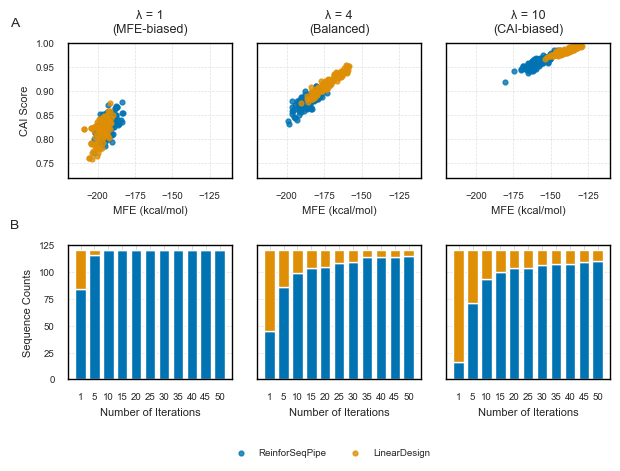

In [1]:
import os
import string
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from Bio.Seq import Seq
from scipy import stats

# --------------------------------------------------------------------------------------
# GLOBAL PUBLICATION CONFIGURATION (NAR Guidelines: 178 mm / 7.0 in Full Width)
# --------------------------------------------------------------------------------------
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
sns.set_theme(style="whitegrid", font_scale=1.0)

plt.rcParams.update(
    {
        "font.size": 8,
        "axes.titlesize": 9,
        "axes.labelsize": 8,
        "legend.fontsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
    }
)

colors = sns.color_palette("colorblind")

# --------------------------------------------------------------------------------------
# DATA PROCESSING FUNCTIONS
# --------------------------------------------------------------------------------------
def translate(seq: str) -> str:
    return str(Seq(seq).translate(to_stop=True))

def build_compare_df(
    folder: str,
    n_files: int,
    parsed_results_path: str = "parsed_results.csv",
    keep_cols=(
        "Peptide Sequence",
        "Final CAI",
        "Final MFE",
        "Final MFExCAI score",
        "Control CAI",
        "Control MFE",
        "Control MFExCAI score",
    ),
    lower_score_better: bool = False,
) -> tuple[pd.DataFrame, dict, pd.DataFrame, pd.DataFrame]:
    
    all_csvs = sorted([f for f in os.listdir(folder) if f.lower().endswith(".csv")])
    total_csvs = len(all_csvs)
    if n_files > total_csvs:
        raise ValueError(f"Requested {n_files} files but only found {total_csvs} CSVs in {folder}.")
    take_csvs = all_csvs[:n_files]

    combined_dfs = []
    for file in take_csvs:
        path = os.path.join(folder, file)
        df = pd.read_csv(path)
        df = df[["Original Sequence", "Final Sequence", "Final CAI", "Final MFE", "Final MFExCAI score"]]
        df["Peptide Sequence"] = df["Final Sequence"].apply(translate)
        combined_dfs.append(df)

    if not combined_dfs:
        raise ValueError("No CSV files found to process.")

    # 1. Full unreduced population for ReinforSeq
    df_reifnorseq = pd.concat(combined_dfs, ignore_index=True)
    df_reifnorseq["Final MFExCAI score"] = pd.to_numeric(df_reifnorseq["Final MFExCAI score"], errors="coerce")

    # Isolate best solutions for merging
    subset = df_reifnorseq[["Peptide Sequence", "Final CAI", "Final MFE", "Final MFExCAI score"]].copy()
    if lower_score_better:
        best_indices = subset.groupby("Peptide Sequence", dropna=False)["Final MFExCAI score"].idxmin()
    else:
        best_indices = subset.groupby("Peptide Sequence", dropna=False)["Final MFExCAI score"].idxmax()
    
    best_per_peptide = subset.loc[best_indices].reset_index(drop=True)
    
    # Check that we have exactly 120 unique best sequences
    if len(best_per_peptide) != 120:
        raise ValueError(f"Expected exactly 120 best sequences for ReinforSeq, but found {len(best_per_peptide)}")

    # 2. Full population for LinearDesign
    lineardesign_df = pd.read_csv(parsed_results_path)

    # 3. Merged DataFrame (only absolute best vs best for bar plot logic)
    merged_df = lineardesign_df.merge(
        best_per_peptide[["Peptide Sequence", "Final CAI", "Final MFE", "Final MFExCAI score"]],
        on="Peptide Sequence",
        how="left",
    )

    keep_cols = [c for c in keep_cols if c in merged_df.columns]
    merged_df = merged_df[keep_cols]

    def compare_scores(row):
        score_a = row.get("Final MFExCAI score")
        score_b = row.get("Control MFExCAI score")
        if pd.isna(score_a) or pd.isna(score_b):
            return "Missing"
        if score_a > score_b:
            return "Reinforseq"
        elif score_a < score_b:
            return "LinearDesign"
        else:
            return "Equal"

    merged_df["Comparison"] = merged_df.apply(compare_scores, axis=1)

    results_summary = {
        "Number of Replicas": n_files,
        "Wins": (merged_df["Comparison"] == "Reinforseq").sum(),
        "Losses": (merged_df["Comparison"] == "LinearDesign").sum(),
        "Equal": (merged_df["Comparison"] == "Equal").sum(),
    }

    # Returning best_per_peptide instead of df_reifnorseq ensures only the best 120 sequences are passed to Panel A
    return merged_df, results_summary, best_per_peptide, lineardesign_df


# --------------------------------------------------------------------------------------
# ITERATE OVER RESULTS DIRECTORIES
# --------------------------------------------------------------------------------------
iteration_counts = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

# Lambda 1 Process
summary_df_l1 = pd.DataFrame()
full_rs_l1_50 = None
full_ld_l1_50 = None
for current_count in iteration_counts:
    merged_df_l1, results_l1, current_full_rs, current_full_ld = build_compare_df(
        folder="ReifnorSeq_Benchmark_all_results/lambda_1",
        n_files=current_count,
        parsed_results_path="LinearDesign_Benchmark_all_results/parsed_results_l1.csv",
        lower_score_better=False,
    )
    summary_df_l1 = pd.concat([summary_df_l1, pd.DataFrame([results_l1])], ignore_index=True)
    if current_count == 50:
        full_rs_l1_50 = current_full_rs
        full_ld_l1_50 = current_full_ld

# Lambda 4 Process
summary_df_l4 = pd.DataFrame()
full_rs_l4_50 = None
full_ld_l4_50 = None
for current_count in iteration_counts:
    merged_df_l4, results_l4, current_full_rs, current_full_ld = build_compare_df(
        folder="ReifnorSeq_Benchmark_all_results/lambda_4",
        n_files=current_count,
        parsed_results_path="LinearDesign_Benchmark_all_results/parsed_results_l4.csv",
        lower_score_better=False,
    )
    summary_df_l4 = pd.concat([summary_df_l4, pd.DataFrame([results_l4])], ignore_index=True)
    if current_count == 50:
        full_rs_l4_50 = current_full_rs
        full_ld_l4_50 = current_full_ld

# Lambda 10 Process
summary_df_l10 = pd.DataFrame()
full_rs_l10_50 = None
full_ld_l10_50 = None
for current_count in iteration_counts:
    merged_df_l10, results_l10, current_full_rs, current_full_ld = build_compare_df(
        folder="ReifnorSeq_Benchmark_all_results/lambda_10",
        n_files=current_count,
        parsed_results_path="LinearDesign_Benchmark_all_results/parsed_results_l10.csv",
        lower_score_better=False,
    )
    summary_df_l10 = pd.concat([summary_df_l10, pd.DataFrame([results_l10])], ignore_index=True)
    if current_count == 50:
        full_rs_l10_50 = current_full_rs
        full_ld_l10_50 = current_full_ld


# --------------------------------------------------------------------------------------
# 1. ORGANIZE DATA FOR PLOTTING
# --------------------------------------------------------------------------------------
# Scatter Plot Data (Panel A): Exclusively uses full separate populations at 50 loops
scatter_data = [
    {
        "title": "λ = 1\n(MFE-biased)",
        "x_rs": full_rs_l1_50['Final MFE'].tolist(),
        "y_rs": full_rs_l1_50['Final CAI'].tolist(),
        "x_ld": full_ld_l1_50['Control MFE'].tolist(),
        "y_ld": full_ld_l1_50['Control CAI'].tolist(),
    },
    {
        "title": "λ = 4\n(Balanced)",
        "x_rs": full_rs_l4_50['Final MFE'].tolist(),
        "y_rs": full_rs_l4_50['Final CAI'].tolist(),
        "x_ld": full_ld_l4_50['Control MFE'].tolist(),
        "y_ld": full_ld_l4_50['Control CAI'].tolist(),
    },
    {
        "title": "λ = 10\n(CAI-biased)",
        "x_rs": full_rs_l10_50['Final MFE'].tolist(),
        "y_rs": full_rs_l10_50['Final CAI'].tolist(),
        "x_ld": full_ld_l10_50['Control MFE'].tolist(),
        "y_ld": full_ld_l10_50['Control CAI'].tolist(),
    }
]

# Stacked Bar Plot Data (Panel B): Uses dynamically derived counts from merged_df via summary_df
bar_steps_str = [str(s) for s in iteration_counts]

bar_data = [
    (summary_df_l1["Wins"].tolist(), summary_df_l1["Losses"].tolist()),
    (summary_df_l4["Wins"].tolist(), summary_df_l4["Losses"].tolist()),
    (summary_df_l10["Wins"].tolist(), summary_df_l10["Losses"].tolist())
]


# --------------------------------------------------------------------------------------
# 2. BUILD GRID AND PLOT (2 Rows, 3 Columns)
# --------------------------------------------------------------------------------------
fig = plt.figure(figsize=(7.0, 4.8))
gs = fig.add_gridspec(2, 3, wspace=0.15, hspace=0.5, bottom=0.18)

# Initialize axes with shared Y-axes explicitly to prevent overwriting gs[0, 0]
ax_s = []
ax_s.append(fig.add_subplot(gs[0, 0]))
ax_s.append(fig.add_subplot(gs[0, 1], sharey=ax_s[0]))
ax_s.append(fig.add_subplot(gs[0, 2], sharey=ax_s[0]))

ax_b = []
ax_b.append(fig.add_subplot(gs[1, 0]))
ax_b.append(fig.add_subplot(gs[1, 1], sharey=ax_b[0]))
ax_b.append(fig.add_subplot(gs[1, 2], sharey=ax_b[0]))

# --- ROW 1: SCATTER PLOTS (Panel A) ---
for i, ax in enumerate(ax_s):
    data = scatter_data[i]
    
    # Plot full populations
    scatter_rs = ax.scatter(data["x_rs"], data["y_rs"], color=colors[0], s=12, alpha=0.8, label="ReinforSeqPipe")
    scatter_ld = ax.scatter(data["x_ld"], data["y_ld"], color=colors[1], s=12, alpha=0.8, label="LinearDesign")
    
    ax.set_title(data["title"], pad=8, fontweight='normal')
    ax.set_xlabel("MFE (kcal/mol)")
    
    # You can restore your original limits here now that the axis isn't being covered
    ax.set_xlim(-220, -110)
    ax.set_ylim(0.72, 1.0)
    
    ax.grid(True, linestyle="--", alpha=0.6)
    
    if i == 0:
        ax.set_ylabel("CAI Score")
    else:
        plt.setp(ax.get_yticklabels(), visible=False)


# --- ROW 2: STACKED BAR PLOTS (Panel B) ---
for i, ax in enumerate(ax_b):
    vals_rs, vals_ld = bar_data[i]
    
    # Plot stacked bar counts
    ax.bar(bar_steps_str, vals_rs, width=0.75, color=colors[0])
    ax.bar(bar_steps_str, vals_ld, width=0.75, bottom=vals_rs, color=colors[1])
    
    ax.set_xticks(range(len(bar_steps_str)))
    ax.set_xticklabels(bar_steps_str, rotation=0, ha='center')
    ax.set_xlabel("Number of Iterations")
    ax.set_ylim(0, 125)
    ax.grid(axis='y', linestyle="--", alpha=0.6)
    
    if i == 0:
        ax.set_ylabel("Sequence Counts")
    else:
        plt.setp(ax.get_yticklabels(), visible=False)



# --------------------------------------------------------------------------------------
# 3. ANNOTATIONS, LEGEND, AND EXPORT
# --------------------------------------------------------------------------------------
ax_s[0].annotate("A", xy=(0, 1), xycoords="axes fraction", xytext=(-35, 10),
                 textcoords="offset points", fontsize=10, fontweight="normal", va="bottom", ha="right")
ax_b[0].annotate("B", xy=(0, 1), xycoords="axes fraction", xytext=(-35, 10),
                 textcoords="offset points", fontsize=10, fontweight="normal", va="bottom", ha="right")

for ax in ax_s + ax_b:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
        spine.set_color("black")

fig.legend(
    [scatter_rs, scatter_ld], 
    ["ReinforSeqPipe", "LinearDesign"], 
    loc="lower center", 
    ncol=2, 
    frameon=False, 
    bbox_to_anchor=(0.5, 0.0)
)

output_name = "Aggregated_Comparison_Figure_4"
plt.savefig(f"{output_name}.pdf", format="pdf", bbox_inches="tight", transparent=True)
plt.savefig(f"{output_name}.png", format="png", dpi=300, bbox_inches="tight")

plt.show()